### Install ###

In [16]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 48.2 MB/s eta 0:00:0000:01


In [2]:
conda install conda-forge::openslide-python

\ WARNING conda.models.version:get_matcher(556): Using .* with relational operator is superfluous and deprecated and will be removed in a future version of conda. Your spec was 1.7.1.*, but conda is ignoring the .* and treating it as 1.7.1
done
Solving environment: done


==> WARNING: A newer version of conda exists. <==
  current version: 23.9.0
  latest version: 24.3.0

Please update conda by running

    $ conda update -n base -c defaults conda

Or to minimize the number of packages updated during conda update use

     conda install conda=24.3.0



## Package Plan ##

  environment location: /opt/conda

  added / updated specs:
    - conda-forge::openslide-python


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    _libgcc_mutex-0.1          |      conda_forge           3 KB  conda-forge
    _openmp_mutex-4.5          |       2_kmp_llvm           6 KB  conda-forge
    ca-certificates-20

In [5]:
conda install -c conda-forge libstdcxx-ng

Error while loading conda entry point: conda-libmamba-solver (libarchive.so.19: cannot open shared object file: No such file or directory)
done
Solving environment: done


==> WARNING: A newer version of conda exists. <==
  current version: 23.9.0
  latest version: 24.3.0

Please update conda by running

    $ conda update -n base -c defaults conda

Or to minimize the number of packages updated during conda update use

     conda install conda=24.3.0



## Package Plan ##

  environment location: /opt/conda

  added / updated specs:
    - libstdcxx-ng


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2024.2.2   |       hbcca054_0         152 KB  conda-forge
    certifi-2024.2.2           |     pyhd8ed1ab_0         157 KB  conda-forge
    ------------------------------------------------------------
                                           Total:         309 KB

The follo

### test ###

In [1]:
import torch
torch.cuda.is_available()

False

In [2]:
torch.cuda.get_device_name(0)

'NVIDIA GeForce RTX 2080 Ti'

In [4]:
import collections

from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cv2
from openslide import OpenSlide

In [34]:
filename = "workspace/HE_240205_iwasaka/2024_02_05__0624-シングルファイルエクスポート-29.tif"

In [35]:
wsi = OpenSlide(filename)

In [36]:
wsi.detect_format(filename)

'generic-tiff'

In [37]:
wsi.dimensions

(82244, 20615)

In [42]:
patch_size=224*4

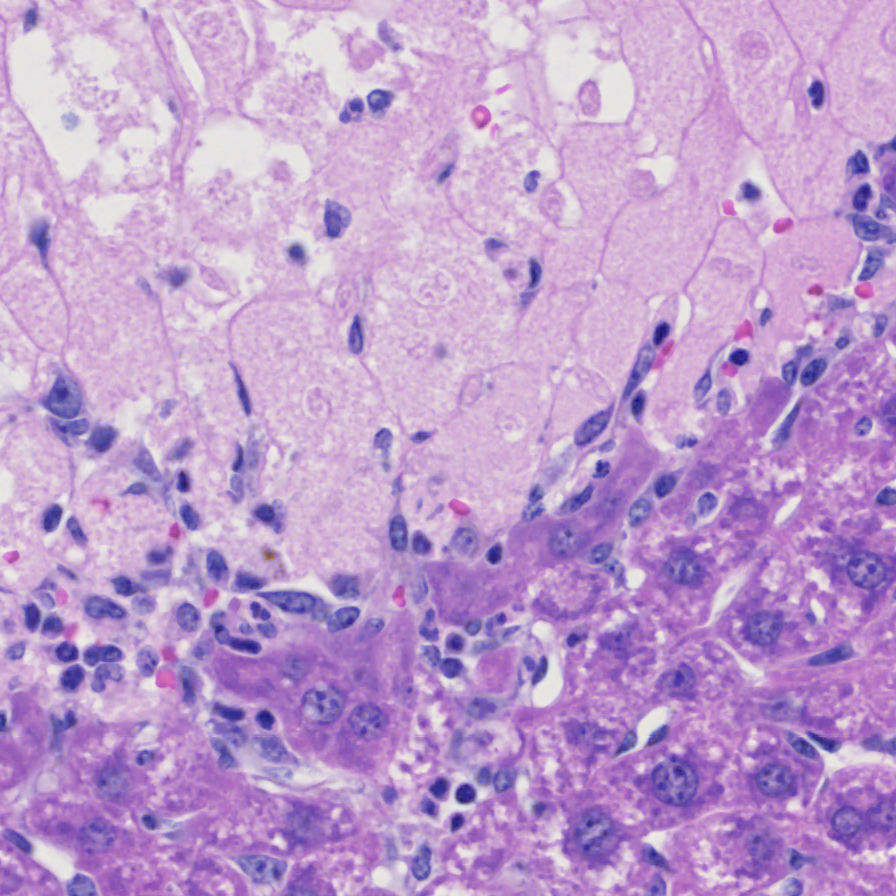

In [44]:
wsi.read_region(location=(45000, 11200), level=0, size=(patch_size,patch_size)).convert("RGB")

In [14]:
def get_patch_mask(image, patch_size, threshold=None,):
    """
    Parameters
    ----------
    iamge: openslide.OpenSlide
    patch_size: int
    threshold: float or None
        各patchが背景かどうかを判定する彩度のthreshold.
        Noneの場合, OTSU法で決定する。
    Returns
    -------
    mask: np.array(int)[wsi_height, wsi_width]
        各patchがどの切片に属するか(-1=背景)
    """
    level = image.get_best_level_for_downsample(patch_size)
    downsample = image.level_downsamples[level]
    ratio = patch_size / downsample
    whole = image.read_region(location=(0,0), level=level,
        size = image.level_dimensions[level]).convert('HSV')
    whole = whole.resize((int(whole.width / ratio), int(whole.height / ratio)))
    whole = np.array(whole, dtype=np.uint8)
    saturation = whole[:,:,1]

    if threshold is None:
        threshold, _ = cv2.threshold(saturation, 0, 255, cv2.THRESH_OTSU)
    mask = saturation > threshold
    return mask

def get_slice_idx(image, patch_size, threshold=None, slice_min_patch = 500, 
    adjacent_cells = [(-1, 0), (1, 0), (0, -1), (0, 1)]):
    """
    get_patchesに加え, WSI内に複数ある切片を分けて認識するようにする。

    Parameters
    ----------
    iamge_file: openslide.OpenSlide
        読み込むWSIのtifファイル
    patch_size: int
        1つのpatchの大きさ(pixel単位)
    threshold: float or None
        各patchが背景かどうかを判定する彩度のthreshold.
        Noneの場合, OTSU法で決定する。
    slice_min_patch: int
        patch数がslice_min_patch未満の切片は小さすぎるとして除去する。
    adjacent_cells: List[Tuple[int]]
        隣接すると判定する領域の指定。
        デフォルトでは上下左右に隣接するpatchは同じ切片に属すると判定する。

    Returns
    -------
    slice_idx: np.array(int)[wsi_height, wsi_width]
        各patchがどの切片に属するか(-1=背景)
    n_slice: int
        切片の総数
    """
    level = image.get_best_level_for_downsample(patch_size)
    downsample = image.level_downsamples[level]
    ratio = patch_size / downsample
    whole = image.read_region(location=(0,0), level=level,
        size = image.level_dimensions[level]).convert('HSV')
    whole = whole.resize((int(whole.width / ratio), int(whole.height / ratio)))
    whole = np.array(whole, dtype=np.uint8)
    saturation = whole[:,:,1]

    if threshold is None:
        threshold, _ = cv2.threshold(saturation, 0, 255, cv2.THRESH_OTSU)
    mask = saturation > threshold
    left_mask = np.full((mask.shape[0]+1, mask.shape[1]+1), fill_value=False, dtype=bool)
    left_mask[:-1, :-1] = mask
    n_left_mask = np.sum(left_mask)
    slice_idx = np.full_like(mask, fill_value=-1, dtype=int)
    i_slice = 0
    while n_left_mask > 0:
        mask_i = np.where(left_mask)
        slice_left_indices = [(mask_i[0][0], mask_i[1][0])]
        while len(slice_left_indices) > 0:
            i, j = slice_left_indices.pop()
            if left_mask[i, j]:
                slice_idx[i, j] = i_slice
                for adj_i, adj_j in adjacent_cells:
                    if left_mask[i+adj_i, j+adj_j]:
                        slice_left_indices.append((i+adj_i, j+adj_j))
                left_mask[i, j] = False
                n_left_mask -= 1
        slice_mask = slice_idx == i_slice
        if np.sum(slice_mask) < slice_min_patch:
            slice_idx[slice_mask] = -1
        else:
            i_slice += 1
    n_slice = i_slice
    return slice_idx, n_slice

def separation(filein:str=""):
    patch_size=224
    threshhold=None
    slice_min_patch=1000
    # load/slice
    wsi = OpenSlide(filein)
    slice_idx, n_slice = get_slice_idx(wsi, patch_size, threshold=threshhold, slice_min_patch=slice_min_patch,)
    print(n_slice)
    # Plot
    colors = []
    for color_code in mcolors.TABLEAU_COLORS.values():
        colors.append(np.array([int(color_code[1:3], 16), int(color_code[3:5], 16), int(color_code[5:7], 16)]))

    slice_image = np.full((slice_idx.shape[0], slice_idx.shape[1], 3), fill_value=255)
    for i_slice in range(n_slice):
        slice_image[slice_idx == i_slice] = colors[i_slice%len(colors)]
    plt.imshow(slice_image)
    plt.show()
    # size
    for i in range(n_slice):
        print((slice_idx==i).sum())

1


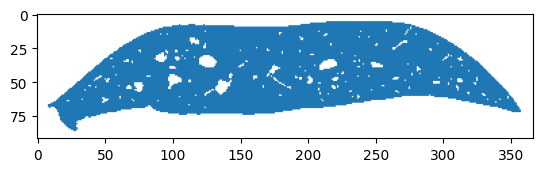

16534


In [15]:
separation(filein=filename)

In [16]:
def get_mask_inside(
    image, 
    patch_size:int=224,
    slice_min_patch:int=1000,
    adjacent_cells_slice=[(-1,0),(1,0),(0,-1),(0,1),],
    adjacent_cells_inside=[(-1,0),(1,0),(0,-1),(0,1),(1,1),(1,-1),(-1,1),(-1,-1)],
    ):
    # load
    level = image.get_best_level_for_downsample(patch_size)
    downsample = image.level_downsamples[level]
    ratio = patch_size / downsample
    whole = image.read_region(location=(0,0), level=level,
        size = image.level_dimensions[level]).convert('HSV')
    whole = whole.resize((int(whole.width / ratio), int(whole.height / ratio)))
    whole = np.array(whole, dtype=np.uint8)
    # get mask
    saturation = whole[:,:,1] #saturation
    threshold, _ = cv2.threshold(saturation, 0, 255, cv2.THRESH_OTSU)
    mask = saturation > threshold
    # get slices > slice_min_patch
    left_mask = np.full((mask.shape[0]+1, mask.shape[1]+1), fill_value=False, dtype=bool)
    left_mask[:-1, :-1] = mask
    n_left_mask = np.sum(left_mask)
    slice_idx = np.full_like(mask, fill_value=-1, dtype=int)
    i_slice = 0
    while n_left_mask > 0:
        mask_i = np.where(left_mask)
        slice_left_indices = [(mask_i[0][0], mask_i[1][0])]
        while len(slice_left_indices) > 0:
            i, j = slice_left_indices.pop()
            if left_mask[i, j]:
                slice_idx[i, j] = i_slice
                for adj_i, adj_j in adjacent_cells_slice:
                    if left_mask[i+adj_i, j+adj_j]:
                        slice_left_indices.append((i+adj_i, j+adj_j))
                left_mask[i, j] = False
                n_left_mask -= 1
        slice_mask = slice_idx == i_slice
        if np.sum(slice_mask) < slice_min_patch:
            slice_idx[slice_mask] = -1
        else:
            i_slice += 1
    # re-difinition mask
    mask=slice_idx>-1
    # get inside mask
    mask_inside=np.zeros(mask.shape, dtype=bool)
    for i in range(1,mask.shape[0]-1):
        for v in range(1,mask.shape[1]-1):
            tf = mask[i][v]
            if tf:
                for adj in adjacent_cells_inside:
                    tf&=mask[i+adj[0]][v+adj[1]]
            mask_inside[i][v]=tf
    return mask_inside

In [17]:
wsi=OpenSlide(filename)
mask_inside=get_mask_inside(wsi, )

In [18]:
mask_inside

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

In [19]:
wsi.dimensions

(82244, 20615)

In [20]:
print(len(mask_inside[1])*224)
print(len(mask_inside)*224)

82208
20608


In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

### test2 ###

In [22]:
import argparse
import time
import os
import re
import sys
import datetime
from typing import List, Tuple, Union, Sequence

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from PIL import ImageOps, Image
import cv2
from openslide import OpenSlide

In [23]:
from torch.utils.data import Dataset, WeightedRandomSampler

In [35]:
sys.path.append("/workspace")

In [36]:
from data_handler import prep_dataloader

#### data preparation ####

In [24]:
def get_mask_inside(
    image, 
    patch_size:int=224,
    slice_min_patch:int=1000,
    adjacent_cells_slice=[(-1,0),(1,0),(0,-1),(0,1),],
    adjacent_cells_inside=[(-1,0),(1,0),(0,-1),(0,1),(1,1),(1,-1),(-1,1),(-1,-1)],
    ):
    # load
    level = image.get_best_level_for_downsample(patch_size)
    downsample = image.level_downsamples[level]
    ratio = patch_size / downsample
    whole = image.read_region(location=(0,0), level=level,
        size = image.level_dimensions[level]).convert('HSV')
    whole = whole.resize((int(whole.width / ratio), int(whole.height / ratio)))
    whole = np.array(whole, dtype=np.uint8)
    # get mask
    saturation = whole[:,:,1] #saturation
    threshold, _ = cv2.threshold(saturation, 0, 255, cv2.THRESH_OTSU)
    mask = saturation > threshold
    # get slices > slice_min_patch
    left_mask = np.full((mask.shape[0]+1, mask.shape[1]+1), fill_value=False, dtype=bool)
    left_mask[:-1, :-1] = mask
    n_left_mask = np.sum(left_mask)
    slice_idx = np.full_like(mask, fill_value=-1, dtype=int)
    i_slice = 0
    while n_left_mask > 0:
        mask_i = np.where(left_mask)
        slice_left_indices = [(mask_i[0][0], mask_i[1][0])]
        while len(slice_left_indices) > 0:
            i, j = slice_left_indices.pop()
            if left_mask[i, j]:
                slice_idx[i, j] = i_slice
                for adj_i, adj_j in adjacent_cells_slice:
                    if left_mask[i+adj_i, j+adj_j]:
                        slice_left_indices.append((i+adj_i, j+adj_j))
                left_mask[i, j] = False
                n_left_mask -= 1
        slice_mask = slice_idx == i_slice
        if np.sum(slice_mask) < slice_min_patch:
            slice_idx[slice_mask] = -1
        else:
            i_slice += 1
    # re-difinition mask
    mask=slice_idx>-1
    # get inside mask
    mask_inside=np.zeros(mask.shape, dtype=bool)
    for i in range(1,mask.shape[0]-1):
        for v in range(1,mask.shape[1]-1):
            tf = mask[i][v]
            if tf:
                for adj in adjacent_cells_inside:
                    tf&=mask[i+adj[0]][v+adj[1]]
            mask_inside[i][v]=tf
    return mask_inside

In [25]:
# DataLoader
class DatasetWSI(torch.utils.data.Dataset):
    def __init__(
        self,
        filein:str="",
        transform=None,
        patch_size=224,
        num_patch=None, random_state=24771,
        ):
        # set transform
        if type(transform)!=list:
            self._transform = [transform]
        else:
            self._transform = transform
        # load data
        self.wsi = OpenSlide(filein)
        mask_inside=get_mask_inside(self.wsi, patch_size=patch_size)
        lst_number=np.array(range(len(mask_inside.flatten())))[mask_inside.flatten()]
        self.lst_location=[[int(patch_size*v) for v in divmod(number, mask_inside.shape[1])] for number in lst_number]
        self.datanum = len(self.lst_location)
        self.patch_size=patch_size

    def __len__(self):
        return self.datanum

    def __getitem__(self,idx):
        out_data=self.wsi.read_region(
            location=tuple(self.lst_location[idx]),
            level=0,
            size=(self.patch_size, self.patch_size),
            )
        out_data = np.array(out_data, np.uint8)[:,:,:3]
        out_data = Image.fromarray(out_data).convert("RGB")
        if self._transform:
            for t in self._transform:
                out_data = t(out_data)
        return out_data

In [37]:
def prepare_dataset(filein:str="", patch_size:int=224, batch_size:int=32, num_patch=None,):
    """
    data preparation
    
    """
    # normalization
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                        std=[0.229, 0.224, 0.225])
    data_transform = transforms.Compose([
        transforms.CenterCrop((224,224)),
        transforms.ToTensor(),
        normalize
    ])
    # data
    dataset = DatasetWSI(
        filein=filein,
        transform=data_transform,
        num_patch=num_patch,
        patch_size=patch_size,
        )
    # to loader
    data_loader = prep_dataloader(
        dataset, batch_size=batch_size, 
        shuffle=False,
        drop_last=False)
    return data_loader, dataset.lst_location

In [38]:
filename = "workspace/HE_240205_iwasaka/2024_02_05__0624-シングルファイルエクスポート-29.tif"
wsi = OpenSlide(filename)
wsi.dimensions

(82244, 20615)

In [39]:
loder, location = prepare_dataset(filein=filename)

In [40]:
patch_size=224
for i in p[0:0]:
    wsi.read_region(location=(i[1], i[0]), level=0, size=(patch_size,patch_size))

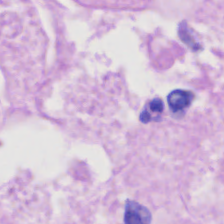

In [53]:
patch_size=224
wsi.read_region(location=(45200, 11200), level=0, size=(patch_size,patch_size)).convert("RGB")

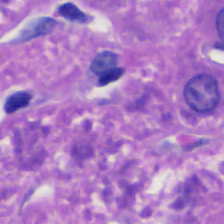

In [52]:
patch_size=224
wsi.read_region(location=(p[100][1], p[100][0]), level=0, size=(patch_size,patch_size)).convert("RGB")

#### model preparation ####

In [43]:
class Featurize:
    def __init__(self, DEVICE="cpu", lst_size=[], ):
        self.DEVICE=DEVICE
        self.lst_size=lst_size
        self.out_all=[[] for size in self.lst_size]
        self.out_all_pool=[[] for size in self.lst_size]

    def extraction():
        return None

    def featurize(self, model, data_loader, ):
        # featurize
        with torch.inference_mode():
            for data in data_loader:
                data = data.to(self.DEVICE)
                outs = self.extraction(model, data)
                for i, out in enumerate(outs):
                    self.out_all[i].append(out)

    def pooling(self, num_pool_patch:int=200):
        """max pooling"""
        for i, out in enumerate(self.out_all):
            self.out_all_pool[i].append(
                np.max(out.reshape(-1, num_pool_patch, self.lst_size[i]),axis=1)
                )
        # reset output list
        self.out_all=[[] for size in self.lst_size]

    def save_outall(self, folder="", name=""):
        for i, out in enumerate(self.out_all):
            out=np.concatenate(out).astype(np.float32)
            np.save(f"{folder}/{name}_layer{i+1}.npy", out)
        self.out_all=[[] for size in self.lst_size]

    def save_outpool(self, folder="", name=""):
        for i, out in enumerate(self.out_all_pool):
            out=np.concatenate(out).astype(np.float32)
            np.save(f"{folder}/{name}_layer{i+1}.npy", out)

In [44]:
class ResNet18Featurize(Featurize):
    def __init__(self, DEVICE="cpu"):
        super().__init__(
            DEVICE=DEVICE, 
            lst_size=[64,64,128,256,512],
            )
    def extraction(self, model, x):
        x = model[0](x)# conv1
        x = model[1](x)# bn
        x = model[2](x)# relu
        x = model[3](x)# maxpool
        x1 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,64)
        x = model[4](x)# layer1
        x2 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,64)
        x = model[5](x)# layer2
        x3 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,128)
        x = model[6](x)# layer3
        x4 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,256)
        x = model[7](x)# layer4
        x5 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,512)
        return x1, x2, x3, x4, x5

In [45]:
DICT_MODEL = {
    "ResNet18": [torchvision.models.resnet18, 512, ResNet18Featurize],
}

In [46]:
def prepare_model(model_name:str='ResNet18', ssl_name="barlowtwins",  model_path="", pretrained=False, DEVICE="cpu"):
    """
    preparation of models
    Parameters
    ----------
        modelname (str)
            model architecture name

    """
    # model building with indicated name
    if pretrained:
        if model_name=="DenseNet121":
            encoder = DICT_MODEL[model_name][0](weights=None)
            encoder = _load_state_dict_dense(encoder, torch.load(model_path))
            model = nn.Sequential(
                *list(encoder.children())[:-1],
                nn.ReLU(inplace=True),
                nn.AdaptiveAvgPool2d((1, 1))
                )
        else:
            encoder = DICT_MODEL[model_name][0](weights=None)
            encoder.load_state_dict(torch.load(model_path))
            model=nn.Sequential(*list(encoder.children())[:-1])
    else:
        encoder = DICT_MODEL[model_name][0](weights=None)
        size = DICT_MODEL[model_name][1]
        if model_name=="DenseNet121":
            backbone = nn.Sequential(
                *list(encoder.children())[:-1],
                nn.ReLU(inplace=True),
                nn.AdaptiveAvgPool2d((1, 1))
                )
        else:
            backbone = nn.Sequential(
                *list(encoder.children())[:-1],
                )
        ssl_class = DICT_SSL[ssl_name](DEVICE=DEVICE)
        model = ssl_class.prepare_featurize_model(
            backbone, model_path=model_path,
            head_size=size,
        )
    model.to(DEVICE)
    model.eval()
    return model

In [49]:
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [47]:
w_pass = "workspace/resnet18-f37072fd.pth"

In [51]:
prepare_model(model_name='ResNet18',  model_path=w_pass, pretrained=True, DEVICE=DEVICE)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Con

### Anomaly Detection ###

なぜか24と25 (23と24)が逆になっている (そもそも画像を取り込む段階？)

In [1]:
import argparse
import time
import os
import re
import sys
import datetime
from typing import List, Tuple, Union, Sequence

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from PIL import ImageOps, Image
import cv2
from openslide import OpenSlide

from torch.utils.data import Dataset, WeightedRandomSampler

sys.path.append("/workspace")
from data_handler import prep_dataloader

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.svm import OneClassSVM as OCSVM
import time

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import random

In [5]:
from sklearn.decomposition import PCA

In [6]:
from statistics import mean, median,variance,stdev

#### model preparation ###

In [123]:
class Featurize:
    def __init__(self, DEVICE="cpu", lst_size=[], ):
        self.DEVICE=DEVICE
        self.lst_size=lst_size
        self.out_all=[[] for size in self.lst_size]
        self.out_all_pool=[[] for size in self.lst_size]

    def extraction():
        return None

    def featurize(self, model, data_loader, ):
        # featurize
        with torch.inference_mode():
            for data in data_loader:
                data = data.to(self.DEVICE)
                outs = self.extraction(model, data)
                for i, out in enumerate(outs):
                    self.out_all[i].append(out)

    def pooling(self, num_pool_patch:int=200):
        """max pooling"""
        for i, out in enumerate(self.out_all):
            self.out_all_pool[i].append(
                np.max(out.reshape(-1, num_pool_patch, self.lst_size[i]),axis=1)
                )
        # reset output list
        self.out_all=[[] for size in self.lst_size]

    def save_outall(self, folder="", name=""):
        for i, out in enumerate(self.out_all):
            out=np.concatenate(out).astype(np.float32)
            np.save(f"{folder}/{name}_layer{i+1}.npy", out)
        self.out_all=[[] for size in self.lst_size]

    def save_outpool(self, folder="", name=""):
        for i, out in enumerate(self.out_all_pool):
            out=np.concatenate(out).astype(np.float32)
            np.save(f"{folder}/{name}_layer{i+1}.npy", out)

In [124]:
class ResNet18Featurize(Featurize):
    def __init__(self, DEVICE="cpu"):
        super().__init__(
            DEVICE=DEVICE, 
            lst_size=[64,64,128,256,512],
            )
    def extraction(self, model, x):
        x = model[0](x)# conv1
        x = model[1](x)# bn
        x = model[2](x)# relu
        x = model[3](x)# maxpool
        x1 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,64)
        x = model[4](x)# layer1
        x2 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,64)
        x = model[5](x)# layer2
        x3 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,128)
        x = model[6](x)# layer3
        x4 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,256)
        x = model[7](x)# layer4
        x5 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,512)
        return x1, x2, x3, x4, x5

In [67]:
DICT_MODEL = {"ResNet18": [torchvision.models.resnet18, 512, ResNet18Featurize],}

In [68]:
def prepare_model(model_name:str='ResNet18', ssl_name="barlowtwins",  model_path="", pretrained=False, DEVICE="cpu"):
    """
    preparation of models
    Parameters
    ----------
        modelname (str)
            model architecture name

    """
    # model building with indicated name
    if pretrained:
        if model_name=="DenseNet121":
            encoder = DICT_MODEL[model_name][0](weights=None)
            encoder = _load_state_dict_dense(encoder, torch.load(model_path))
            model = nn.Sequential(
                *list(encoder.children())[:-1],
                nn.ReLU(inplace=True),
                nn.AdaptiveAvgPool2d((1, 1))
                )
        else:
            encoder = DICT_MODEL[model_name][0](weights=None)
            encoder.load_state_dict(torch.load(model_path))
            model=nn.Sequential(*list(encoder.children())[:-1])
    else:
        print("pretraind only")
    model.to(DEVICE)
    model.eval()
    return model

In [69]:
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(DEVICE)
w_pass = "workspace/resnet18-f37072fd.pth"

cuda:0


In [70]:
prepare_model(model_name='ResNet18',  model_path=w_pass, pretrained=True, DEVICE=DEVICE)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Con

#### data ####

In [57]:
def get_mask_inside(
    image, 
    patch_size:int=224,
    slice_min_patch:int=1000,
    adjacent_cells_slice=[(-1,0),(1,0),(0,-1),(0,1),],
    adjacent_cells_inside=[(-1,0),(1,0),(0,-1),(0,1),(1,1),(1,-1),(-1,1),(-1,-1)],
    ):
    # load
    level = image.get_best_level_for_downsample(patch_size)
    downsample = image.level_downsamples[level]
    ratio = patch_size / downsample
    whole = image.read_region(location=(0,0), level=level,
        size = image.level_dimensions[level]).convert('HSV')
    whole = whole.resize((int(whole.width / ratio), int(whole.height / ratio)))
    whole = np.array(whole, dtype=np.uint8)
    # get mask
    saturation = whole[:,:,1] #saturation
    threshold, _ = cv2.threshold(saturation, 0, 255, cv2.THRESH_OTSU)
    mask = saturation > threshold
    # get slices > slice_min_patch
    left_mask = np.full((mask.shape[0]+1, mask.shape[1]+1), fill_value=False, dtype=bool)
    left_mask[:-1, :-1] = mask
    n_left_mask = np.sum(left_mask)
    slice_idx = np.full_like(mask, fill_value=-1, dtype=int)
    i_slice = 0
    while n_left_mask > 0:
        mask_i = np.where(left_mask)
        slice_left_indices = [(mask_i[0][0], mask_i[1][0])]
        while len(slice_left_indices) > 0:
            i, j = slice_left_indices.pop()
            if left_mask[i, j]:
                slice_idx[i, j] = i_slice
                for adj_i, adj_j in adjacent_cells_slice:
                    if left_mask[i+adj_i, j+adj_j]:
                        slice_left_indices.append((i+adj_i, j+adj_j))
                left_mask[i, j] = False
                n_left_mask -= 1
        slice_mask = slice_idx == i_slice
        if np.sum(slice_mask) < slice_min_patch:
            slice_idx[slice_mask] = -1
        else:
            i_slice += 1
    # re-difinition mask
    mask=slice_idx>-1
    # get inside mask
    mask_inside=np.zeros(mask.shape, dtype=bool)
    for i in range(1,mask.shape[0]-1):
        for v in range(1,mask.shape[1]-1):
            tf = mask[i][v]
            if tf:
                for adj in adjacent_cells_inside:
                    tf&=mask[i+adj[0]][v+adj[1]]
            mask_inside[i][v]=tf
    return mask_inside

In [58]:
# DataLoader
class DatasetWSI(torch.utils.data.Dataset):
    def __init__(
        self,
        filein:str="",
        transform=None,
        patch_size=224,
        num_patch=None, random_state=24771,
        ):
        # set transform
        if type(transform)!=list:
            self._transform = [transform]
        else:
            self._transform = transform
        # load data
        self.wsi = OpenSlide(filein)
        mask_inside=get_mask_inside(self.wsi, patch_size=patch_size)
        lst_number=np.array(range(len(mask_inside.flatten())))[mask_inside.flatten()]
        self.lst_location=[[int(patch_size*v) for v in divmod(number, mask_inside.shape[1])][::-1] for number in lst_number]
        self.datanum = len(self.lst_location)
        self.patch_size=patch_size

    def __len__(self):
        return self.datanum

    def __getitem__(self,idx):
        out_data=self.wsi.read_region(
            location=tuple(self.lst_location[idx]),
            level=0,
            size=(self.patch_size, self.patch_size),
            )
        out_data = np.array(out_data, np.uint8)[:,:,:3]
        out_data = Image.fromarray(out_data).convert("RGB")
        if self._transform:
            for t in self._transform:
                out_data = t(out_data)
        return out_data

In [59]:
def prepare_dataset(filein:str="", patch_size:int=224, batch_size:int=32, num_patch=None,):
    """
    data preparation
    
    """
    # normalization
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                        std=[0.229, 0.224, 0.225])
    data_transform = transforms.Compose([
        transforms.CenterCrop((224,224)),
        transforms.ToTensor(),
        normalize
    ])
    # data
    dataset = DatasetWSI(
        filein=filein,
        transform=data_transform,
        num_patch=num_patch,
        patch_size=patch_size,
        )
    # to loader
    data_loader = prep_dataloader(
        dataset, batch_size=batch_size, 
        shuffle=False,
        drop_last=False)
    return data_loader, dataset.lst_location

In [60]:
def featurize_layer(
    model_name="", ssl_name="", model_path="", pretrained=False,
    lst_filein=list(), lst_filename=list(), dir_result="",
    num_pool_patch=None, num_patch=None,
    batch_size=128, patch_size=224,
    DEVICE="cpu", ):
    """featurize module"""
    # load model
    model=prepare_model(
        model_name=model_name, 
        ssl_name=ssl_name,
        model_path=model_path,
        pretrained=pretrained, 
        DEVICE=DEVICE
    )
    extract_class = DICT_MODEL[model_name][2](DEVICE=DEVICE)
    # result dir
    if not os.path.exists(dir_result):
        os.makedirs(dir_result)
    # featurize
    for filein, filename in zip(lst_filein, lst_filename):
        data_loader, lst_location=prepare_dataset(filein=filein, batch_size=batch_size, patch_size=patch_size, num_patch=num_patch)
        extract_class.featurize(model, data_loader)
        if num_pool_patch:
            extract_class.pooling(num_pool_patch=num_pool_patch)
            extract_class.save_outpool(folder=dir_result, name=filename)
        else:
            extract_class.save_outall(folder=dir_result, name=filename)
        pd.to_pickle(lst_location, f"{dir_result}/{filename}_location.pickle")

In [71]:
dir_path = "/workspace/HE_240205_iwasaka"
file_lst = os.listdir(dir_path)
filein_lst = ["workspace/HE_240205_iwasaka/"+i for i in file_lst if ".tif" in i]
r_pass = "workspace/result_v2"

In [72]:
filename_lst = [i.split("-")[2].split(".t")[0] for i in filein_lst]
num_lst =[]
ap = num_lst.append
for i in filename_lst:
    if int(i) < 20:
        ap(int(i))
    else:
        ap(int(i)+1)

In [73]:
featurize_layer(
    model_name="ResNet18", model_path=w_pass, pretrained=True,
    lst_filein=filein_lst, lst_filename=num_lst, dir_result=r_pass,
    num_pool_patch=None, num_patch=None,
    batch_size=128,
    DEVICE=DEVICE, )

#### data_v2 ####

In [225]:
def get_mask(
    image, 
    patch_size:int=224,
    slice_min_patch:int=1000,
    adjacent_cells_slice=[(-1,0),(1,0),(0,-1),(0,1),],
    adjacent_cells_inside=[(-1,0),(1,0),(0,-1),(0,1),(1,1),(1,-1),(-1,1),(-1,-1)],
    ):
    # load
    level = image.get_best_level_for_downsample(patch_size)
    downsample = image.level_downsamples[level]
    ratio = patch_size / downsample
    whole = image.read_region(location=(0,0), level=level,
        size = image.level_dimensions[level]).convert('HSV')
    whole = whole.resize((int(whole.width / ratio), int(whole.height / ratio)))
    whole = np.array(whole, dtype=np.uint8)
    # get mask
    saturation = whole[:,:,1] #saturation
    threshold, _ = cv2.threshold(saturation, 0, 255, cv2.THRESH_OTSU)
    mask = saturation > threshold
    return mask

In [226]:
# DataLoader
class DatasetWSI(torch.utils.data.Dataset):
    def __init__(
        self,
        filein:str="",
        transform=None,
        patch_size=224,
        num_patch=None, random_state=24771,
        ):
        # set transform
        if type(transform)!=list:
            self._transform = [transform]
        else:
            self._transform = transform
        # load data
        self.wsi = OpenSlide(filein)
        mask_inside=get_mask(self.wsi, patch_size=patch_size)
        lst_number=np.array(range(len(mask_inside.flatten())))[mask_inside.flatten()]
        self.lst_location=[[int(patch_size*v) for v in divmod(number, mask_inside.shape[1])][::-1] for number in lst_number]
        self.datanum = len(self.lst_location)
        self.patch_size=patch_size

    def __len__(self):
        return self.datanum

    def __getitem__(self,idx):
        out_data=self.wsi.read_region(
            location=tuple(self.lst_location[idx]),
            level=0,
            size=(self.patch_size, self.patch_size),
            )
        out_data = np.array(out_data, np.uint8)[:,:,:3]
        out_data = Image.fromarray(out_data).convert("RGB")
        if self._transform:
            for t in self._transform:
                out_data = t(out_data)
        return out_data

In [227]:
def prepare_dataset(filein:str="", patch_size:int=224, batch_size:int=32, num_patch=None,):
    """
    data preparation
    
    """
    # normalization
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                        std=[0.229, 0.224, 0.225])
    data_transform = transforms.Compose([
        transforms.CenterCrop((224,224)),
        transforms.ToTensor(),
        normalize
    ])
    # data
    dataset = DatasetWSI(
        filein=filein,
        transform=data_transform,
        num_patch=num_patch,
        patch_size=patch_size,
        )
    # to loader
    data_loader = prep_dataloader(
        dataset, batch_size=batch_size, 
        shuffle=False,
        drop_last=False)
    return data_loader, dataset.lst_location

In [228]:
def featurize_layer(
    model_name="", ssl_name="", model_path="", pretrained=False,
    lst_filein=list(), lst_filename=list(), dir_result="",
    num_pool_patch=None, num_patch=None,
    batch_size=128, patch_size=224,
    DEVICE="cpu", ):
    """featurize module"""
    # load model
    model=prepare_model(
        model_name=model_name, 
        ssl_name=ssl_name,
        model_path=model_path,
        pretrained=pretrained, 
        DEVICE=DEVICE
    )
    extract_class = DICT_MODEL[model_name][2](DEVICE=DEVICE)
    # result dir
    if not os.path.exists(dir_result):
        os.makedirs(dir_result)
    # featurize
    for filein, filename in zip(lst_filein, lst_filename):
        data_loader, lst_location=prepare_dataset(filein=filein, batch_size=batch_size, patch_size=patch_size, num_patch=num_patch)
        extract_class.featurize(model, data_loader)
        if num_pool_patch:
            extract_class.pooling(num_pool_patch=num_pool_patch)
            extract_class.save_outpool(folder=dir_result, name=filename)
        else:
            extract_class.save_outall(folder=dir_result, name=filename)
        pd.to_pickle(lst_location, f"{dir_result}/{filename}_location.pickle")

In [229]:
dir_path = "/workspace/HE_240205_iwasaka"
file_lst = os.listdir(dir_path)
filein_lst = ["workspace/HE_240205_iwasaka/"+i for i in file_lst if ".tif" in i]
r_pass = "workspace/result_v3"

In [230]:
filename_lst = [i.split("-")[2].split(".t")[0] for i in filein_lst]
num_lst =[]
ap = num_lst.append
for i in filename_lst:
    if int(i) < 20:
        ap(int(i))
    else:
        ap(int(i)+1)

In [231]:
featurize_layer(
    model_name="ResNet18", model_path=w_pass, pretrained=True,
    lst_filein=filein_lst, lst_filename=num_lst, dir_result=r_pass,
    num_pool_patch=None, num_patch=None,
    batch_size=128, patch_size=448,
    DEVICE=DEVICE, )

#### data_v3 ####

In [397]:
def get_mask(
    image, 
    patch_size:int=224,
    slice_min_patch:int=1000,
    adjacent_cells_slice=[(-1,0),(1,0),(0,-1),(0,1),],
    adjacent_cells_inside=[(-1,0),(1,0),(0,-1),(0,1),(1,1),(1,-1),(-1,1),(-1,-1)],
    ):
    # load
    level = image.get_best_level_for_downsample(patch_size)
    downsample = image.level_downsamples[level]
    ratio = patch_size / downsample
    whole = image.read_region(location=(0,0), level=level,
        size = image.level_dimensions[level]).convert('HSV')
    whole = whole.resize((int(whole.width / ratio), int(whole.height / ratio)))
    whole = np.array(whole, dtype=np.uint8)
    # get mask
    saturation = whole[:,:,1] #saturation
    threshold, _ = cv2.threshold(saturation, 0, 255, cv2.THRESH_OTSU)
    mask = saturation > threshold
    return mask

In [398]:
# DataLoader
class DatasetWSI(torch.utils.data.Dataset):
    def __init__(
        self,
        filein:str="",
        transform=None,
        patch_size=224,
        num_patch=None, random_state=24771,
        ):
        # set transform
        if type(transform)!=list:
            self._transform = [transform]
        else:
            self._transform = transform
        # load data
        self.wsi = OpenSlide(filein)
        mask_inside=get_mask(self.wsi, patch_size=patch_size)
        lst_number=np.array(range(len(mask_inside.flatten())))[mask_inside.flatten()]
        self.lst_location=[[int(patch_size*v) for v in divmod(number, mask_inside.shape[1])][::-1] for number in lst_number]
        self.datanum = len(self.lst_location)
        self.patch_size=patch_size

    def __len__(self):
        return self.datanum

    def __getitem__(self,idx):
        out_data=self.wsi.read_region(
            location=tuple(self.lst_location[idx]),
            level=0,
            size=(self.patch_size, self.patch_size),
            )
        out_data = np.array(out_data, np.uint8)[:,:,:3]
        out_data = Image.fromarray(out_data).convert("RGB")
        if self._transform:
            for t in self._transform:
                out_data = t(out_data)
        return out_data

In [399]:
def prepare_dataset(filein:str="", patch_size:int=224, batch_size:int=32, num_patch=None,):
    """
    data preparation
    
    """
    # normalization
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                        std=[0.229, 0.224, 0.225])
    data_transform = transforms.Compose([
        transforms.CenterCrop((224,224)),
        transforms.ToTensor(),
        normalize
    ])
    # data
    dataset = DatasetWSI(
        filein=filein,
        transform=data_transform,
        num_patch=num_patch,
        patch_size=patch_size,
        )
    # to loader
    data_loader = prep_dataloader(
        dataset, batch_size=batch_size, 
        shuffle=False,
        drop_last=False)
    return data_loader, dataset.lst_location

In [400]:
def featurize_layer(
    model_name="", ssl_name="", model_path="", pretrained=False,
    lst_filein=list(), lst_filename=list(), dir_result="",
    num_pool_patch=None, num_patch=None,
    batch_size=128, patch_size=224,
    DEVICE="cpu", ):
    """featurize module"""
    # load model
    model=prepare_model(
        model_name=model_name, 
        ssl_name=ssl_name,
        model_path=model_path,
        pretrained=pretrained, 
        DEVICE=DEVICE
    )
    extract_class = DICT_MODEL[model_name][2](DEVICE=DEVICE)
    # result dir
    if not os.path.exists(dir_result):
        os.makedirs(dir_result)
    # featurize
    for filein, filename in zip(lst_filein, lst_filename):
        data_loader, lst_location=prepare_dataset(filein=filein, batch_size=batch_size, patch_size=patch_size, num_patch=num_patch)
        extract_class.featurize(model, data_loader)
        if num_pool_patch:
            extract_class.pooling(num_pool_patch=num_pool_patch)
            extract_class.save_outpool(folder=dir_result, name=filename)
        else:
            extract_class.save_outall(folder=dir_result, name=filename)
        pd.to_pickle(lst_location, f"{dir_result}/{filename}_location.pickle")

In [401]:
dir_path = "/workspace/HE_240205_iwasaka"
file_lst = os.listdir(dir_path)
filein_lst = ["workspace/HE_240205_iwasaka/"+i for i in file_lst if ".tif" in i]
r_pass = "workspace/result_v4"

In [402]:
filename_lst = [i.split("-")[2].split(".t")[0] for i in filein_lst]
num_lst =[]
ap = num_lst.append
for i in filename_lst:
    if int(i) < 20:
        ap(int(i))
    else:
        ap(int(i)+1)

In [403]:
featurize_layer(
    model_name="ResNet18", model_path=w_pass, pretrained=True,
    lst_filein=filein_lst, lst_filename=num_lst, dir_result=r_pass,
    num_pool_patch=None, num_patch=None,
    batch_size=128, patch_size=224,
    DEVICE=DEVICE, )

#### visualization ####

In [3]:
dir_path = "/workspace/HE_240205_iwasaka"
file_lst = os.listdir(dir_path)
filein_lst = ["workspace/HE_240205_iwasaka/"+i for i in file_lst if ".tif" in i]
r_pass = "workspace/result"

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
f_path = "workspace/result/1_layer5.npy"
l_path = "workspace/result/1_location.pickle"

In [6]:
feature = np.load(f_path)
location = pd.read_pickle(l_path)

In [7]:
len(feature)

14741

In [8]:
len(feature[0])

512

In [9]:
len(location)

14741

In [10]:
def loc_plot(location, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[1] for i in location])+2440
    xmin = min([i[1] for i in location])-2440
    ymax = max([i[0] for i in location])+2440
    ymin = min([i[0] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    for i in range(len(location)):
        if "10" in str(i):
            ax.scatter(location[i][1]+loc, location[i][0]-loc, alpha=1, color="indigo", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(location[i][1]+loc, location[i][0]-loc, alpha=1, color="coral", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

In [11]:
l3 = [[0, 0],[200, 200], [400, 400], [200, 600]]

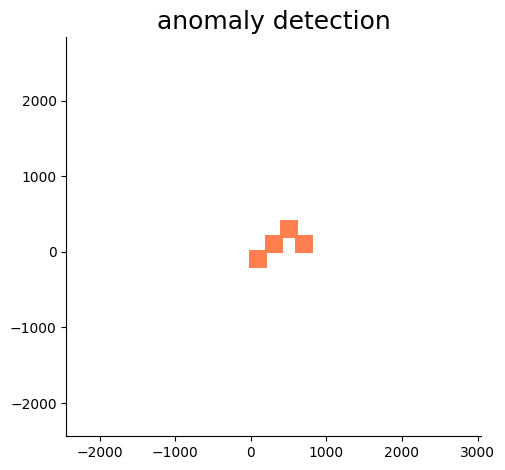

In [12]:
loc_plot(l3, ppi=70, size=100, title="anomaly detection")

In [13]:
l2 = [[0, 0],[224, 224], [448, 448], [224, 224*5], [224*10, 224*10], [224*10, 224*9], [224*9, 224*9]]

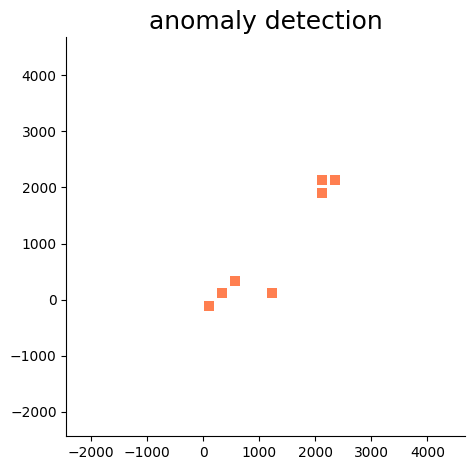

In [14]:
loc_plot(l2, ppi=50, size=112, title="anomaly detection")

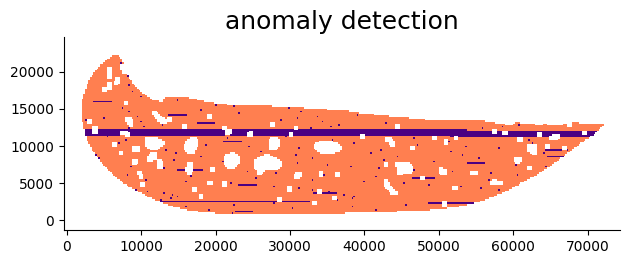

In [181]:
loc_plot(location, ppi=50, size=112, title="anomaly detection")

In [13]:
filein_lst[0]

'workspace/HE_240205_iwasaka/2024_02_05__0596-シングルファイルエクスポート-01.tif'

In [14]:
wsi = OpenSlide(filein_lst[0])

In [15]:
patch_size = 224

In [16]:
i = 1000

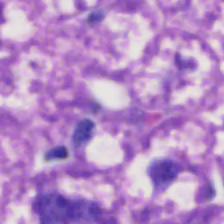

In [17]:
wsi.read_region(location=(location[i][1], location[i][0]), level=0, size=(patch_size,patch_size)).convert("RGB")

In [62]:
from sklearn.decomposition import PCA

In [63]:
feature

array([[0.11666263, 0.12855968, 0.        , ..., 0.        , 0.        ,
        0.00292643],
       [0.11666263, 0.12855968, 0.        , ..., 0.        , 0.        ,
        0.00292643],
       [0.11666263, 0.12855968, 0.        , ..., 0.        , 0.        ,
        0.00292643],
       ...,
       [0.27477437, 0.0267905 , 0.56606734, ..., 0.6836649 , 0.18774593,
        0.16698305],
       [0.26894706, 0.063089  , 0.23214215, ..., 0.4802262 , 0.01352232,
        0.32733995],
       [0.5239808 , 0.01372377, 0.48607367, ..., 0.35310146, 0.09176476,
        0.56442666]], dtype=float32)

In [64]:
pca = PCA()
pca.fit(feature)
feature_pca = pca.transform(feature)

In [66]:
len(feature_pca)

14741

In [70]:
# 第一主成分と第二主成分でプロットする
def PCAplot(feature, xnum=0, ynum=1, title="RNAseq batch check"):
    fig, ax = plt.subplots()
    for i in range(len(feature)):
        ax.scatter(feature[:, xnum][i], feature[:, ynum][i], alpha=1, color="pink")

    ax.set_title(title, fontsize=18)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

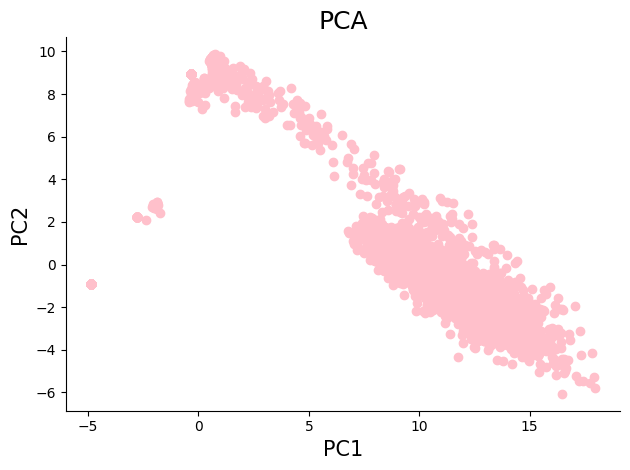

In [73]:
PCAplot(feature_pca, xnum=0, ynum=1, title="PCA")

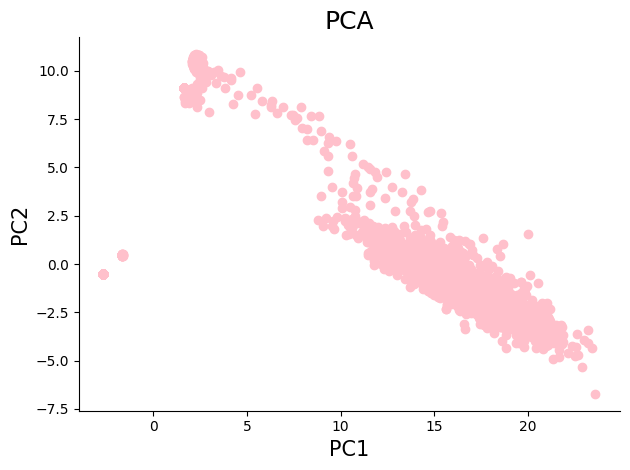

In [74]:
f_path = "workspace/result/30_layer5.npy"
l_path = "workspace/result/30_location.pickle"
feature = np.load(f_path)
location = pd.read_pickle(l_path)
pca = PCA()
pca.fit(feature)
feature_pca = pca.transform(feature)
PCAplot(feature_pca, xnum=0, ynum=1, title="PCA")

#### ocsvm ####

In [33]:
def loc_plot(location, jud, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[1] for i in location])+2440
    xmin = min([i[1] for i in location])-2440
    ymax = max([i[0] for i in location])+2440
    ymin = min([i[0] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    for i in zip(jud, location):
        if i[0] == -1:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="indigo", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="coral", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
f_path = "workspace/result/1_layer5.npy"
l_path = "workspace/result/1_location.pickle"
feature = np.load(f_path)
location = pd.read_pickle(l_path)

In [18]:
f_path_1 = "workspace/result/1_layer5.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result/2_layer5.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result/3_layer5.npy"
feature_3 = np.load(f_path_3)

In [19]:
len(feature_1)

14741

In [20]:
f_conc = list(feature_1) + list(feature_2) + list(feature_3)
f_conc

[array([1.16662629e-01, 1.28559679e-01, 0.00000000e+00, 1.85767144e-01,
        6.19593076e-03, 7.69844884e-03, 6.61964808e-03, 1.13260619e-01,
        5.45103490e-01, 3.89373228e-02, 3.22504081e-02, 2.90460736e-01,
        1.96647681e-02, 1.80246562e-01, 1.81762520e-02, 4.34281230e-02,
        0.00000000e+00, 0.00000000e+00, 1.59517787e-02, 2.35400766e-01,
        1.80975527e-01, 4.42813011e-03, 2.82687577e-03, 5.80129623e-02,
        1.41683459e-01, 1.45850619e-02, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 2.22904176e-01, 1.97905853e-01, 5.87899387e-02,
        2.11081058e-01, 0.00000000e+00, 3.34308781e-02, 0.00000000e+00,
        5.79395937e-03, 0.00000000e+00, 3.27014811e-02, 0.00000000e+00,
        5.81046147e-03, 0.00000000e+00, 3.57047766e-02, 6.28241478e-03,
        1.37569513e-02, 3.20805684e-02, 2.62388259e-01, 8.94438941e-03,
        0.00000000e+00, 2.32065007e-01, 1.62216723e-01, 0.00000000e+00,
        1.70600247e-02, 2.46892497e-01, 2.78358674e+00, 5.469241

In [24]:
len(f_conc[0])

512

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.svm import OneClassSVM as OCSVM
import time

In [22]:
#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

In [25]:
feature_scaled

array([[-0.38009081,  1.18926279, -0.5397437 , ..., -0.51662155,
        -1.53604509, -0.52782504],
       [-0.38009081,  1.18926279, -0.5397437 , ..., -0.51662155,
        -1.53604509, -0.52782504],
       [-0.38009081,  1.18926279, -0.5397437 , ..., -0.51662155,
        -1.53604509, -0.52782504],
       ...,
       [-0.15641303, -0.14678995, -0.5397437 , ..., -0.51662155,
        -1.53604509, -0.53919849],
       [ 1.90641218,  1.04027549, -0.53801586, ...,  0.52499571,
        -0.83265173, -0.53919849],
       [ 1.02998631,  7.42790003, -0.5397437 , ...,  0.42611894,
        -1.19407309,  2.76277705]])

In [26]:
total_p = len(feature_scaled)
print(total_p)

38199


In [27]:
total_p = len(feature_scaled)
nu = 1/total_p #
gamma = 1/512 #一旦適当
ocsvm = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [28]:
f_path_1 = "workspace/result/1_layer5.npy"
l_path_1 = "workspace/result/1_location.pickle"
feature_1 = np.load(f_path_1)
location_1 = pd.read_pickle(l_path_1)
feature_scaled_1 = scaler.fit_transform(feature_1)
jud_1 = ocsvm.predict(feature_scaled_1)
print(len([i for i in jud_1 if i == 1]))
print(len([i for i in jud_1 if i == -1]))

4441
10300


In [29]:
f_path_2 = "workspace/result/2_layer5.npy"
l_path_2 = "workspace/result/2_location.pickle"
feature_2 = np.load(f_path_2)
location_2 = pd.read_pickle(l_path_2)
feature_scaled_2 = scaler.fit_transform(feature_2)
jud_2 = ocsvm.predict(feature_scaled_2)
print(len([i for i in jud_2 if i == 1]))
print(len([i for i in jud_2 if i == -1]))

2364
8144


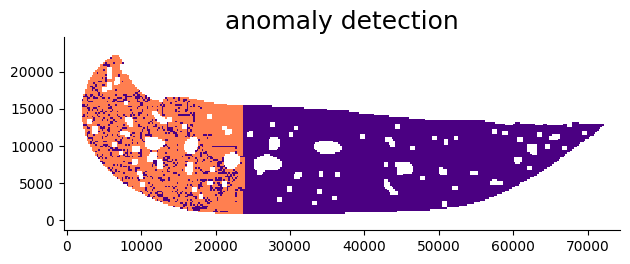

In [32]:
loc_plot(location_1, jud_1, ppi=50, size=112, title="anomaly detection")

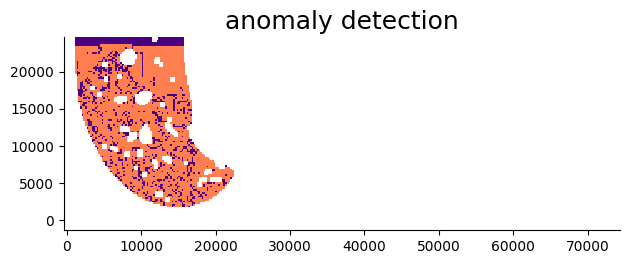

In [34]:
loc_plot(location_1, jud_1, ppi=50, size=112, title="anomaly detection")

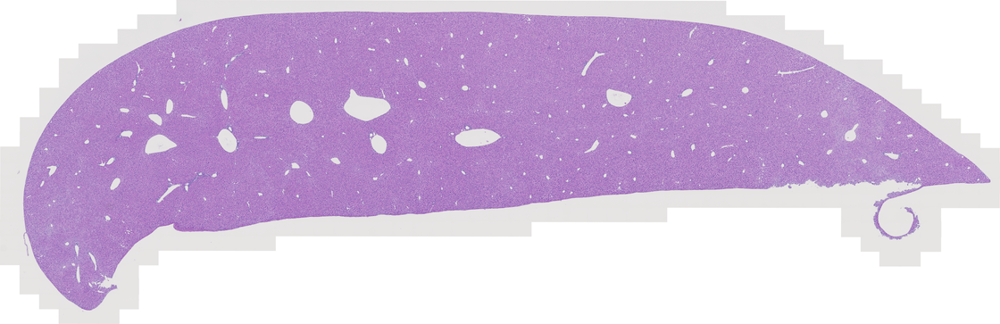

In [347]:
filename = "workspace/HE_240205_iwasaka/2024_02_05__0596-シングルファイルエクスポート-01.tif"
wsi = OpenSlide(filename)
wsi.get_thumbnail(size=(1120, 1120))

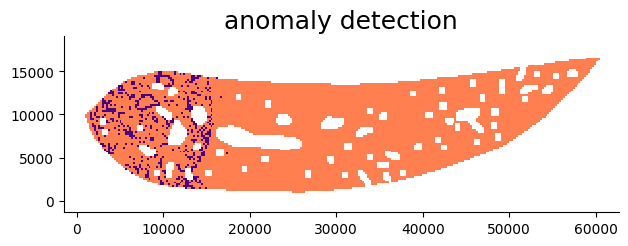

In [348]:
loc_plot(location_2, jud_2, ppi=50, size=112, title="anomaly detection")

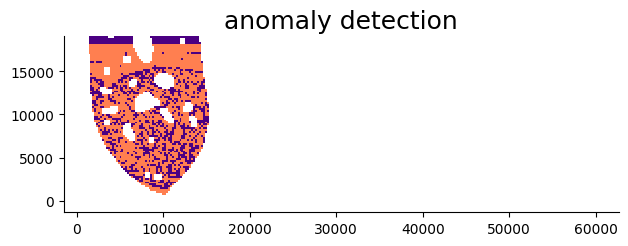

In [35]:
loc_plot(location_2, jud_2, ppi=50, size=112, title="anomaly detection")

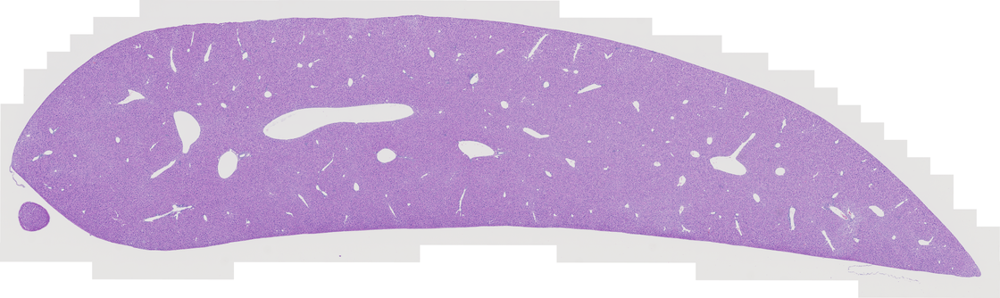

In [349]:
filename = "workspace/HE_240205_iwasaka/2024_02_05__0597-シングルファイルエクスポート-02.tif"
wsi = OpenSlide(filename)
wsi.get_thumbnail(size=(1120, 1120))

13879
1256


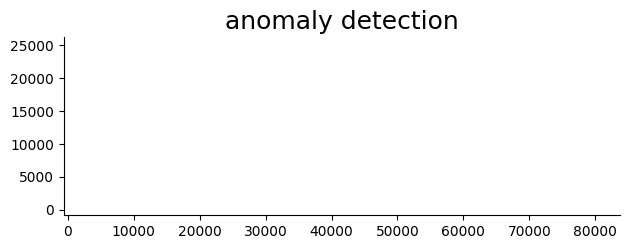

In [350]:
f_path_4 = "workspace/result/4_layer5.npy"
l_path_4 = "workspace/result/4_location.pickle"
feature_4 = np.load(f_path_4)
location_4 = pd.read_pickle(l_path_4)
feature_scaled_4 = scaler.fit_transform(feature_4)
jud_4 = ocsvm.predict(feature_scaled_4)
print(len([i for i in jud_4 if i == 1]))
print(len([i for i in jud_4 if i == -1]))
loc_plot(location_4, jud_4, ppi=50, size=112, title="anomaly detection")

4575
8199


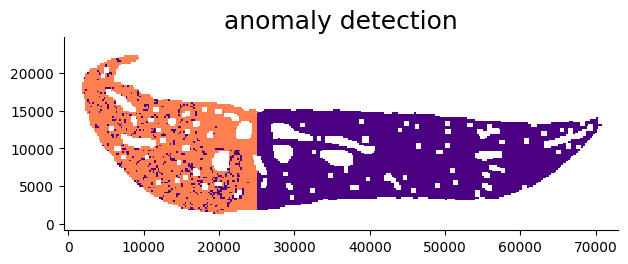

In [351]:
f_path_25 = "workspace/result/25_layer5.npy"
l_path_25 = "workspace/result/25_location.pickle"
feature_25 = np.load(f_path_25)
location_25 = pd.read_pickle(l_path_25)
feature_scaled_25 = scaler.fit_transform(feature_25)
jud_25 = ocsvm.predict(feature_scaled_25)
print(len([i for i in jud_25 if i == 1]))
print(len([i for i in jud_25 if i == -1]))
loc_plot(location_25, jud_25, ppi=50, size=112, title="anomaly detection")

5354
8978


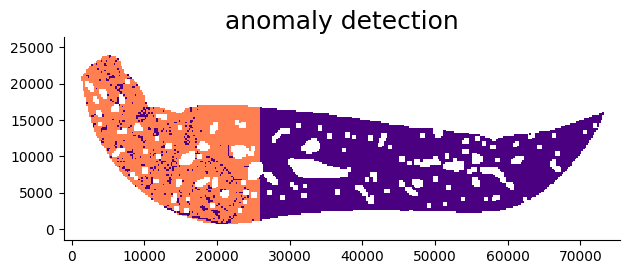

In [352]:
f_path_32 = "workspace/result/32_layer5.npy"
l_path_32 = "workspace/result/32_location.pickle"
feature_32 = np.load(f_path_32)
location_32 = pd.read_pickle(l_path_32)
feature_scaled_32 = scaler.fit_transform(feature_32)
jud_32 = ocsvm.predict(feature_scaled_32)
print(len([i for i in jud_32 if i == 1]))
print(len([i for i in jud_32 if i == -1]))
loc_plot(location_32, jud_32, ppi=50, size=112, title="anomaly detection")

12150
1639


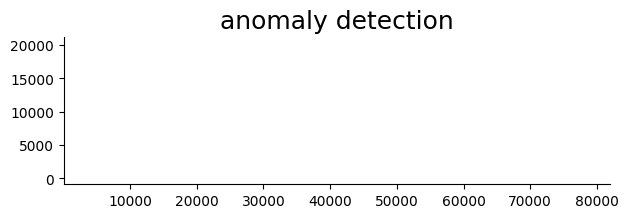

In [354]:
f_path_30 = "workspace/result/30_layer5.npy"
l_path_30 = "workspace/result/30_location.pickle"
feature_30 = np.load(f_path_30)
location_30 = pd.read_pickle(l_path_30)
feature_scaled_30 = scaler.fit_transform(feature_30)
jud_30 = ocsvm.predict(feature_scaled_30)
print(len([i for i in jud_30 if i == 1]))
print(len([i for i in jud_30 if i == -1]))
loc_plot(location_30, jud_30, ppi=50, size=112, title="anomaly detection")

#### error check ####

In [41]:
def loc_plot(location, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    for i in location:
        ax.scatter(i[0]+loc, i[1]-loc, alpha=1, color="indigo", s=size**2, marker=",", linewidth=0, edgecolors="gold")

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
f_path = "workspace/result/1_layer5.npy"
l_path = "workspace/result/1_location.pickle"
feature = np.load(f_path)
location = pd.read_pickle(l_path)

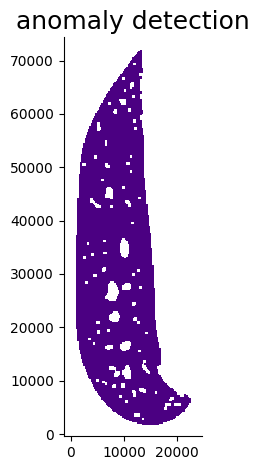

In [42]:
loc_plot(location, ppi=50, size=112, title="anomaly detection")

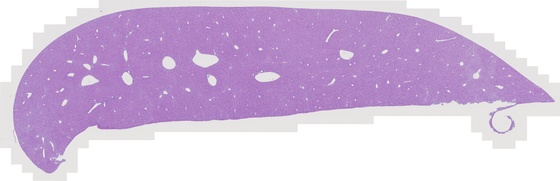

In [38]:
filename = "workspace/HE_240205_iwasaka/2024_02_05__0596-シングルファイルエクスポート-01.tif"
wsi = OpenSlide(filename)
wsi.get_thumbnail(size=(560, 560))

In [53]:
def get_mask_inside(
    image, 
    patch_size:int=224,
    slice_min_patch:int=1000,
    adjacent_cells_slice=[(-1,0),(1,0),(0,-1),(0,1),],
    adjacent_cells_inside=[(-1,0),(1,0),(0,-1),(0,1),(1,1),(1,-1),(-1,1),(-1,-1)],
    ):
    # load
    level = image.get_best_level_for_downsample(patch_size)
    downsample = image.level_downsamples[level]
    ratio = patch_size / downsample
    whole = image.read_region(location=(0,0), level=level,
        size = image.level_dimensions[level]).convert('HSV')
    whole = whole.resize((int(whole.width / ratio), int(whole.height / ratio)))
    whole = np.array(whole, dtype=np.uint8)
    # get mask
    saturation = whole[:,:,1] #saturation
    threshold, _ = cv2.threshold(saturation, 0, 255, cv2.THRESH_OTSU)
    mask = saturation > threshold
    # get slices > slice_min_patch
    left_mask = np.full((mask.shape[0]+1, mask.shape[1]+1), fill_value=False, dtype=bool)
    left_mask[:-1, :-1] = mask
    n_left_mask = np.sum(left_mask)
    slice_idx = np.full_like(mask, fill_value=-1, dtype=int)
    i_slice = 0
    while n_left_mask > 0:
        mask_i = np.where(left_mask)
        slice_left_indices = [(mask_i[0][0], mask_i[1][0])]
        while len(slice_left_indices) > 0:
            i, j = slice_left_indices.pop()
            if left_mask[i, j]:
                slice_idx[i, j] = i_slice
                for adj_i, adj_j in adjacent_cells_slice:
                    if left_mask[i+adj_i, j+adj_j]:
                        slice_left_indices.append((i+adj_i, j+adj_j))
                left_mask[i, j] = False
                n_left_mask -= 1
        slice_mask = slice_idx == i_slice
        if np.sum(slice_mask) < slice_min_patch:
            slice_idx[slice_mask] = -1
        else:
            i_slice += 1
    # re-difinition mask
    mask=slice_idx>-1
    # get inside mask
    mask_inside=np.zeros(mask.shape, dtype=bool)
    for i in range(1,mask.shape[0]-1):
        for v in range(1,mask.shape[1]-1):
            tf = mask[i][v]
            if tf:
                for adj in adjacent_cells_inside:
                    tf&=mask[i+adj[0]][v+adj[1]]
            mask_inside[i][v]=tf
    return mask_inside

In [55]:
filename = "workspace/HE_240205_iwasaka/2024_02_05__0596-シングルファイルエクスポート-01.tif"
wsi = OpenSlide(filename)
patch_size=224
mask_inside=get_mask_inside(wsi, patch_size=patch_size)
lst_number=np.array(range(len(mask_inside.flatten())))[mask_inside.flatten()]
lst_location=[[int(patch_size*v) for v in divmod(number, mask_inside.shape[1])][::-1] for number in lst_number]

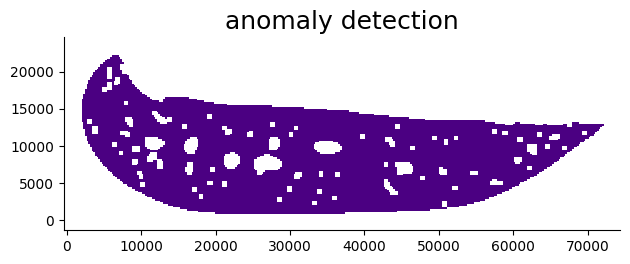

In [56]:
loc_plot(lst_location, ppi=50, size=112, title="anomaly detection")

#### ocsvm _v2 ####

In [75]:
def loc_plot(location, jud, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    for i in zip(jud, location):
        if i[0] == -1:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="indigo", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="coral", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.svm import OneClassSVM as OCSVM
import time

In [77]:
f_path_1 = "workspace/result_v2/1_layer5.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v2/2_layer5.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v2/3_layer5.npy"
feature_3 = np.load(f_path_3)

In [79]:
f_conc = list(feature_1) + list(feature_2) + list(feature_3)

In [80]:
#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

In [81]:
total_p = len(feature_scaled)
print(total_p)

38199


In [82]:
total_p = len(feature_scaled)
nu = 1/total_p #
gamma = 1/512 #一旦適当
ocsvm = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [89]:
f_path_1 = "workspace/result_v2/1_layer5.npy"
l_path_1 = "workspace/result_v2/1_location.pickle"
feature_1 = np.load(f_path_1)
location_1 = pd.read_pickle(l_path_1)
feature_scaled_1 = scaler.fit_transform(feature_1)
jud_1 = ocsvm.predict(feature_scaled_1)
print(len([i for i in jud_1 if i == 1]))
print(len([i for i in jud_1 if i == -1]))

14384
357


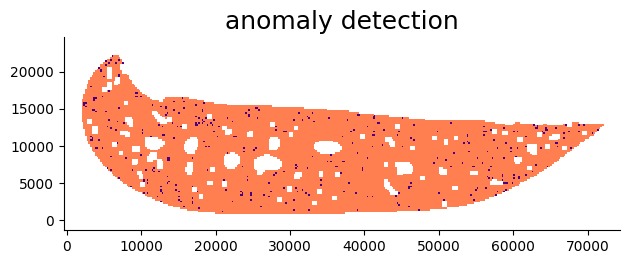

In [91]:
loc_plot(location_1, jud_1, ppi=50, size=112, title="anomaly detection")

14661
474


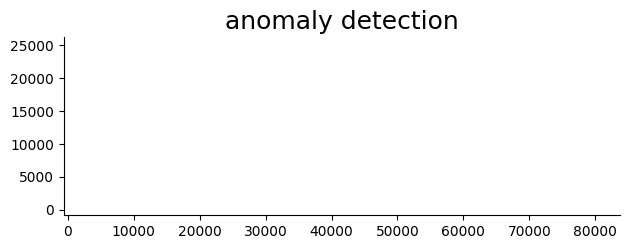

In [92]:
f_path_4 = "workspace/result_v2/4_layer5.npy"
l_path_4 = "workspace/result_v2/4_location.pickle"
feature_4 = np.load(f_path_4)
location_4 = pd.read_pickle(l_path_4)
feature_scaled_4 = scaler.fit_transform(feature_4)
jud_4 = ocsvm.predict(feature_scaled_4)
print(len([i for i in jud_4 if i == 1]))
print(len([i for i in jud_4 if i == -1]))
loc_plot(location_4, jud_4, ppi=50, size=112, title="anomaly detection")

In [94]:
len(jud_4)

15135

In [96]:
location_4

[[33600, 1568],
 [33824, 1568],
 [34048, 1568],
 [34272, 1568],
 [34496, 1568],
 [34720, 1568],
 [34944, 1568],
 [35168, 1568],
 [35392, 1568],
 [35616, 1568],
 [35840, 1568],
 [36064, 1568],
 [36288, 1568],
 [36512, 1568],
 [36736, 1568],
 [36960, 1568],
 [37184, 1568],
 [37408, 1568],
 [37632, 1568],
 [37856, 1568],
 [38080, 1568],
 [30464, 1792],
 [30688, 1792],
 [30912, 1792],
 [31136, 1792],
 [31360, 1792],
 [31584, 1792],
 [31808, 1792],
 [32032, 1792],
 [32256, 1792],
 [32480, 1792],
 [32704, 1792],
 [32928, 1792],
 [33152, 1792],
 [33376, 1792],
 [33600, 1792],
 [33824, 1792],
 [34048, 1792],
 [34272, 1792],
 [34496, 1792],
 [34720, 1792],
 [34944, 1792],
 [35168, 1792],
 [35392, 1792],
 [35616, 1792],
 [35840, 1792],
 [36064, 1792],
 [36288, 1792],
 [36512, 1792],
 [36736, 1792],
 [36960, 1792],
 [37184, 1792],
 [37408, 1792],
 [37632, 1792],
 [37856, 1792],
 [38080, 1792],
 [38304, 1792],
 [38528, 1792],
 [38752, 1792],
 [38976, 1792],
 [39200, 1792],
 [39424, 1792],
 [39648,

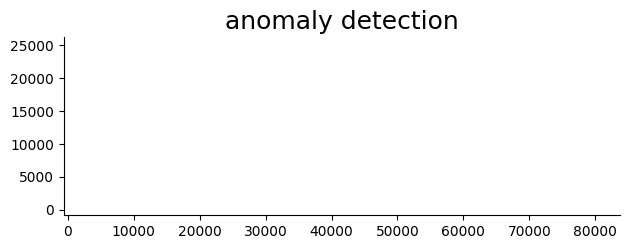

In [97]:
loc_plot(location_4, jud_4, ppi=50, size=112, title="anomaly detection")

12661
289


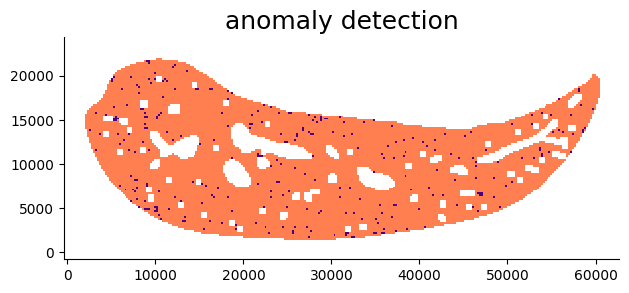

In [98]:
f_path_3 = "workspace/result_v2/3_layer5.npy"
l_path_3 = "workspace/result_v2/3_location.pickle"
feature_3 = np.load(f_path_3)
location_3 = pd.read_pickle(l_path_3)
feature_scaled_3 = scaler.fit_transform(feature_3)
jud_3 = ocsvm.predict(feature_scaled_3)
print(len([i for i in jud_3 if i == 1]))
print(len([i for i in jud_3 if i == -1]))
loc_plot(location_3, jud_3, ppi=50, size=112, title="anomaly detection")

12270
504


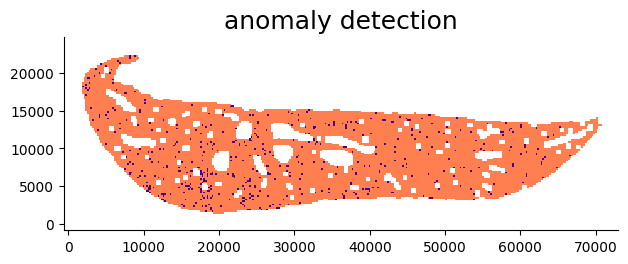

In [99]:
f_path_25 = "workspace/result_v2/25_layer5.npy"
l_path_25 = "workspace/result_v2/25_location.pickle"
feature_25 = np.load(f_path_25)
location_25 = pd.read_pickle(l_path_25)
feature_scaled_25 = scaler.fit_transform(feature_25)
jud_25 = ocsvm.predict(feature_scaled_25)
print(len([i for i in jud_25 if i == 1]))
print(len([i for i in jud_25 if i == -1]))
loc_plot(location_25, jud_25, ppi=50, size=112, title="anomaly detection")

12079
741


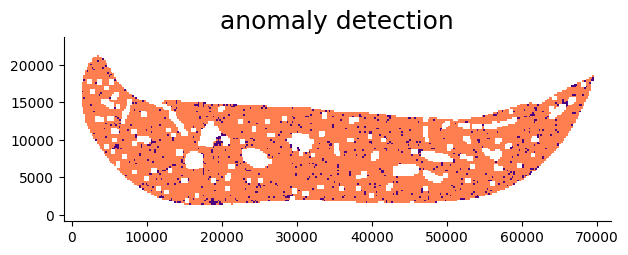

In [103]:
f_path_26 = "workspace/result_v2/26_layer5.npy"
l_path_26 = "workspace/result_v2/26_location.pickle"
feature_26 = np.load(f_path_26)
location_26 = pd.read_pickle(l_path_26)
feature_scaled_26 = scaler.fit_transform(feature_26)
jud_26 = ocsvm.predict(feature_scaled_26)
print(len([i for i in jud_26 if i == 1]))
print(len([i for i in jud_26 if i == -1]))
loc_plot(location_26, jud_26, ppi=50, size=112, title="anomaly detection")

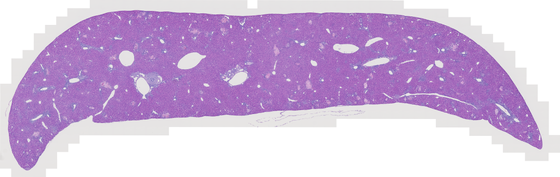

In [101]:
filename = "workspace/HE_240205_iwasaka/2024_02_05__0620-シングルファイルエクスポート-25.tif"
wsi = OpenSlide(filename)
wsi.get_thumbnail(size=(560, 560))

15490
765


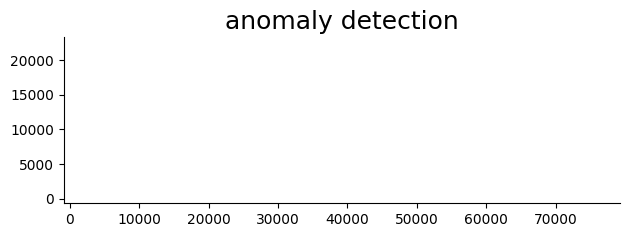

In [102]:
f_path_31 = "workspace/result_v2/31_layer5.npy"
l_path_31 = "workspace/result_v2/31_location.pickle"
feature_31 = np.load(f_path_31)
location_31 = pd.read_pickle(l_path_31)
feature_scaled_31 = scaler.fit_transform(feature_31)
jud_31 = ocsvm.predict(feature_scaled_31)
print(len([i for i in jud_31 if i == 1]))
print(len([i for i in jud_31 if i == -1]))
loc_plot(location_31, jud_31, ppi=50, size=112, title="anomaly detection")

sample No.29
13926
690


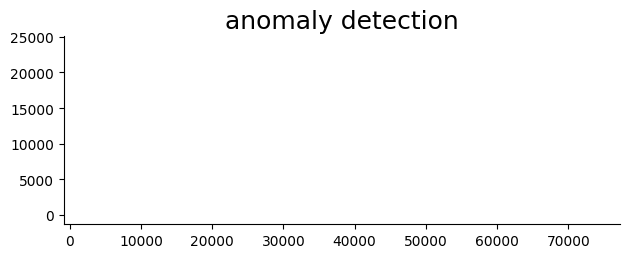

sample No.30
13134
655


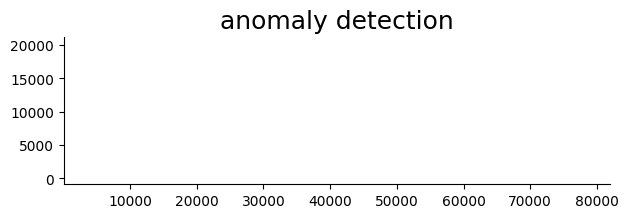

sample No.31
15490
765


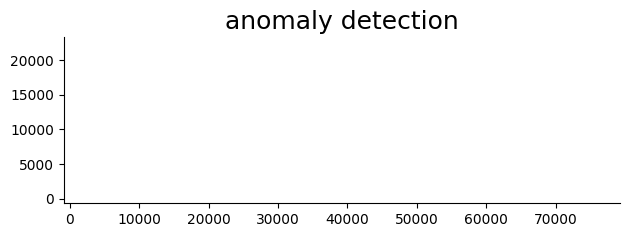

sample No.32
13611
721


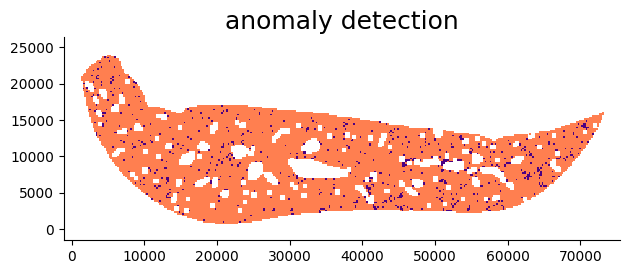

In [104]:
for i in [29, 30, 31, 32]:
    f_path = "workspace/result_v2/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print(len(location))
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

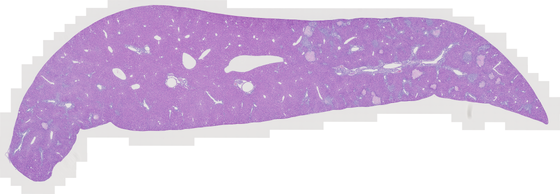

In [105]:
filename = "workspace/HE_240205_iwasaka/2024_02_05__0626-シングルファイルエクスポート-31.tif"
wsi = OpenSlide(filename)
wsi.get_thumbnail(size=(560, 560))

sample No.4
14661
474
15135
Percentage of abnormal patches : 0.032330673214651114


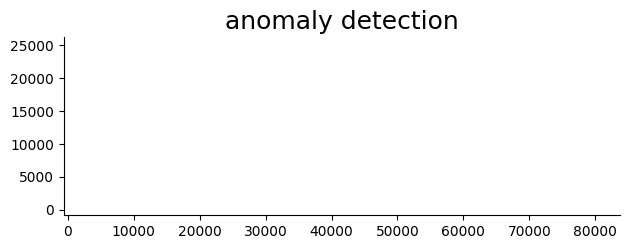

sample No.5
15237
452
15689
Percentage of abnormal patches : 0.02966463214543545


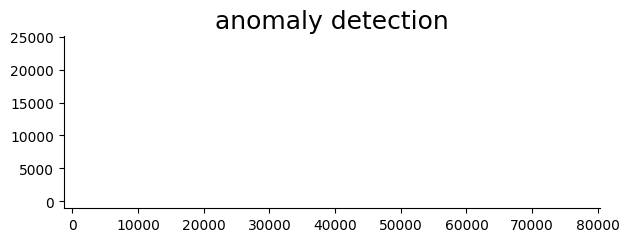

sample No.6
12640
442
13082
Percentage of abnormal patches : 0.034968354430379746


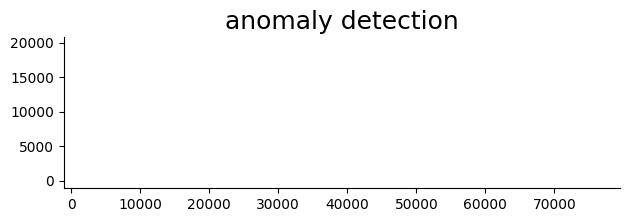

sample No.7
11038
322
11360
Percentage of abnormal patches : 0.029171951440478346


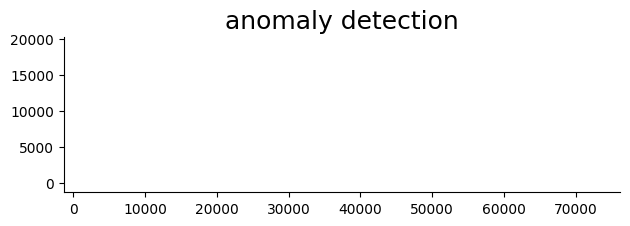

sample No.8
13801
402
14203
Percentage of abnormal patches : 0.029128324034490255


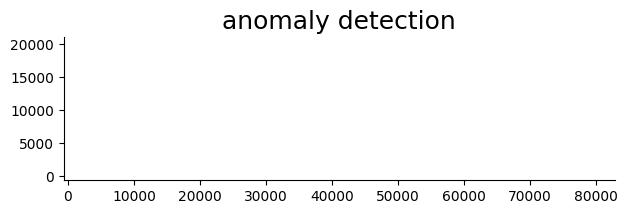

sample No.9
12139
394
12533
Percentage of abnormal patches : 0.03245736881126946


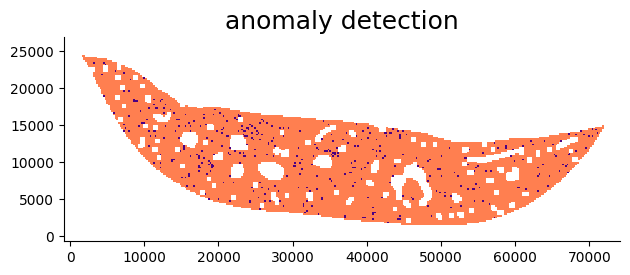

sample No.10
9904
381
10285
Percentage of abnormal patches : 0.03846930533117932


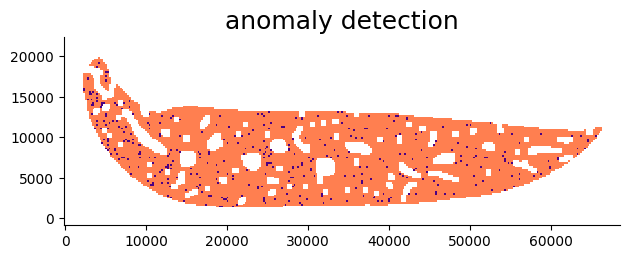

sample No.11
10363
343
10706
Percentage of abnormal patches : 0.03309852359355399


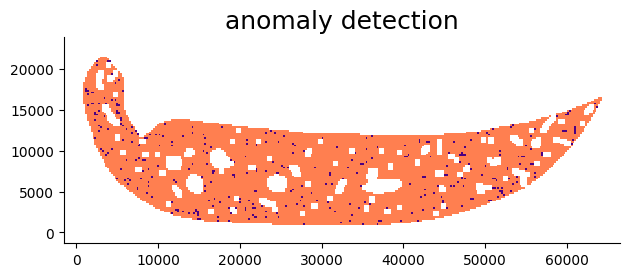

sample No.12
12822
406
13228
Percentage of abnormal patches : 0.03166432693807519


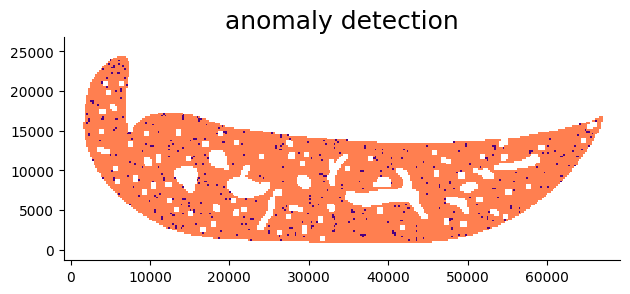

sample No.13
11796
404
12200
Percentage of abnormal patches : 0.0342488979315022


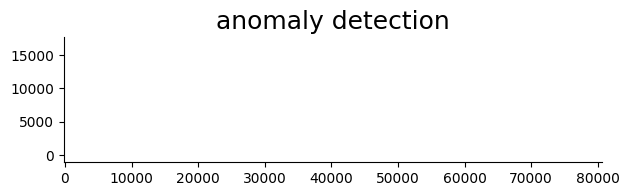

sample No.14
14560
628
15188
Percentage of abnormal patches : 0.04313186813186813


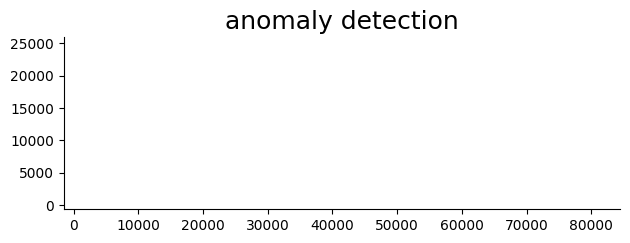

sample No.15
13283
508
13791
Percentage of abnormal patches : 0.03824437250621095


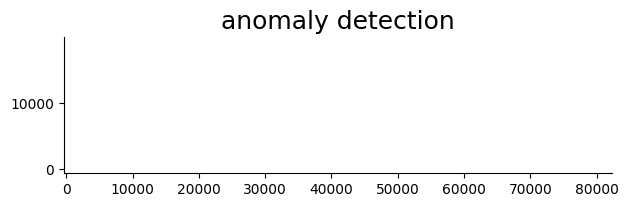

sample No.16
14266
739
15005
Percentage of abnormal patches : 0.05180148605075004


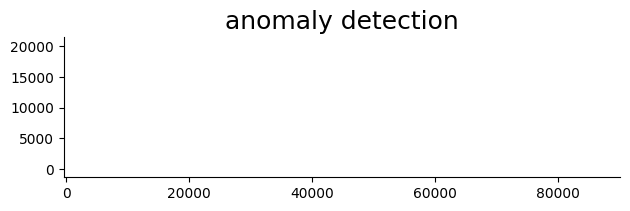

sample No.17
13052
347
13399
Percentage of abnormal patches : 0.026585963836959853


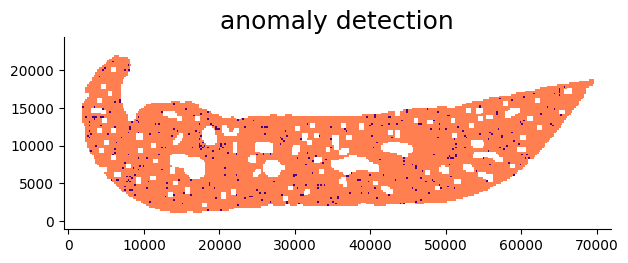

sample No.18
10000
298
10298
Percentage of abnormal patches : 0.0298


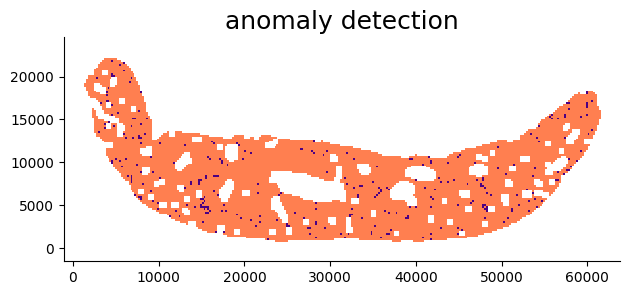

sample No.19
12523
387
12910
Percentage of abnormal patches : 0.030903138225664775


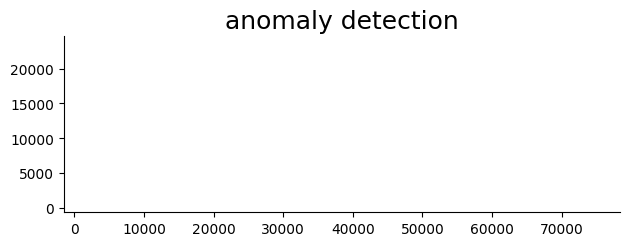

sample No.21
8513
386
8899
Percentage of abnormal patches : 0.045342417479149535


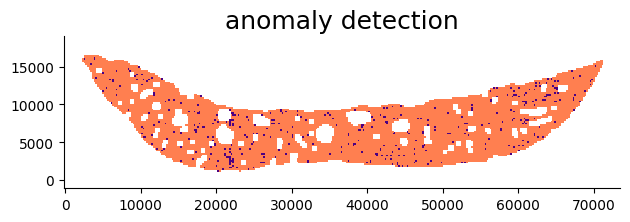

sample No.22
10735
395
11130
Percentage of abnormal patches : 0.0367955286446204


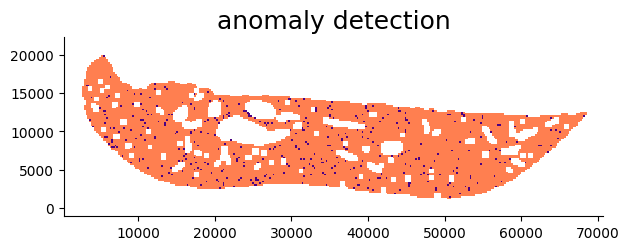

sample No.23
12620
551
13171
Percentage of abnormal patches : 0.0436608557844691


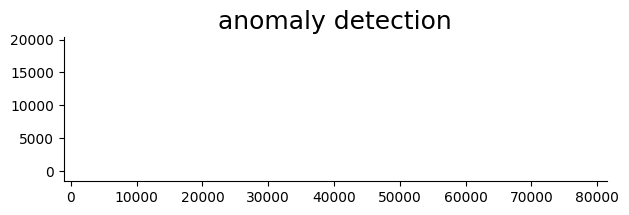

sample No.24
10444
727
11171
Percentage of abnormal patches : 0.06960934507851398


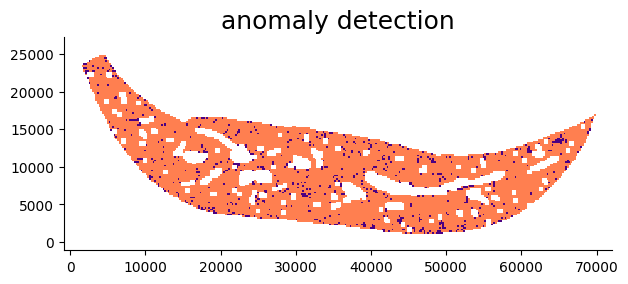

sample No.25
12270
504
12774
Percentage of abnormal patches : 0.041075794621026895


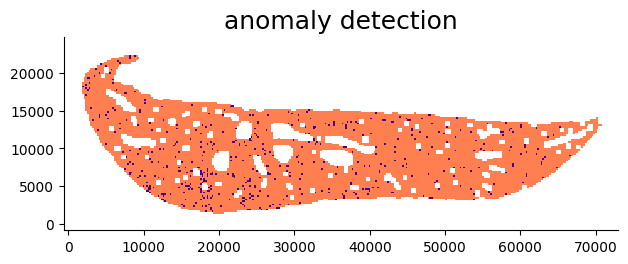

sample No.26
12079
741
12820
Percentage of abnormal patches : 0.061346137925324944


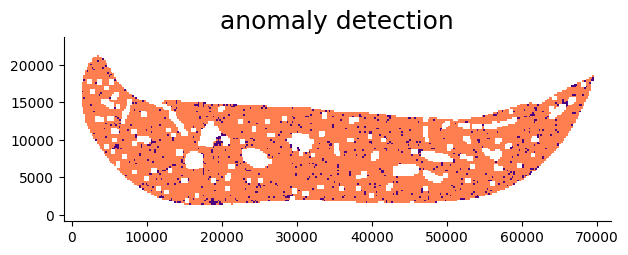

sample No.27
10418
996
11414
Percentage of abnormal patches : 0.09560376271837205


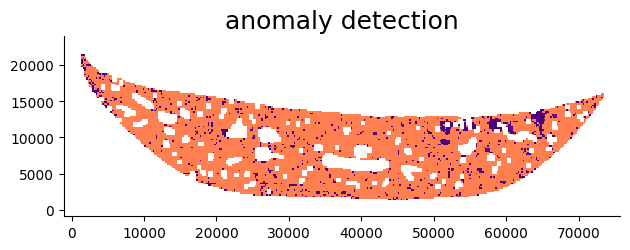

sample No.28
12840
590
13430
Percentage of abnormal patches : 0.045950155763239874


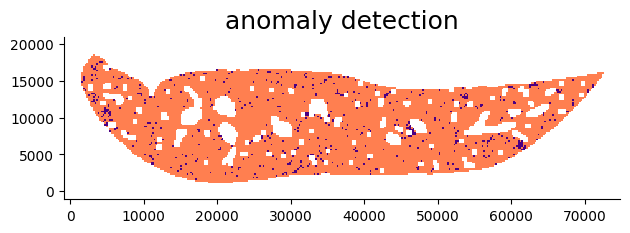

sample No.29
13926
690
14616
Percentage of abnormal patches : 0.049547608789314954


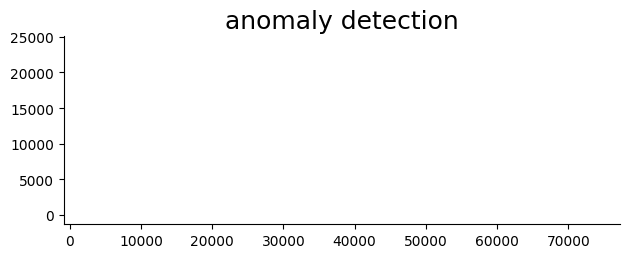

sample No.30
13134
655
13789
Percentage of abnormal patches : 0.04987056494594183


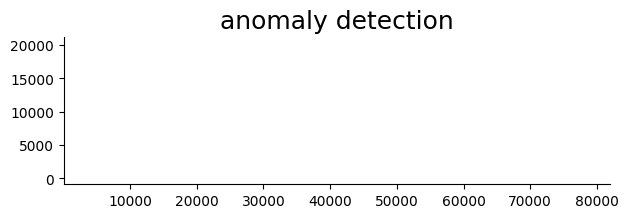

sample No.31
15490
765
16255
Percentage of abnormal patches : 0.04938670109748225


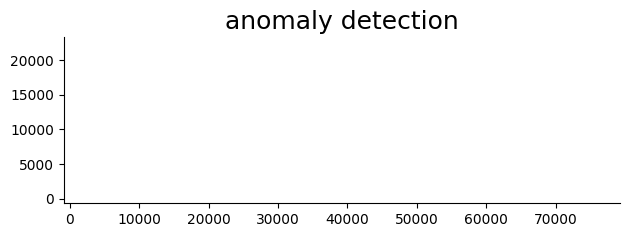

sample No.32
13611
721
14332
Percentage of abnormal patches : 0.05297186099478363


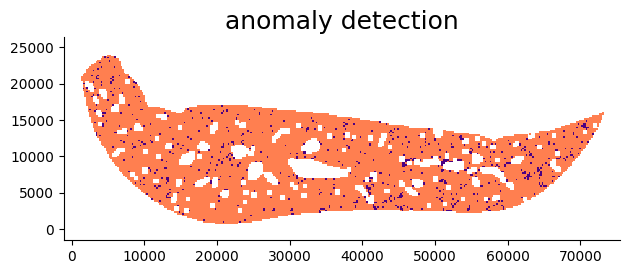

sample No.33
12797
704
13501
Percentage of abnormal patches : 0.0550128936469485


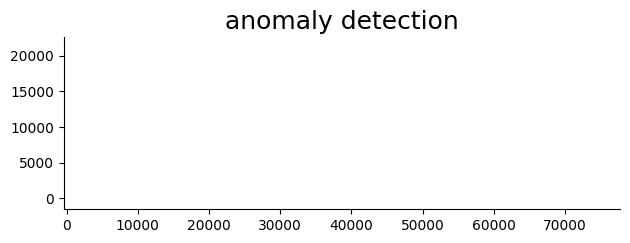

sample No.34
13066
727
13793
Percentage of abnormal patches : 0.05564059390785244


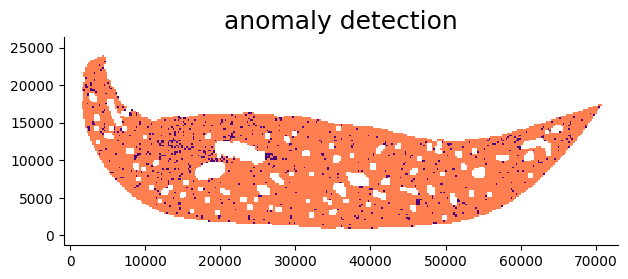

sample No.35
16325
791
17116
Percentage of abnormal patches : 0.048453292496171516


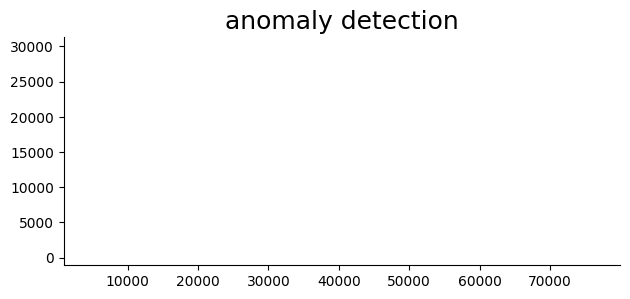

sample No.36
14722
778
15500
Percentage of abnormal patches : 0.05284608069555767


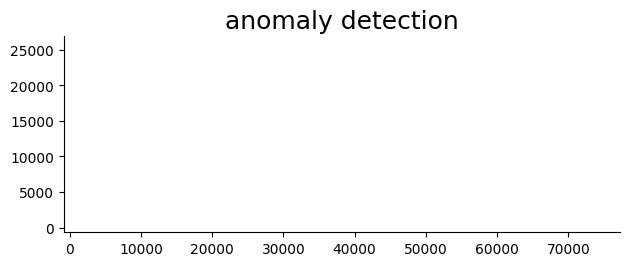

In [107]:
for i in [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]:
    f_path = "workspace/result_v2/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print(len(location))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

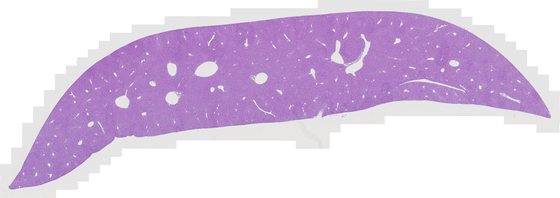

In [108]:
filename = "workspace/HE_240205_iwasaka/2024_02_05__0604-シングルファイルエクスポート-09.tif"
wsi = OpenSlide(filename)
wsi.get_thumbnail(size=(560, 560))

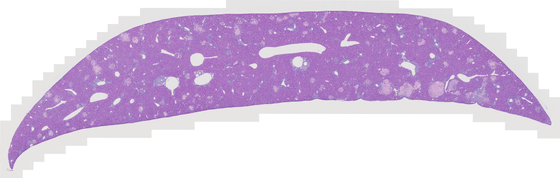

In [109]:
filename = "workspace/HE_240205_iwasaka/2024_02_05__0621-シングルファイルエクスポート-26.tif"
wsi = OpenSlide(filename)
wsi.get_thumbnail(size=(560, 560))

9622
1792


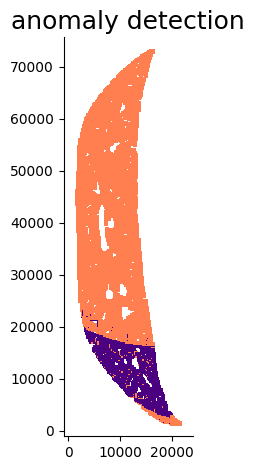

In [110]:
f_path_27 = "workspace/result/27_layer5.npy"
l_path_27 = "workspace/result/27_location.pickle"
feature_27 = np.load(f_path_27)
location_27 = pd.read_pickle(l_path_27)
feature_scaled_27 = scaler.fit_transform(feature_27)
jud_27 = ocsvm.predict(feature_scaled_27)
print(len([i for i in jud_27 if i == 1]))
print(len([i for i in jud_27 if i == -1]))
loc_plot(location_27, jud_27, ppi=50, size=112, title="anomaly detection")

#### ocsvm v3 ####

In [13]:
def loc_plot(location, jud, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    print(size)
    if size < 1:
        size = 1

    for i in zip(jud, location):
        if i[0] == -1:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="coral", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="indigo", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

In [4]:
f_path_1 = "workspace/result_v2/1_layer5.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v2/2_layer5.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v2/3_layer5.npy"
feature_3 = np.load(f_path_3)
f_path_5 = "workspace/result_v2/5_layer5.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v2/6_layer5.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v2/7_layer5.npy"
feature_7 = np.load(f_path_7)
f_path_9 = "workspace/result_v2/9_layer5.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v2/10_layer5.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v2/11_layer5.npy"
feature_11 = np.load(f_path_11)

In [5]:
f_conc = list(feature_1) + list(feature_2) + list(feature_3)+ list(feature_5)+ list(feature_6)+ list(feature_7)+ list(feature_9)+ list(feature_10)+ list(feature_11)

In [6]:
len(f_conc)

111854

In [11]:
#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

In [12]:
total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

sample No.4
14231
904
15135
Percentage of abnormal patches : 0.06352329421685053
0.6581990521327014


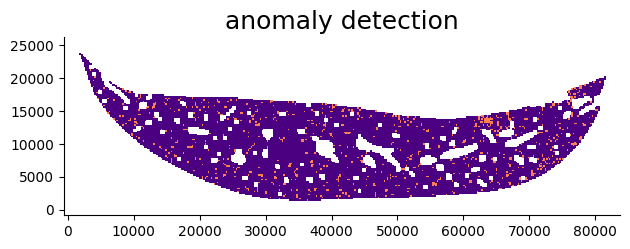

In [16]:
for i in [4]:
    f_path = "workspace/result_v2/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print(len(location))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

sample No.4
14231
904
15135
Percentage of abnormal patches : 0.06352329421685053
0.6581990521327014


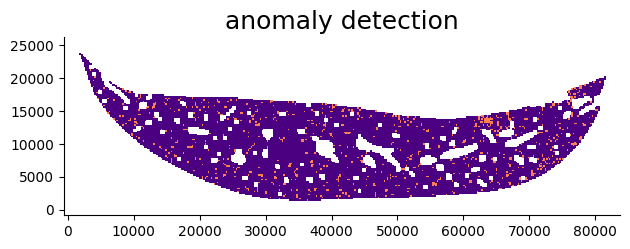

sample No.8
13465
738
14203
Percentage of abnormal patches : 0.05480876346082436
0.6652615443571566


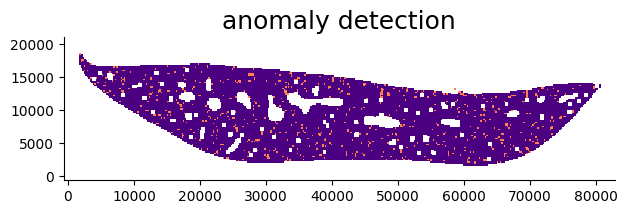

sample No.12
12451
777
13228
Percentage of abnormal patches : 0.062404626134447035
0.79287508563599


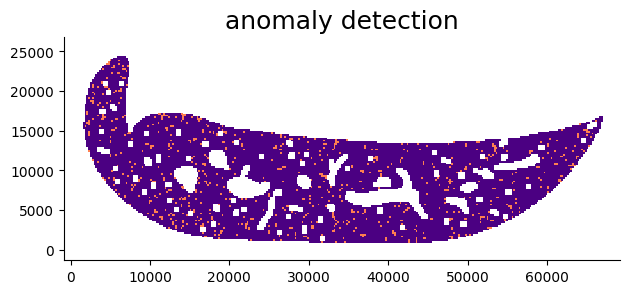

sample No.13
11451
749
12200
Percentage of abnormal patches : 0.0654091345733997
0.6873886359136804


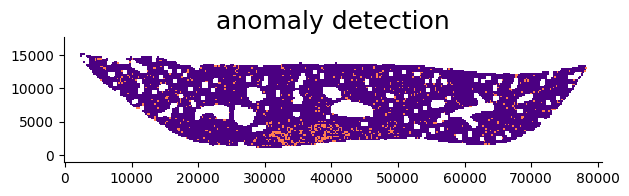

sample No.14
14168
1020
15188
Percentage of abnormal patches : 0.07199322416713722
0.6461939326260935


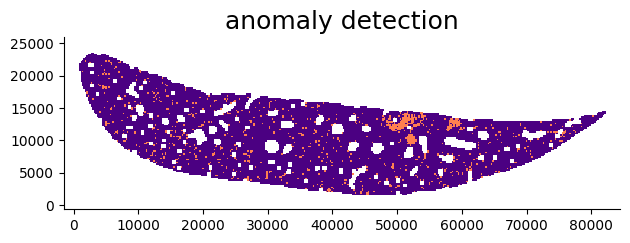

sample No.15
12889
902
13791
Percentage of abnormal patches : 0.06998215532624719
0.6706586826347306


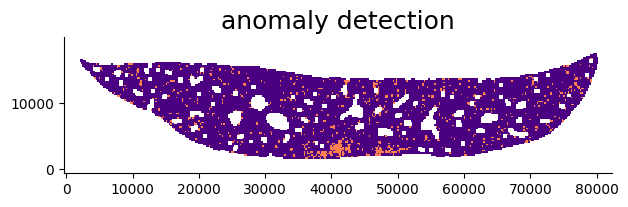

sample No.16
13856
1149
15005
Percentage of abnormal patches : 0.08292436489607391
0.614187157261631


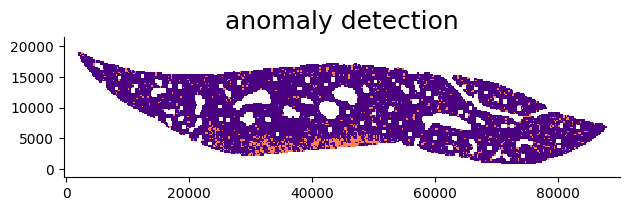

sample No.17
12749
650
13399
Percentage of abnormal patches : 0.050984390932622164
0.7659386719611736


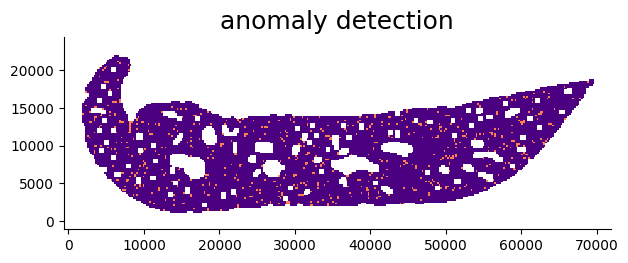

sample No.18
9736
562
10298
Percentage of abnormal patches : 0.057723911257189814
0.8558047818585162


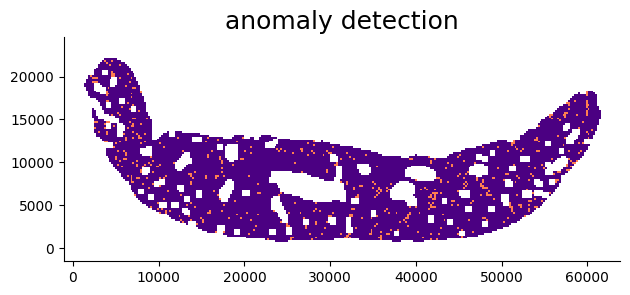

sample No.19
12323
587
12910
Percentage of abnormal patches : 0.0476345045849225
0.6950950950950952


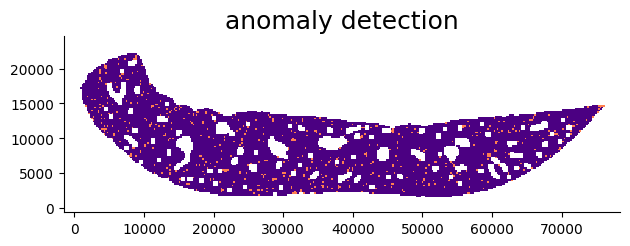

sample No.21
8507
392
8899
Percentage of abnormal patches : 0.046079699071353
0.7542906799913099


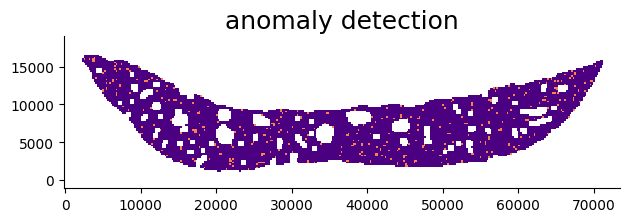

sample No.22
10590
540
11130
Percentage of abnormal patches : 0.05099150141643059
0.787837531200363


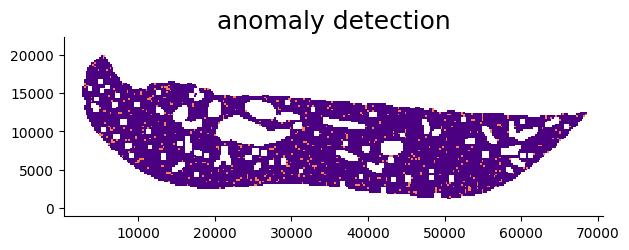

sample No.23
12504
667
13171
Percentage of abnormal patches : 0.05334293026231606
0.6724772419136161


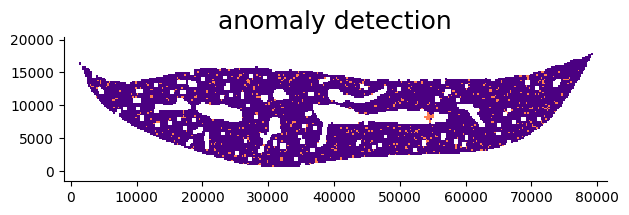

sample No.24
10433
738
11171
Percentage of abnormal patches : 0.07073708425189303
0.7612365709274281


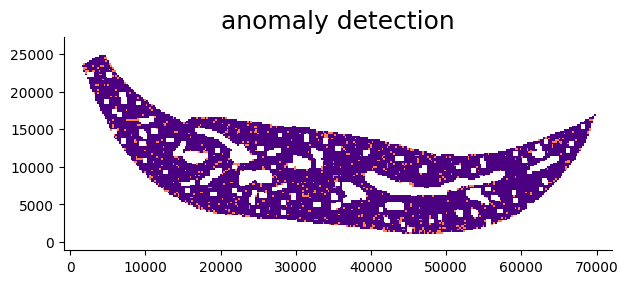

sample No.25
12161
613
12774
Percentage of abnormal patches : 0.05040703889482773
0.7542906799913099


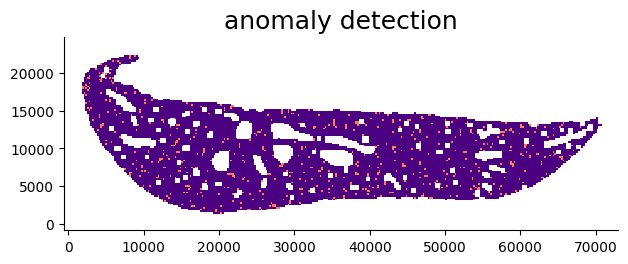

sample No.26
12084
736
12820
Percentage of abnormal patches : 0.06090698444223767
0.7612365709274281


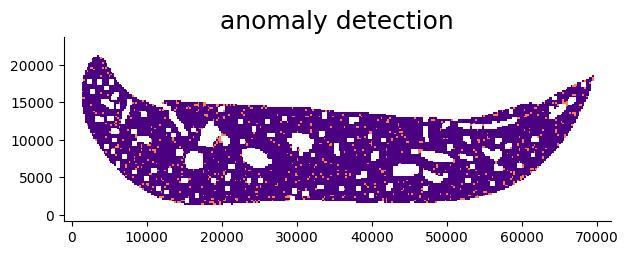

sample No.27
10494
920
11414
Percentage of abnormal patches : 0.08766914427291786
0.7234840591789956


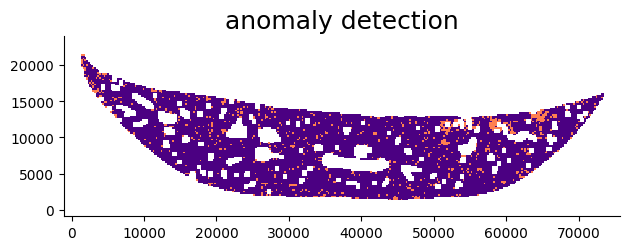

sample No.28
12590
840
13430
Percentage of abnormal patches : 0.06671961874503574
0.7341932755339395


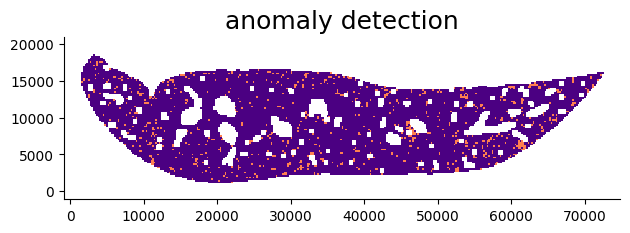

sample No.29
13753
863
14616
Percentage of abnormal patches : 0.06274994546644369
0.7110382961294286


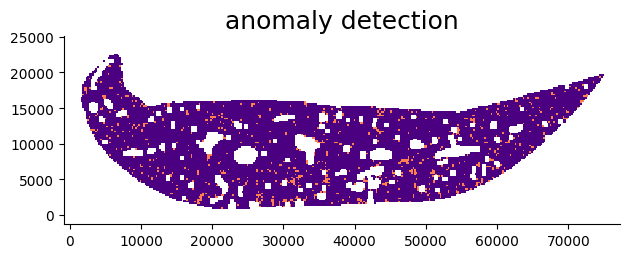

sample No.30
12914
875
13789
Percentage of abnormal patches : 0.06775592380362397
0.6779925795743019


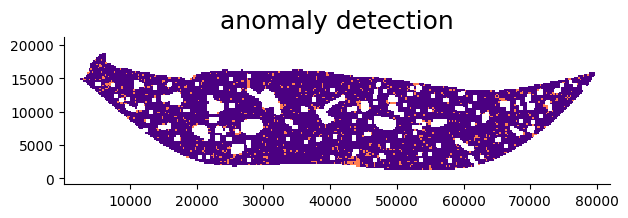

sample No.31
15344
911
16255
Percentage of abnormal patches : 0.05937174139728884
0.6931523258135357


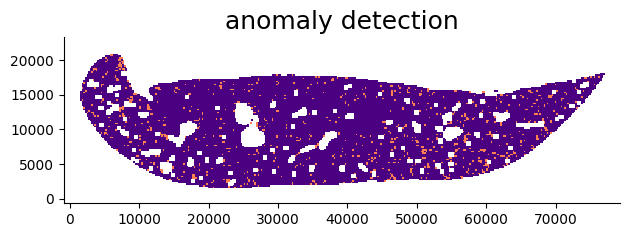

sample No.32
13522
810
14332
Percentage of abnormal patches : 0.05990238130454075
0.7256008359456636


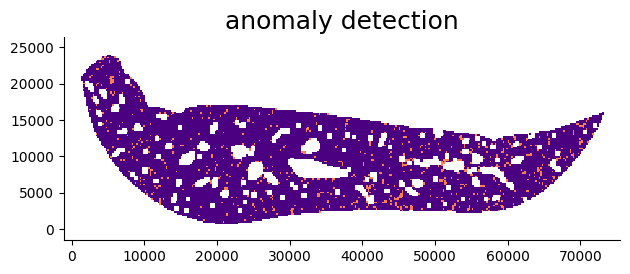

sample No.33
12729
772
13501
Percentage of abnormal patches : 0.06064891193338047
0.7110382961294286


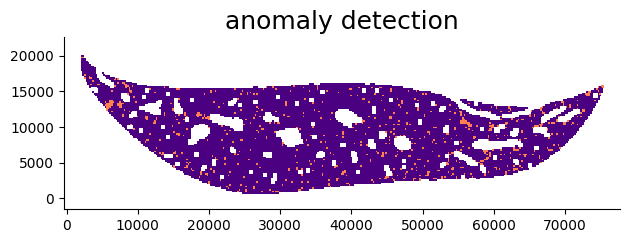

sample No.34
12966
827
13793
Percentage of abnormal patches : 0.06378219959895111
0.7520034654537578


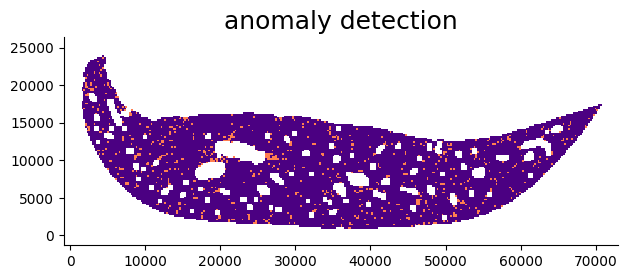

sample No.35
16050
1066
17116
Percentage of abnormal patches : 0.06641744548286604
0.7029763109941284


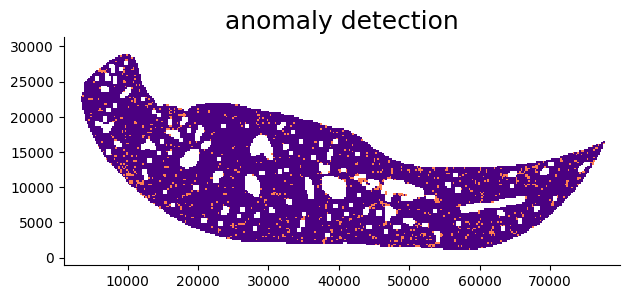

sample No.36
14606
894
15500
Percentage of abnormal patches : 0.0612077228536218
0.7110382961294286


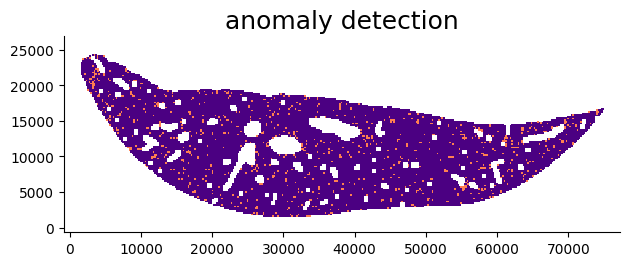

In [165]:
for i in [4, 8, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]:
    f_path = "workspace/result_v2/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print(len(location))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

#### PCA ####

In [12]:
def get_info(sample_id, feature, location, jud):
    inf_lst = []
    ap = inf_lst.append
    for i in zip(jud, feature, location):
        if i[0] == -1:
            ap([sample_id, i[1], i[2]])

    return inf_lst

sample No.4
14231
904
Percentage of abnormal patches : 0.06352329421685053
0.6581990521327014


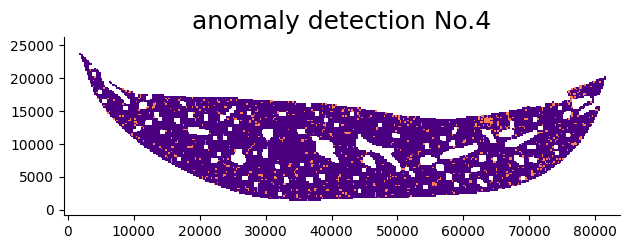

sample No.16
13856
1149
Percentage of abnormal patches : 0.08292436489607391
0.614187157261631


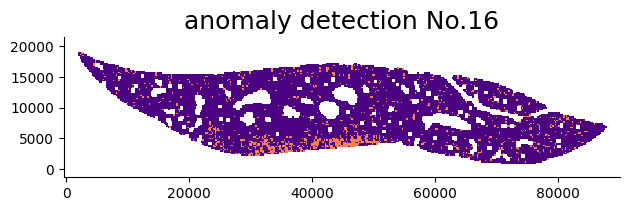

sample No.27
10494
920
Percentage of abnormal patches : 0.08766914427291786
0.7234840591789956


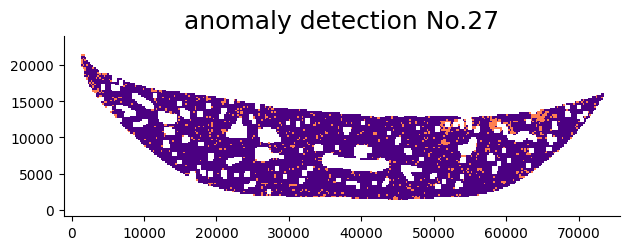

In [362]:
total_inf_lst = []
for i in [4, 16, 27]:
    f_path = "workspace/result_v2/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection No."+str(i))

In [179]:
total_inf_lst

[[4,
  array([ 6.45873070e-01,  3.82803488e+00,  1.93451226e+00,  1.68937683e+00,
          6.96161211e-01,  5.53057849e-01, -1.10650206e+00,  6.55298829e-01,
          6.04768157e-01,  1.40376246e+00, -4.76562768e-01, -7.08342373e-01,
          3.21867801e-02, -3.49893630e-01,  2.06668884e-01, -7.30054379e-01,
          7.30197906e-01, -2.05528855e+00, -1.25948787e+00,  4.69191730e-01,
          2.05909657e+00, -7.66771555e-01,  4.20104980e+00,  1.04301192e-01,
         -3.96605670e-01,  3.05175471e+00, -1.65006185e+00,  3.43353212e-01,
          6.67348921e-01, -8.19734037e-01, -7.28532672e-01, -7.38824978e-02,
          1.26854908e+00,  6.48284531e+00, -7.28170514e-01,  1.57808912e+00,
         -1.31056100e-01, -4.31506842e-01,  1.83037817e-01, -2.27814123e-01,
          2.06841326e+00,  4.73668605e-01, -7.07551718e-01, -3.23926926e-01,
         -2.36849144e-01, -8.11313987e-01, -1.07596123e+00,  2.20367119e-01,
         -3.48729938e-01, -8.55586648e-01,  2.47163415e-01, -9.23592746

In [186]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

In [187]:
len(pca_feature)

2973

In [188]:
from sklearn.decomposition import PCA

In [189]:
pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

In [191]:
# 第一主成分と第二主成分でプロットする
def PCAplot(feature, xnum=0, ynum=1, title="RNAseq batch check"):
    fig, ax = plt.subplots()
    for i in range(len(feature)):
        ax.scatter(feature[:, xnum][i], feature[:, ynum][i], alpha=1, color="pink")

    ax.set_title(title, fontsize=18)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

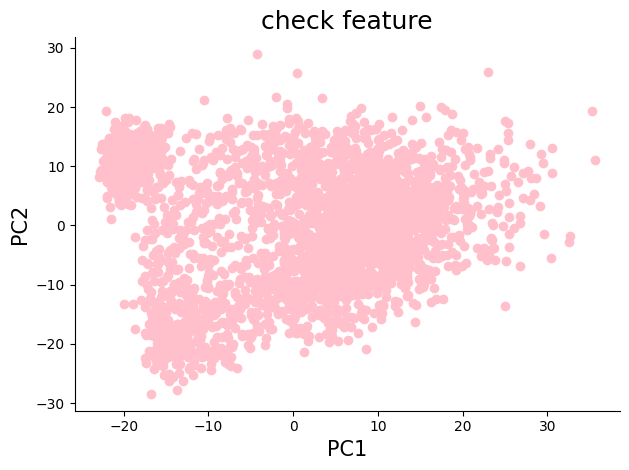

In [192]:
PCAplot(feature_pca, xnum=0, ynum=1, title="check feature")

In [193]:
bach_lst = []
ap = bach_lst.append
for i in total_inf_lst:
    ap(i[0])

In [ ]:
colors= ["dimgray", "orangered", "mediumblue"]

In [194]:
bach_dict = {4:"dimgray", 16:"orangered", 27:"mediumblue"}

In [195]:
bach_dict[4]

'dimgray'

In [211]:
# 第一主成分と第二主成分でプロットする
def PCAplot(feature, bach_lst, bach_dict, xnum=0, ynum=1, title="RNAseq batch check"):
    fig, ax = plt.subplots()
    for i in range(len(feature)):
        ax.scatter(feature[:, xnum][i], feature[:, ynum][i], alpha=0.7, color=bach_dict[bach_lst[i]])

    ax.set_title(title, fontsize=18)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

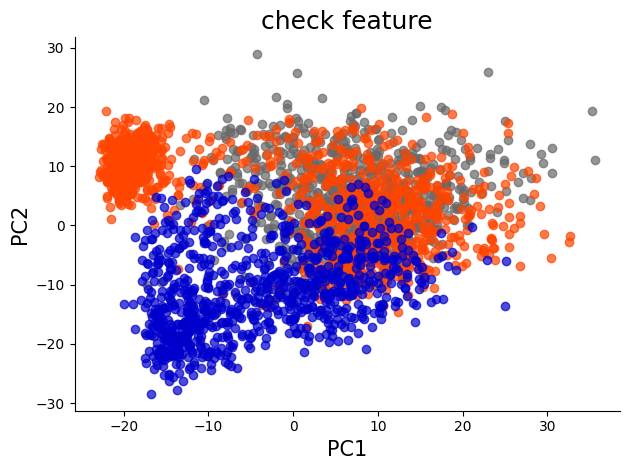

In [199]:
PCAplot(feature_pca, bach_lst, bach_dict, xnum=0, ynum=1, title="check feature")

In [251]:
feature_pca

array([[-5.08843108e-01,  4.02283693e+00, -1.04969244e+00, ...,
         2.74243309e-01, -2.18175173e-01, -6.60647049e-02],
       [ 6.16318919e+00,  1.03422693e+00, -6.41959897e+00, ...,
         5.32174057e-02, -8.99187195e-02,  2.30979295e-01],
       [ 3.41678960e+00, -9.56863533e+00, -4.78638489e+00, ...,
        -1.40832050e-01,  1.83682191e-01,  1.28991829e-01],
       ...,
       [-1.12733973e+00, -5.80973367e+00, -7.35852621e+00, ...,
         3.82643395e-02,  6.05436173e-02,  6.73529864e-02],
       [ 8.58491844e+00, -1.42725500e+01, -3.12350870e-01, ...,
        -3.12647434e-01,  5.11092137e-03,  4.46115673e-02],
       [ 6.01181231e+00, -1.45929324e+01,  1.30128992e+01, ...,
        -9.65662330e-02, -5.62152695e-03,  9.33529732e-02]])

In [252]:
pca_inf = [[i[0], i[2]] for i in total_inf_lst]

In [254]:
pca_inf

[[4, [36288, 1568]],
 [4, [32032, 1792]],
 [4, [35168, 1792]],
 [4, [40992, 1792]],
 [4, [30688, 2016]],
 [4, [34720, 2016]],
 [4, [38528, 2016]],
 [4, [47040, 2016]],
 [4, [32704, 2240]],
 [4, [34720, 2240]],
 [4, [37632, 2240]],
 [4, [38304, 2240]],
 [4, [40768, 2240]],
 [4, [41216, 2240]],
 [4, [42560, 2240]],
 [4, [46592, 2240]],
 [4, [48160, 2240]],
 [4, [51968, 2240]],
 [4, [32928, 2464]],
 [4, [34720, 2464]],
 [4, [36512, 2464]],
 [4, [42112, 2464]],
 [4, [46592, 2464]],
 [4, [49056, 2464]],
 [4, [49280, 2464]],
 [4, [55328, 2464]],
 [4, [57344, 2464]],
 [4, [30016, 2688]],
 [4, [41664, 2688]],
 [4, [42112, 2688]],
 [4, [46592, 2688]],
 [4, [58464, 2688]],
 [4, [25760, 2912]],
 [4, [28224, 2912]],
 [4, [28672, 2912]],
 [4, [30016, 2912]],
 [4, [36736, 2912]],
 [4, [48160, 2912]],
 [4, [51520, 2912]],
 [4, [58240, 2912]],
 [4, [62048, 2912]],
 [4, [27328, 3136]],
 [4, [28672, 3136]],
 [4, [32032, 3136]],
 [4, [33824, 3136]],
 [4, [34720, 3136]],
 [4, [36512, 3136]],
 [4, [37408, 

In [236]:
import random
random.seed(24771)

In [ ]:
l.count('a')

In [465]:
# 第一主成分と第二主成分でプロットする
def PCAplot_v2(feature, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, pict_sample=6, seed1=2477, seed2=2477, title=""):
    fig, ax = plt.subplots()
    label_lst = []
    ap = label_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    n = 0
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature)), sample)
    random.seed(seed2)
    random.shuffle(ran_sam)
    for i in ran_sam:
        if pca_inf[i][0] not in label_lst:
            ax.scatter(
                feature[:, xnum][i], feature[:, ynum][i], 
                alpha=0.7, s=50, 
                color=bach_dict[pca_inf[i][0]], linewidth=0,
                label="No."+str(pca_inf[i][0]), zorder=1
                )
            ap(pca_inf[i][0])

        elif pca_inf[i][0] == 4 and label_lst.count(4) < pict_sample+1:
            ax.scatter(
                feature[:, xnum][i], feature[:, ynum][i], 
                alpha=0.7, s=50, 
                color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                )
            ap(pca_inf[i][0])
            ax.text(
                feature[:, xnum][i], feature[:, ynum][i],
                s = str(label_lst.count(4)-1), weight="bold"
            )
            ap_loc([label_lst.count(4)-1, pca_inf[i][1], pca_inf[i][0]])


        elif pca_inf[i][0] == 16 and label_lst.count(16) < pict_sample+1:
            ax.scatter(
                feature[:, xnum][i], feature[:, ynum][i], 
                alpha=0.7, s=50, 
                color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                )
            ap(pca_inf[i][0])
            ax.text(
                feature[:, xnum][i], feature[:, ynum][i],
                s = str(label_lst.count(16)-1+pict_sample), weight="bold"
            )
            ap_loc([label_lst.count(16)-1+pict_sample, pca_inf[i][1], pca_inf[i][0]])

        elif pca_inf[i][0] == 27 and label_lst.count(27) < pict_sample+1:
            ax.scatter(
                feature[:, xnum][i], feature[:, ynum][i], 
                alpha=0.7, s=50, 
                color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                )
            ap(pca_inf[i][0])
            ax.text(
                feature[:, xnum][i], feature[:, ynum][i],
                s = str(label_lst.count(27)-1+pict_sample*2), weight="bold"
            )
            ap_loc([label_lst.count(27)-1+pict_sample*2, pca_inf[i][1], pca_inf[i][0]])
         
        else:
            ax.scatter(
                feature[:, xnum][i], feature[:, ynum][i], 
                alpha=0.7, s=50, 
                color=bach_dict[pca_inf[i][0]], linewidth=0, zorder=1
                )            

    ax.set_title(title, fontsize=18)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()
    
    return loc_lst

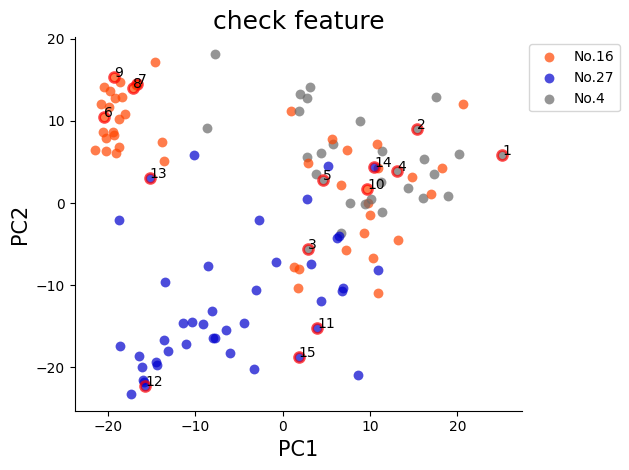

In [448]:
loc_lst = PCAplot_v2(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=120, pict_sample=5, title="check feature")

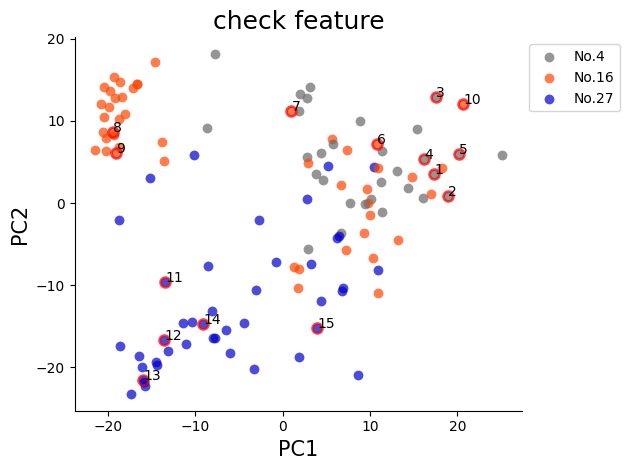

In [462]:
loc_lst_2 = PCAplot_v2(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=120, pict_sample=5, seed2=10, title="check feature")

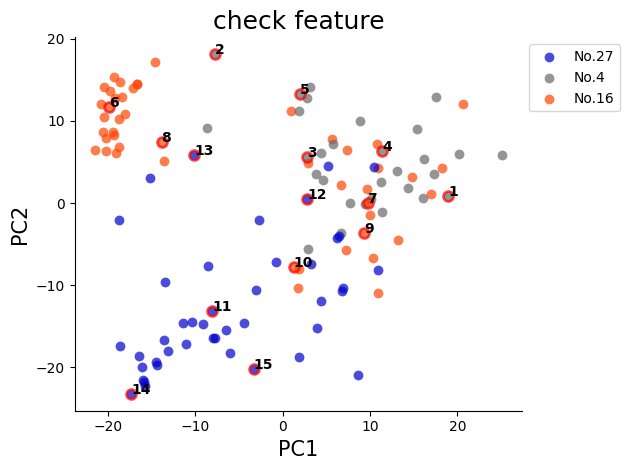

In [469]:
for i in range(1):
    loc_lst_2 = PCAplot_v2(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=120, pict_sample=5, seed2=i+30, title="check feature")

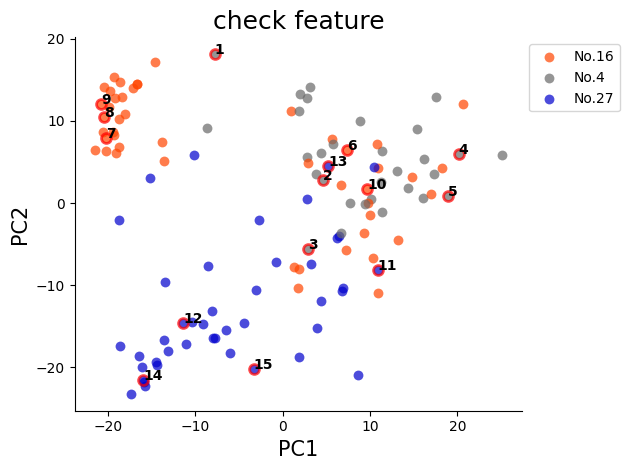

In [471]:
loc_lst_2 = PCAplot_v2(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=120, pict_sample=5, seed2=35, title="check feature")

In [472]:
loc_lst_2

[[6, [78624, 6944], 16],
 [7, [39648, 3360], 16],
 [8, [47264, 5824], 16],
 [11, [52416, 2016], 27],
 [1, [76832, 17248], 4],
 [9, [40992, 4480], 16],
 [10, [26208, 11200], 16],
 [12, [58016, 11648], 27],
 [13, [58912, 9632], 27],
 [14, [19040, 3584], 27],
 [2, [58240, 4480], 4],
 [15, [58464, 3136], 27],
 [3, [62272, 13888], 4],
 [4, [28672, 3360], 4],
 [5, [41888, 11872], 4]]

In [473]:
from openslide import OpenSlide
from PIL import Image

In [474]:
patch_size = 224

In [475]:
for n in range(len(loc_lst_2)):
    if loc_lst_2[n][2] < 20:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst_2[n][2])+"-シングルファイルエクスポート-"+str(loc_lst_2[n][2]).zfill(2)+".tif"
        print(filename)
    else:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst_2[n][2]-1)+"-シングルファイルエクスポート-"+str(loc_lst_2[n][2]-1).zfill(2)+".tif"
        print(filename)

    wsi = OpenSlide(filename)
    print(loc_lst_2[n][0])
    wsi.read_region(location=tuple(loc_lst_2[n][1]), level=0, size=(patch_size,patch_size)).convert("RGB").save("workspace/fig/loc2/loc"+str(loc_lst_2[n][0])+".jpg", "JPEG")

workspace/HE_240205_iwasaka/2024_02_05__0611-シングルファイルエクスポート-16.tif
6
workspace/HE_240205_iwasaka/2024_02_05__0611-シングルファイルエクスポート-16.tif
7
workspace/HE_240205_iwasaka/2024_02_05__0611-シングルファイルエクスポート-16.tif
8
workspace/HE_240205_iwasaka/2024_02_05__0621-シングルファイルエクスポート-26.tif
11
workspace/HE_240205_iwasaka/2024_02_05__0599-シングルファイルエクスポート-04.tif
1
workspace/HE_240205_iwasaka/2024_02_05__0611-シングルファイルエクスポート-16.tif
9
workspace/HE_240205_iwasaka/2024_02_05__0611-シングルファイルエクスポート-16.tif
10
workspace/HE_240205_iwasaka/2024_02_05__0621-シングルファイルエクスポート-26.tif
12
workspace/HE_240205_iwasaka/2024_02_05__0621-シングルファイルエクスポート-26.tif
13


workspace/HE_240205_iwasaka/2024_02_05__0621-シングルファイルエクスポート-26.tif
14
workspace/HE_240205_iwasaka/2024_02_05__0599-シングルファイルエクスポート-04.tif
2
workspace/HE_240205_iwasaka/2024_02_05__0621-シングルファイルエクスポート-26.tif
15
workspace/HE_240205_iwasaka/2024_02_05__0599-シングルファイルエクスポート-04.tif
3
workspace/HE_240205_iwasaka/2024_02_05__0599-シングルファイルエクスポート-04.tif
4
workspace/HE_240205_iwasaka/2024_02_05__0599-シングルファイルエクスポート-04.tif
5


In [507]:
def loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    print(size)
    if size < 1:
        size = 1

    for i in zip(jud, location):
        if i[0] == -1:
            if str(i[1]) in [key for key in fig_loc.keys()]:
                ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=3, edgecolors="gold")
                ax.text(i[1][0]+loc, i[1][1]-loc, s=fig_loc[str(i[1])],  weight="bold")
            else:
                ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="lightgray", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

0.614187157261631


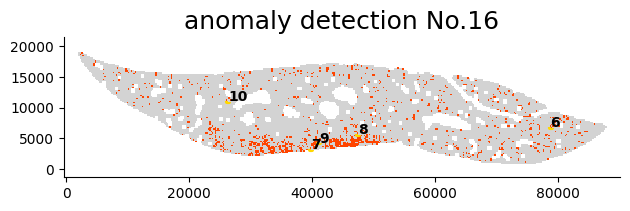

In [508]:
fig_loc = {str(i[1]):i[0] for i in loc_lst_2 if i[2] == 16}
loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection No."+str(i))

0.6581990521327014


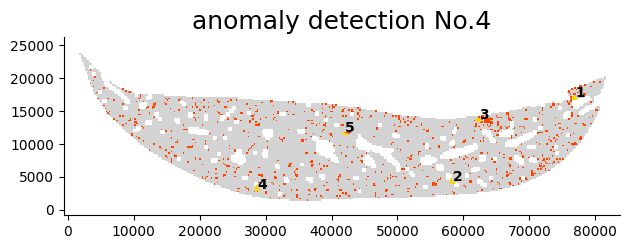

0.614187157261631


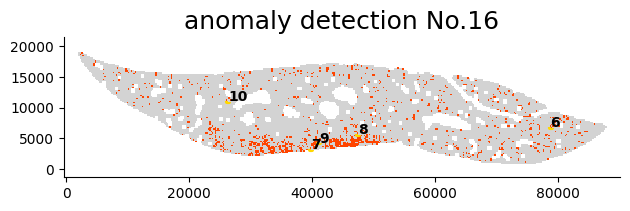

0.7234840591789956


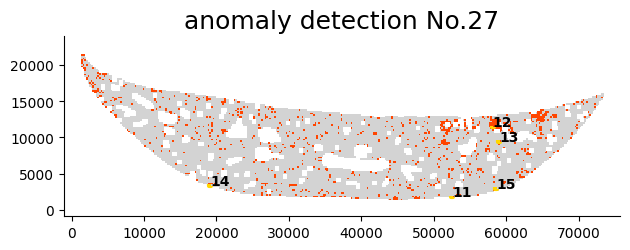

In [510]:
total_inf_lst = []
for i in [4, 16, 27]:
    f_path = "workspace/result_v2/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm.predict(feature_scaled)

    fig_loc = {str(j[1]):j[0] for j in loc_lst_2 if j[2] == i}
    loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection No."+str(i))

In [515]:
def loc_plot(location, jud, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    print(size)
    if size < 1:
        size = 1

    for i in zip(jud, location):
        if i[0] == -1:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=0.3, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="lightgray", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

sample No.4
14231
904
Percentage of abnormal patches : 0.06352329421685053
0.6581990521327014


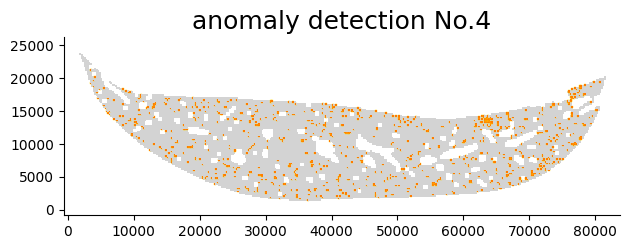

sample No.16
13856
1149
Percentage of abnormal patches : 0.08292436489607391
0.614187157261631


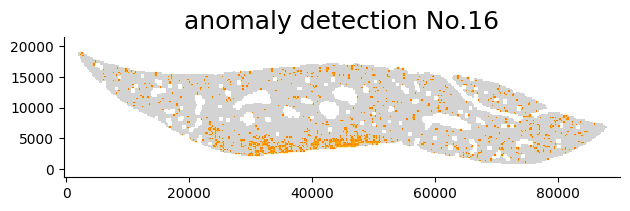

sample No.27
10494
920
Percentage of abnormal patches : 0.08766914427291786
0.7234840591789956


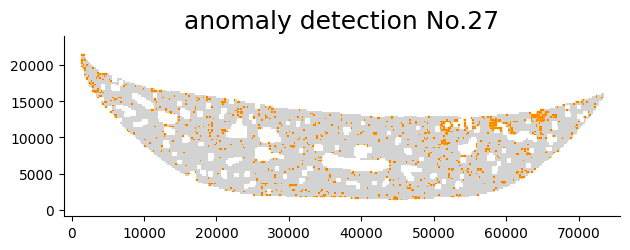

In [513]:
total_inf_lst = []
for i in [4, 16, 27]:
    f_path = "workspace/result_v2/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection No."+str(i))

#### PCA in nomal patches ####

In [17]:
def get_info(sample_id, feature, location, jud):
    inf_lst = []
    max_n = len([i for i in jud if i == -1])
    print("max_n = ", str(max_n))
    n = 0
    ap = inf_lst.append
    for i in zip(jud, feature, location):
        if i[0] == -1:
            ap([sample_id, i[1], i[2], i[0]])
        elif i[0] == 1 and n < max_n:
            ap([sample_id, i[1], i[2], i[0]])
            n = n + 1
        else:
            pass

    return inf_lst

In [18]:
total_inf_lst = []
for i in [4, 16, 27]:
    f_path = "workspace/result_v2/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.4
14231
904
Percentage of abnormal patches : 0.06352329421685053
max_n =  904
sample No.16
13856
1149
Percentage of abnormal patches : 0.08292436489607391
max_n =  1149
sample No.27
10494
920
Percentage of abnormal patches : 0.08766914427291786
max_n =  920


In [ ]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]
bach_dict = {4:"dimgray", 16:"orangered", 27:"mediumblue"}

In [19]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

In [20]:
from sklearn.decomposition import PCA

In [21]:
pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

In [22]:
# 第一主成分と第二主成分でプロットする
def PCAplot_v3(feature, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, pict_sample=6, seed1=2477, seed2=2477, title=""):
    fig, ax = plt.subplots()
    label_lst = []
    ap = label_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    n = 0
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature)), sample)
    random.seed(seed2)
    random.shuffle(ran_sam)
    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if pca_inf[i][0] not in label_lst:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0,
                    label="No."+str(pca_inf[i][0]), zorder=1
                    )
                ap(pca_inf[i][0])

            elif pca_inf[i][0] == 4 and label_lst.count(4) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(4)-1), weight="bold"
                )
                ap_loc([label_lst.count(4)-1, pca_inf[i][1], pca_inf[i][0]])


            elif pca_inf[i][0] == 16 and label_lst.count(16) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(16)-1+pict_sample), weight="bold"
                )
                ap_loc([label_lst.count(16)-1+pict_sample, pca_inf[i][1], pca_inf[i][0]])

            elif pca_inf[i][0] == 27 and label_lst.count(27) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(27)-1+pict_sample*2), weight="bold"
                )
                ap_loc([label_lst.count(27)-1+pict_sample*2, pca_inf[i][1], pca_inf[i][0]])
            
            else:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0, zorder=1
                    )
        else:
            ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color="white", linewidth=1, ec=bach_dict[pca_inf[i][0]], zorder=1
                    )

    ax.set_title(title, fontsize=18)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()
    
    return loc_lst

In [23]:
pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]
bach_dict = {4:"dimgray", 16:"orangered", 27:"mediumblue"}

In [24]:
len(feature_pca)

5946

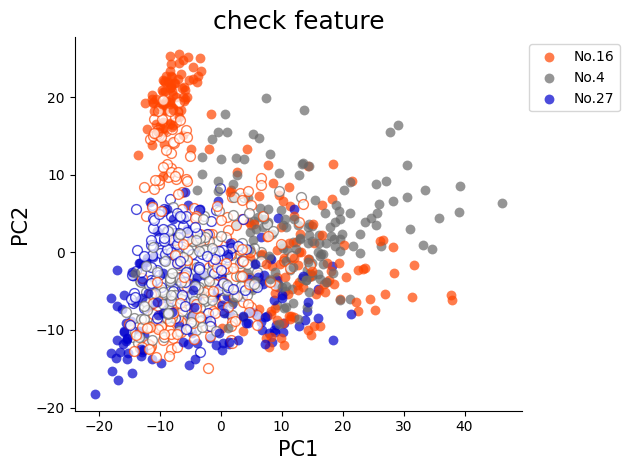

In [27]:
loc_lst_2 = PCAplot_v3(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=1000, pict_sample=0, seed1=14, title="check feature")

In [28]:
# 第一主成分と第二主成分でプロットする
def PCAplot_v3_anomal(feature, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, pict_sample=6, seed1=2477, seed2=2477, title=""):
    fig, ax = plt.subplots()
    label_lst = []
    ap = label_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    n = 0
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature)), sample)
    random.seed(seed2)
    random.shuffle(ran_sam)
    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if pca_inf[i][0] not in label_lst:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0,
                    label="No."+str(pca_inf[i][0]), zorder=1
                    )
                ap(pca_inf[i][0])

            elif pca_inf[i][0] == 4 and label_lst.count(4) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(4)-1), weight="bold"
                )
                ap_loc([label_lst.count(4)-1, pca_inf[i][1], pca_inf[i][0]])


            elif pca_inf[i][0] == 16 and label_lst.count(16) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(16)-1+pict_sample), weight="bold"
                )
                ap_loc([label_lst.count(16)-1+pict_sample, pca_inf[i][1], pca_inf[i][0]])

            elif pca_inf[i][0] == 27 and label_lst.count(27) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(27)-1+pict_sample*2), weight="bold"
                )
                ap_loc([label_lst.count(27)-1+pict_sample*2, pca_inf[i][1], pca_inf[i][0]])
            
            else:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0, zorder=1
                    )
        else:
            pass

    ax.set_title(title, fontsize=18)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()
    
    return loc_lst

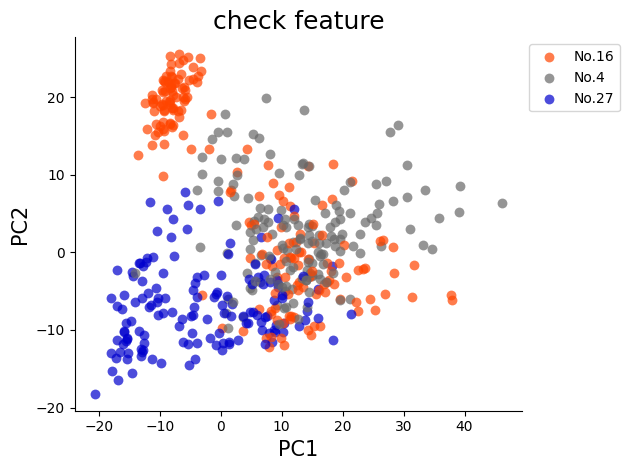

In [29]:
loc_lst_2 = PCAplot_v3_anomal(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=1000, pict_sample=0, seed1=14, title="check feature")

In [ ]:
color="white", linewidth=1, ec=bach_dict[pca_inf[i][0]]

In [30]:
# 第一主成分と第二主成分でプロットする
def PCAplot_v3_nomal(feature, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, pict_sample=6, seed1=2477, seed2=2477, title=""):
    fig, ax = plt.subplots()
    label_lst = []
    ap = label_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    n = 0
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature)), sample)
    random.seed(seed2)
    random.shuffle(ran_sam)
    for i in ran_sam:
        if pca_inf[i][2] == 1:
            if pca_inf[i][0] not in label_lst:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color="white", linewidth=1, ec=bach_dict[pca_inf[i][0]],
                    label="No."+str(pca_inf[i][0]), zorder=1
                    )
                ap(pca_inf[i][0])

            elif pca_inf[i][0] == 4 and label_lst.count(4) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(4)-1), weight="bold"
                )
                ap_loc([label_lst.count(4)-1, pca_inf[i][1], pca_inf[i][0]])


            elif pca_inf[i][0] == 16 and label_lst.count(16) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(16)-1+pict_sample), weight="bold"
                )
                ap_loc([label_lst.count(16)-1+pict_sample, pca_inf[i][1], pca_inf[i][0]])

            elif pca_inf[i][0] == 27 and label_lst.count(27) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(27)-1+pict_sample*2), weight="bold"
                )
                ap_loc([label_lst.count(27)-1+pict_sample*2, pca_inf[i][1], pca_inf[i][0]])
            
            else:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color="white", linewidth=1, ec=bach_dict[pca_inf[i][0]], zorder=1
                    )
        else:
            pass

    ax.set_title(title, fontsize=18)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()
    
    return loc_lst

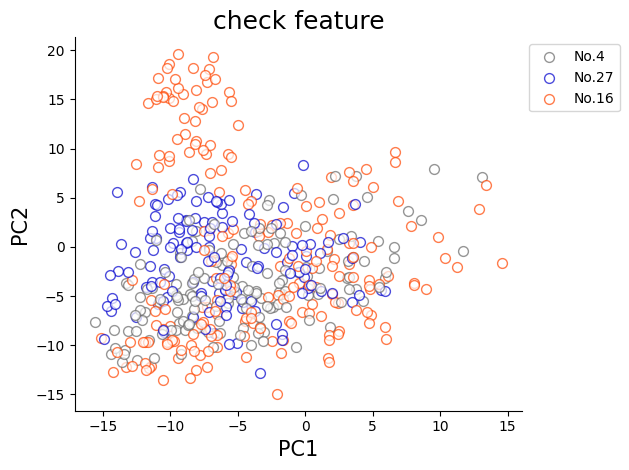

In [31]:
loc_lst_2 = PCAplot_v3_nomal(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=1000, pict_sample=0, seed1=14, title="check feature")

#### ocsvm (patch = 448) ####

In [363]:
def loc_plot(location, jud, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    print(size)
    if size < 1:
        size = 1

    for i in zip(jud, location):
        if i[0] == -1:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="coral", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="indigo", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

In [380]:
l2 = [[0, 0],[448, 448], [448*6, 448*9], [448, 448*5], [448*10, 448*10], [448*10, 448*9], [448*9, 448*9]]
j = [1, 1, 1, 1, 1, -1, 1]

13.769299145299145


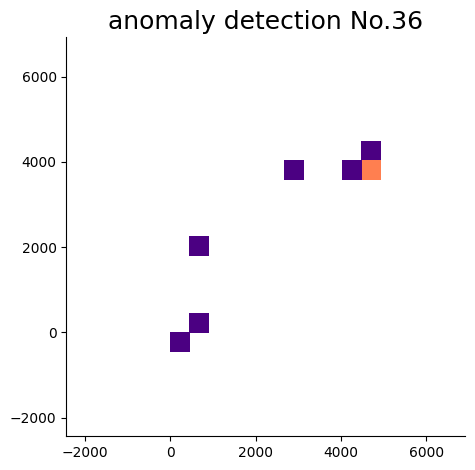

In [385]:
loc_plot(l2, j, ppi=58, size=224, title="anomaly detection No."+str(i))

In [366]:
f_path_1 = "workspace/result_v3/1_layer5.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v3/2_layer5.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v3/3_layer5.npy"
feature_3 = np.load(f_path_3)
f_path_5 = "workspace/result_v3/5_layer5.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v3/6_layer5.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v3/7_layer5.npy"
feature_7 = np.load(f_path_7)
f_path_9 = "workspace/result_v3/9_layer5.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v3/10_layer5.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v3/11_layer5.npy"
feature_11 = np.load(f_path_11)

In [367]:
f_conc = list(feature_1) + list(feature_2) + list(feature_3)+ list(feature_5)+ list(feature_6)+ list(feature_7)+ list(feature_9)+ list(feature_10)+ list(feature_11)

In [368]:
#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

In [388]:
total_p = len(feature_scaled)
nu = 0.04 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_448 = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [389]:
total_p = len(feature_scaled)
nu = 0.04 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_448 = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

sample No.4
4070
414
4484
Percentage of abnormal patches : 0.10171990171990172
1.890595575723199


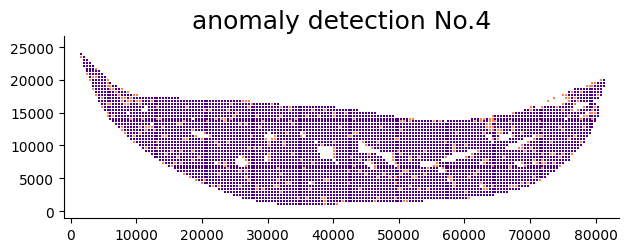

sample No.8
3721
325
4046
Percentage of abnormal patches : 0.08734211233539371
1.9108274412382953


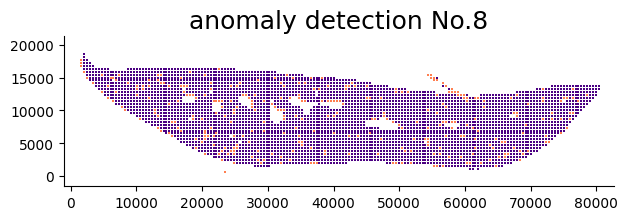

sample No.12
3521
352
3873
Percentage of abnormal patches : 0.09997159897756319
2.2762030503073074


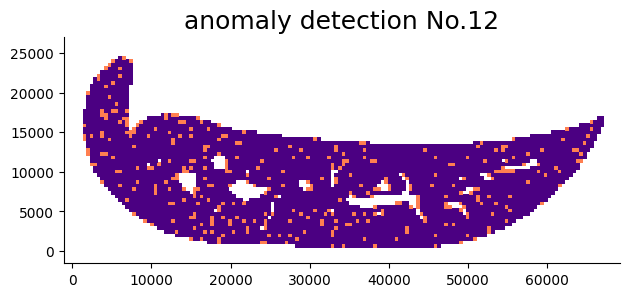

sample No.13
3370
291
3661
Percentage of abnormal patches : 0.08635014836795252
1.9633536226192814


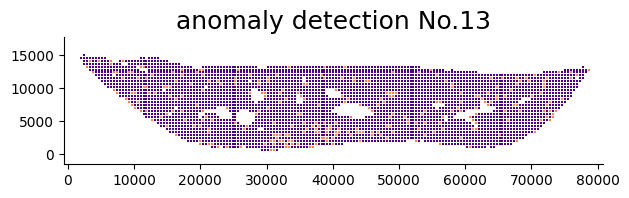

sample No.14
4023
399
4422
Percentage of abnormal patches : 0.09917971662938106
1.8513904832438437


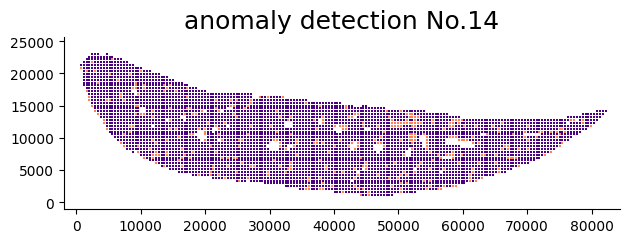

sample No.15
3664
351
4015
Percentage of abnormal patches : 0.09579694323144104
1.9314970059880239


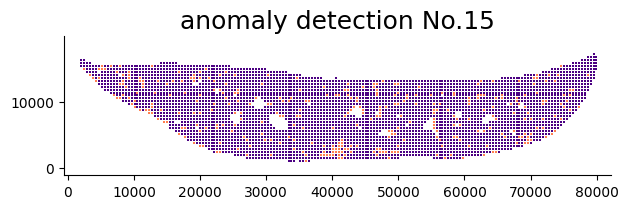

sample No.16
3978
423
4401
Percentage of abnormal patches : 0.10633484162895927
1.7688590129134973


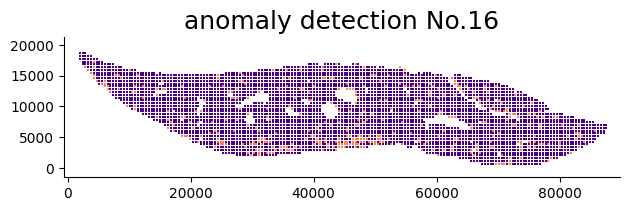

sample No.17
3716
247
3963
Percentage of abnormal patches : 0.06646932185145317
2.192361324270993


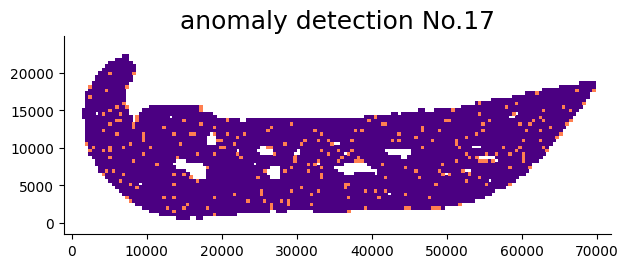

sample No.18
2894
219
3113
Percentage of abnormal patches : 0.07567380787836904
2.481846612062547


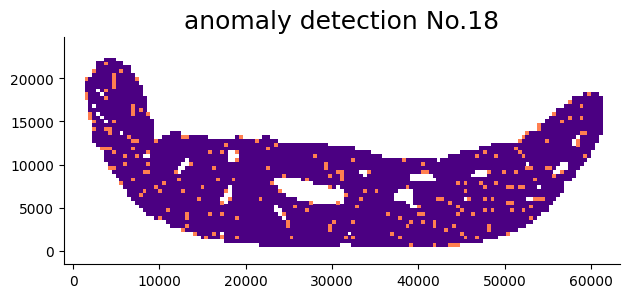

sample No.19
3587
252
3839
Percentage of abnormal patches : 0.07025369389461945
2.0075005019072476


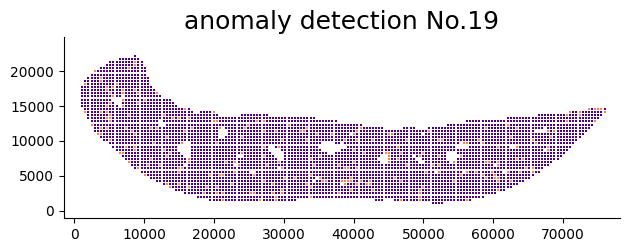

sample No.21
2544
169
2713
Percentage of abnormal patches : 0.06643081761006289
2.152714747039828


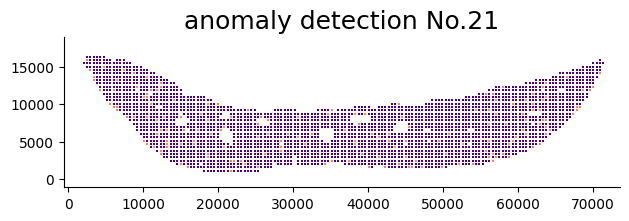

sample No.22
3156
209
3365
Percentage of abnormal patches : 0.06622306717363752
2.2617869260348336


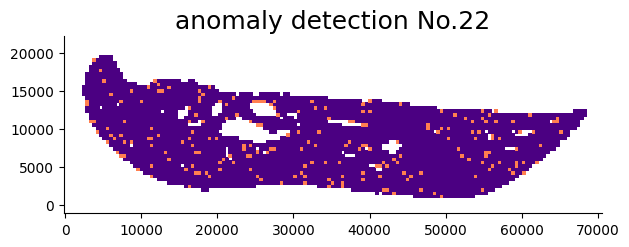

sample No.23
3676
250
3926
Percentage of abnormal patches : 0.06800870511425462
1.942000388424937


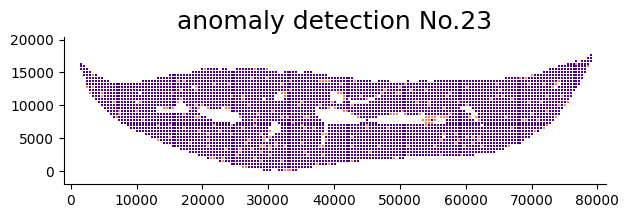

sample No.24
3236
221
3457
Percentage of abnormal patches : 0.06829419035846725
2.192361324270993


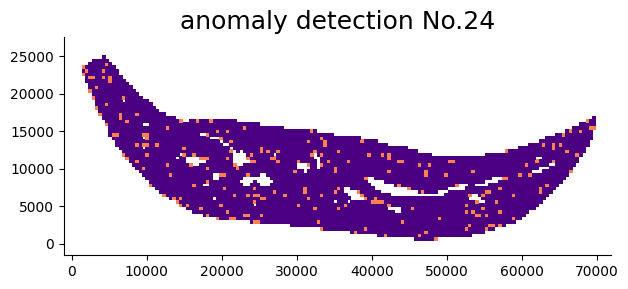

sample No.25
3566
235
3801
Percentage of abnormal patches : 0.06590016825574874
2.152714747039828


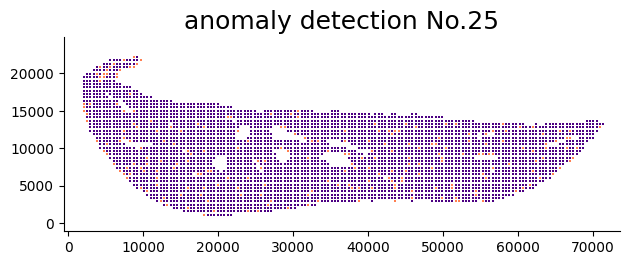

sample No.26
3602
218
3820
Percentage of abnormal patches : 0.06052193225985564
2.178984528219656


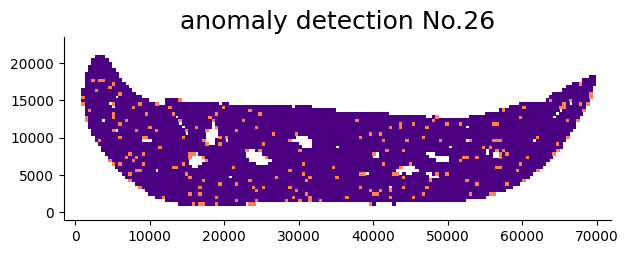

sample No.27
3237
290
3527
Percentage of abnormal patches : 0.08958912573370405
2.077573239143985


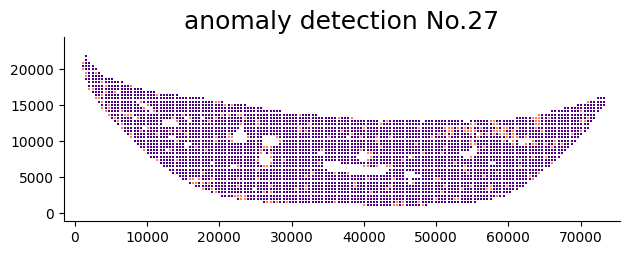

sample No.28
3693
281
3974
Percentage of abnormal patches : 0.07608989981045221
2.1144766335377456


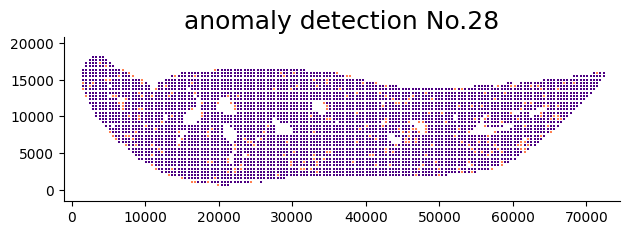

sample No.29
4036
276
4312
Percentage of abnormal patches : 0.06838453914767097
2.0419358791096593


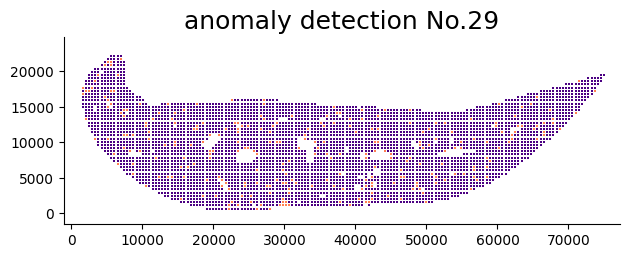

sample No.30
3945
250
4195
Percentage of abnormal patches : 0.06337135614702155
1.942000388424937


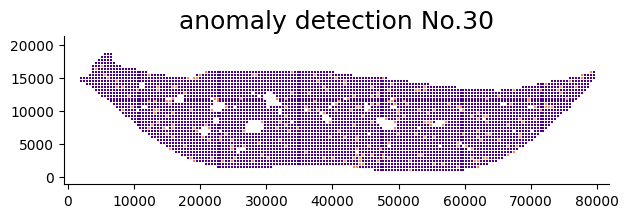

sample No.31
4426
276
4702
Percentage of abnormal patches : 0.06235878897424311
1.9851816557474686


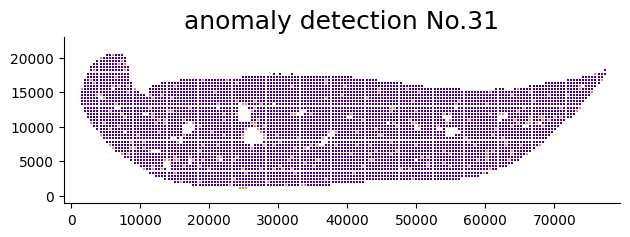

sample No.32
4024
251
4275
Percentage of abnormal patches : 0.062375745526838965
2.077573239143985


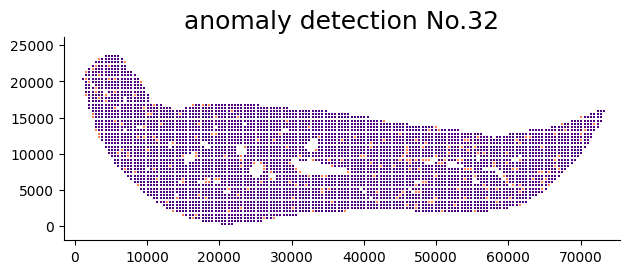

sample No.33
3699
279
3978
Percentage of abnormal patches : 0.07542579075425791
2.0419358791096593


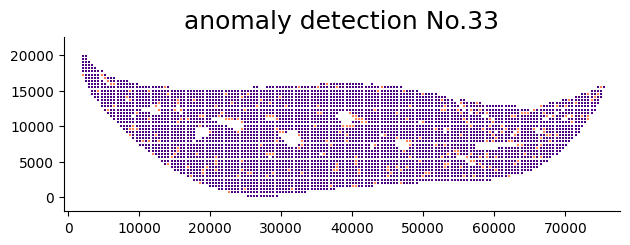

sample No.34
3723
271
3994
Percentage of abnormal patches : 0.07279076013967231
2.152714747039828


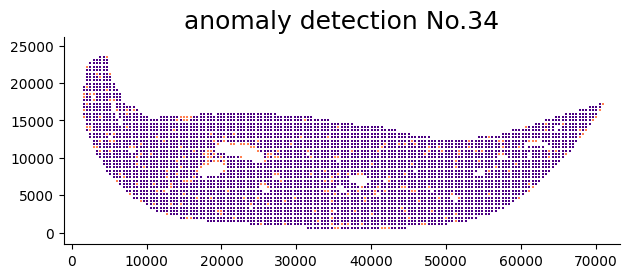

sample No.35
4594
373
4967
Percentage of abnormal patches : 0.08119286025250326
2.0188491823137493


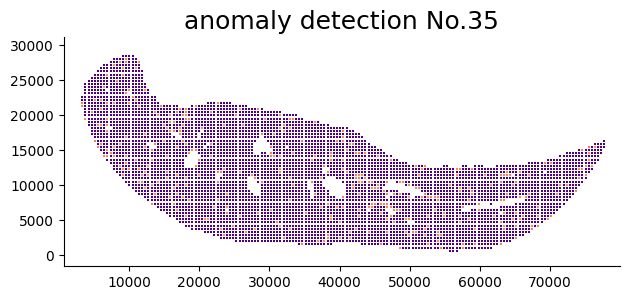

sample No.36
4245
215
4460
Percentage of abnormal patches : 0.050647820965842166
2.0419358791096593


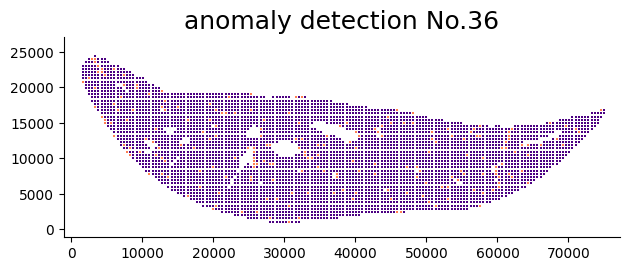

In [390]:
for i in [4, 8, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]:
    f_path = "workspace/result_v3/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v3/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_448.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print(len(location))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    loc_plot(location, jud, ppi=72, size=224, title="anomaly detection No."+str(i))

sample No.4
4083
401
4484
Percentage of abnormal patches : 0.0982120989468528
1.522979769332577


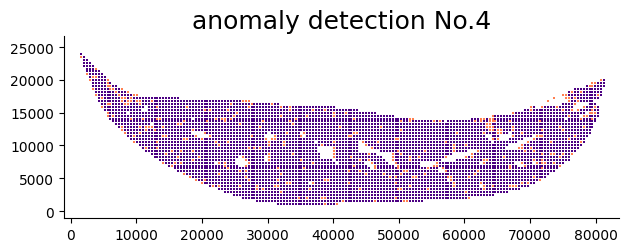

sample No.8
3733
313
4046
Percentage of abnormal patches : 0.08384677203321725
1.5392776609975158


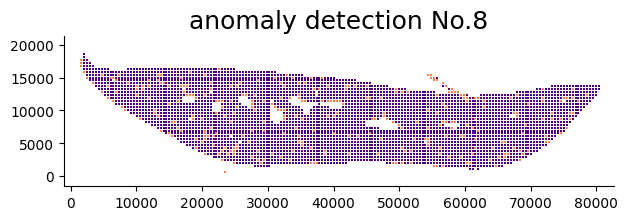

sample No.12
3531
342
3873
Percentage of abnormal patches : 0.09685641461342395
1.8336080127475531


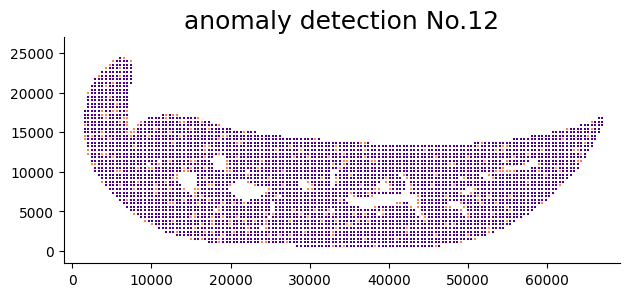

sample No.13
3383
278
3661
Percentage of abnormal patches : 0.08217558380135974
1.5815904182210878


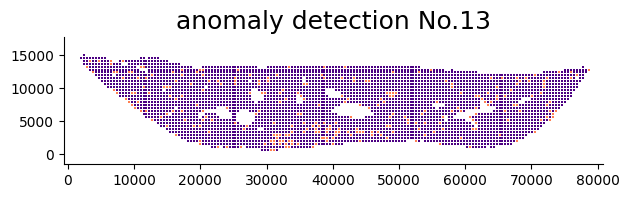

sample No.14
4042
380
4422
Percentage of abnormal patches : 0.09401286491835725
1.491397889279763


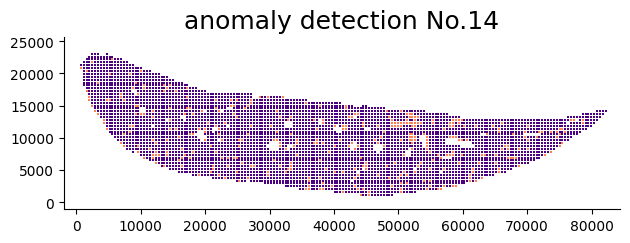

sample No.15
3690
325
4015
Percentage of abnormal patches : 0.08807588075880758
1.555928143712575


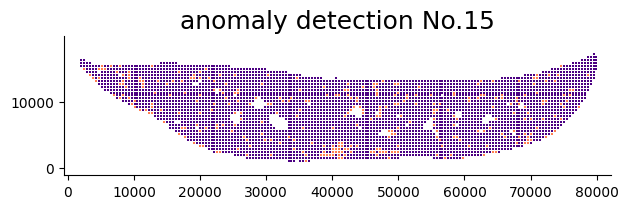

sample No.16
4001
400
4401
Percentage of abnormal patches : 0.09997500624843789
1.4249142048469838


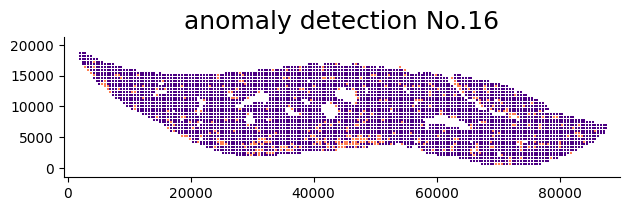

sample No.17
3730
233
3963
Percentage of abnormal patches : 0.06246648793565684
1.7660688445516335


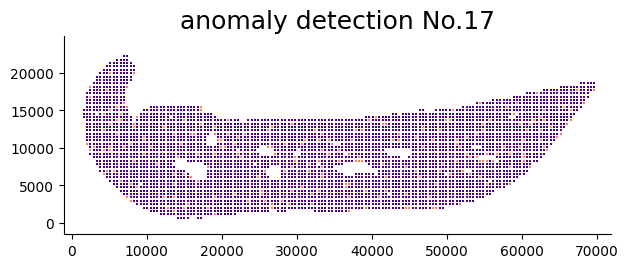

sample No.18
2905
208
3113
Percentage of abnormal patches : 0.07160068846815834
1.9992653263837181


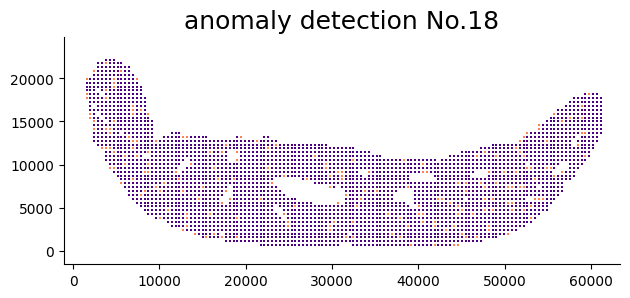

sample No.19
3600
239
3839
Percentage of abnormal patches : 0.06638888888888889
1.6171531820919496


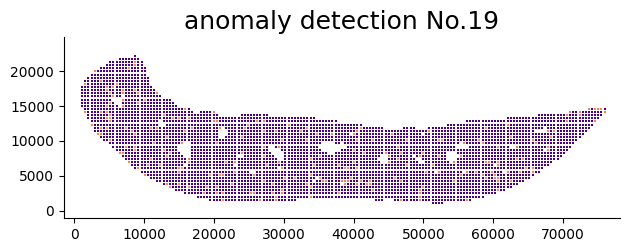

sample No.21
2553
160
2713
Percentage of abnormal patches : 0.06267136701919311
1.7341313240043057


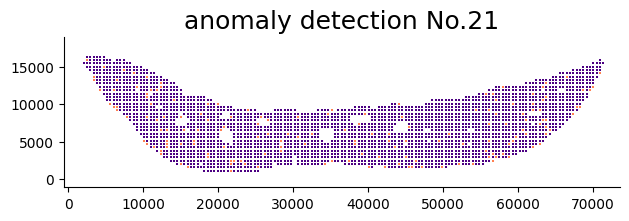

sample No.22
3164
201
3365
Percentage of abnormal patches : 0.06352718078381796
1.8219950237502829


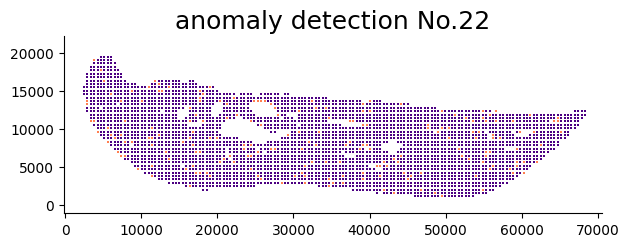

sample No.23
3691
235
3926
Percentage of abnormal patches : 0.06366838255215389
1.564389201786755


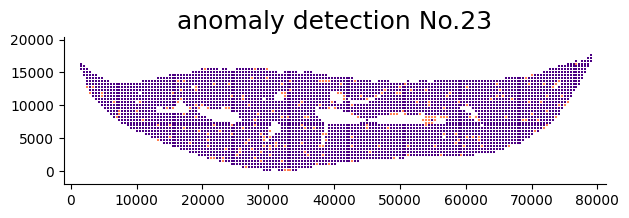

sample No.24
3249
208
3457
Percentage of abnormal patches : 0.06401969836872884
1.7660688445516335


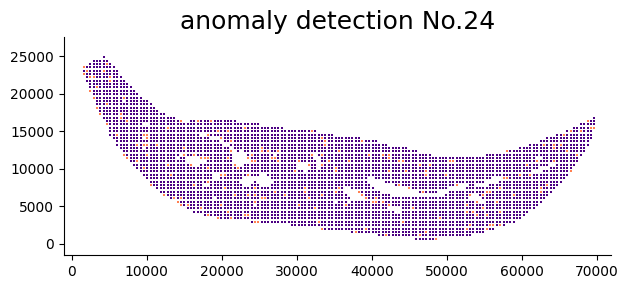

sample No.25
3576
225
3801
Percentage of abnormal patches : 0.06291946308724833
1.7341313240043057


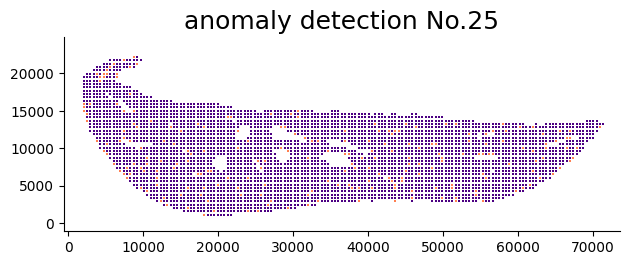

sample No.26
3617
203
3820
Percentage of abnormal patches : 0.05612385955211501
1.755293092176945


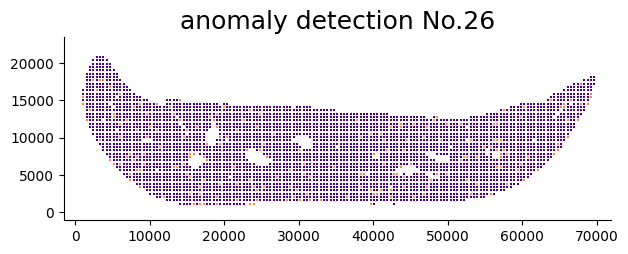

sample No.27
3243
284
3527
Percentage of abnormal patches : 0.08757323465926611
1.673600664865988


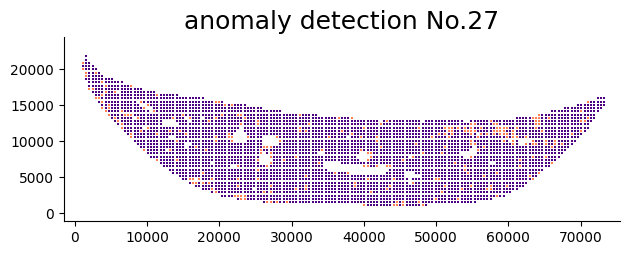

sample No.28
3704
270
3974
Percentage of abnormal patches : 0.07289416846652268
1.7033283992387398


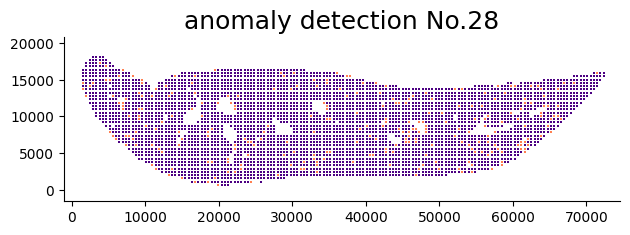

sample No.29
4049
263
4312
Percentage of abnormal patches : 0.06495430970610028
1.6448927915050031


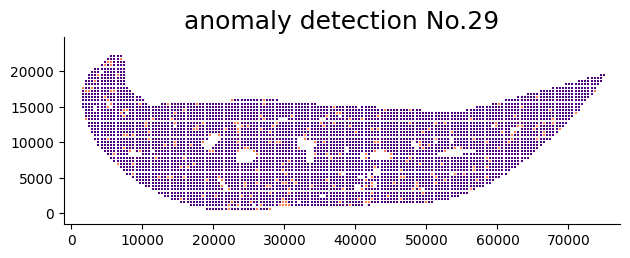

sample No.30
3954
241
4195
Percentage of abnormal patches : 0.060950935761254425
1.564389201786755


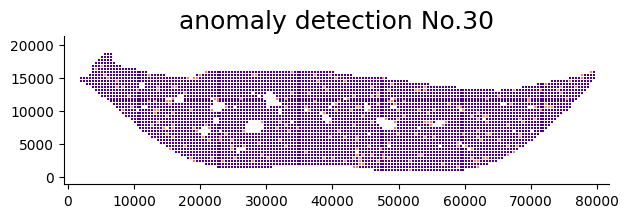

sample No.31
4434
268
4702
Percentage of abnormal patches : 0.060442038791159225
1.5991741115743499


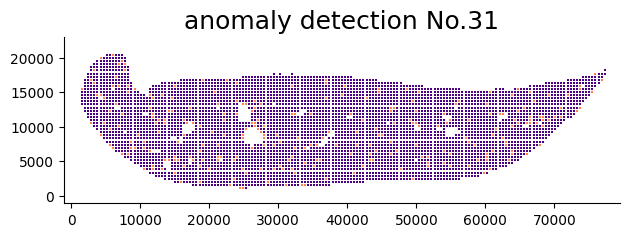

sample No.32
4033
242
4275
Percentage of abnormal patches : 0.0600049590875279
1.673600664865988


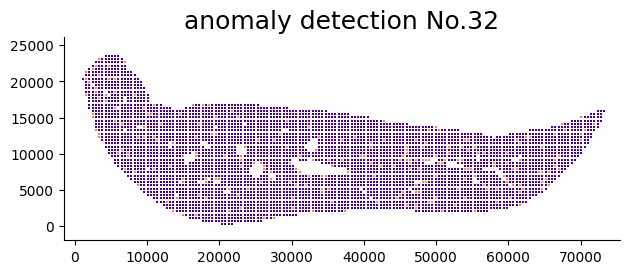

sample No.33
3706
272
3978
Percentage of abnormal patches : 0.07339449541284404
1.6448927915050031


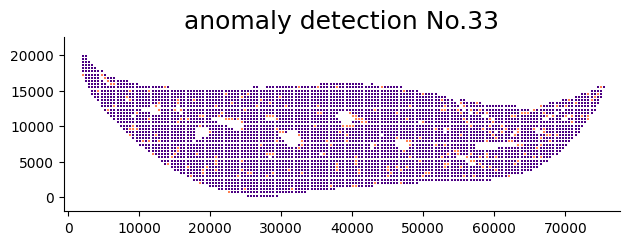

sample No.34
3736
258
3994
Percentage of abnormal patches : 0.0690578158458244
1.7341313240043057


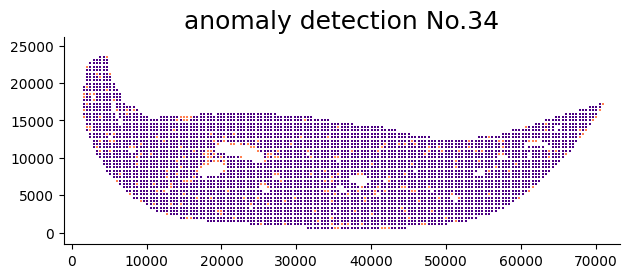

sample No.35
4615
352
4967
Percentage of abnormal patches : 0.07627302275189599
1.6262951746416314


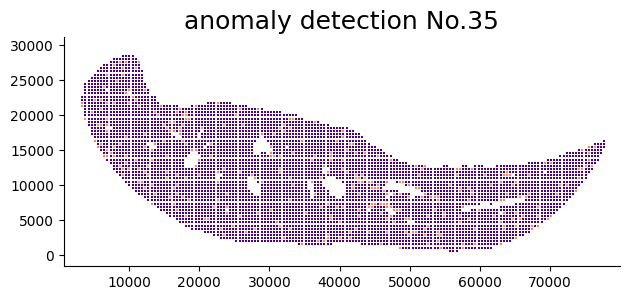

sample No.36
4308
152
4460
Percentage of abnormal patches : 0.035283194057567316
1.6448927915050031


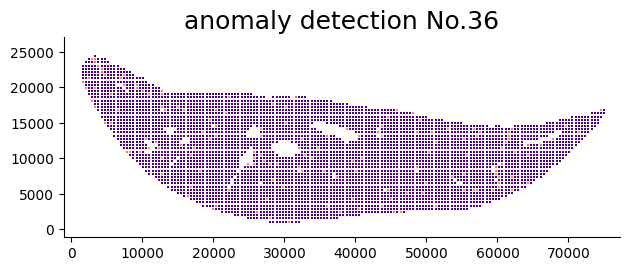

In [387]:
for i in [4, 8, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]:
    f_path = "workspace/result_v3/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v3/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_448.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print(len(location))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    loc_plot(location, jud, ppi=72, size=224, title="anomaly detection No."+str(i))

#### ocsvm 224 get_mask ####

In [44]:
def loc_plot(location, jud, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    print(size)
    if size < 1:
        size = 1

    for i in zip(jud, location):
        if i[0] == -1:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="coral", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="indigo", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

layer1
130123
sample No.4
15734
2048
17782
Percentage of abnormal patches : 0.13016397610270752
0.6529998119240172


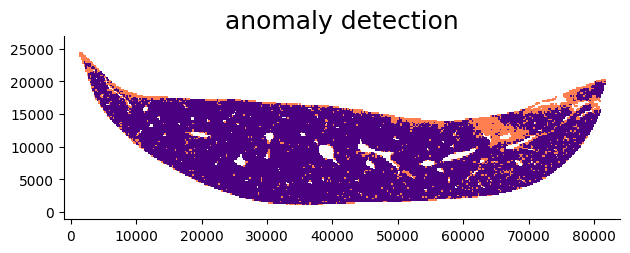

sample No.8
14579
1713
16292
Percentage of abnormal patches : 0.11749777076617052
0.6581990521327014


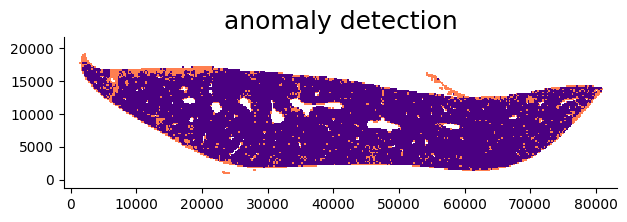

sample No.12
13576
1866
15442
Percentage of abnormal patches : 0.13744843842074247
0.787837531200363


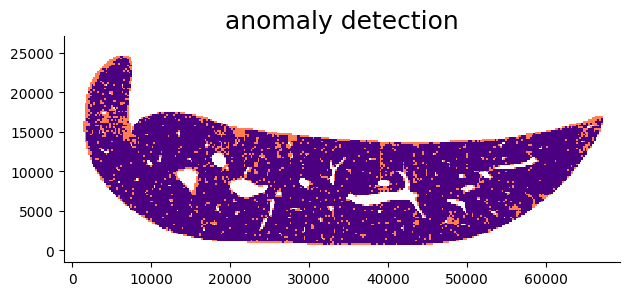

sample No.13
12114
2505
14619
Percentage of abnormal patches : 0.20678553739474986
0.6835991336877338


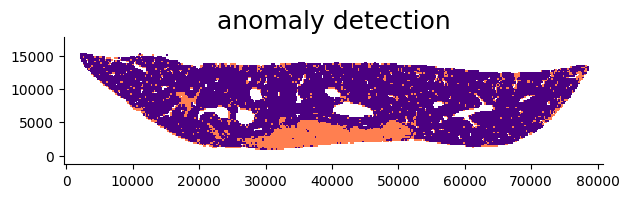

sample No.14
15342
2309
17651
Percentage of abnormal patches : 0.1505018902359536
0.6411819021237304


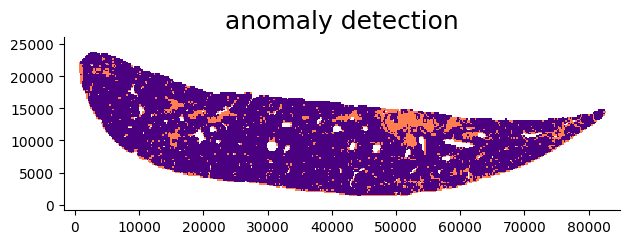

sample No.15
13613
2454
16067
Percentage of abnormal patches : 0.1802688606479101
0.6670509125840538


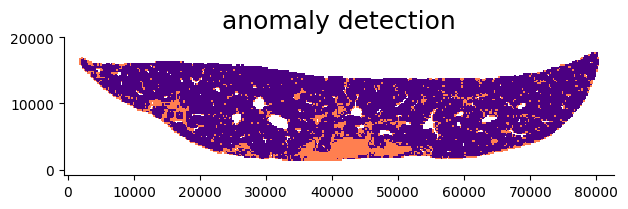

sample No.16
13936
3711
17647
Percentage of abnormal patches : 0.26628874856486795
0.6096575943810361


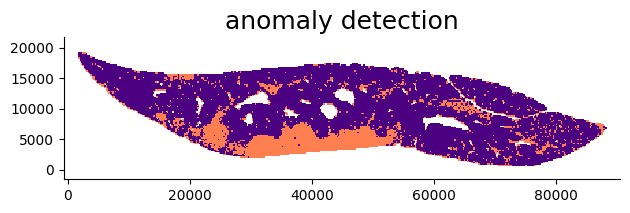

sample No.17
13889
1762
15651
Percentage of abnormal patches : 0.12686298509611924
0.7589071038251366


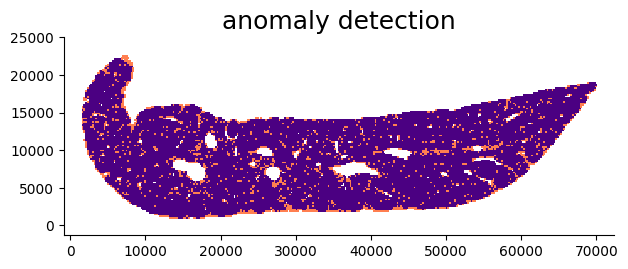

sample No.18
11056
1294
12350
Percentage of abnormal patches : 0.11704052098408105
0.849938800489596


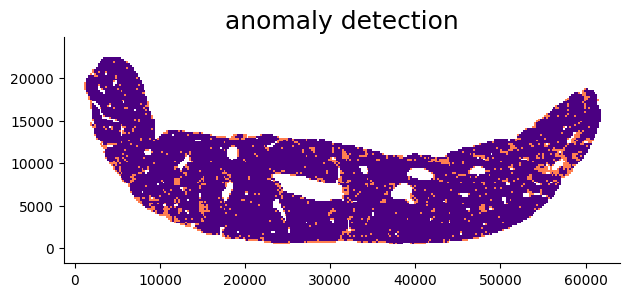

sample No.19
13820
1411
15231
Percentage of abnormal patches : 0.10209840810419682
0.6892991860234267


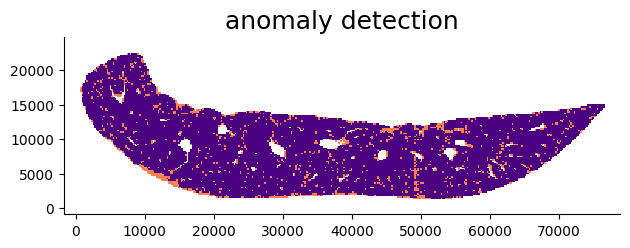

sample No.21
9586
1134
10720
Percentage of abnormal patches : 0.1182975172126017
0.7497300798963507


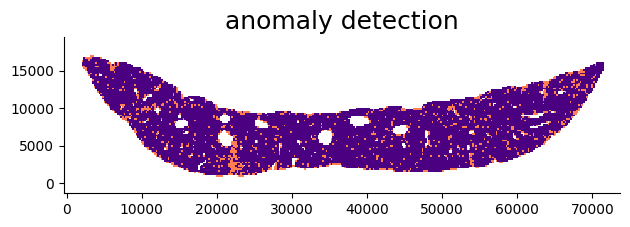

sample No.22
12255
1081
13336
Percentage of abnormal patches : 0.08820889432884536
0.7779520501904549


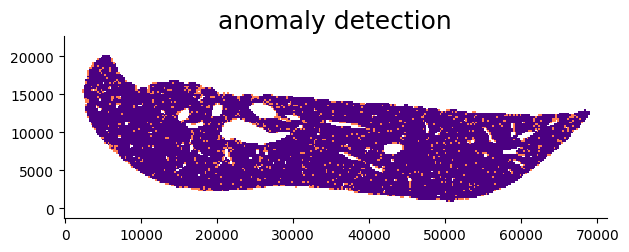

sample No.23
14335
1347
15682
Percentage of abnormal patches : 0.09396581792814789
0.6688499325756116


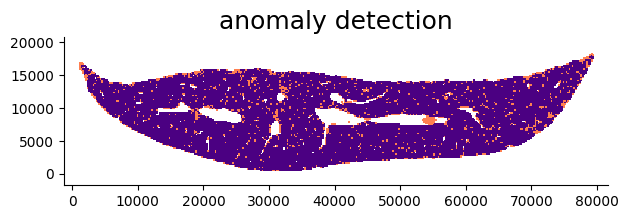

sample No.24
11540
2117
13657
Percentage of abnormal patches : 0.18344887348353553
0.7542906799913099


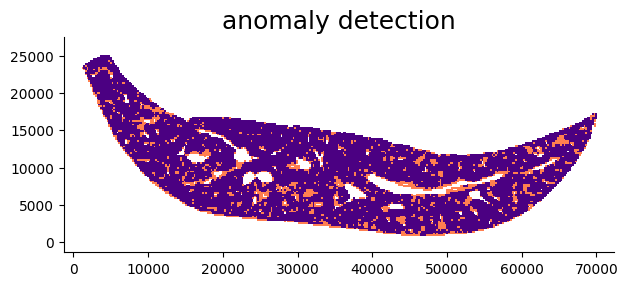

sample No.25
13587
1496
15083
Percentage of abnormal patches : 0.11010524766320748
0.7452242970594548


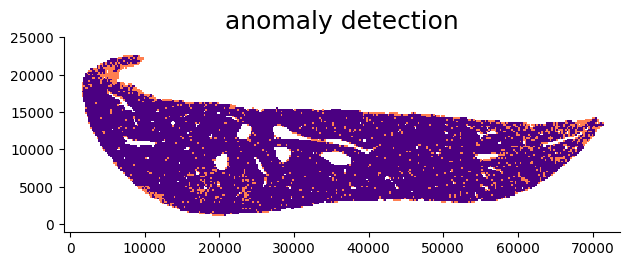

sample No.26
12889
2367
15256
Percentage of abnormal patches : 0.1836449685778571
0.7565918500762694


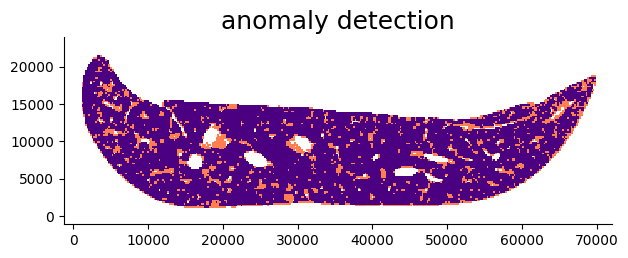

sample No.27
11390
2510
13900
Percentage of abnormal patches : 0.22036874451273047
0.7172071885973972


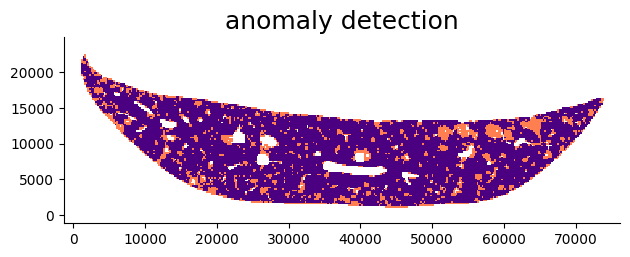

sample No.28
13568
2204
15772
Percentage of abnormal patches : 0.16244103773584906
0.7277300356319429


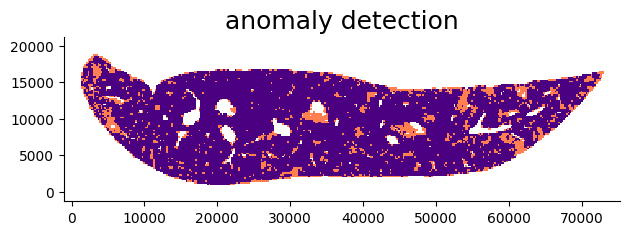

sample No.29
14687
2487
17174
Percentage of abnormal patches : 0.16933342411656568
0.7049746192893401


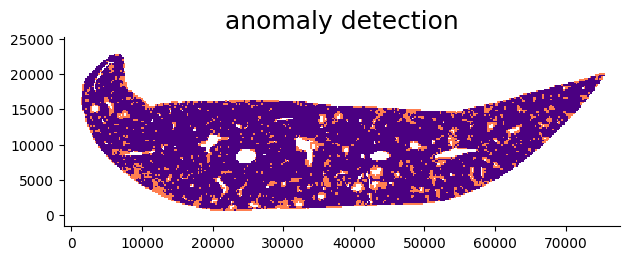

sample No.30
13830
2704
16534
Percentage of abnormal patches : 0.1955169920462762
0.6688499325756116


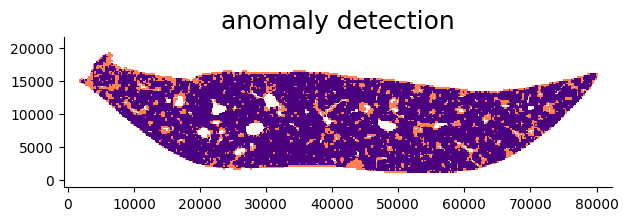

sample No.31
16105
2650
18755
Percentage of abnormal patches : 0.16454517230673704
0.6873886359136804


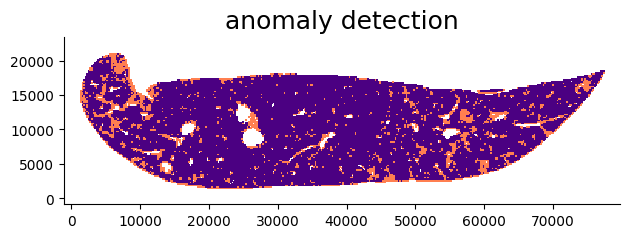

sample No.32
14180
2736
16916
Percentage of abnormal patches : 0.1929478138222849
0.7213795969249948


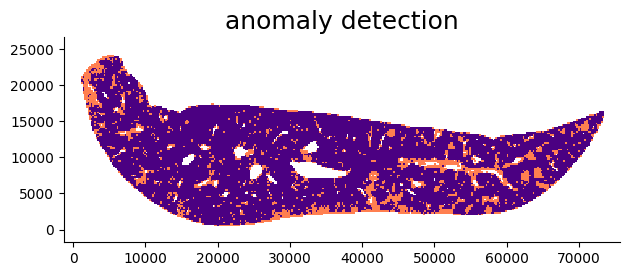

sample No.33
14076
1836
15912
Percentage of abnormal patches : 0.13043478260869565
0.7069843209122378


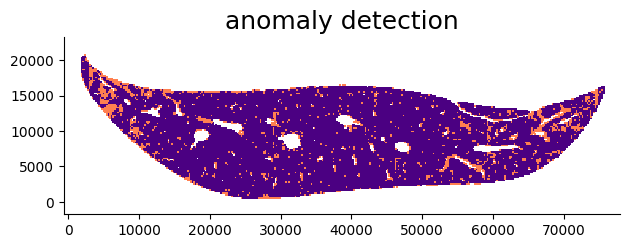

sample No.34
13755
2201
15956
Percentage of abnormal patches : 0.16001454016721192
0.747470398277718


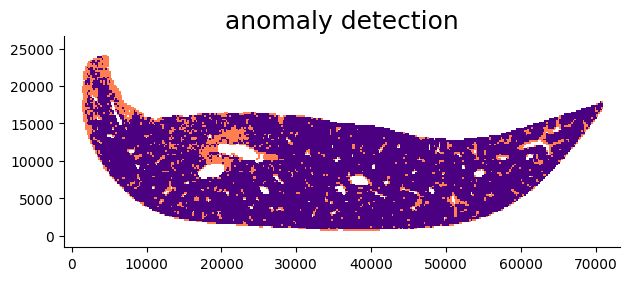

sample No.35
17125
2663
19788
Percentage of abnormal patches : 0.1555036496350365
0.6970487853844609


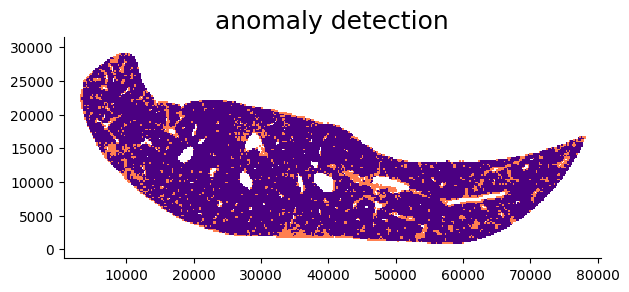

sample No.36
15087
2665
17752
Percentage of abnormal patches : 0.17664214224166502
0.7049746192893401


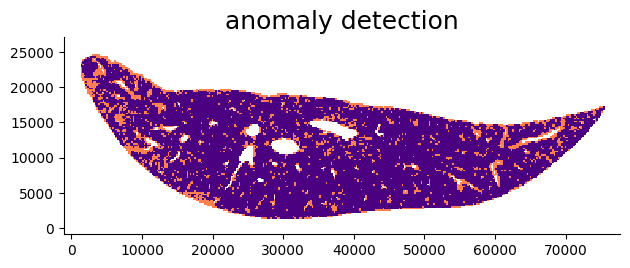

layer2
130123
sample No.4
15869
1913
17782
Percentage of abnormal patches : 0.12054949902325288
0.6529998119240172


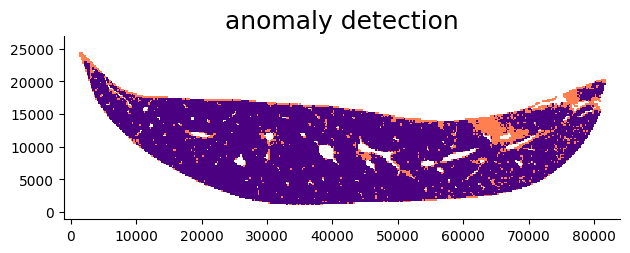

sample No.8
15074
1218
16292
Percentage of abnormal patches : 0.08080137985936049
0.6581990521327014


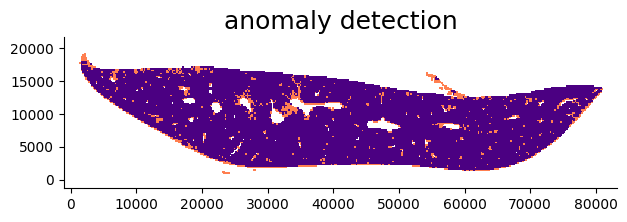

sample No.12
13777
1665
15442
Percentage of abnormal patches : 0.12085359657400015
0.787837531200363


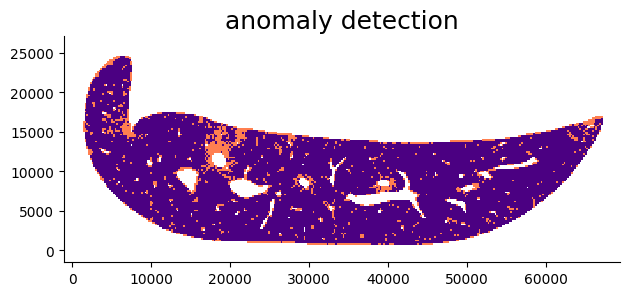

sample No.13
12119
2500
14619
Percentage of abnormal patches : 0.20628764749566797
0.6835991336877338


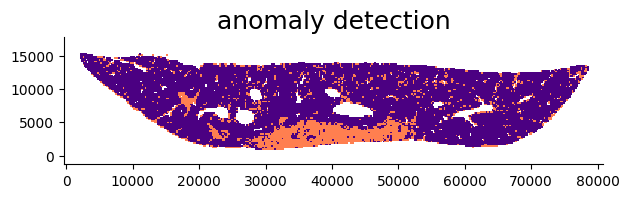

sample No.14
15416
2235
17651
Percentage of abnormal patches : 0.14497924234561493
0.6411819021237304


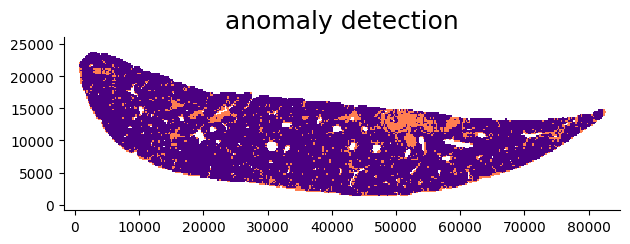

sample No.15
13485
2582
16067
Percentage of abnormal patches : 0.19147200593251762
0.6670509125840538


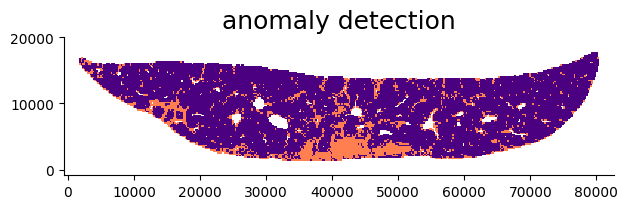

sample No.16
14495
3152
17647
Percentage of abnormal patches : 0.21745429458433943
0.6096575943810361


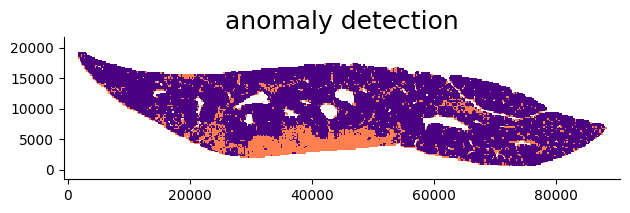

sample No.17
13561
2090
15651
Percentage of abnormal patches : 0.15411842784455423
0.7589071038251366


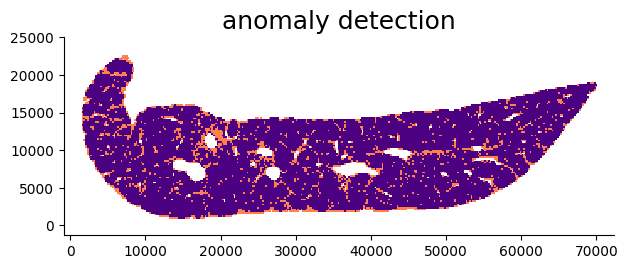

sample No.18
11112
1238
12350
Percentage of abnormal patches : 0.11141108711303095
0.849938800489596


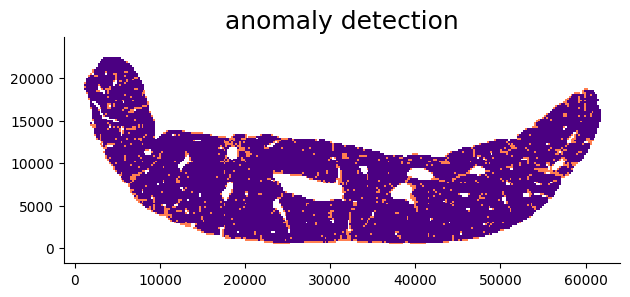

sample No.19
13751
1480
15231
Percentage of abnormal patches : 0.10762853610646499
0.6892991860234267


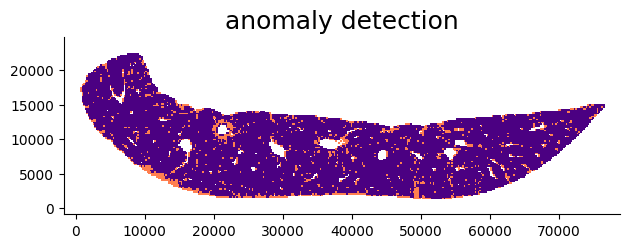

sample No.21
9577
1143
10720
Percentage of abnormal patches : 0.1193484389683617
0.7497300798963507


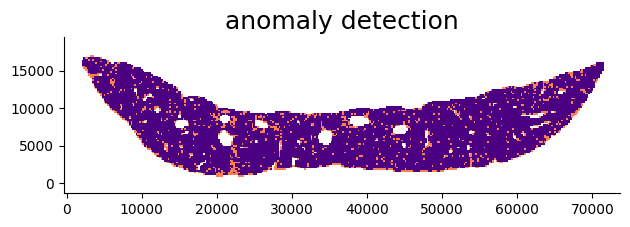

sample No.22
12141
1195
13336
Percentage of abnormal patches : 0.09842681821925706
0.7779520501904549


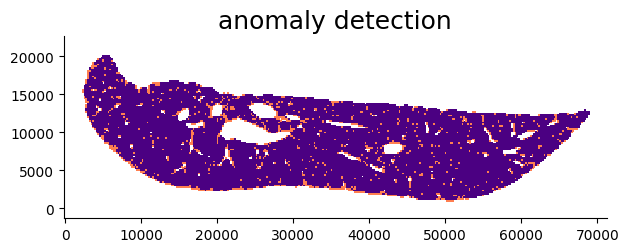

sample No.23
14206
1476
15682
Percentage of abnormal patches : 0.10389976066450796
0.6688499325756116


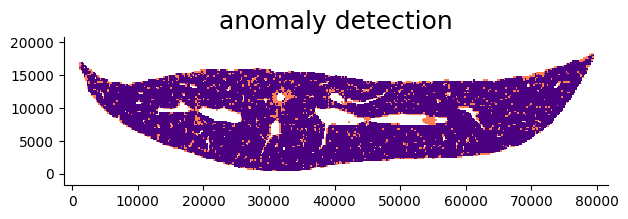

sample No.24
11477
2180
13657
Percentage of abnormal patches : 0.1899451076065174
0.7542906799913099


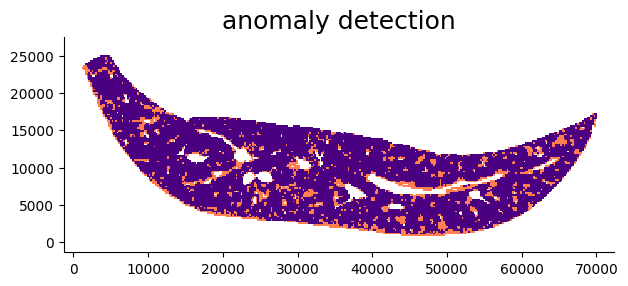

sample No.25
13494
1589
15083
Percentage of abnormal patches : 0.11775603972135765
0.7452242970594548


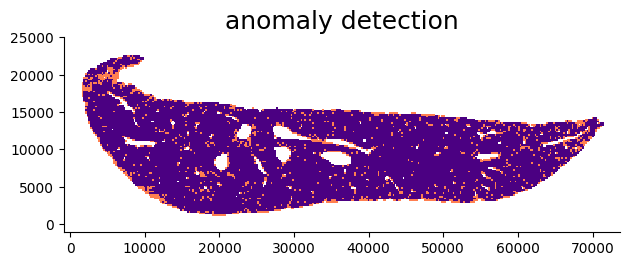

sample No.26
12895
2361
15256
Percentage of abnormal patches : 0.1830942225668864
0.7565918500762694


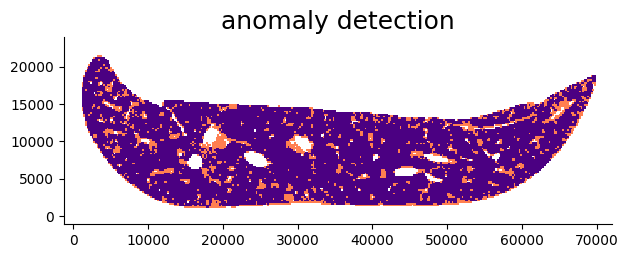

sample No.27
11232
2668
13900
Percentage of abnormal patches : 0.23753561253561253
0.7172071885973972


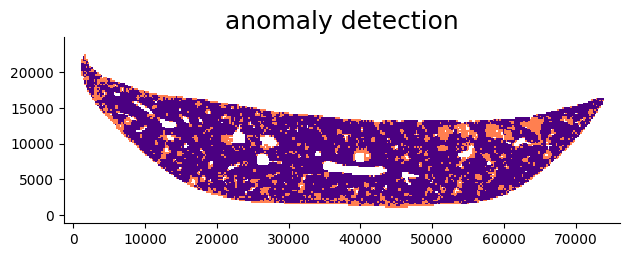

sample No.28
13560
2212
15772
Percentage of abnormal patches : 0.1631268436578171
0.7277300356319429


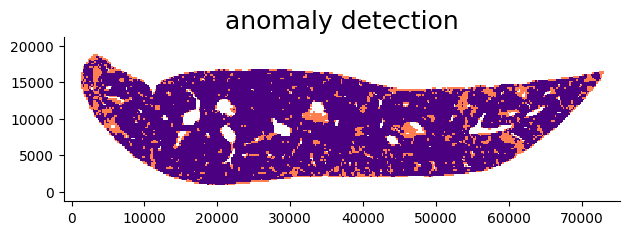

sample No.29
14863
2311
17174
Percentage of abnormal patches : 0.1554867792504878
0.7049746192893401


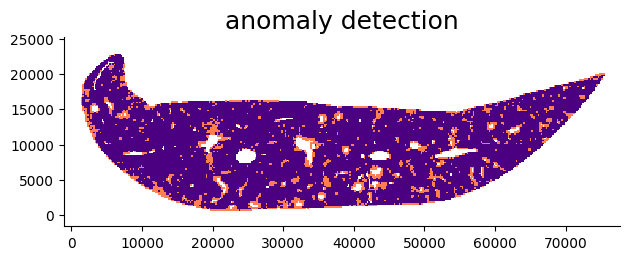

sample No.30
14012
2522
16534
Percentage of abnormal patches : 0.17998858121610048
0.6688499325756116


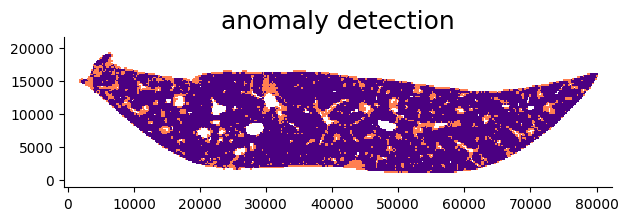

sample No.31
16351
2404
18755
Percentage of abnormal patches : 0.14702464681059263
0.6873886359136804


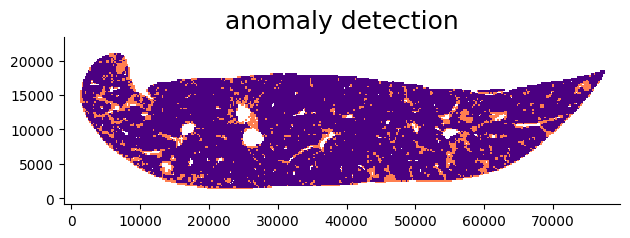

sample No.32
14371
2545
16916
Percentage of abnormal patches : 0.17709275624521606
0.7213795969249948


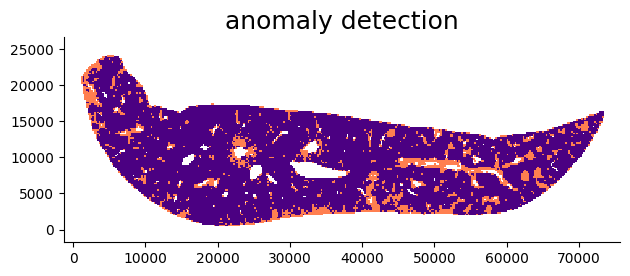

sample No.33
14236
1676
15912
Percentage of abnormal patches : 0.11772969935375105
0.7069843209122378


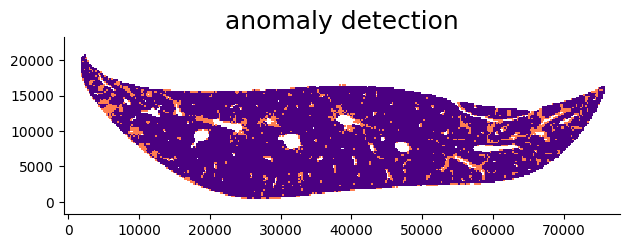

sample No.34
13874
2082
15956
Percentage of abnormal patches : 0.15006486954014703
0.747470398277718


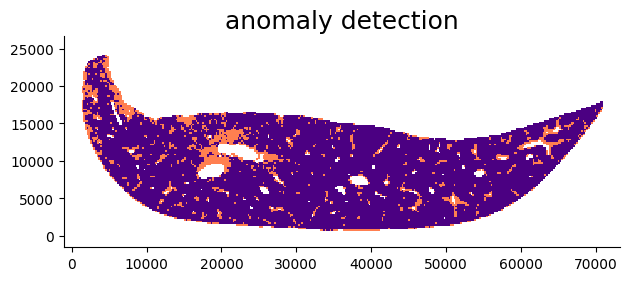

sample No.35
17132
2656
19788
Percentage of abnormal patches : 0.155031519962643
0.6970487853844609


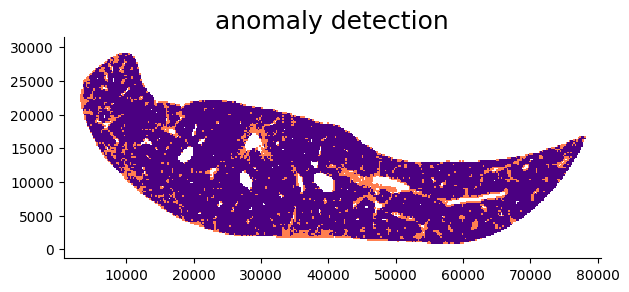

sample No.36
15495
2257
17752
Percentage of abnormal patches : 0.14565989028718943
0.7049746192893401


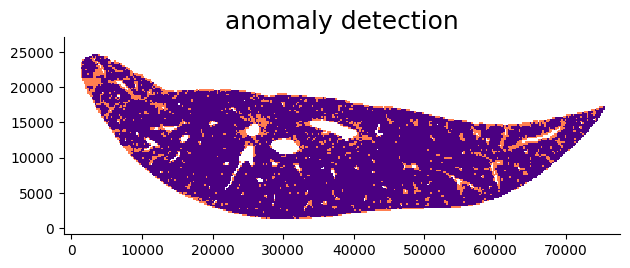

layer3
130123
sample No.4
15851
1931
17782
Percentage of abnormal patches : 0.12182196706832377
0.6529998119240172


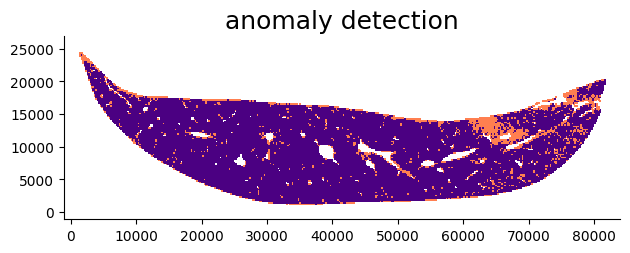

sample No.8
15031
1261
16292
Percentage of abnormal patches : 0.08389328720644003
0.6581990521327014


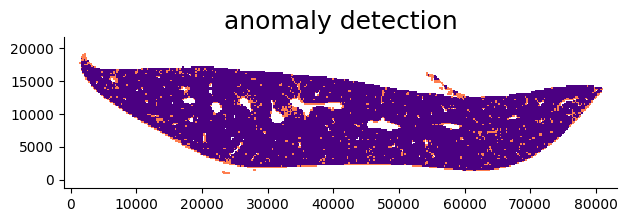

sample No.12
13864
1578
15442
Percentage of abnormal patches : 0.1138199653779573
0.787837531200363


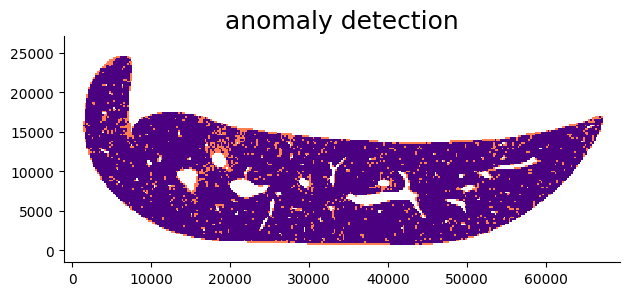

sample No.13
12418
2201
14619
Percentage of abnormal patches : 0.17724271219197937
0.6835991336877338


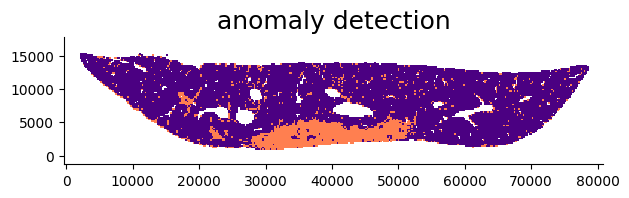

sample No.14
15470
2181
17651
Percentage of abnormal patches : 0.1409825468648998
0.6411819021237304


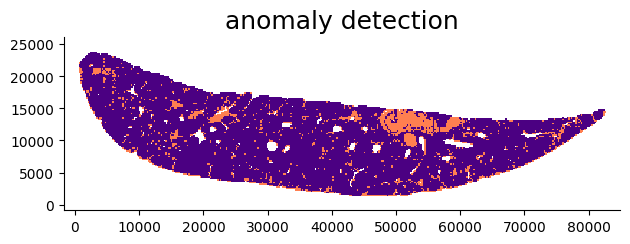

sample No.15
13611
2456
16067
Percentage of abnormal patches : 0.18044228932481082
0.6670509125840538


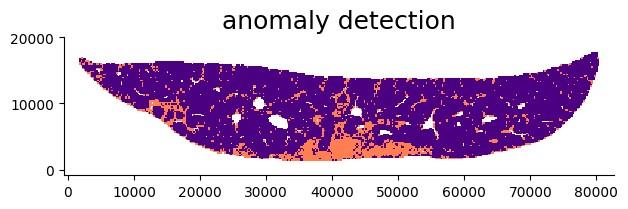

sample No.16
14612
3035
17647
Percentage of abnormal patches : 0.20770599507254311
0.6096575943810361


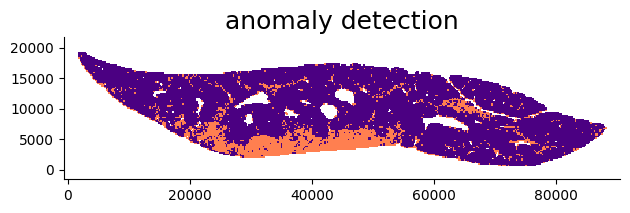

sample No.17
13360
2291
15651
Percentage of abnormal patches : 0.1714820359281437
0.7589071038251366


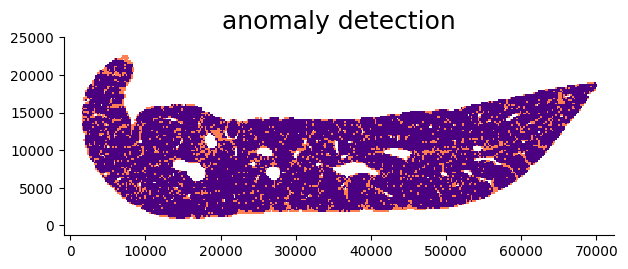

sample No.18
11041
1309
12350
Percentage of abnormal patches : 0.11855810162122996
0.849938800489596


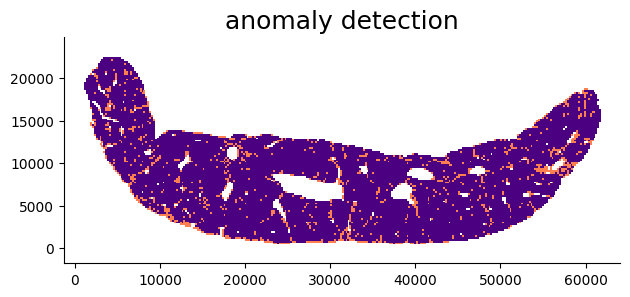

sample No.19
13608
1623
15231
Percentage of abnormal patches : 0.11926807760141094
0.6892991860234267


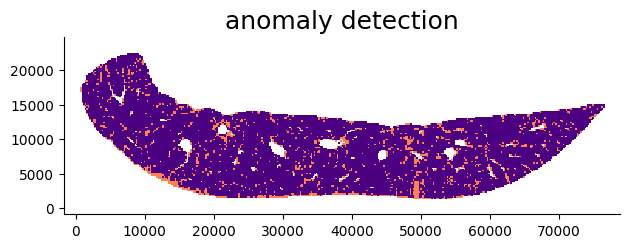

sample No.21
9261
1459
10720
Percentage of abnormal patches : 0.15754238203217796
0.7497300798963507


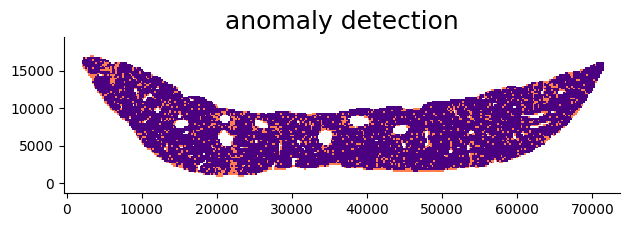

sample No.22
11792
1544
13336
Percentage of abnormal patches : 0.1309362279511533
0.7779520501904549


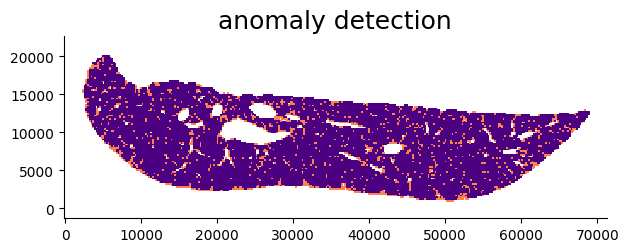

sample No.23
13833
1849
15682
Percentage of abnormal patches : 0.13366587146678233
0.6688499325756116


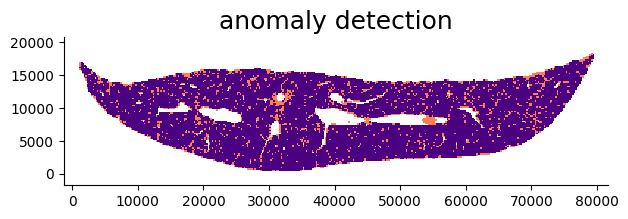

sample No.24
11283
2374
13657
Percentage of abnormal patches : 0.21040503412213063
0.7542906799913099


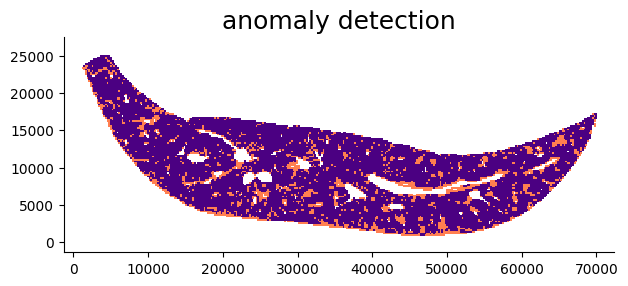

sample No.25
12994
2089
15083
Percentage of abnormal patches : 0.16076650761890104
0.7452242970594548


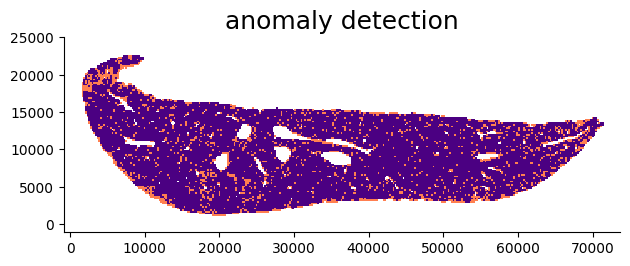

sample No.26
12761
2495
15256
Percentage of abnormal patches : 0.19551759266515165
0.7565918500762694


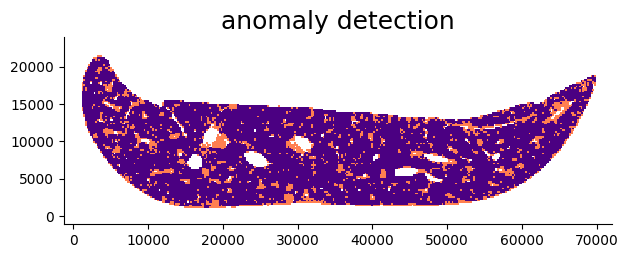

sample No.27
11154
2746
13900
Percentage of abnormal patches : 0.24618970772816925
0.7172071885973972


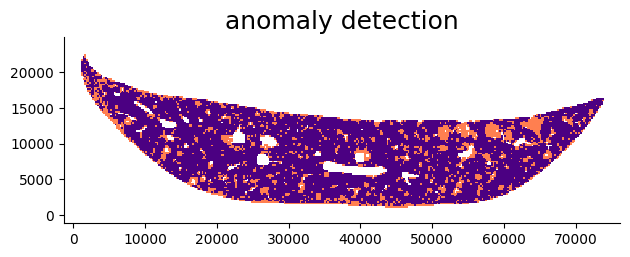

sample No.28
13530
2242
15772
Percentage of abnormal patches : 0.1657058388765706
0.7277300356319429


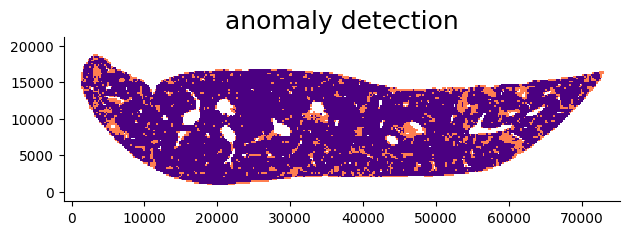

sample No.29
14728
2446
17174
Percentage of abnormal patches : 0.1660782183595872
0.7049746192893401


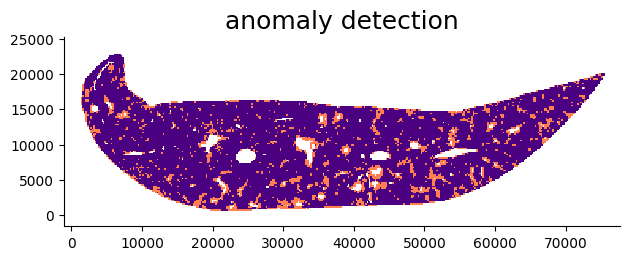

sample No.30
13969
2565
16534
Percentage of abnormal patches : 0.18362087479418712
0.6688499325756116


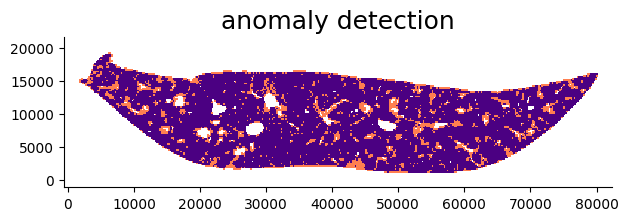

sample No.31
16218
2537
18755
Percentage of abnormal patches : 0.1564311259094833
0.6873886359136804


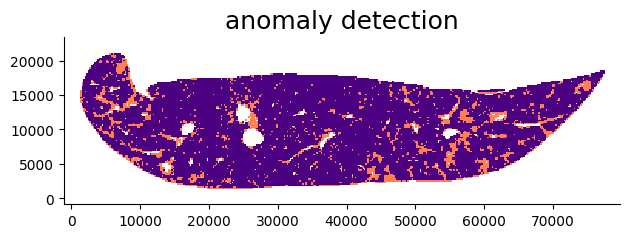

sample No.32
14431
2485
16916
Percentage of abnormal patches : 0.17219873882613818
0.7213795969249948


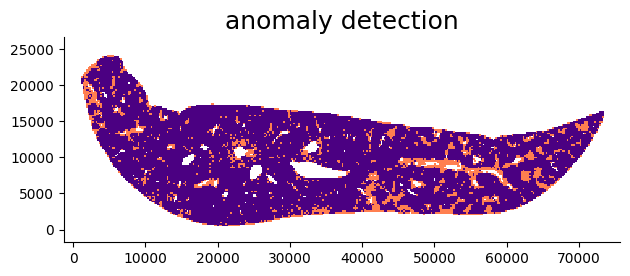

sample No.33
14212
1700
15912
Percentage of abnormal patches : 0.11961722488038277
0.7069843209122378


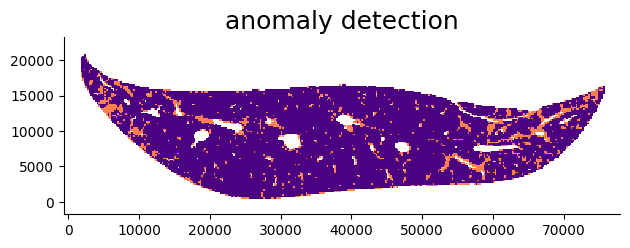

sample No.34
13902
2054
15956
Percentage of abnormal patches : 0.14774852539202993
0.747470398277718


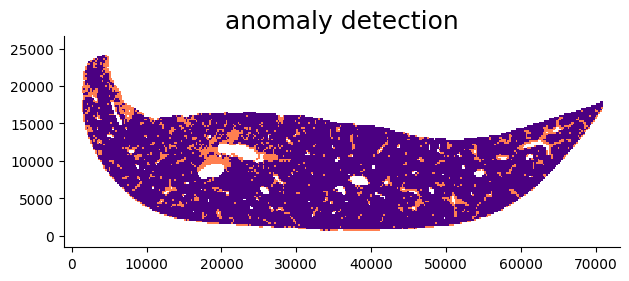

sample No.35
17298
2490
19788
Percentage of abnormal patches : 0.14394727714186611
0.6970487853844609


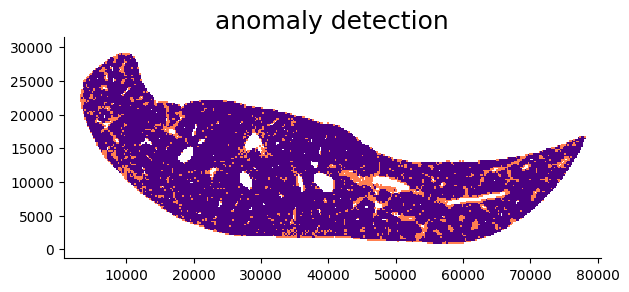

sample No.36
15483
2269
17752
Percentage of abnormal patches : 0.14654782664858232
0.7049746192893401


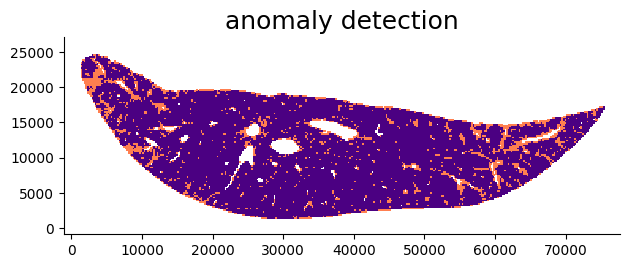

layer4
130123
sample No.4
16343
1439
17782
Percentage of abnormal patches : 0.08804992963348222
0.6529998119240172


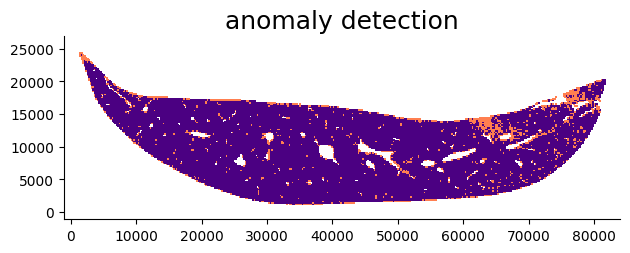

sample No.8
15325
967
16292
Percentage of abnormal patches : 0.06309951060358891
0.6581990521327014


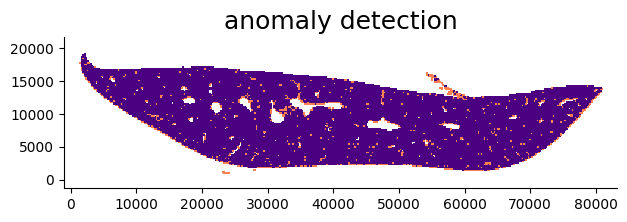

sample No.12
14379
1063
15442
Percentage of abnormal patches : 0.07392725502468878
0.787837531200363


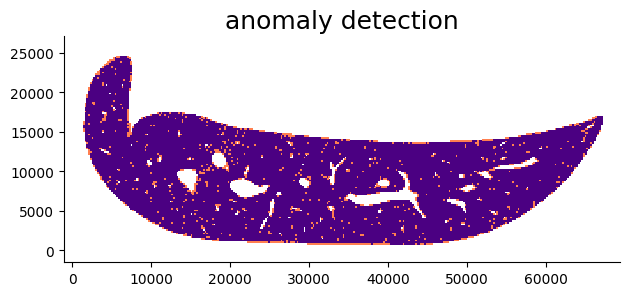

sample No.13
12972
1647
14619
Percentage of abnormal patches : 0.12696577243293247
0.6835991336877338


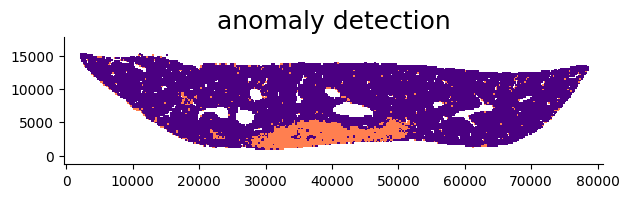

sample No.14
16113
1538
17651
Percentage of abnormal patches : 0.09545087817290386
0.6411819021237304


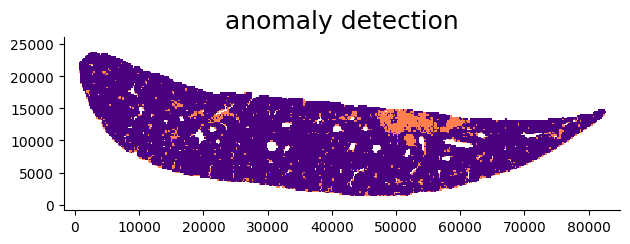

sample No.15
14421
1646
16067
Percentage of abnormal patches : 0.1141391026974551
0.6670509125840538


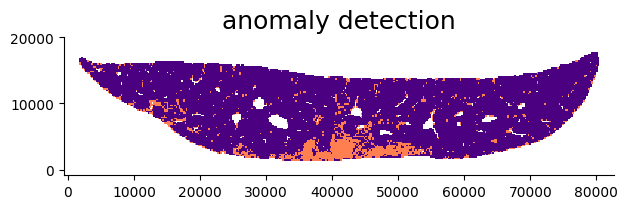

sample No.16
15336
2311
17647
Percentage of abnormal patches : 0.15069118414188837
0.6096575943810361


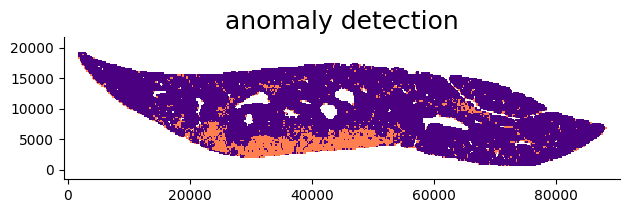

sample No.17
14667
984
15651
Percentage of abnormal patches : 0.06708938433217426
0.7589071038251366


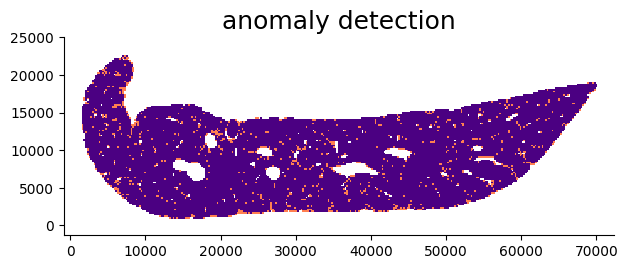

sample No.18
11627
723
12350
Percentage of abnormal patches : 0.06218285026232046
0.849938800489596


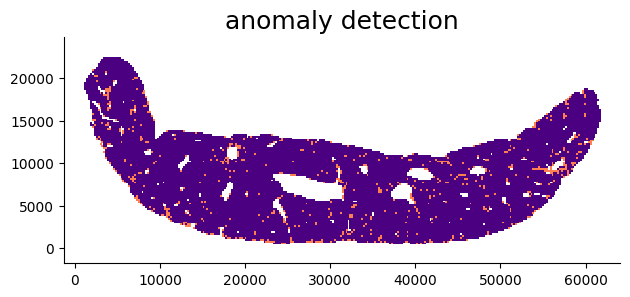

sample No.19
14369
862
15231
Percentage of abnormal patches : 0.059990256802839446
0.6892991860234267


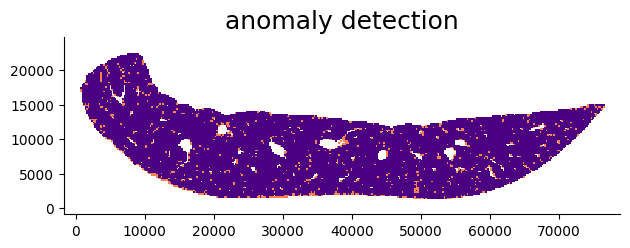

sample No.21
10061
659
10720
Percentage of abnormal patches : 0.06550044727164298
0.7497300798963507


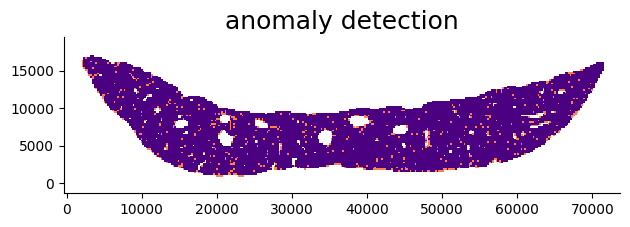

sample No.22
12541
795
13336
Percentage of abnormal patches : 0.0633920739972889
0.7779520501904549


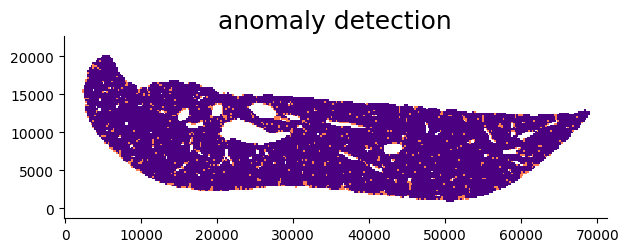

sample No.23
14758
924
15682
Percentage of abnormal patches : 0.06261010977097167
0.6688499325756116


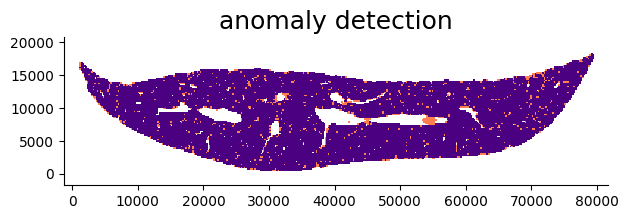

sample No.24
11812
1845
13657
Percentage of abnormal patches : 0.1561970877074162
0.7542906799913099


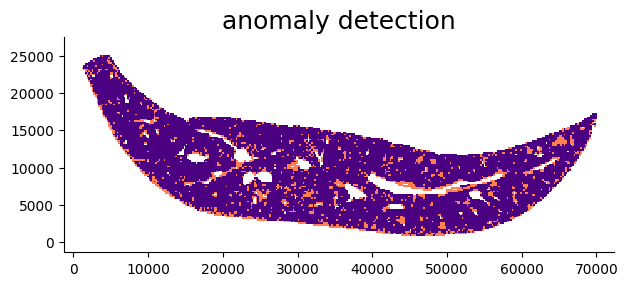

sample No.25
14121
962
15083
Percentage of abnormal patches : 0.06812548686353657
0.7452242970594548


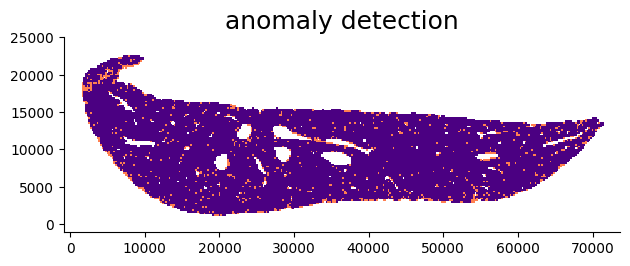

sample No.26
13310
1946
15256
Percentage of abnormal patches : 0.14620586025544705
0.7565918500762694


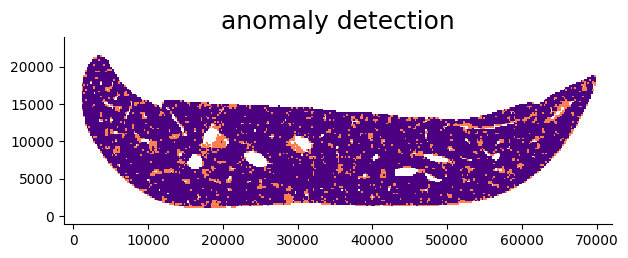

sample No.27
11793
2107
13900
Percentage of abnormal patches : 0.17866530992961926
0.7172071885973972


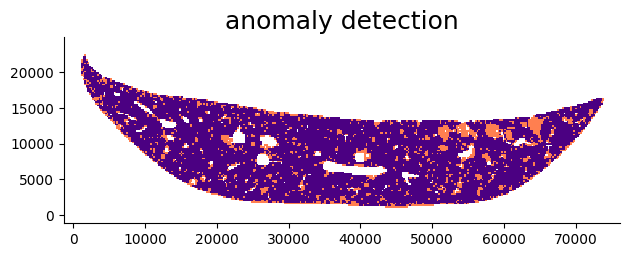

sample No.28
14055
1717
15772
Percentage of abnormal patches : 0.12216293134115973
0.7277300356319429


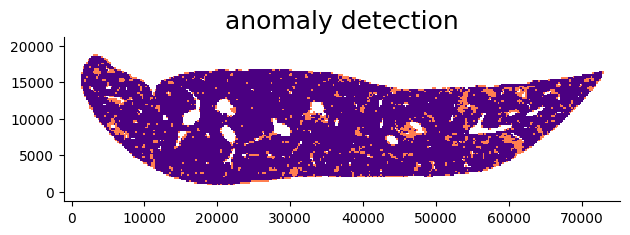

sample No.29
15282
1892
17174
Percentage of abnormal patches : 0.12380578458316974
0.7049746192893401


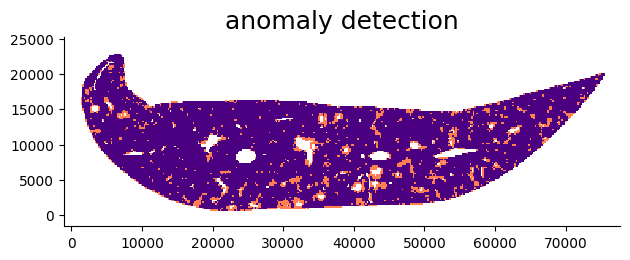

sample No.30
14594
1940
16534
Percentage of abnormal patches : 0.1329313416472523
0.6688499325756116


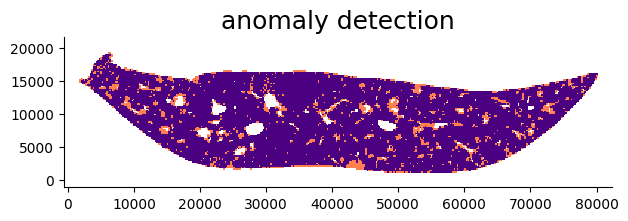

sample No.31
16840
1915
18755
Percentage of abnormal patches : 0.11371733966745844
0.6873886359136804


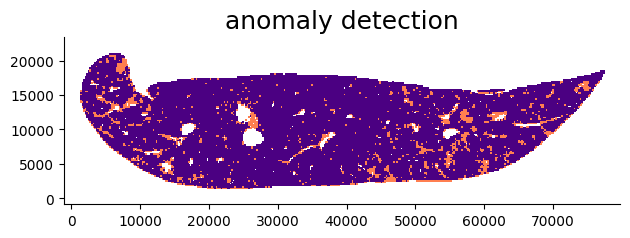

sample No.32
15020
1896
16916
Percentage of abnormal patches : 0.12623169107856191
0.7213795969249948


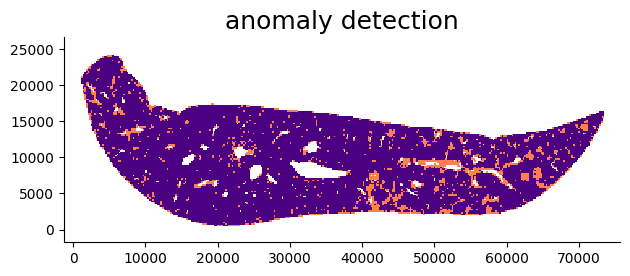

sample No.33
14640
1272
15912
Percentage of abnormal patches : 0.08688524590163935
0.7069843209122378


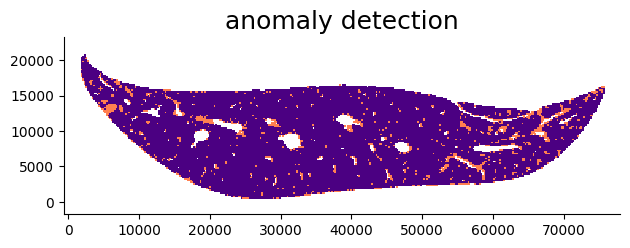

sample No.34
14429
1527
15956
Percentage of abnormal patches : 0.10582853974634417
0.747470398277718


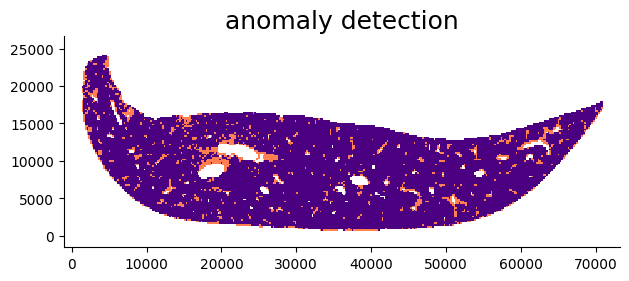

sample No.35
17840
1948
19788
Percentage of abnormal patches : 0.10919282511210762
0.6970487853844609


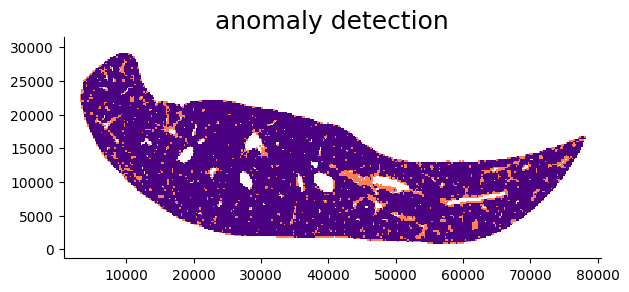

sample No.36
16101
1651
17752
Percentage of abnormal patches : 0.10254021489348487
0.7049746192893401


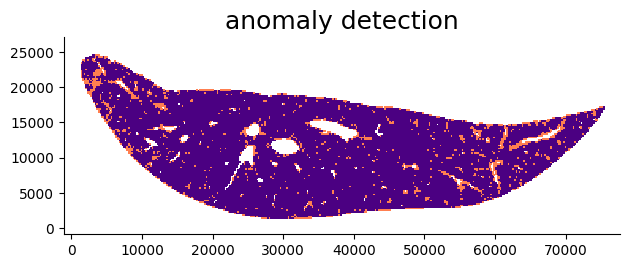

layer5
130123
sample No.4
16703
1079
17782
Percentage of abnormal patches : 0.06459917380111357
0.6529998119240172


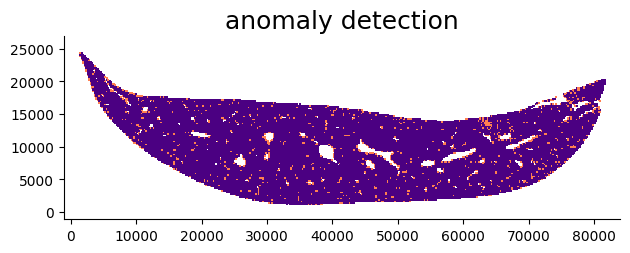

sample No.8
15422
870
16292
Percentage of abnormal patches : 0.05641291661263131
0.6581990521327014


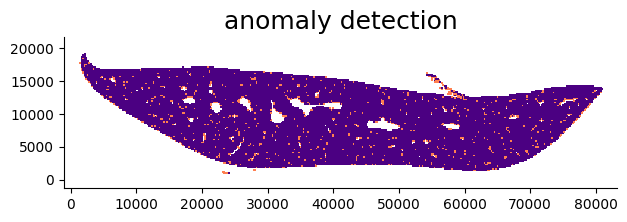

sample No.12
14477
965
15442
Percentage of abnormal patches : 0.0666574566553844
0.787837531200363


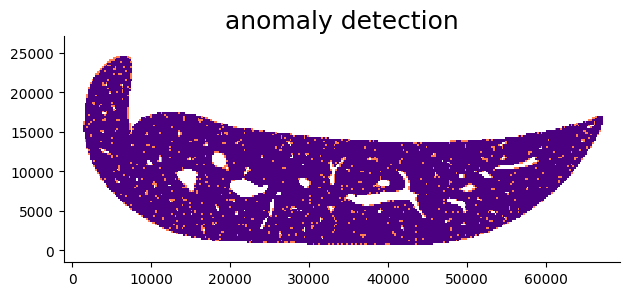

sample No.13
13825
794
14619
Percentage of abnormal patches : 0.057432188065099456
0.6835991336877338


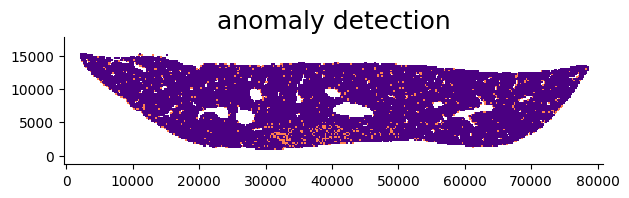

sample No.14
16564
1087
17651
Percentage of abnormal patches : 0.06562424535136441
0.6411819021237304


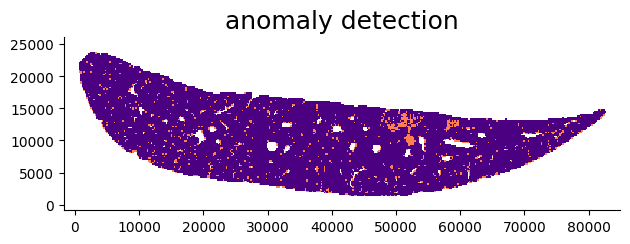

sample No.15
15169
898
16067
Percentage of abnormal patches : 0.0591996835651658
0.6670509125840538


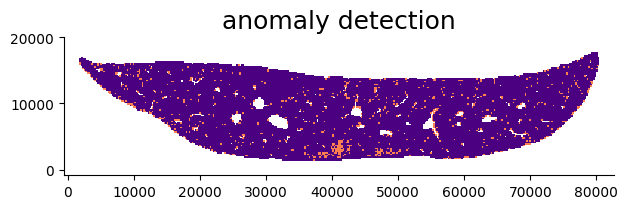

sample No.16
16436
1211
17647
Percentage of abnormal patches : 0.07367972742759796
0.6096575943810361


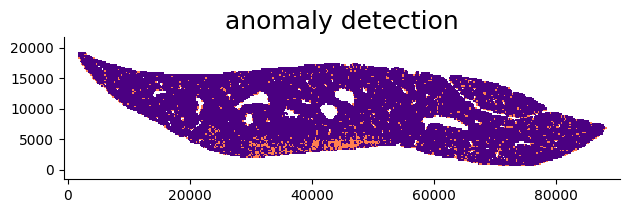

sample No.17
14997
654
15651
Percentage of abnormal patches : 0.04360872174434887
0.7589071038251366


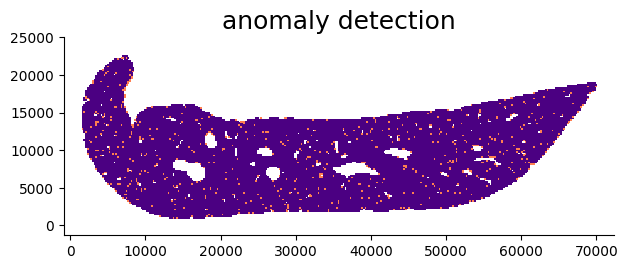

sample No.18
11742
608
12350
Percentage of abnormal patches : 0.05177993527508091
0.849938800489596


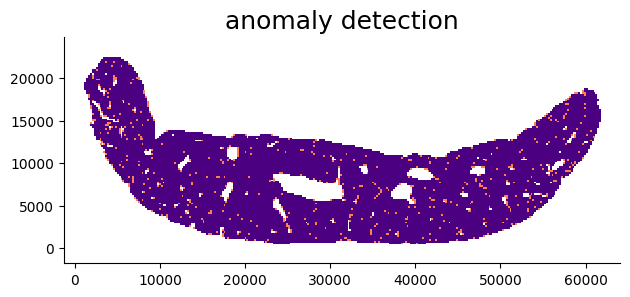

sample No.19
14604
627
15231
Percentage of abnormal patches : 0.04293344289235826
0.6892991860234267


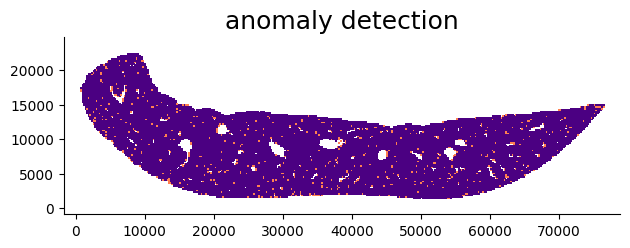

sample No.21
10207
513
10720
Percentage of abnormal patches : 0.050259625747036345
0.7497300798963507


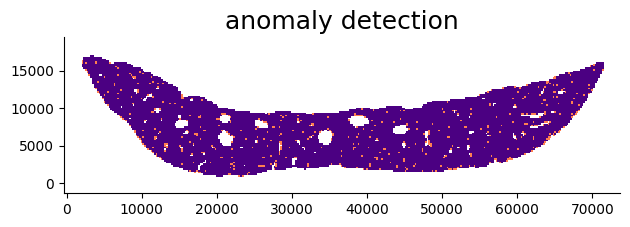

sample No.22
12727
609
13336
Percentage of abnormal patches : 0.047851025379115265
0.7779520501904549


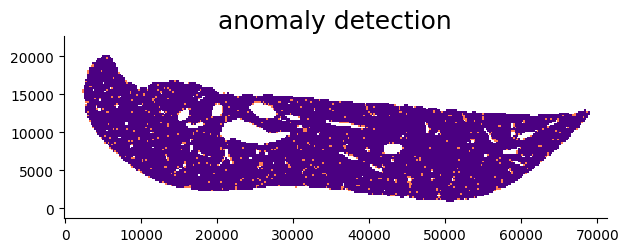

sample No.23
14904
778
15682
Percentage of abnormal patches : 0.0522007514761138
0.6688499325756116


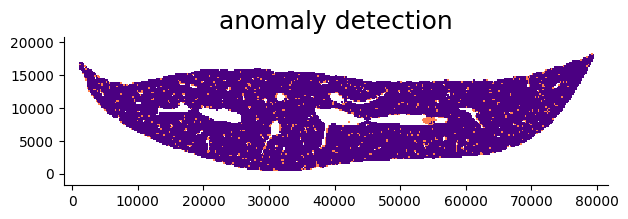

sample No.24
12815
842
13657
Percentage of abnormal patches : 0.06570425282871635
0.7542906799913099


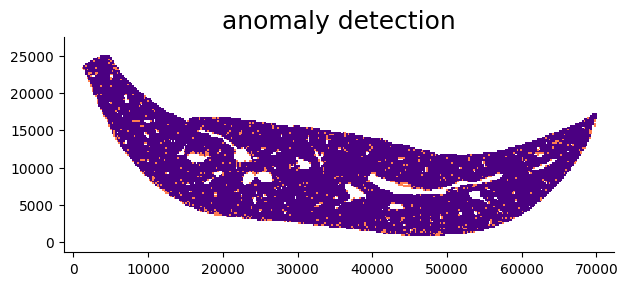

sample No.25
14390
693
15083
Percentage of abnormal patches : 0.04815844336344684
0.7452242970594548


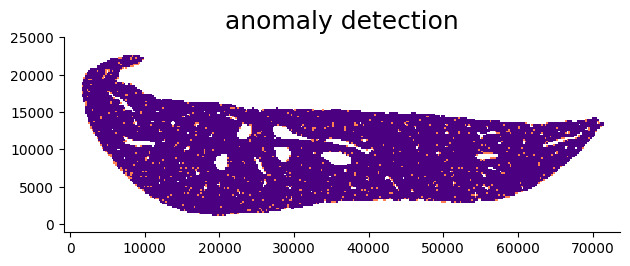

sample No.26
14418
838
15256
Percentage of abnormal patches : 0.058121792204189206
0.7565918500762694


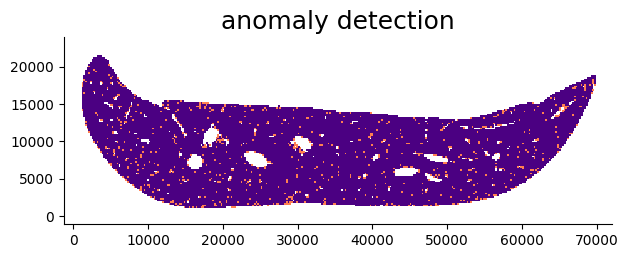

sample No.27
12826
1074
13900
Percentage of abnormal patches : 0.0837361609231249
0.7172071885973972


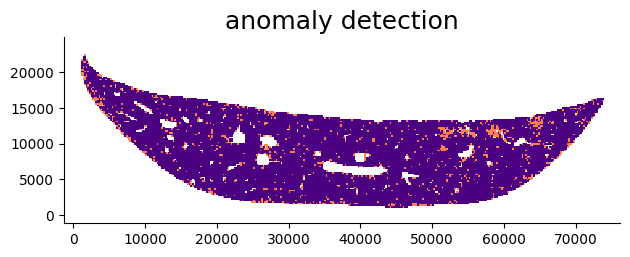

sample No.28
14863
909
15772
Percentage of abnormal patches : 0.061158581712978534
0.7277300356319429


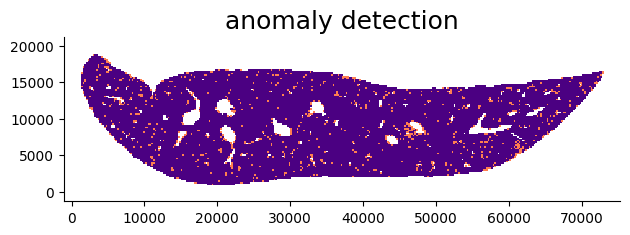

sample No.29
16222
952
17174
Percentage of abnormal patches : 0.05868573542103316
0.7049746192893401


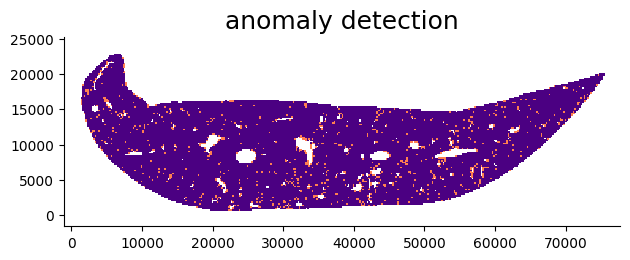

sample No.30
15574
960
16534
Percentage of abnormal patches : 0.06164119686657249
0.6688499325756116


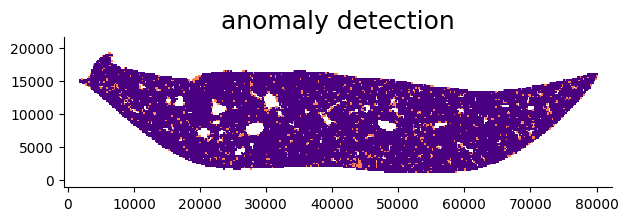

sample No.31
17814
941
18755
Percentage of abnormal patches : 0.05282362187043898
0.6873886359136804


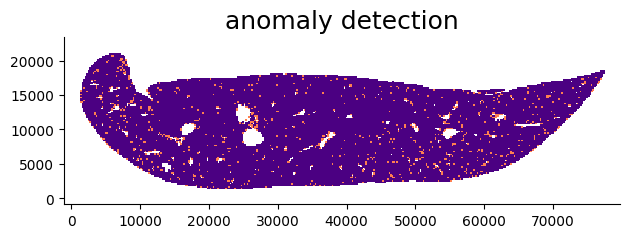

sample No.32
16073
843
16916
Percentage of abnormal patches : 0.0524482050643937
0.7213795969249948


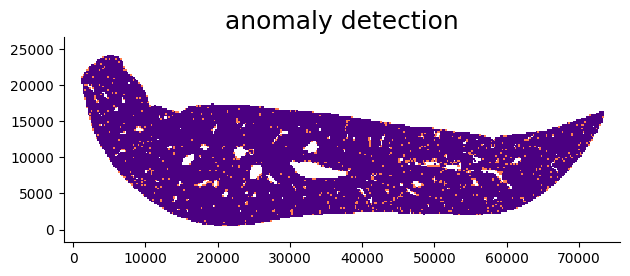

sample No.33
14990
922
15912
Percentage of abnormal patches : 0.061507671781187455
0.7069843209122378


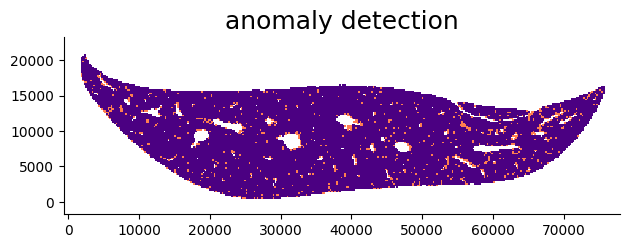

sample No.34
15034
922
15956
Percentage of abnormal patches : 0.061327657310097115
0.747470398277718


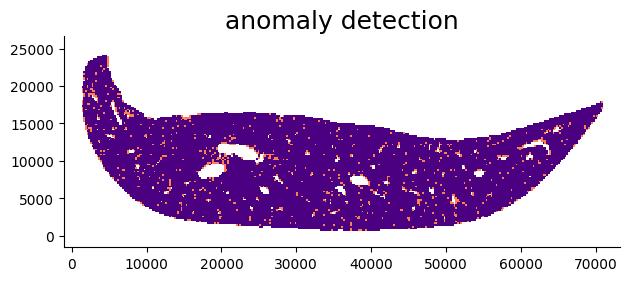

sample No.35
18605
1183
19788
Percentage of abnormal patches : 0.06358505778016663
0.6970487853844609


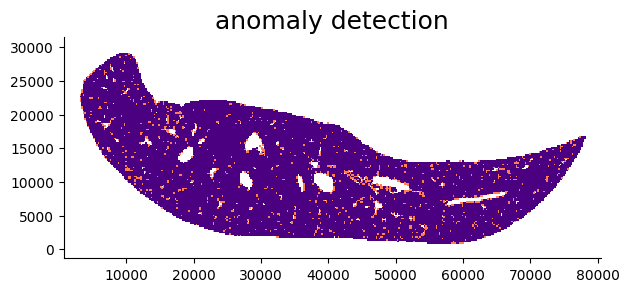

sample No.36
16748
1004
17752
Percentage of abnormal patches : 0.059947456412706
0.7049746192893401


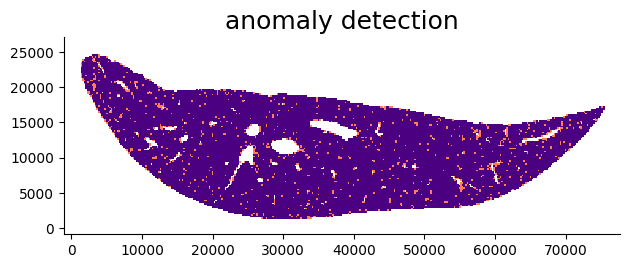

In [49]:
for n in [1, 2, 3, 4, 5]:
    print("layer"+str(n)+"\n"+"============================")
    f_path_1 = "workspace/result_v4/1_layer"+str(n)+".npy"
    feature_1 = np.load(f_path_1)
    f_path_2 = "workspace/result_v4/2_layer"+str(n)+".npy"
    feature_2 = np.load(f_path_2)
    f_path_3 = "workspace/result_v4/3_layer"+str(n)+".npy"
    feature_3 = np.load(f_path_3)
    f_path_5 = "workspace/result_v4/5_layer"+str(n)+".npy"
    feature_5 = np.load(f_path_5)
    f_path_6 = "workspace/result_v4/6_layer"+str(n)+".npy"
    feature_6 = np.load(f_path_6)
    f_path_7 = "workspace/result_v4/7_layer"+str(n)+".npy"
    feature_7 = np.load(f_path_7)
    f_path_9 = "workspace/result_v4/9_layer"+str(n)+".npy"
    feature_9 = np.load(f_path_9)
    f_path_10 = "workspace/result_v4/10_layer"+str(n)+".npy"
    feature_10 = np.load(f_path_10)
    f_path_11 = "workspace/result_v4/11_layer"+str(n)+".npy"
    feature_11 = np.load(f_path_11)
    f_conc = list(feature_1) + list(feature_2) + list(feature_3)+ list(feature_5)+ list(feature_6)+ list(feature_7)+ list(feature_9)+ list(feature_10)+ list(feature_11)
    print(len(f_conc))
    
    # 学習データを標準化
    scaler = StandardScaler()
    feature_scaled = scaler.fit_transform(f_conc)

    # 学習 (one-class SVM)
    total_p = len(feature_scaled)
    nu = 0.05 #5%ぐらいは許容
    gamma = "auto" #一旦適当
    ocsvm_224_mask = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

    # 適用
    for i in [4, 8, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]:
        f_path = "workspace/result_v4/"+str(i)+"_layer"+str(n)+".npy"
        l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
        feature = np.load(f_path)
        location = pd.read_pickle(l_path)
        feature_scaled = scaler.fit_transform(feature)
        jud = ocsvm_224_mask.predict(feature_scaled)
        print("sample No."+str(i))
        print(len([i for i in jud if i == 1]))
        print(len([i for i in jud if i == -1]))
        print(len(location))
        print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
        loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

In [33]:
f_path_1 = "workspace/result_v4/1_layer5.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v4/2_layer5.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v4/3_layer5.npy"
feature_3 = np.load(f_path_3)
f_path_5 = "workspace/result_v4/5_layer5.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v4/6_layer5.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v4/7_layer5.npy"
feature_7 = np.load(f_path_7)
f_path_9 = "workspace/result_v4/9_layer5.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v4/10_layer5.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v4/11_layer5.npy"
feature_11 = np.load(f_path_11)

In [34]:
f_conc = list(feature_1) + list(feature_2) + list(feature_3)+ list(feature_5)+ list(feature_6)+ list(feature_7)+ list(feature_9)+ list(feature_10)+ list(feature_11)

In [35]:
len(f_conc)

130123

In [36]:
#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

In [37]:
total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

sample No.4
16703
1079
17782
Percentage of abnormal patches : 0.06459917380111357
0.6529998119240172


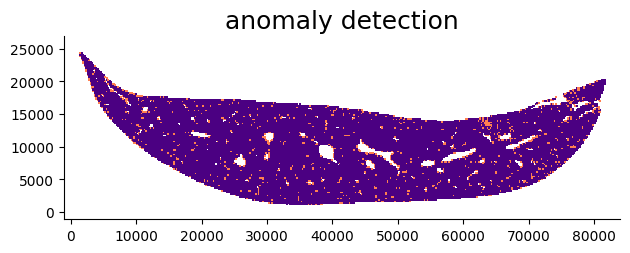

In [42]:
for i in [4]:
    f_path = "workspace/result_v4/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print(len(location))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

sample No.4
16703
1079
17782
Percentage of abnormal patches : 0.06459917380111357
0.6529998119240172


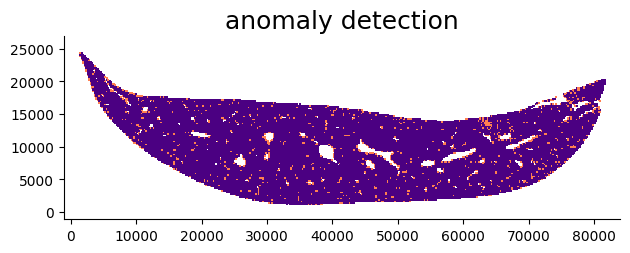

sample No.8
15422
870
16292
Percentage of abnormal patches : 0.05641291661263131
0.6581990521327014


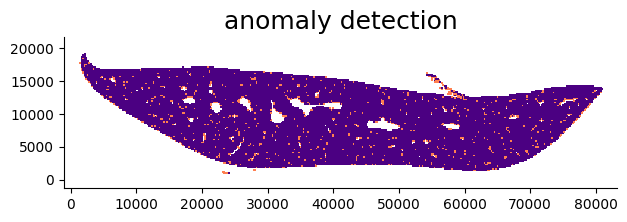

sample No.12
14477
965
15442
Percentage of abnormal patches : 0.0666574566553844
0.787837531200363


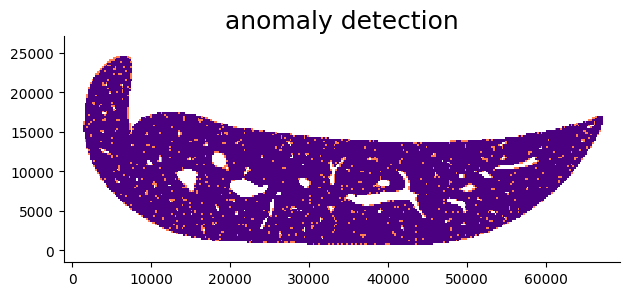

sample No.13
13825
794
14619
Percentage of abnormal patches : 0.057432188065099456
0.6835991336877338


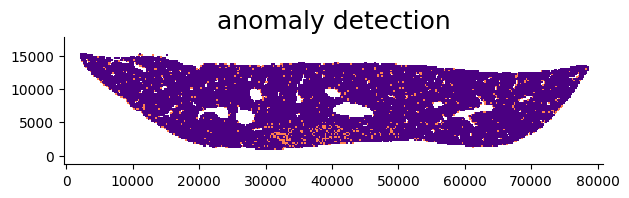

sample No.14
16564
1087
17651
Percentage of abnormal patches : 0.06562424535136441
0.6411819021237304


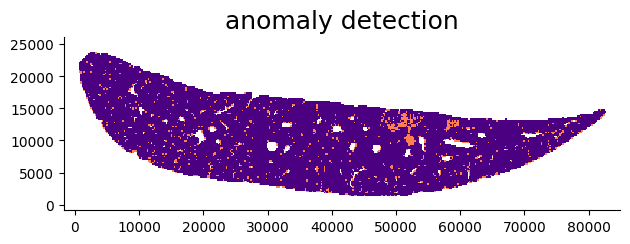

sample No.15
15169
898
16067
Percentage of abnormal patches : 0.0591996835651658
0.6670509125840538


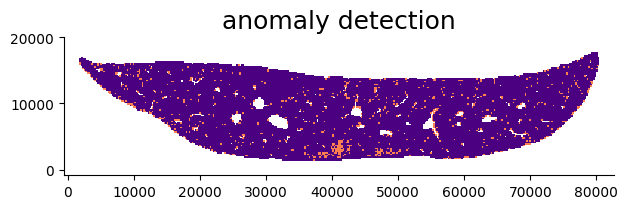

sample No.16
16436
1211
17647
Percentage of abnormal patches : 0.07367972742759796
0.6096575943810361


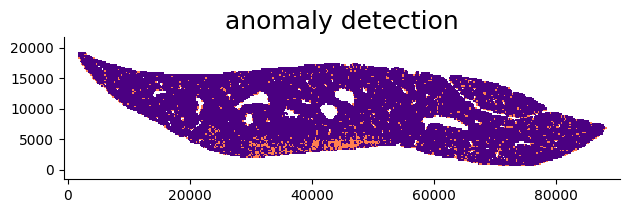

sample No.17
14997
654
15651
Percentage of abnormal patches : 0.04360872174434887
0.7589071038251366


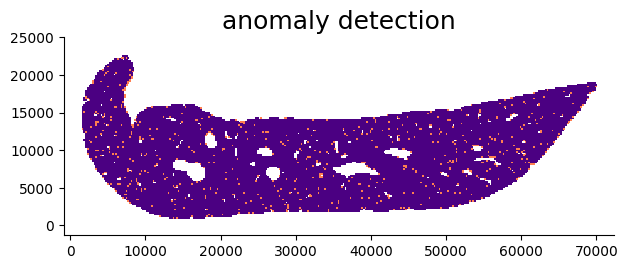

sample No.18
11742
608
12350
Percentage of abnormal patches : 0.05177993527508091
0.849938800489596


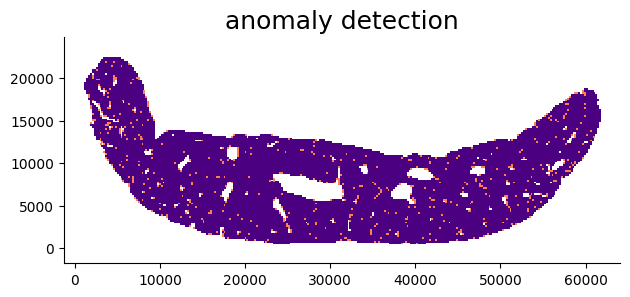

sample No.19
14604
627
15231
Percentage of abnormal patches : 0.04293344289235826
0.6892991860234267


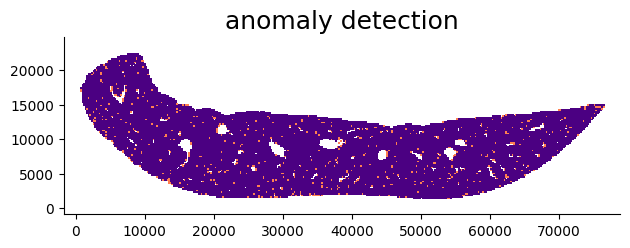

sample No.21
10207
513
10720
Percentage of abnormal patches : 0.050259625747036345
0.7497300798963507


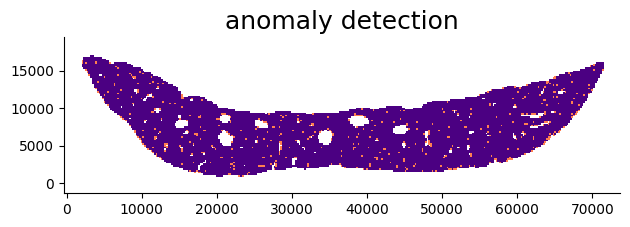

sample No.22
12727
609
13336
Percentage of abnormal patches : 0.047851025379115265
0.7779520501904549


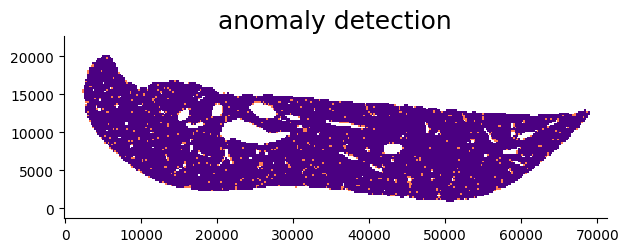

sample No.23
14904
778
15682
Percentage of abnormal patches : 0.0522007514761138
0.6688499325756116


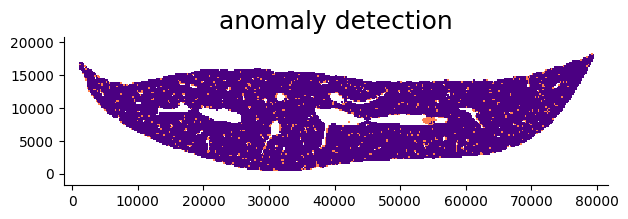

sample No.24
12815
842
13657
Percentage of abnormal patches : 0.06570425282871635
0.7542906799913099


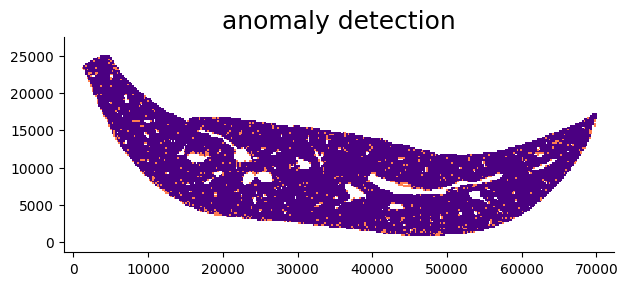

sample No.25
14390
693
15083
Percentage of abnormal patches : 0.04815844336344684
0.7452242970594548


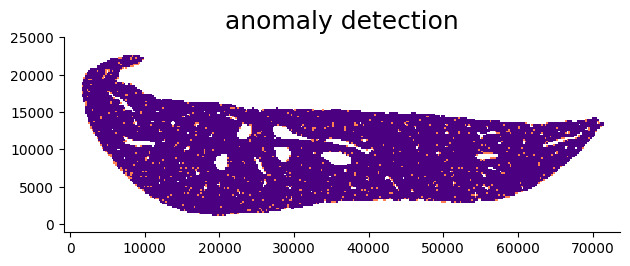

sample No.26
14418
838
15256
Percentage of abnormal patches : 0.058121792204189206
0.7565918500762694


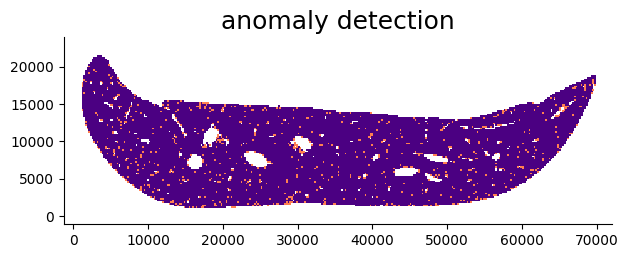

sample No.27
12826
1074
13900
Percentage of abnormal patches : 0.0837361609231249
0.7172071885973972


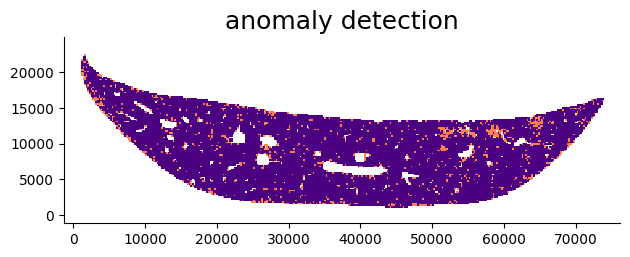

sample No.28
14863
909
15772
Percentage of abnormal patches : 0.061158581712978534
0.7277300356319429


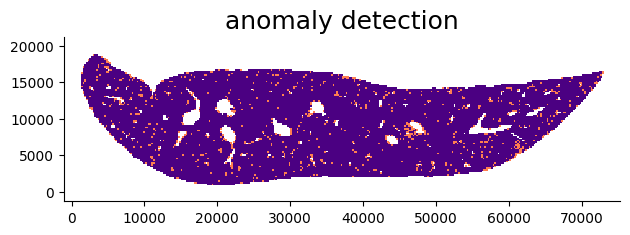

sample No.29
16222
952
17174
Percentage of abnormal patches : 0.05868573542103316
0.7049746192893401


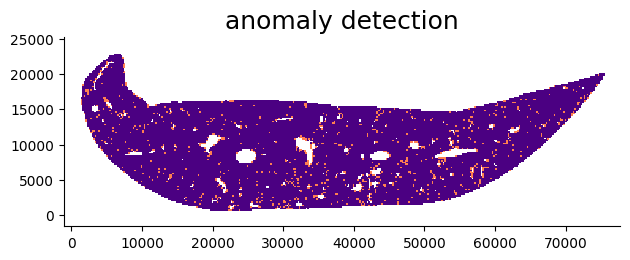

sample No.30
15574
960
16534
Percentage of abnormal patches : 0.06164119686657249
0.6688499325756116


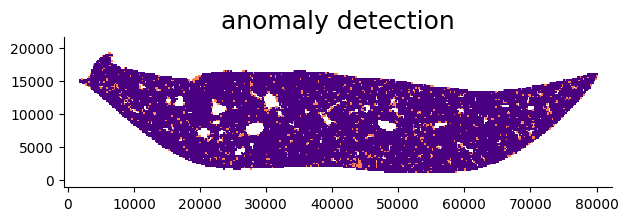

sample No.31
17814
941
18755
Percentage of abnormal patches : 0.05282362187043898
0.6873886359136804


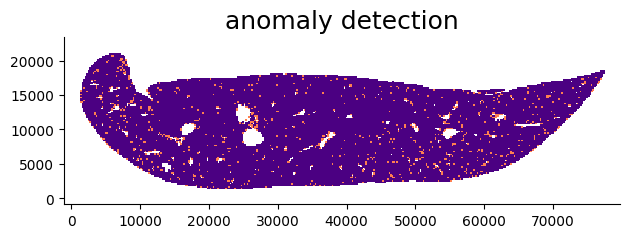

sample No.32
16073
843
16916
Percentage of abnormal patches : 0.0524482050643937
0.7213795969249948


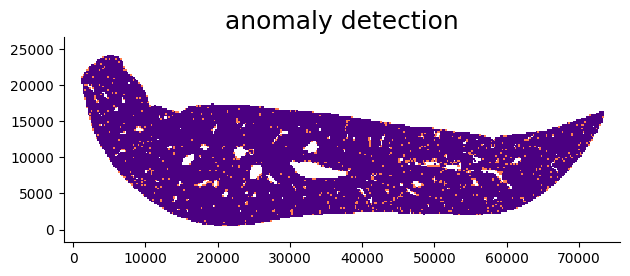

sample No.33
14990
922
15912
Percentage of abnormal patches : 0.061507671781187455
0.7069843209122378


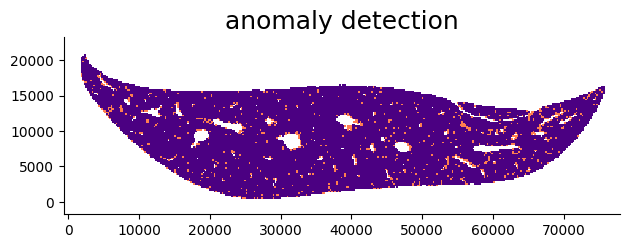

sample No.34
15034
922
15956
Percentage of abnormal patches : 0.061327657310097115
0.747470398277718


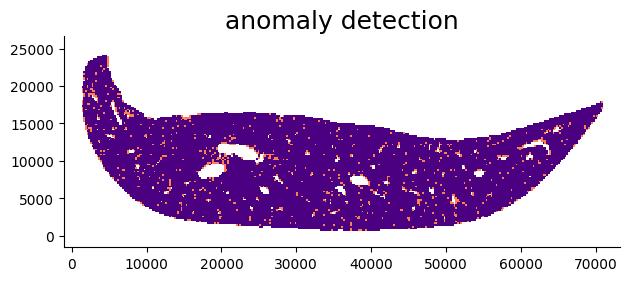

sample No.35
18605
1183
19788
Percentage of abnormal patches : 0.06358505778016663
0.6970487853844609


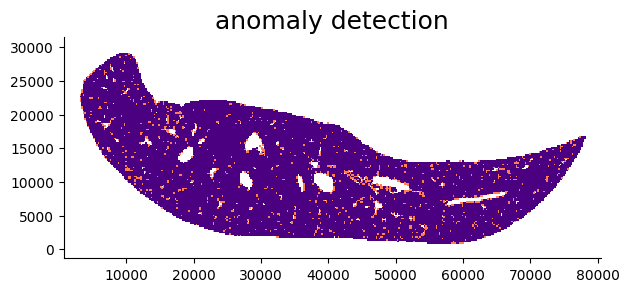

sample No.36
16748
1004
17752
Percentage of abnormal patches : 0.059947456412706
0.7049746192893401


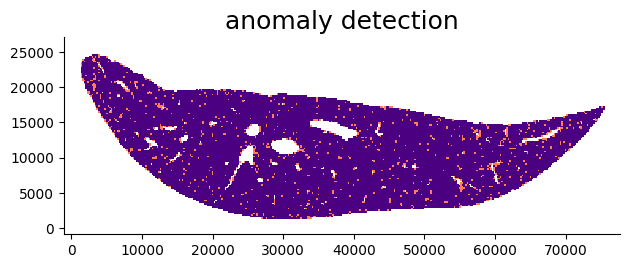

In [43]:
for i in [4, 8, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]:
    f_path = "workspace/result_v4/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print(len(location))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

sample No.4
16511
1271
17782
Percentage of abnormal patches : 0.07697898370783114
0.6529998119240172


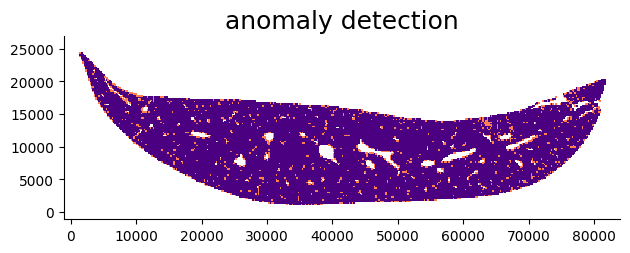

sample No.8
15233
1059
16292
Percentage of abnormal patches : 0.06952012079038929
0.6581990521327014


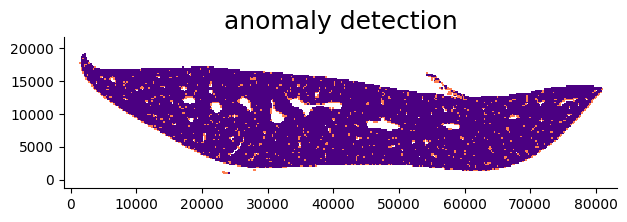

sample No.12
14338
1104
15442
Percentage of abnormal patches : 0.07699818663690891
0.787837531200363


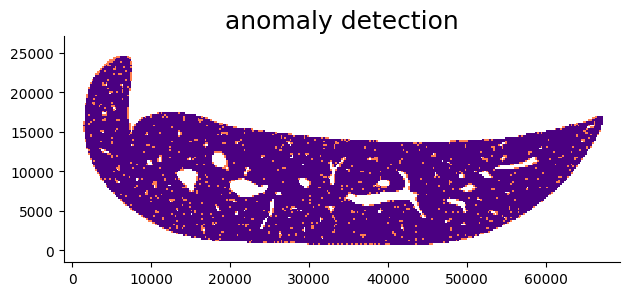

sample No.13
13674
945
14619
Percentage of abnormal patches : 0.06910925844668714
0.6835991336877338


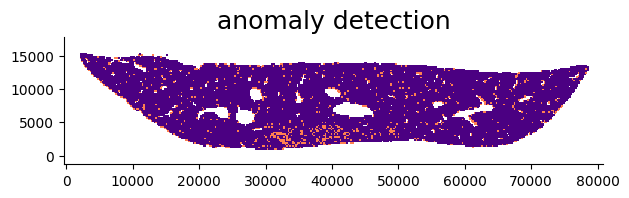

sample No.14
16361
1290
17651
Percentage of abnormal patches : 0.07884603630584927
0.6411819021237304


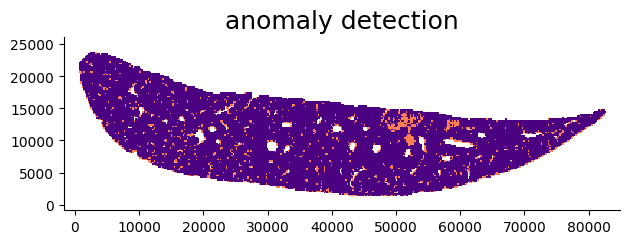

sample No.15
14952
1115
16067
Percentage of abnormal patches : 0.07457196361690743
0.6670509125840538


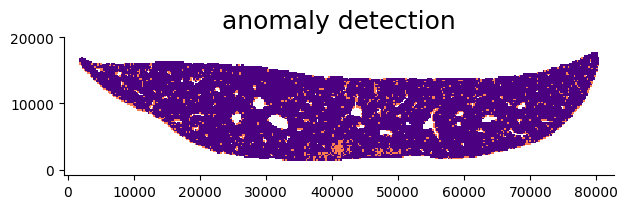

sample No.16
16205
1442
17647
Percentage of abnormal patches : 0.08898488120950324
0.6096575943810361


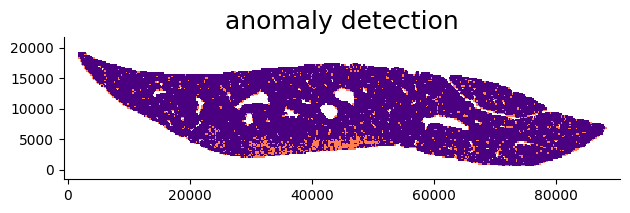

sample No.17
14844
807
15651
Percentage of abnormal patches : 0.05436540016168149
0.7589071038251366


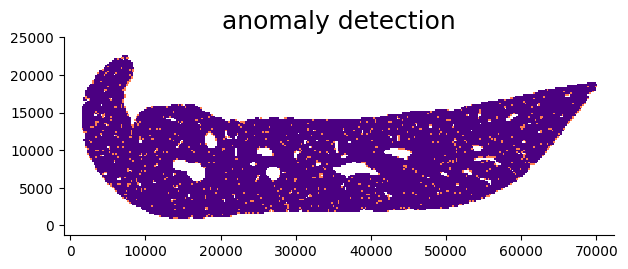

sample No.18
11631
719
12350
Percentage of abnormal patches : 0.06181755652996303
0.849938800489596


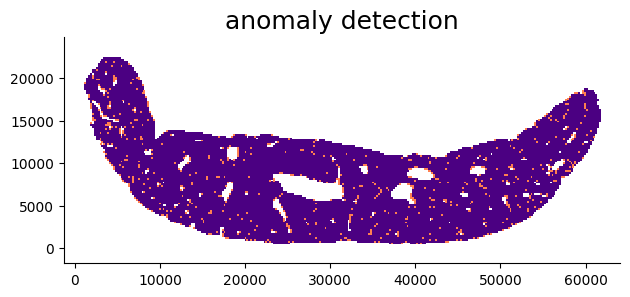

sample No.19
14414
817
15231
Percentage of abnormal patches : 0.056681004578881644
0.6892991860234267


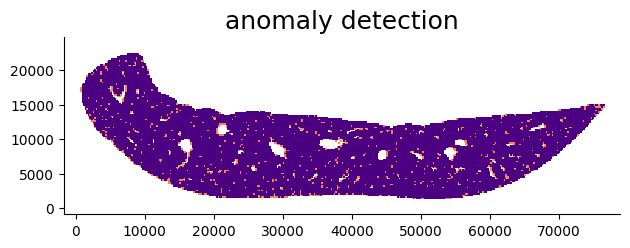

sample No.21
10113
607
10720
Percentage of abnormal patches : 0.06002175417779096
0.7497300798963507


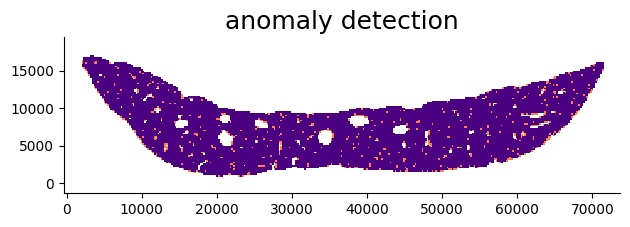

sample No.22
12568
768
13336
Percentage of abnormal patches : 0.061107574793125397
0.7779520501904549


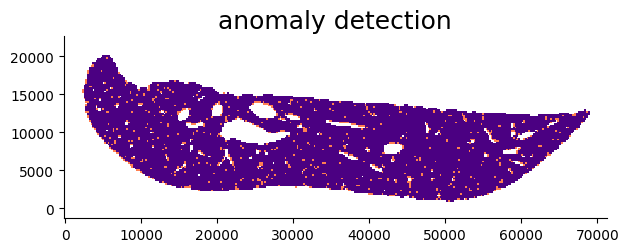

sample No.23
14764
918
15682
Percentage of abnormal patches : 0.06217827147114603
0.6688499325756116


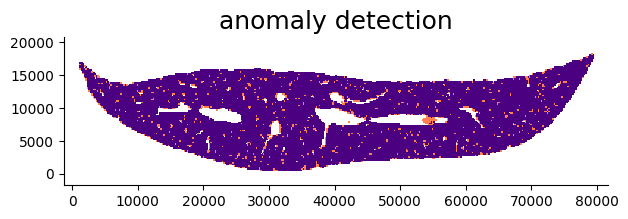

sample No.24
12672
985
13657
Percentage of abnormal patches : 0.0777304292929293
0.7542906799913099


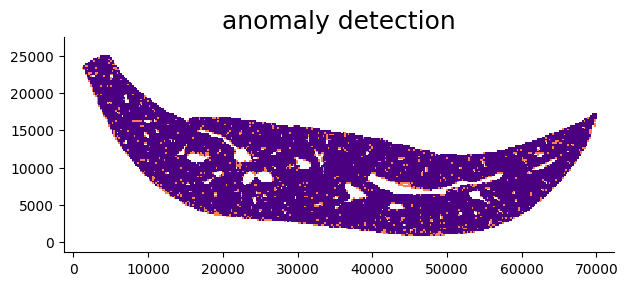

sample No.25
14236
847
15083
Percentage of abnormal patches : 0.059497049733071086
0.7452242970594548


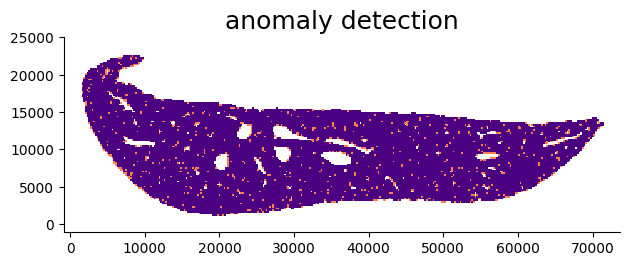

sample No.26
14248
1008
15256
Percentage of abnormal patches : 0.07074677147669849
0.7565918500762694


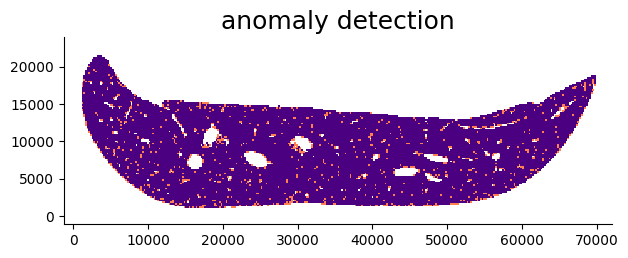

sample No.27
12684
1216
13900
Percentage of abnormal patches : 0.09586881110059918
0.7172071885973972


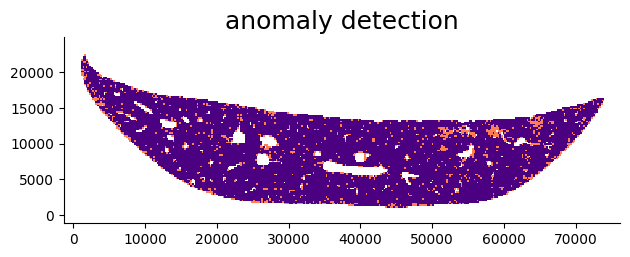

sample No.28
14648
1124
15772
Percentage of abnormal patches : 0.07673402512288367
0.7277300356319429


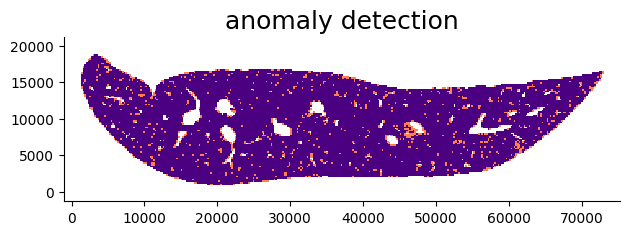

sample No.29
16024
1150
17174
Percentage of abnormal patches : 0.0717673489765352
0.7049746192893401


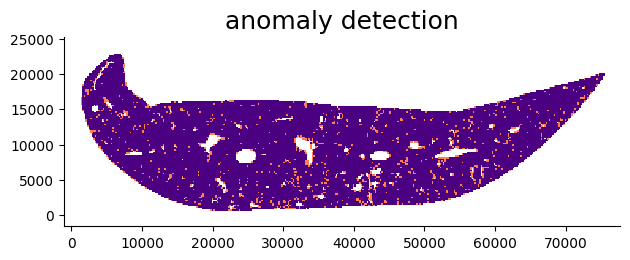

sample No.30
15379
1155
16534
Percentage of abnormal patches : 0.07510241238051889
0.6688499325756116


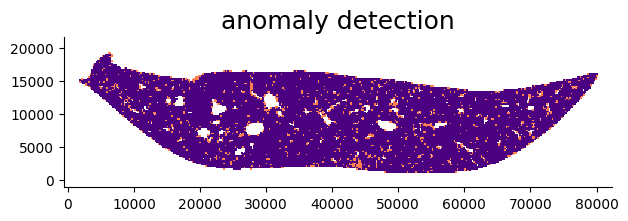

sample No.31
17558
1197
18755
Percentage of abnormal patches : 0.06817405171431826
0.6873886359136804


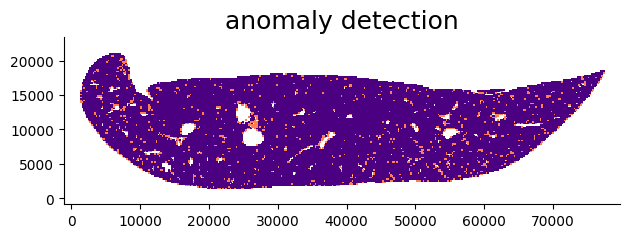

sample No.32
15856
1060
16916
Percentage of abnormal patches : 0.06685166498486378
0.7213795969249948


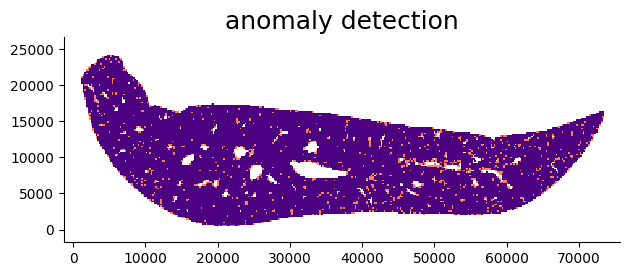

sample No.33
14819
1093
15912
Percentage of abnormal patches : 0.07375666374249275
0.7069843209122378


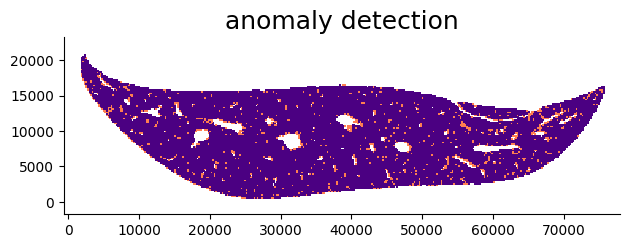

sample No.34
14841
1115
15956
Percentage of abnormal patches : 0.07512970824068459
0.747470398277718


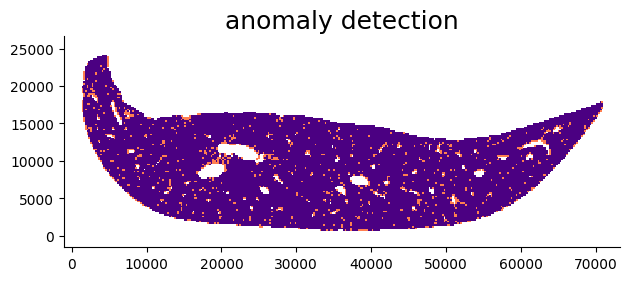

sample No.35
18393
1395
19788
Percentage of abnormal patches : 0.07584407111401076
0.6970487853844609


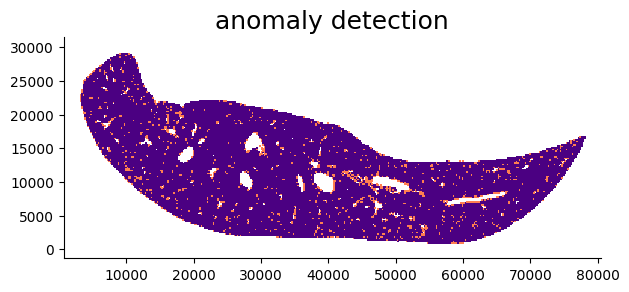

sample No.36
16558
1194
17752
Percentage of abnormal patches : 0.0721101582316705
0.7049746192893401


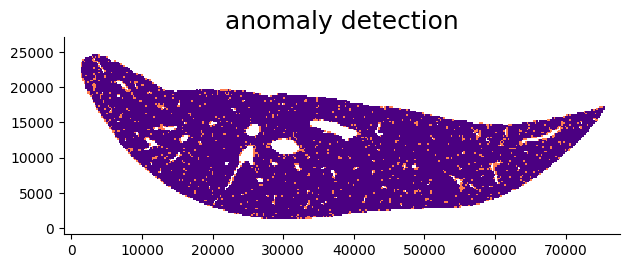

In [41]:
for i in [4, 8, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]:
    f_path = "workspace/result_v4/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print(len(location))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

#### PCA (get_mask & layer4) ####

In [52]:
from sklearn.decomposition import PCA

In [51]:
f_path_1 = "workspace/result_v4/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v4/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v4/3_layer4.npy"
feature_3 = np.load(f_path_3)
f_path_5 = "workspace/result_v4/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v4/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v4/7_layer4.npy"
feature_7 = np.load(f_path_7)
f_path_9 = "workspace/result_v4/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v4/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v4/11_layer4.npy"
feature_11 = np.load(f_path_11)

f_conc = list(feature_1) + list(feature_2) + list(feature_3)+ list(feature_5)+ list(feature_6)+ list(feature_7)+ list(feature_9)+ list(feature_10)+ list(feature_11)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [53]:
def get_info(sample_id, feature, location, jud):
    inf_lst = []
    max_n = len([i for i in jud if i == -1])
    print("max_n = ", str(max_n))
    n = 0
    ap = inf_lst.append
    for i in zip(jud, feature, location):
        if i[0] == -1:
            ap([sample_id, i[1], i[2], i[0]])
        elif i[0] == 1 and n < max_n:
            ap([sample_id, i[1], i[2], i[0]])
            n = n + 1
        else:
            pass

    return inf_lst

sample No.4
16343
1439
Percentage of abnormal patches : 0.08804992963348222
max_n =  1439
0.6529998119240172


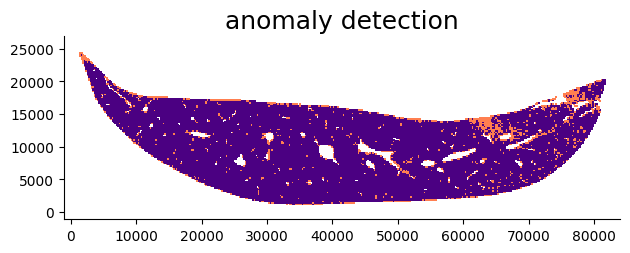

sample No.8
15325
967
Percentage of abnormal patches : 0.06309951060358891
max_n =  967
0.6581990521327014


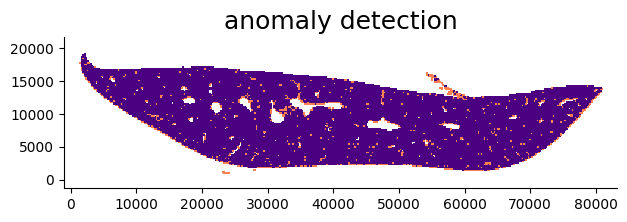

sample No.12
14379
1063
Percentage of abnormal patches : 0.07392725502468878
max_n =  1063
0.787837531200363


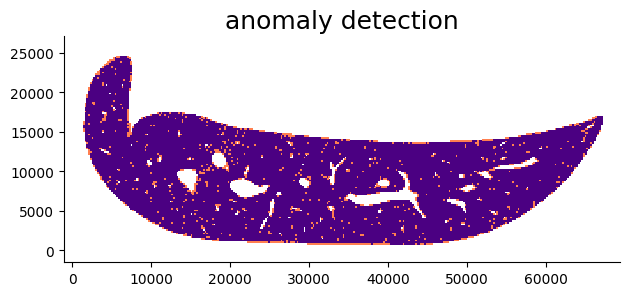

sample No.13
12972
1647
Percentage of abnormal patches : 0.12696577243293247
max_n =  1647
0.6835991336877338


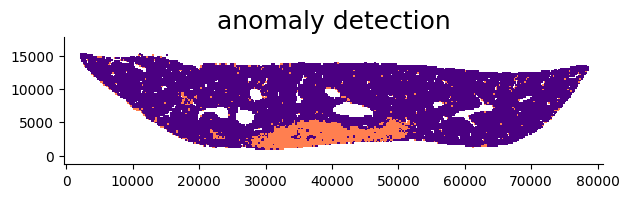

sample No.15
14421
1646
Percentage of abnormal patches : 0.1141391026974551
max_n =  1646
0.6670509125840538


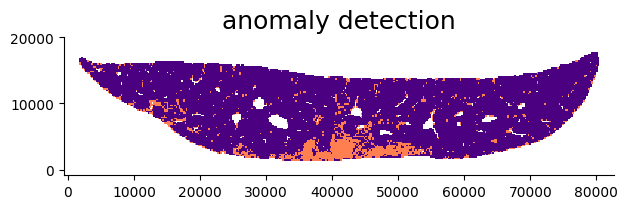

sample No.16
15336
2311
Percentage of abnormal patches : 0.15069118414188837
max_n =  2311
0.6096575943810361


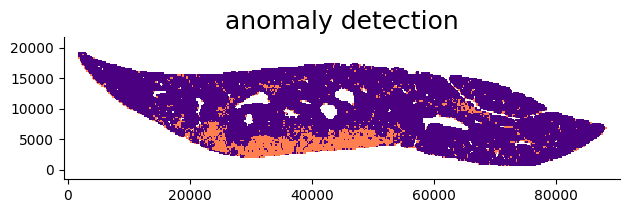

sample No.26
13310
1946
Percentage of abnormal patches : 0.14620586025544705
max_n =  1946
0.7565918500762694


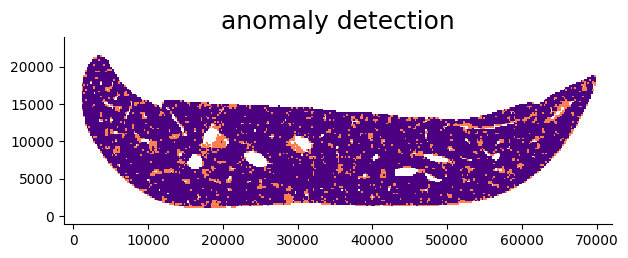

sample No.27
11793
2107
Percentage of abnormal patches : 0.17866530992961926
max_n =  2107
0.7172071885973972


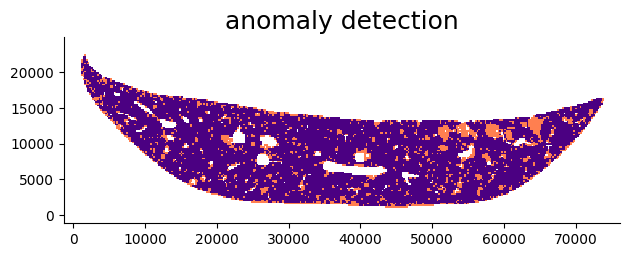

sample No.28
14055
1717
Percentage of abnormal patches : 0.12216293134115973
max_n =  1717
0.7277300356319429


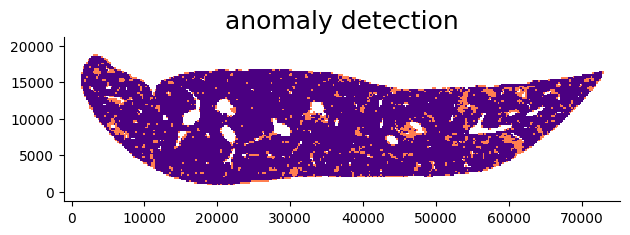

In [72]:
total_inf_lst = []
for i in [4, 8, 12, 13, 15, 16, 26, 27, 28]:
    f_path = "workspace/result_v4/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

In [78]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]
bach_dict = {4:"dimgray", 8:"dimgray", 12:"dimgray", 13:"orangered", 15:"orangered", 16:"orangered", 26:"mediumblue", 27:"mediumblue", 28:"mediumblue"}

In [79]:
# 第一主成分と第二主成分でプロットする
def PCAplot_v3(feature, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, pict_sample=6, seed1=2477, seed2=2477, title=""):
    fig, ax = plt.subplots()
    label_lst = []
    ap = label_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    n = 0
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature)), sample)
    random.seed(seed2)
    random.shuffle(ran_sam)
    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if pca_inf[i][0] not in label_lst:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0,
                    label="No."+str(pca_inf[i][0]), zorder=1
                    )
                ap(pca_inf[i][0])

            elif (pca_inf[i][0] == 4 or pca_inf[i][0] == 8 or pca_inf[i][0] == 12) and label_lst.count(4) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(4)-1), weight="bold"
                )
                ap_loc([label_lst.count(4)-1, pca_inf[i][1], pca_inf[i][0]])


            elif (pca_inf[i][0] == 13 or pca_inf[i][0] == 15 or pca_inf[i][0] == 16) and label_lst.count(16) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(16)-1+pict_sample), weight="bold"
                )
                ap_loc([label_lst.count(16)-1+pict_sample, pca_inf[i][1], pca_inf[i][0]])

            elif (pca_inf[i][0] == 26 or pca_inf[i][0] == 27 or pca_inf[i][0] == 28) and label_lst.count(27) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(27)-1+pict_sample*2), weight="bold"
                )
                ap_loc([label_lst.count(27)-1+pict_sample*2, pca_inf[i][1], pca_inf[i][0]])
            
            else:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0, zorder=1
                    )
        else:
            ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color="white", linewidth=1, ec=bach_dict[pca_inf[i][0]], zorder=1
                    )

    ax.set_title(title, fontsize=18)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()
    
    return loc_lst

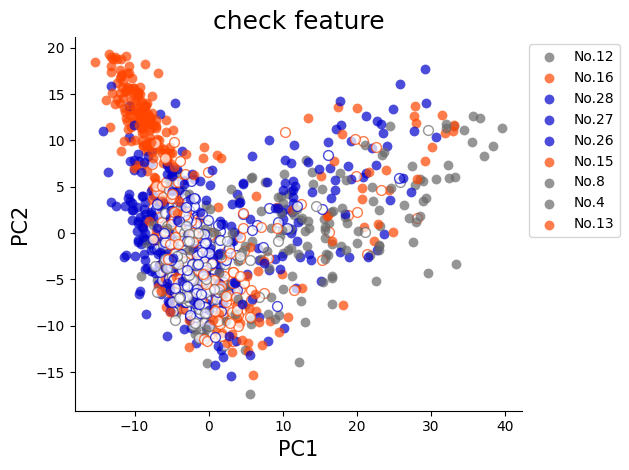

In [80]:
loc_lst_l4 = PCAplot_v3(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=1500, pict_sample=0, seed1=24771, title="check feature")

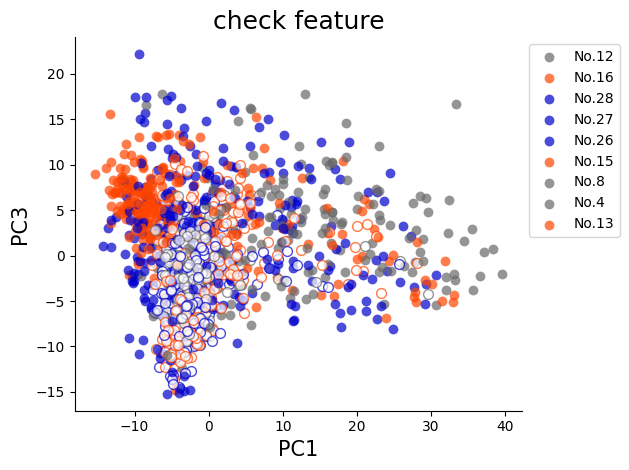

In [81]:
loc_lst_l4 = PCAplot_v3(feature_pca, pca_inf, bach_dict, xnum=0, ynum=2, sample=1500, pict_sample=0, seed1=24771, title="check feature")

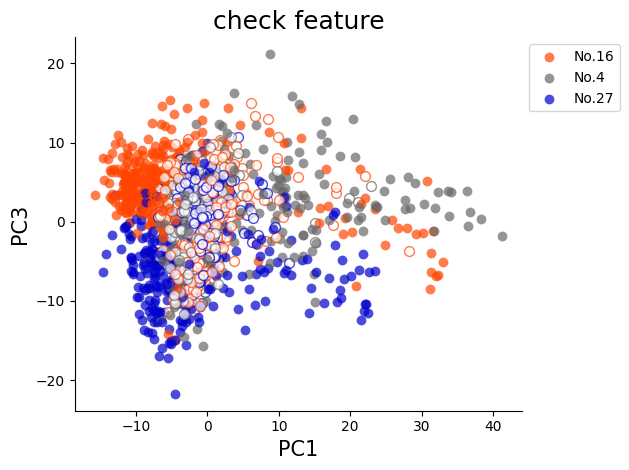

In [ ]:
loc_lst_l4 = PCAplot_v3(feature_pca, pca_inf, bach_dict, xnum=0, ynum=2, sample=1500, pict_sample=0, seed1=24771, title="check feature")

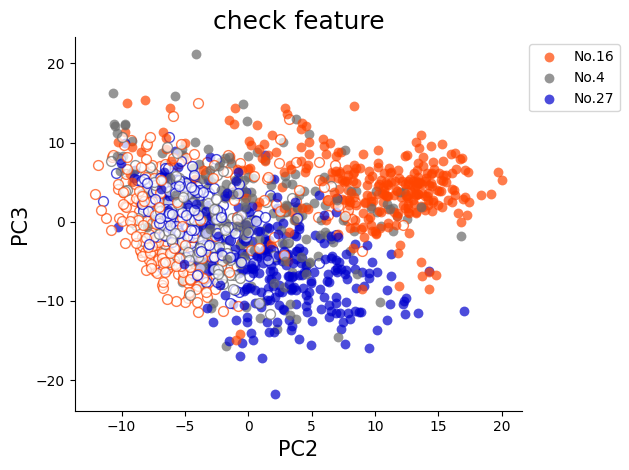

In [ ]:
loc_lst_l4 = PCAplot_v3(feature_pca, pca_inf, bach_dict, xnum=1, ynum=2, sample=1500, pict_sample=0, seed1=24771, title="check feature")

In [ ]:
# 第一主成分と第二主成分でプロットする
def PCAplot_v3_anomal(feature, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, pict_sample=6, seed1=2477, seed2=2477, title=""):
    fig, ax = plt.subplots()
    label_lst = []
    ap = label_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    n = 0
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature)), sample)
    random.seed(seed2)
    random.shuffle(ran_sam)
    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if pca_inf[i][0] not in label_lst:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0,
                    label="No."+str(pca_inf[i][0]), zorder=1
                    )
                ap(pca_inf[i][0])

            elif pca_inf[i][0] == 4 and label_lst.count(4) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(4)-1), weight="bold"
                )
                ap_loc([label_lst.count(4)-1, pca_inf[i][1], pca_inf[i][0]])


            elif pca_inf[i][0] == 16 and label_lst.count(16) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(16)-1+pict_sample), weight="bold"
                )
                ap_loc([label_lst.count(16)-1+pict_sample, pca_inf[i][1], pca_inf[i][0]])

            elif pca_inf[i][0] == 27 and label_lst.count(27) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(27)-1+pict_sample*2), weight="bold"
                )
                ap_loc([label_lst.count(27)-1+pict_sample*2, pca_inf[i][1], pca_inf[i][0]])
            
            else:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0, zorder=1
                    )
        else:
            pass

    ax.set_title(title, fontsize=18)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()
    
    return loc_lst

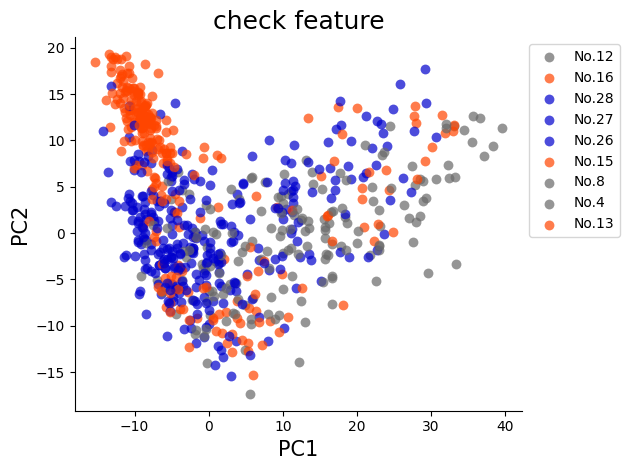

In [82]:
loc_lst_l4 = PCAplot_v3_anomal(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=1500, pict_sample=0, seed1=24771, title="check feature")

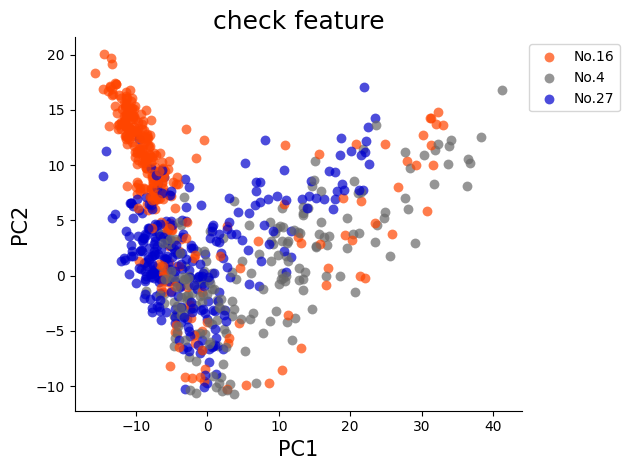

In [ ]:
loc_lst_l4 = PCAplot_v3_anomal(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=1500, pict_sample=0, seed1=24771, title="check feature")

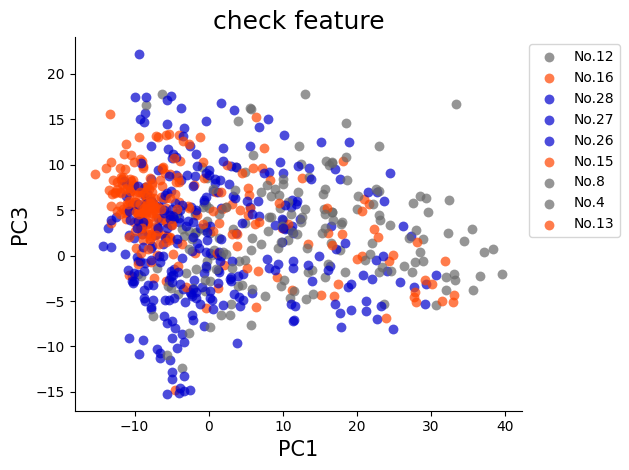

In [84]:
loc_lst_l4 = PCAplot_v3_anomal(feature_pca, pca_inf, bach_dict, xnum=0, ynum=2, sample=1500, pict_sample=0, seed1=24771, title="check feature")

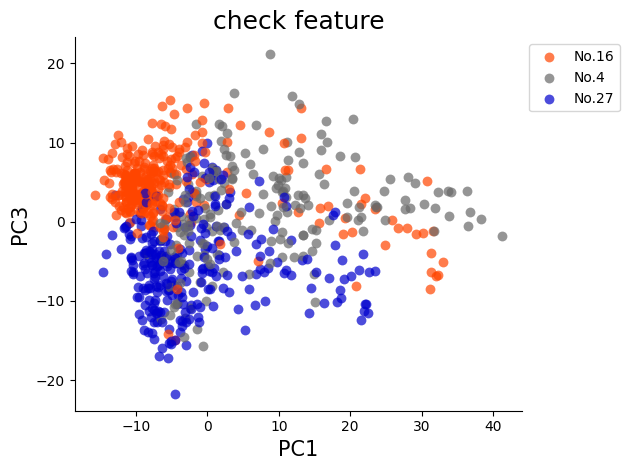

In [ ]:
loc_lst_l4 = PCAplot_v3_anomal(feature_pca, pca_inf, bach_dict, xnum=0, ynum=2, sample=1500, pict_sample=0, seed1=24771, title="check feature")

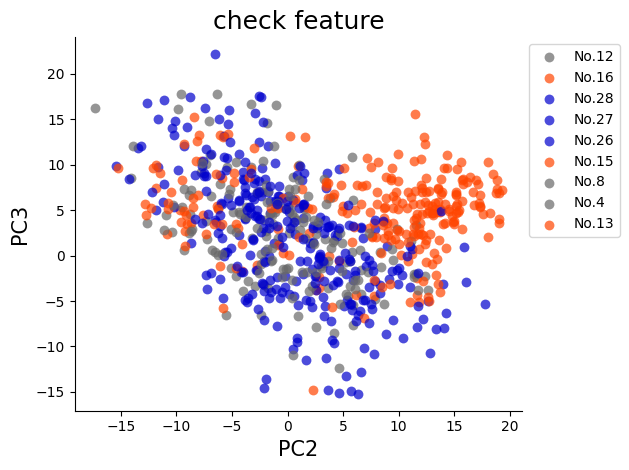

In [85]:
loc_lst_l4 = PCAplot_v3_anomal(feature_pca, pca_inf, bach_dict, xnum=1, ynum=2, sample=1500, pict_sample=0, seed1=24771, title="check feature")

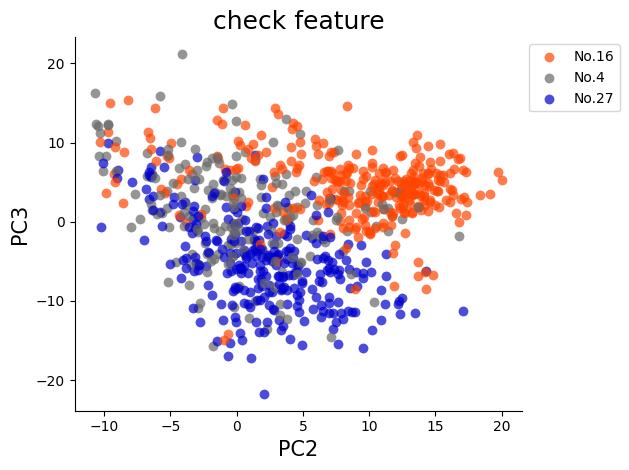

In [ ]:
loc_lst_l4 = PCAplot_v3_anomal(feature_pca, pca_inf, bach_dict, xnum=1, ynum=2, sample=1500, pict_sample=0, seed1=24771, title="check feature")

sample No.4
13831
1304
Percentage of abnormal patches : 0.09428096305400911
0.6581990521327014


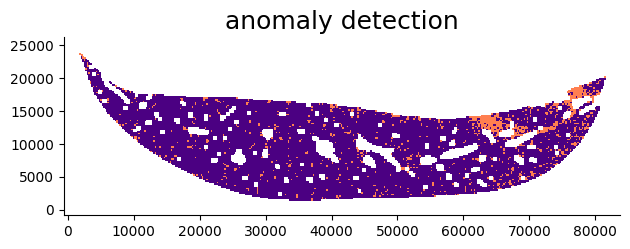

sample No.8
13199
1004
Percentage of abnormal patches : 0.07606636866429276
0.6652615443571566


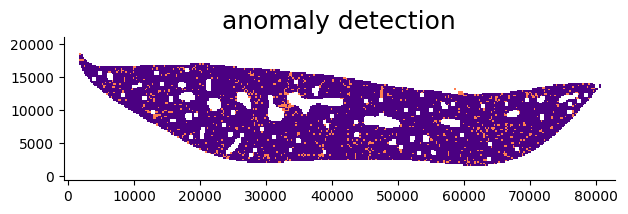

sample No.12
12345
883
Percentage of abnormal patches : 0.07152693398136897
0.79287508563599


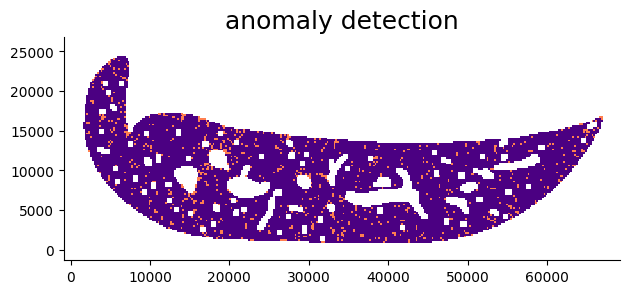

sample No.13
10641
1559
Percentage of abnormal patches : 0.1465087867681609
0.6873886359136804


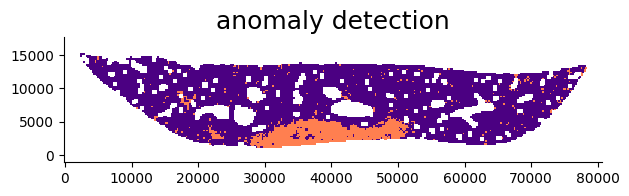

sample No.15
12151
1640
Percentage of abnormal patches : 0.13496831536499054
0.6706586826347306


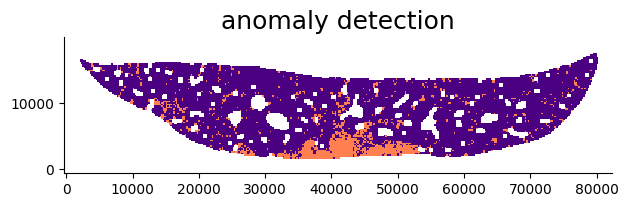

sample No.16
12773
2232
Percentage of abnormal patches : 0.1747435997807876
0.614187157261631


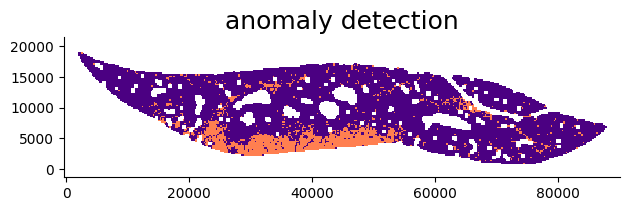

sample No.26
11162
1658
Percentage of abnormal patches : 0.14853968822791613
0.7612365709274281


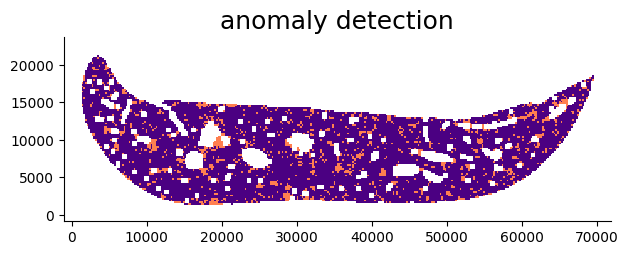

sample No.27
9665
1749
Percentage of abnormal patches : 0.1809622348680807
0.7234840591789956


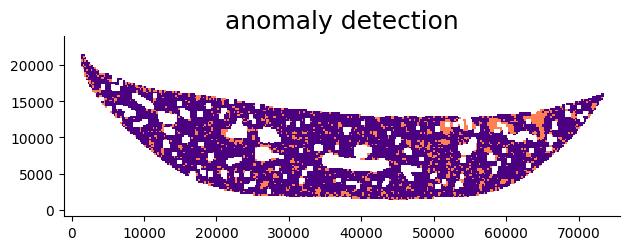

sample No.28
12041
1389
Percentage of abnormal patches : 0.11535586745286937
0.7341932755339395


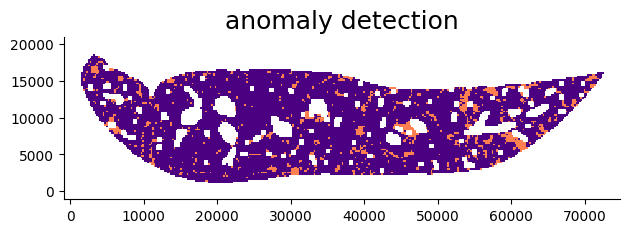

In [83]:
# get_maskの学習でmask_insideを判定する
total_inf_lst = []
for i in [4, 8, 12, 13, 15, 16, 26, 27, 28]:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    #feature_inf_lst = get_info(i, feature_scaled, location, jud)
    #total_inf_lst = total_inf_lst + feature_inf_lst
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

sample No.4
16343
1439
Percentage of abnormal patches : 0.08804992963348222
max_n =  1439
0.6529998119240172


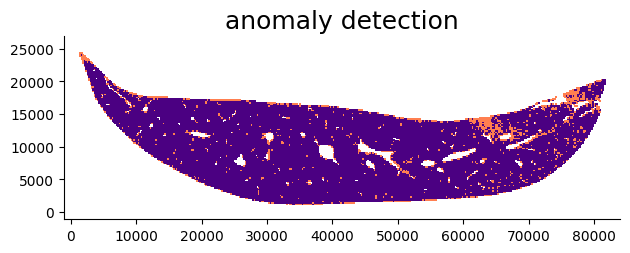

sample No.8
15325
967
Percentage of abnormal patches : 0.06309951060358891
max_n =  967
0.6581990521327014


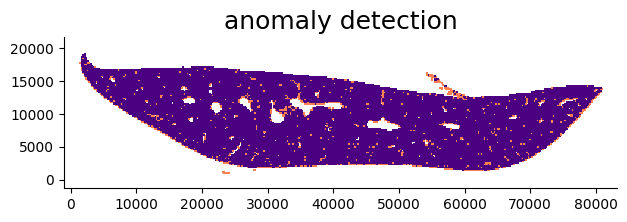

sample No.12
14379
1063
Percentage of abnormal patches : 0.07392725502468878
max_n =  1063
0.787837531200363


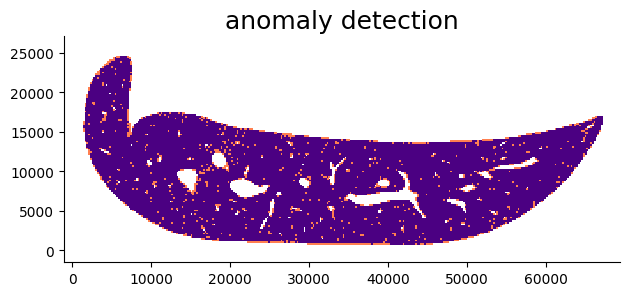

sample No.17
14667
984
Percentage of abnormal patches : 0.06708938433217426
max_n =  984
0.7589071038251366


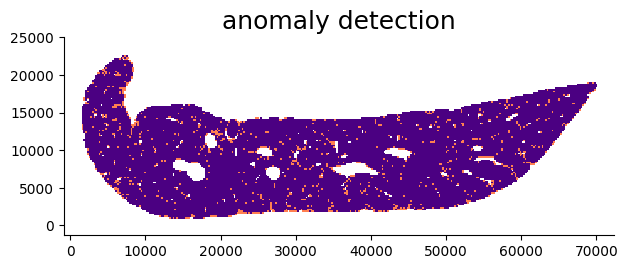

sample No.18
11627
723
Percentage of abnormal patches : 0.06218285026232046
max_n =  723
0.849938800489596


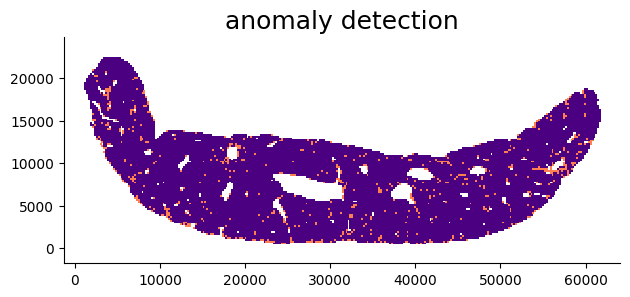

sample No.19
14369
862
Percentage of abnormal patches : 0.059990256802839446
max_n =  862
0.6892991860234267


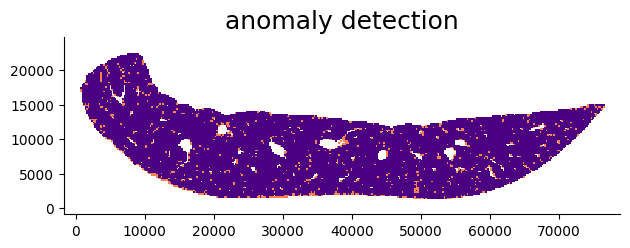

sample No.30
14594
1940
Percentage of abnormal patches : 0.1329313416472523
max_n =  1940
0.6688499325756116


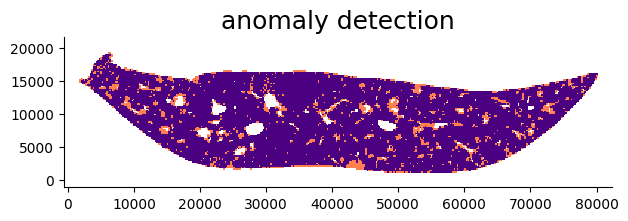

sample No.31
16840
1915
Percentage of abnormal patches : 0.11371733966745844
max_n =  1915
0.6873886359136804


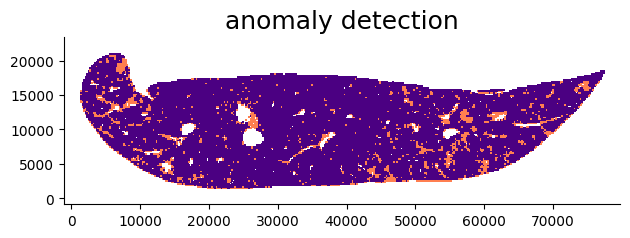

sample No.32
15020
1896
Percentage of abnormal patches : 0.12623169107856191
max_n =  1896
0.7213795969249948


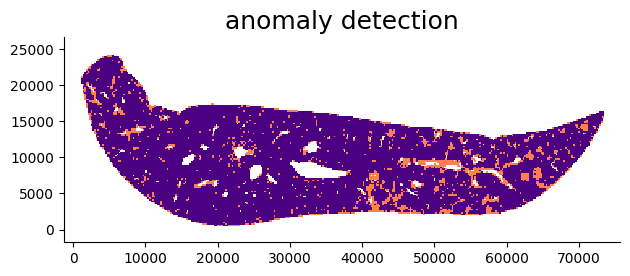

In [86]:
total_inf_lst = []
for i in [4, 8, 12, 17, 18, 19, 30, 31, 32]:
    f_path = "workspace/result_v4/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

In [87]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]
bach_dict = {4:"dimgray", 8:"dimgray", 12:"dimgray", 17:"orangered", 18:"orangered", 19:"orangered", 30:"mediumblue", 31:"mediumblue", 32:"mediumblue"}

In [91]:
# 第一主成分と第二主成分でプロットする
def PCAplot_v3(feature, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, pict_sample=6, seed1=2477, seed2=2477, title=""):
    fig, ax = plt.subplots()
    label_lst = []
    ap = label_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    n = 0
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature)), sample)
    random.seed(seed2)
    random.shuffle(ran_sam)
    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if pca_inf[i][0] not in label_lst:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0,
                    label="No."+str(pca_inf[i][0]), zorder=1
                    )
                ap(pca_inf[i][0])

            elif (pca_inf[i][0] == 4 or pca_inf[i][0] == 8 or pca_inf[i][0] == 12) and label_lst.count(4) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(4)-1), weight="bold"
                )
                ap_loc([label_lst.count(4)-1, pca_inf[i][1], pca_inf[i][0]])


            elif (pca_inf[i][0] == 17 or pca_inf[i][0] == 18 or pca_inf[i][0] == 19) and label_lst.count(17) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(16)-1+pict_sample), weight="bold"
                )
                ap_loc([label_lst.count(16)-1+pict_sample, pca_inf[i][1], pca_inf[i][0]])

            elif (pca_inf[i][0] == 30 or pca_inf[i][0] == 31 or pca_inf[i][0] == 32) and label_lst.count(30) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(27)-1+pict_sample*2), weight="bold"
                )
                ap_loc([label_lst.count(27)-1+pict_sample*2, pca_inf[i][1], pca_inf[i][0]])
            
            else:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0, zorder=1
                    )
        else:
            ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color="white", linewidth=1, ec=bach_dict[pca_inf[i][0]], zorder=1
                    )

    ax.set_title(title, fontsize=18)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()
    
    return loc_lst

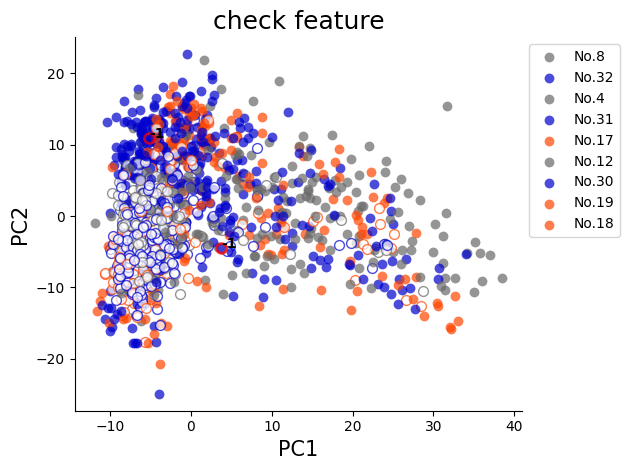

In [92]:
loc_lst_l4 = PCAplot_v3(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=1500, pict_sample=0, seed1=24771, title="check feature")

#### get_mask & layer4 & validation ####

In [18]:
f_path_1 = "workspace/result_v4/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v4/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_4 = "workspace/result_v4/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v4/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v4/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_8 = "workspace/result_v4/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v4/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v4/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_12 = "workspace/result_v4/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1) + list(feature_2) + list(feature_4)+ list(feature_5)+ list(feature_6)+ list(feature_8)+ list(feature_9)+ list(feature_10)+ list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [19]:
def get_info(sample_id, feature, location, jud):
    inf_lst = []
    max_n = len([i for i in jud if i == -1])
    print("max_n = ", str(max_n))
    n = 0
    ap = inf_lst.append
    for i in zip(jud, feature, location):
        if i[0] == -1:
            ap([sample_id, i[1], i[2], i[0]])
        elif i[0] == 1 and n < max_n:
            ap([sample_id, i[1], i[2], i[0]])
            n = n + 1
        else:
            pass

    return inf_lst

In [20]:
def loc_plot(location, jud, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    print(size)
    if size < 1:
        size = 1

    for i in zip(jud, location):
        if i[0] == -1:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=0.3, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="lightgray", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

sample No.3
13915
924
Percentage of abnormal patches : 0.06640316205533597
max_n =  924
0.8708301981439679


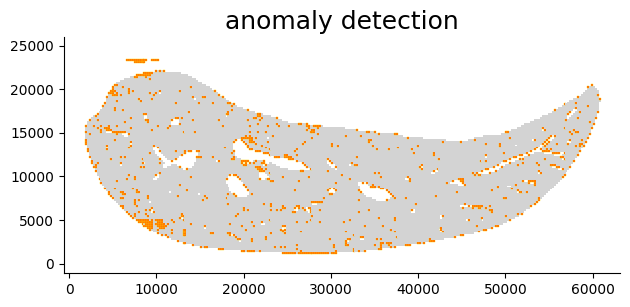

In [21]:
total_inf_lst = []
for i in [3]:
    f_path = "workspace/result_v4/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

sample No.3
13915
924
Percentage of abnormal patches : 0.06640316205533597
max_n =  924
0.8708301981439679


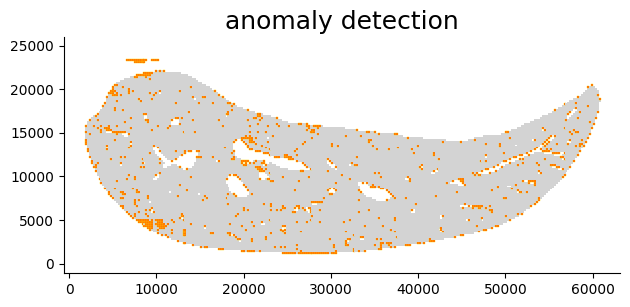

sample No.7
12456
907
Percentage of abnormal patches : 0.07281631342324985
max_n =  907
0.7130827685356336


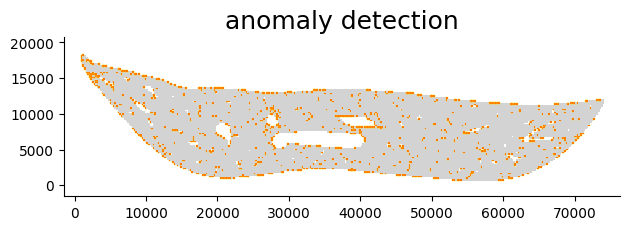

sample No.11
11857
818
Percentage of abnormal patches : 0.0689887829973855
max_n =  818
0.8110254613408082


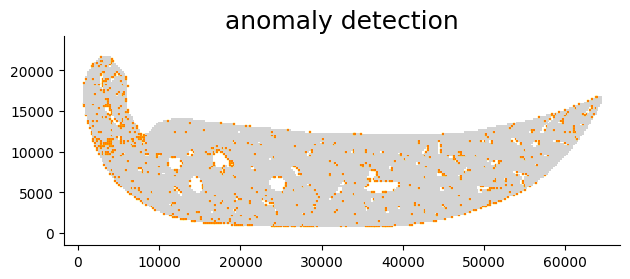

sample No.13
13021
1598
Percentage of abnormal patches : 0.12272482912218724
max_n =  1598
0.6835991336877338


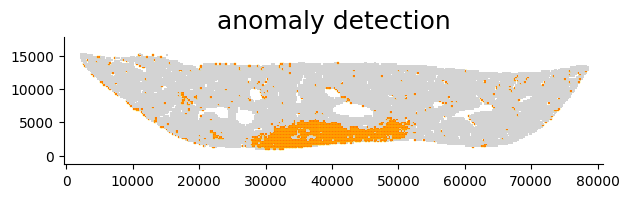

sample No.15
14528
1539
Percentage of abnormal patches : 0.10593337004405286
max_n =  1539
0.6670509125840538


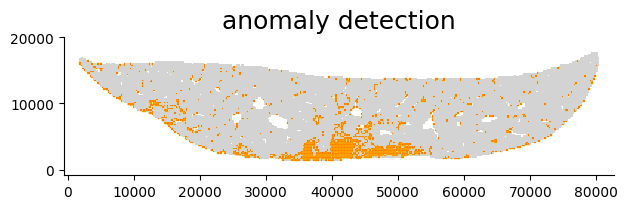

sample No.16
15423
2224
Percentage of abnormal patches : 0.1442002204499773
max_n =  2224
0.6096575943810361


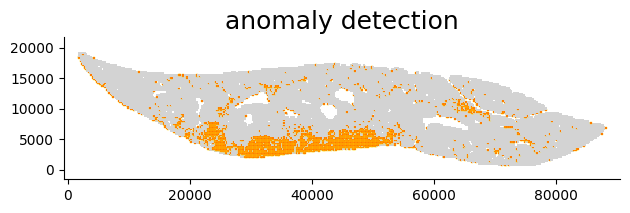

sample No.26
13331
1925
Percentage of abnormal patches : 0.14440027004725828
max_n =  1925
0.7565918500762694


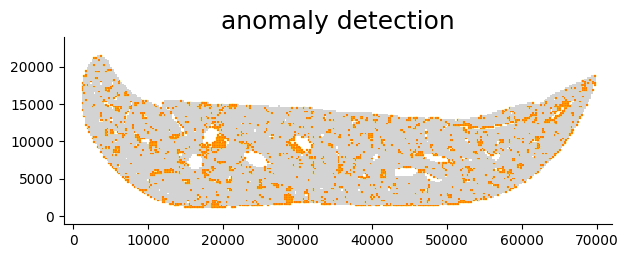

sample No.27
11821
2079
Percentage of abnormal patches : 0.17587344556298112
max_n =  2079
0.7172071885973972


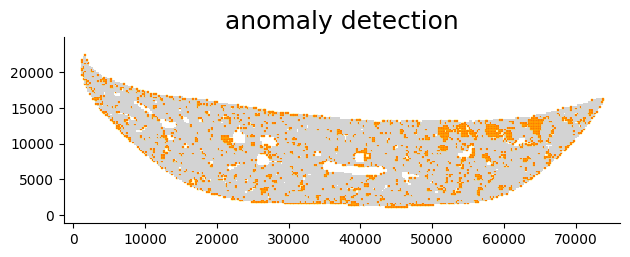

sample No.28
14136
1636
Percentage of abnormal patches : 0.11573288058856819
max_n =  1636
0.7277300356319429


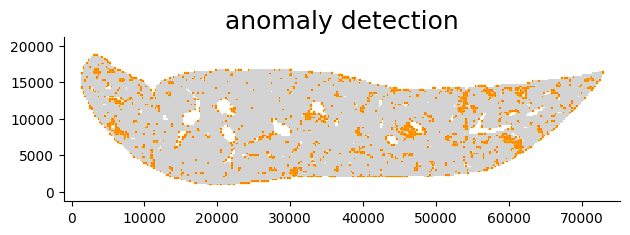

In [13]:
total_inf_lst = []
for i in [3, 7, 11, 13, 15, 16, 26, 27, 28]:
    f_path = "workspace/result_v4/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

In [14]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]
bach_dict = {3:"dimgray", 7:"dimgray", 11:"dimgray", 13:"orangered", 15:"orangered", 16:"orangered", 26:"mediumblue", 27:"mediumblue", 28:"mediumblue"}

In [25]:
# 第一主成分と第二主成分でプロットする
def PCAplot_v3(feature, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, pict_sample=6, seed1=2477, seed2=2477, title=""):
    fig, ax = plt.subplots()
    label_lst = []
    ap = label_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    n = 0
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature)), sample)
    random.seed(seed2)
    random.shuffle(ran_sam)
    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if pca_inf[i][0] not in label_lst:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0,
                    label="No."+str(pca_inf[i][0]), zorder=1
                    )
                ap(pca_inf[i][0])

            elif (pca_inf[i][0] == 4 or pca_inf[i][0] == 8 or pca_inf[i][0] == 12) and label_lst.count(4) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(4)-1), weight="bold"
                )
                ap_loc([label_lst.count(4)-1, pca_inf[i][1], pca_inf[i][0]])


            elif (pca_inf[i][0] == 17 or pca_inf[i][0] == 18 or pca_inf[i][0] == 19) and label_lst.count(17) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(16)-1+pict_sample), weight="bold"
                )
                ap_loc([label_lst.count(16)-1+pict_sample, pca_inf[i][1], pca_inf[i][0]])

            elif (pca_inf[i][0] == 30 or pca_inf[i][0] == 31 or pca_inf[i][0] == 32) and label_lst.count(30) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(27)-1+pict_sample*2), weight="bold"
                )
                ap_loc([label_lst.count(27)-1+pict_sample*2, pca_inf[i][1], pca_inf[i][0]])
            
            else:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0, zorder=1
                    )
        else:
            ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color="white", linewidth=1, ec=bach_dict[pca_inf[i][0]], zorder=1
                    )

    ax.set_title(title, fontsize=18)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()
    
    return loc_lst

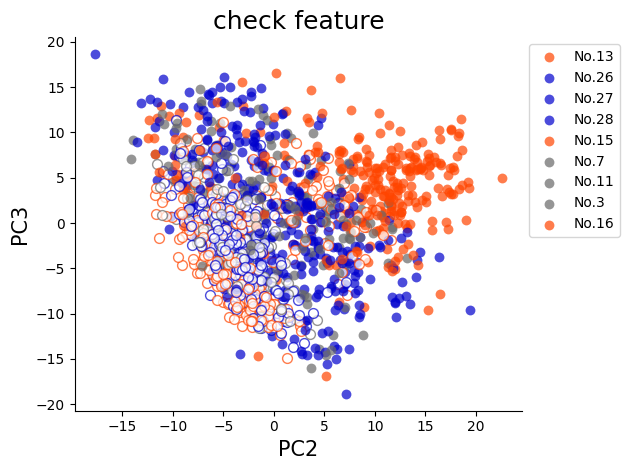

In [18]:
loc_lst_l4 = PCAplot_v3(feature_pca, pca_inf, bach_dict, xnum=1, ynum=2, sample=1500, pict_sample=0, seed1=24771, title="check feature")

In [19]:
# 第一主成分と第二主成分でプロットする
def PCAplot_v3_anomal(feature, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, pict_sample=6, seed1=2477, seed2=2477, title=""):
    fig, ax = plt.subplots()
    label_lst = []
    ap = label_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    n = 0
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature)), sample)
    random.seed(seed2)
    random.shuffle(ran_sam)
    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if pca_inf[i][0] not in label_lst:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0,
                    label="No."+str(pca_inf[i][0]), zorder=1
                    )
                ap(pca_inf[i][0])

            elif pca_inf[i][0] == 4 and label_lst.count(4) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(4)-1), weight="bold"
                )
                ap_loc([label_lst.count(4)-1, pca_inf[i][1], pca_inf[i][0]])


            elif pca_inf[i][0] == 16 and label_lst.count(16) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(16)-1+pict_sample), weight="bold"
                )
                ap_loc([label_lst.count(16)-1+pict_sample, pca_inf[i][1], pca_inf[i][0]])

            elif pca_inf[i][0] == 27 and label_lst.count(27) < pict_sample+1:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=2, ec="red", zorder=2
                    )
                ap(pca_inf[i][0])
                ax.text(
                    feature[:, xnum][i], feature[:, ynum][i],
                    s = str(label_lst.count(27)-1+pict_sample*2), weight="bold"
                )
                ap_loc([label_lst.count(27)-1+pict_sample*2, pca_inf[i][1], pca_inf[i][0]])
            
            else:
                ax.scatter(
                    feature[:, xnum][i], feature[:, ynum][i], 
                    alpha=0.7, s=50, 
                    color=bach_dict[pca_inf[i][0]], linewidth=0, zorder=1
                    )
        else:
            pass

    ax.set_title(title, fontsize=18)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()
    
    return loc_lst

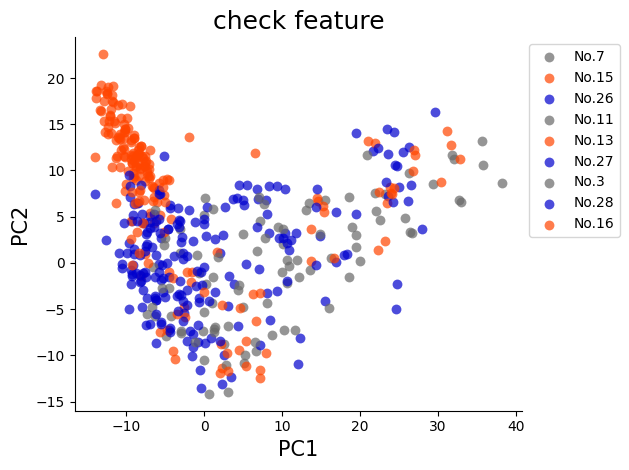

In [26]:
loc_lst_l4 = PCAplot_v3_anomal(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=1000, pict_sample=0, seed1=24771, title="check feature")

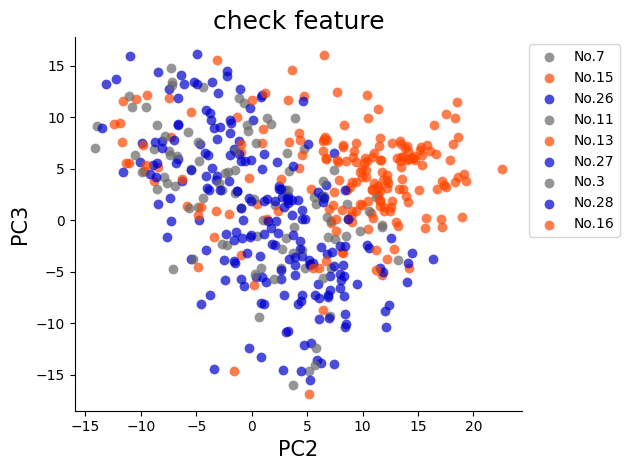

In [25]:
loc_lst_l4 = PCAplot_v3_anomal(feature_pca, pca_inf, bach_dict, xnum=1, ynum=2, sample=1000, pict_sample=0, seed1=24771, title="check feature")

In [ ]:
[3, 7, 11, 17, 18, 19, 29, 30, 31]

sample No.3
13915
924
Percentage of abnormal patches : 0.06640316205533597
max_n =  924
0.8708301981439679


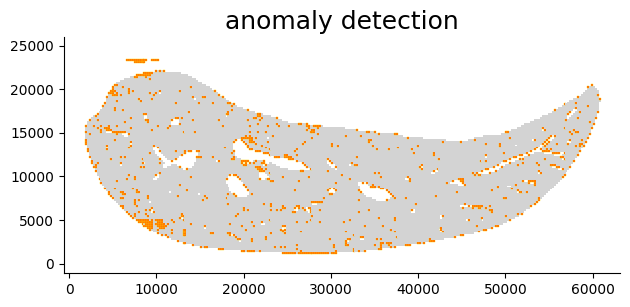

sample No.7
12456
907
Percentage of abnormal patches : 0.07281631342324985
max_n =  907
0.7130827685356336


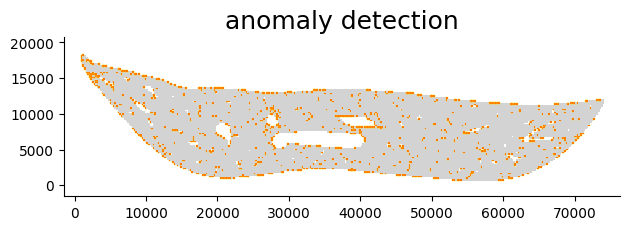

sample No.11
11857
818
Percentage of abnormal patches : 0.0689887829973855
max_n =  818
0.8110254613408082


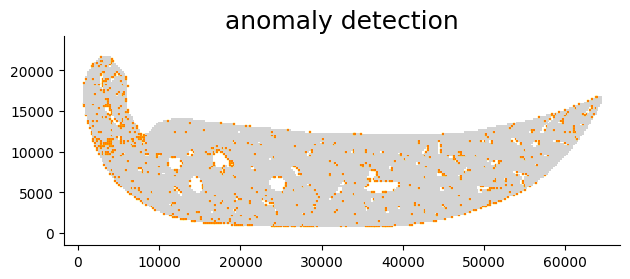

sample No.17
14727
924
Percentage of abnormal patches : 0.06274190262782645
max_n =  924
0.7589071038251366


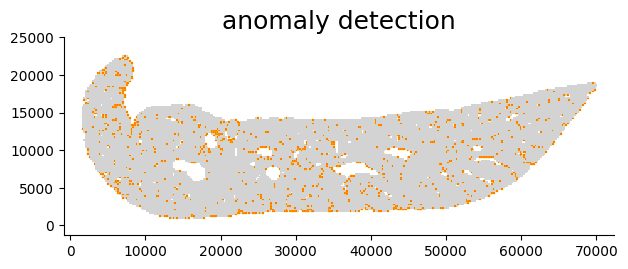

sample No.18
11660
690
Percentage of abnormal patches : 0.05917667238421955
max_n =  690
0.849938800489596


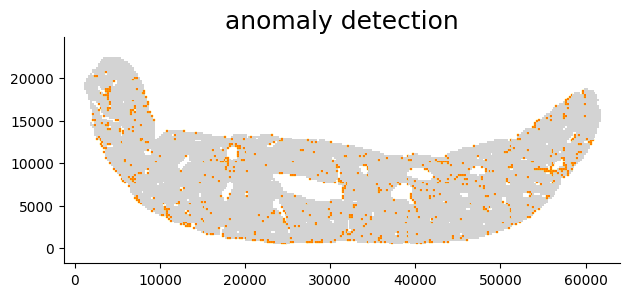

sample No.19
14416
815
Percentage of abnormal patches : 0.056534406215316316
max_n =  815
0.6892991860234267


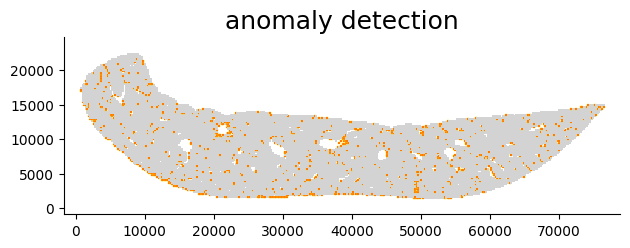

sample No.29
15347
1827
Percentage of abnormal patches : 0.11904606763536847
max_n =  1827
0.7049746192893401


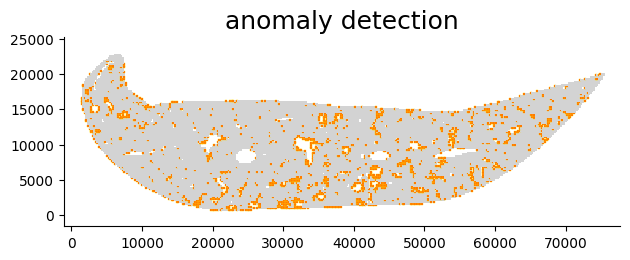

sample No.30
14681
1853
Percentage of abnormal patches : 0.126217560111709
max_n =  1853
0.6688499325756116


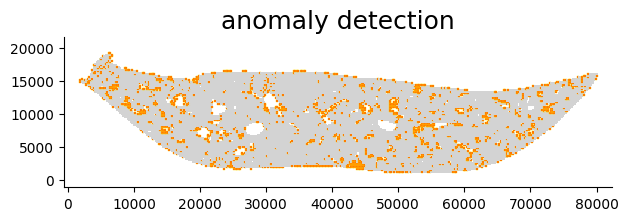

sample No.31
16905
1850
Percentage of abnormal patches : 0.10943507837917776
max_n =  1850
0.6873886359136804


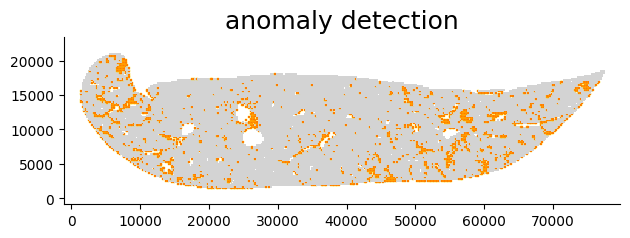

In [22]:
total_inf_lst = []
for i in [3, 7, 11, 17, 18, 19, 29, 30, 31]:
    f_path = "workspace/result_v4/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

In [24]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]
bach_dict = {3:"dimgray", 7:"dimgray", 11:"dimgray", 17:"orangered", 18:"orangered", 19:"orangered", 29:"mediumblue", 30:"mediumblue", 31:"mediumblue"}

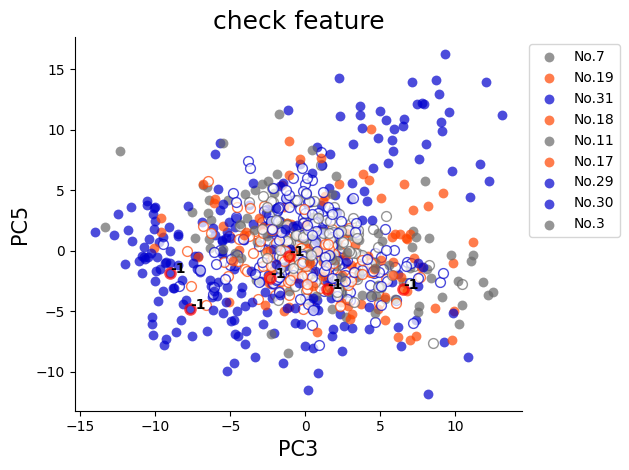

In [32]:
loc_lst_l4 = PCAplot_v3(feature_pca, pca_inf, bach_dict, xnum=2, ynum=4, sample=900, pict_sample=0, seed1=24771, title="check feature")

In [54]:
bach_dict = {}
comp_lst = ["Control"]*12+["TAA"]*12+["MDA"]*12
for i in range(36):
    bach_dict[i+1] = comp_lst[i]

In [35]:
sample=100
seed1=2477
random.seed(seed1)
ran_sam = random.sample(range(len(feature_pca)), sample)

In [37]:
ran_sam[0:5]

[7547, 14281, 12777, 20897, 21186]

In [57]:
i = 0
color_dict = {"Control":"dimgray","TAA":"orangered", "TAA":"mediumblue"}
color_dict[bach_dict[pca_inf[i][0]]]

'dimgray'

In [71]:
# 第一主成分と第二主成分でプロットする
def PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, pict_sample=6, seed1=2477, seed2=2477, title=""):
    fig = plt.figure(figsize=(13, 4))
    ax1 = fig.add_subplot(1, 3, 1)
    ax2 = fig.add_subplot(1, 3, 2)
    ax3 = fig.add_subplot(1, 3, 3)
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature)), sample)

    color_dict = {"Control":"dimgray","TAA":"orangered", "MDA":"mediumblue"}

    xmax = max(feature_pca[:, xnum])
    xmin = min(feature_pca[:, xnum])
    ymax = max(feature_pca[:, ynum])
    ymin = min(feature_pca[:, ynum])

    for i in ran_sam:
        if pca_inf[i][2] == -1:
            ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
            ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
        else:
            ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])
            ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])

    for ax in [ax1, ax2, ax3]:
        ax.set_title(title, fontsize=18)

        ax.set_xlim(xmin,xmax)
        ax.set_ylim(ymin,ymax)

        ax.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        ax.spines.bottom.set_color('black')
        ax.spines.left.set_color('black')
    ax2.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax1.set_ylabel("PC"+str(ynum+1), fontsize=15)

    fig.suptitle("PCA", fontsize=18)

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

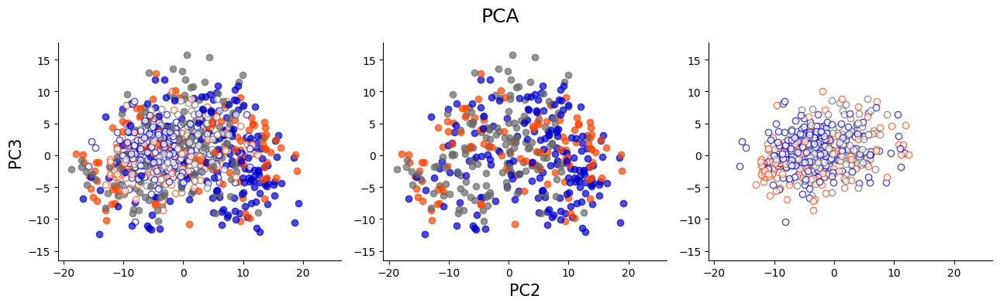

In [72]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=1, ynum=2, sample=900, pict_sample=6, seed1=2477, seed2=2477, title="")

#### PCA plot ####

##### 1st try #####

In [ ]:
f_path_1 = "workspace/result_v4/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v4/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_4 = "workspace/result_v4/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v4/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v4/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_8 = "workspace/result_v4/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v4/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v4/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_12 = "workspace/result_v4/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1) + list(feature_2) + list(feature_4)+ list(feature_5)+ list(feature_6)+ list(feature_8)+ list(feature_9)+ list(feature_10)+ list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [21]:
# 第一主成分と第二主成分でプロットする
def PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=100, seed1=2477, title=""):
    fig = plt.figure(figsize=(13, 4))
    ax1 = fig.add_subplot(1, 3, 1)
    ax2 = fig.add_subplot(1, 3, 2)
    ax3 = fig.add_subplot(1, 3, 3)
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature_pca)), sample)

    color_dict = {"Control":"dimgray","TAA":"orangered", "MDA":"mediumblue"}

    xmax = max(feature_pca[:, xnum])
    xmin = min(feature_pca[:, xnum])
    ymax = max(feature_pca[:, ynum])
    ymin = min(feature_pca[:, ynum])

    for i in ran_sam:
        if pca_inf[i][2] == -1:
            ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
            ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
        else:
            ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])
            ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])

    for ax in [ax1, ax2, ax3]:
        #ax.set_title("", fontsize=18)

        ax.set_xlim(xmin,xmax)
        ax.set_ylim(ymin,ymax)

        ax.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        ax.spines.bottom.set_color('black')
        ax.spines.left.set_color('black')
    ax2.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax1.set_ylabel("PC"+str(ynum+1), fontsize=15)

    fig.suptitle(title, fontsize=18)

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

In [22]:
bach_dict = {}
comp_lst = ["Control"]*12+["TAA"]*12+["MDA"]*12
for i in range(36):
    bach_dict[i+1] = comp_lst[i]
bach_dict[24] = "MDA"
bach_dict[25] = "TAA"

##### day7 #####

In [73]:
total_inf_lst = []
for i in [3, 7, 11, 13, 15, 16, 26, 27, 28]:
    f_path = "workspace/result_v4/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.3
13915
924
Percentage of abnormal patches : 0.06640316205533597
max_n =  924
sample No.7
12456
907
Percentage of abnormal patches : 0.07281631342324985
max_n =  907
sample No.11
11857
818
Percentage of abnormal patches : 0.0689887829973855
max_n =  818
sample No.13
13021
1598
Percentage of abnormal patches : 0.12272482912218724
max_n =  1598
sample No.15
14528
1539
Percentage of abnormal patches : 0.10593337004405286
max_n =  1539
sample No.16
15423
2224
Percentage of abnormal patches : 0.1442002204499773
max_n =  2224
sample No.26
13331
1925
Percentage of abnormal patches : 0.14440027004725828
max_n =  1925
sample No.27
11821
2079
Percentage of abnormal patches : 0.17587344556298112
max_n =  2079
sample No.28
14136
1636
Percentage of abnormal patches : 0.11573288058856819
max_n =  1636


In [74]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

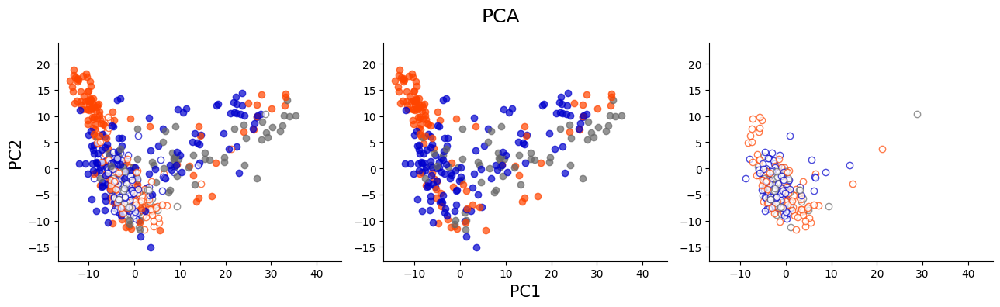

In [87]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=0, seed1=247, seed2=2477, title="")

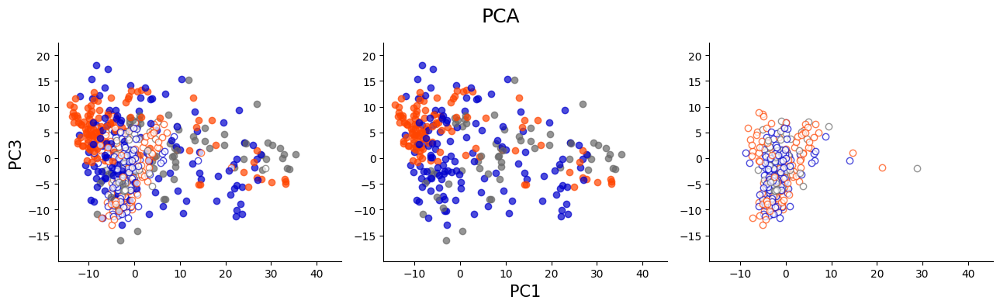

In [90]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=2, sample=600, pict_sample=0, seed1=247, seed2=2477, title="")

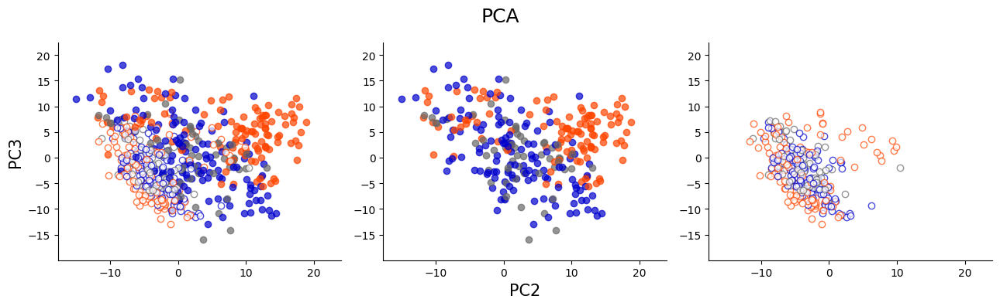

In [91]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=1, ynum=2, sample=600, pict_sample=0, seed1=247, seed2=2477, title="")

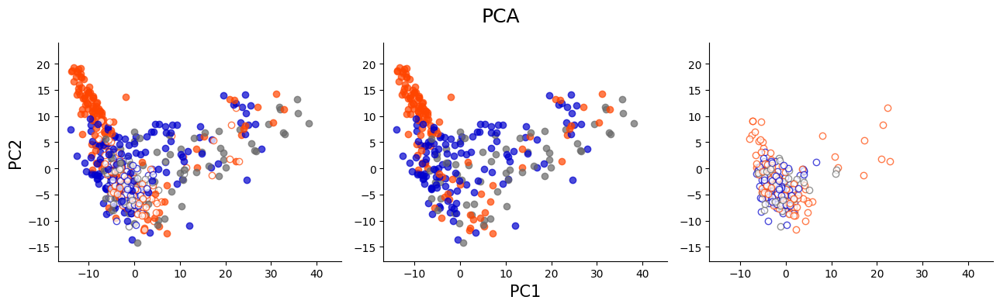

In [88]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=0, seed1=24771, seed2=2477, title="")

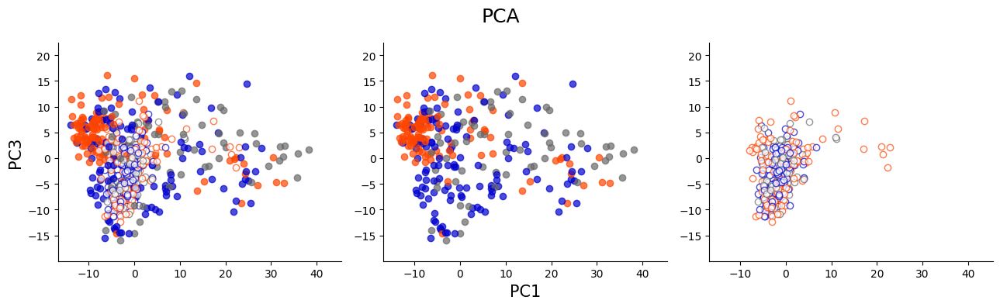

In [92]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=2, sample=600, pict_sample=0, seed1=24771, seed2=2477, title="")

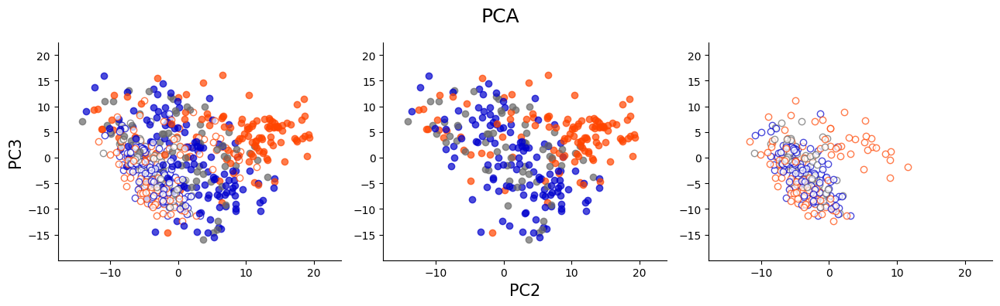

In [93]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=1, ynum=2, sample=600, pict_sample=0, seed1=24771, seed2=2477, title="")

##### day14 #####

In [94]:
total_inf_lst = []
for i in [3, 7, 11, 17, 18, 19, 29, 30, 31]:
    f_path = "workspace/result_v4/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.3
13915
924
Percentage of abnormal patches : 0.06640316205533597
max_n =  924
sample No.7
12456
907
Percentage of abnormal patches : 0.07281631342324985
max_n =  907
sample No.11
11857
818
Percentage of abnormal patches : 0.0689887829973855
max_n =  818
sample No.17
14727
924
Percentage of abnormal patches : 0.06274190262782645
max_n =  924
sample No.18
11660
690
Percentage of abnormal patches : 0.05917667238421955
max_n =  690
sample No.19
14416
815
Percentage of abnormal patches : 0.056534406215316316
max_n =  815
sample No.29
15347
1827
Percentage of abnormal patches : 0.11904606763536847
max_n =  1827
sample No.30
14681
1853
Percentage of abnormal patches : 0.126217560111709
max_n =  1853
sample No.31
16905
1850
Percentage of abnormal patches : 0.10943507837917776
max_n =  1850


In [95]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

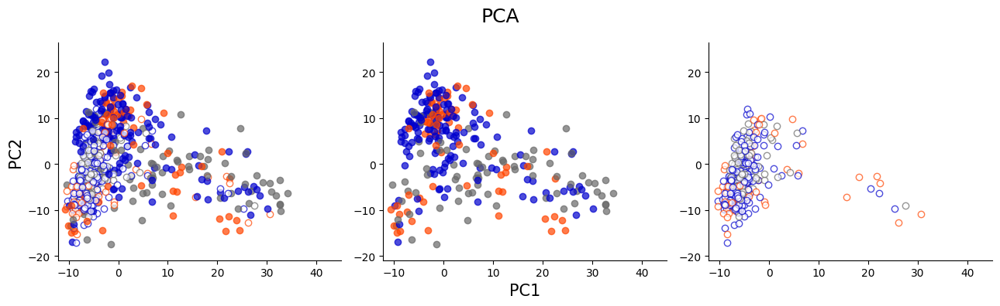

In [96]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=0, seed1=247, seed2=2477, title="")

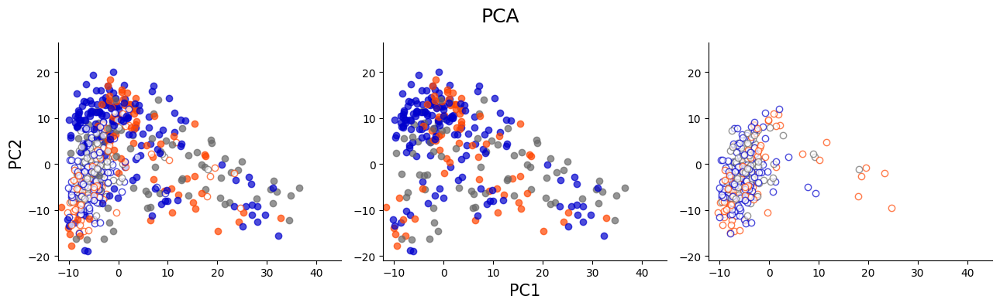

In [99]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=0, seed1=24771, seed2=2477, title="")

##### check anomal pach raito #####

In [100]:
bach_dict = {}
comp_lst = ["Control"]*12+["TAA"]*12+["MDA"]*12
for i in range(36):
    bach_dict[i+1] = comp_lst[i]

In [106]:
day_dict = {}
day_lst = [7]*4+[14]*4+[28]*4
day_lst = day_lst*3
for i in range(36):
    day_dict[i+1] = day_lst[i]

In [108]:
inf_dict = {}
percentage_lst = []
ap = percentage_lst.append
sample_n = [3, 7, 11, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
for i in sample_n:
    f_path = "workspace/result_v4/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    ap(len([i for i in jud if i == -1])/len([i for i in jud if i == 1]))
inf_dict["compound"] = [bach_dict[i] for i in sample_n]
inf_dict["day"] = [day_dict[i] for i in sample_n]
inf_dict["percentage"] = percentage_lst

sample No.3
13915
924
Percentage of abnormal patches : 0.06640316205533597
sample No.7
12456
907
Percentage of abnormal patches : 0.07281631342324985
sample No.11
11857
818
Percentage of abnormal patches : 0.0689887829973855
sample No.13
13021
1598
Percentage of abnormal patches : 0.12272482912218724
sample No.14
16199
1452
Percentage of abnormal patches : 0.089635162664362
sample No.15
14528
1539
Percentage of abnormal patches : 0.10593337004405286
sample No.16
15423
2224
Percentage of abnormal patches : 0.1442002204499773
sample No.17
14727
924
Percentage of abnormal patches : 0.06274190262782645
sample No.18
11660
690
Percentage of abnormal patches : 0.05917667238421955
sample No.19
14416
815
Percentage of abnormal patches : 0.056534406215316316
sample No.21
10071
649
Percentage of abnormal patches : 0.06444245854433522
sample No.22
12581
755
Percentage of abnormal patches : 0.06001112789126461
sample No.23
14804
878
Percentage of abnormal patches : 0.05930829505539043
sample No.24


In [197]:
df_p = pd.DataFrame.from_dict(inf_dict)
df_p.index = sample_n
df_p

,compound,day,percentage
3,Control,7,0.066403
7,Control,14,0.072816
11,Control,28,0.068989
13,TAA,7,0.122725
14,TAA,7,0.089635
15,TAA,7,0.105933
16,TAA,7,0.144200
17,TAA,14,0.062742
18,TAA,14,0.059177
19,TAA,14,0.056534


In [199]:
taa = df_p.loc[24, "compound":"day"]
mda = df_p.loc[25, "compound":"day"]

In [200]:
df_p.loc[24, "compound":"day"] = mda
df_p.loc[25, "compound":"day"] = taa

In [201]:
df_p

,compound,day,percentage
3,Control,7,0.066403
7,Control,14,0.072816
11,Control,28,0.068989
13,TAA,7,0.122725
14,TAA,7,0.089635
15,TAA,7,0.105933
16,TAA,7,0.144200
17,TAA,14,0.062742
18,TAA,14,0.059177
19,TAA,14,0.056534


In [202]:
def ratio_plot(df_p, title="Abnormal Patch Ratio"):
    fig = plt.figure(figsize=(10, 7))
    y_max = max(df_p.loc[:, "percentage"])*1.1
    for i, d in enumerate([7, 14, 28]):
        df_p_day = df_p.loc[[df_p.loc[i, "day"] == d for i in df_p.index.tolist()], :]

        df_ctrl = df_p_day.loc[[df_p_day.loc[i, "compound"] == "Control" for i in df_p_day.index.tolist()], :]
        df_ctrl = df_ctrl.loc[:, ["percentage"]]
        df_mda = df_p_day.loc[[df_p_day.loc[i, "compound"] == "MDA" for i in df_p_day.index.tolist()], :]
        df_mda = df_mda.loc[:, ["percentage"]]
        df_taa = df_p_day.loc[[df_p_day.loc[i, "compound"] == "TAA" for i in df_p_day.index.tolist()], :]
        df_taa = df_taa.loc[:, ["percentage"]]

        ax = fig.add_subplot(1, 3, i+1)
        ax2 = ax.twinx()

        width = 0.25
        x_position = np.arange(1)
        error_bar_set = dict(lw = 1.5, capthick = 1.5, capsize = 4)
        ax.bar(x_position-width, df_ctrl.mean(), yerr=df_ctrl.std(), tick_label=df_ctrl.columns, error_kw=error_bar_set, color='gray', width=0.97*width, label="Ctrl", alpha=.8)
        ax.bar(x_position+width, df_mda.mean(), yerr=df_mda.std(), tick_label=df_ctrl.columns, error_kw=error_bar_set, color='royalblue', width=0.97*width, label="MDA", alpha=.8)
        ax.bar(x_position, df_taa.mean(), yerr=df_taa.std(), tick_label=df_ctrl.columns, error_kw=error_bar_set, color='coral', width=0.97*width, label="TAA", alpha=.8)

        ax.legend(fontsize=18, loc=(0.5, 0.82))
        plt.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        # jitter plot
        sns.stripplot(x='day', y='percentage', data=df_p_day, hue='compound', dodge=True, jitter=True, s=7, linewidth=1, edgecolor="black", palette=['black', 'orangered', 'mediumblue'], ax=ax2)
        # control line
        #ax.hlines(y=0.05, xmin=0, xmax=1, color="black", linestyles='dotted', alpha=.8, zorder=1)

        ax.tick_params(axis='x', labelsize=16, direction='in', width=0)
        ax.tick_params(axis='y', labelsize=16)

        ax.set_ylim(0,y_max)
        ax2.set_ylim(0,y_max)

        ax2.axis("off")
        ax2.get_legend().remove()

        if i == 0:
            ax.set_ylabel("raito", fontsize=20)
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()         
        elif i == len([7, 14, 28])-1:
            ax.set_xticklabels(["day"+str(d)])
        else:
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()  

    fig.suptitle(title, fontsize=24)
    plt.tight_layout()
    plt.show()

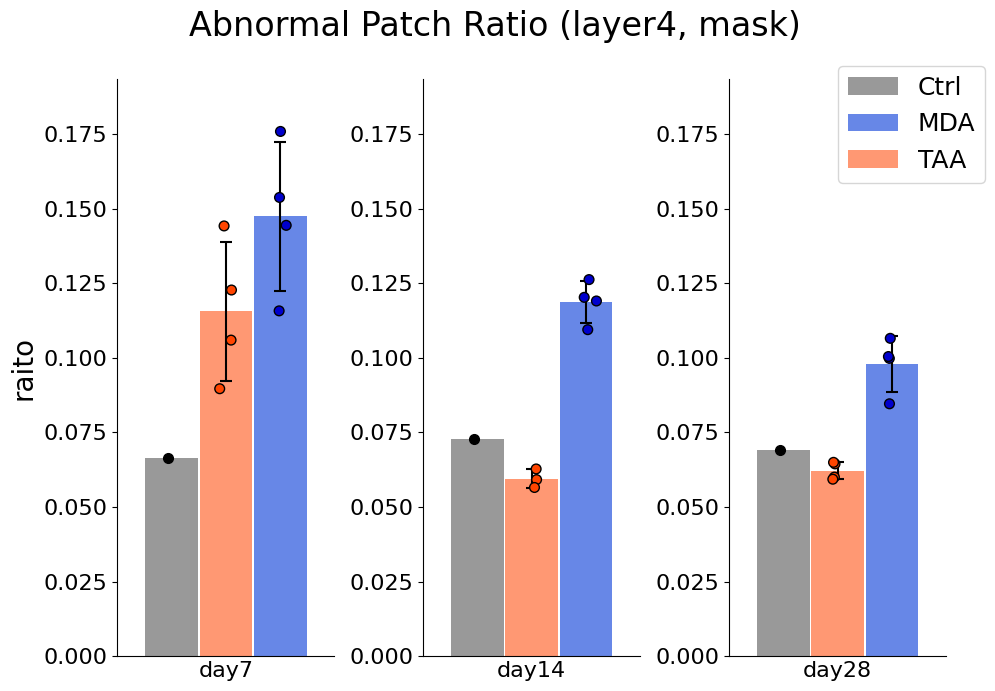

In [203]:
ratio_plot(df_p, title="Abnormal Patch Ratio (layer4, mask)")

sample No.3
13915
924
Percentage of abnormal patches : 0.06640316205533597
0.8708301981439679


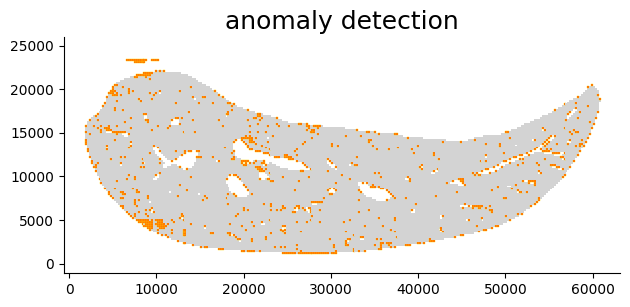

sample No.21
10071
649
Percentage of abnormal patches : 0.06444245854433522
0.7497300798963507


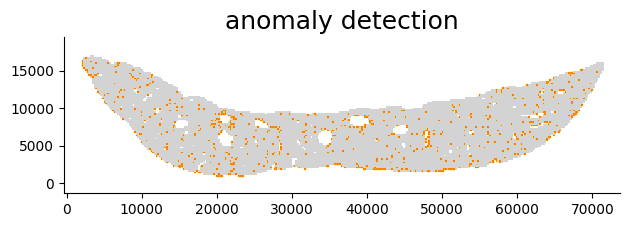

sample No.22
12581
755
Percentage of abnormal patches : 0.06001112789126461
0.7779520501904549


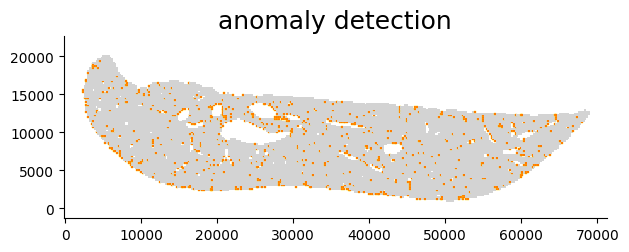

sample No.23
14804
878
Percentage of abnormal patches : 0.05930829505539043
0.6688499325756116


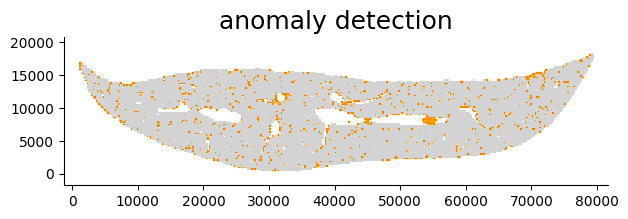

sample No.24
11837
1820
Percentage of abnormal patches : 0.1537551744529864
0.7542906799913099


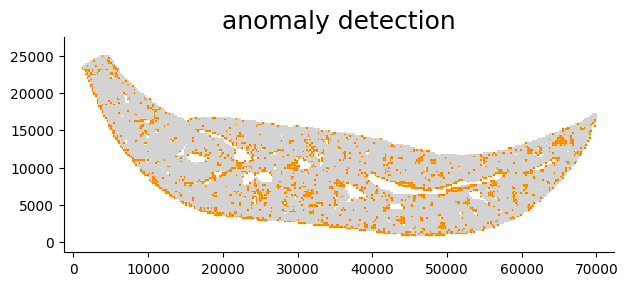

In [181]:
for i in [3, 21, 22, 23, 24]:
    f_path = "workspace/result_v4/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v4/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    loc_plot(location, jud, ppi=50, size=112, title="anomaly detection")

In [204]:
f_path_1 = "workspace/result_v4/1_layer5.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v4/2_layer5.npy"
feature_2 = np.load(f_path_2)
f_path_4 = "workspace/result_v4/4_layer5.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v4/5_layer5.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v4/6_layer5.npy"
feature_6 = np.load(f_path_6)
f_path_8 = "workspace/result_v4/8_layer5.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v4/9_layer5.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v4/10_layer5.npy"
feature_10 = np.load(f_path_10)
f_path_12 = "workspace/result_v4/12_layer5.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1) + list(feature_2) + list(feature_4)+ list(feature_5)+ list(feature_6)+ list(feature_8)+ list(feature_9)+ list(feature_10)+ list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [206]:
inf_dict = {}
percentage_lst = []
ap = percentage_lst.append
sample_n = [3, 7, 11, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
for i in sample_n:
    f_path = "workspace/result_v4/"+str(i)+"_layer5.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    ap(len([i for i in jud if i == -1])/len([i for i in jud if i == 1]))
inf_dict["compound"] = [bach_dict[i] for i in sample_n]
inf_dict["day"] = [day_dict[i] for i in sample_n]
inf_dict["percentage"] = percentage_lst

sample No.3
13961
878
Percentage of abnormal patches : 0.06288947783110092
sample No.7
12722
641
Percentage of abnormal patches : 0.05038515956610596
sample No.11
11935
740
Percentage of abnormal patches : 0.062002513615416845
sample No.13
13883
736
Percentage of abnormal patches : 0.05301447813873082
sample No.14
16615
1036
Percentage of abnormal patches : 0.06235329521516702
sample No.15
15199
868
Percentage of abnormal patches : 0.057109020330284886
sample No.16
16491
1156
Percentage of abnormal patches : 0.07009884179249287
sample No.17
15016
635
Percentage of abnormal patches : 0.04228822589238146
sample No.18
11764
586
Percentage of abnormal patches : 0.04981298877932676
sample No.19
14626
605
Percentage of abnormal patches : 0.041364693012443596
sample No.21
10219
501
Percentage of abnormal patches : 0.049026323515021036
sample No.22
12750
586
Percentage of abnormal patches : 0.04596078431372549
sample No.23
14921
761
Percentage of abnormal patches : 0.05100194356946585
sample N

In [207]:
df_p = pd.DataFrame.from_dict(inf_dict)
df_p.index = sample_n

taa = df_p.loc[24, "compound":"day"]
mda = df_p.loc[25, "compound":"day"]

df_p.loc[24, "compound":"day"] = mda
df_p.loc[25, "compound":"day"] = taa

df_p

,compound,day,percentage
3,Control,7,0.062889
7,Control,14,0.050385
11,Control,28,0.062003
13,TAA,7,0.053014
14,TAA,7,0.062353
15,TAA,7,0.057109
16,TAA,7,0.070099
17,TAA,14,0.042288
18,TAA,14,0.049813
19,TAA,14,0.041365


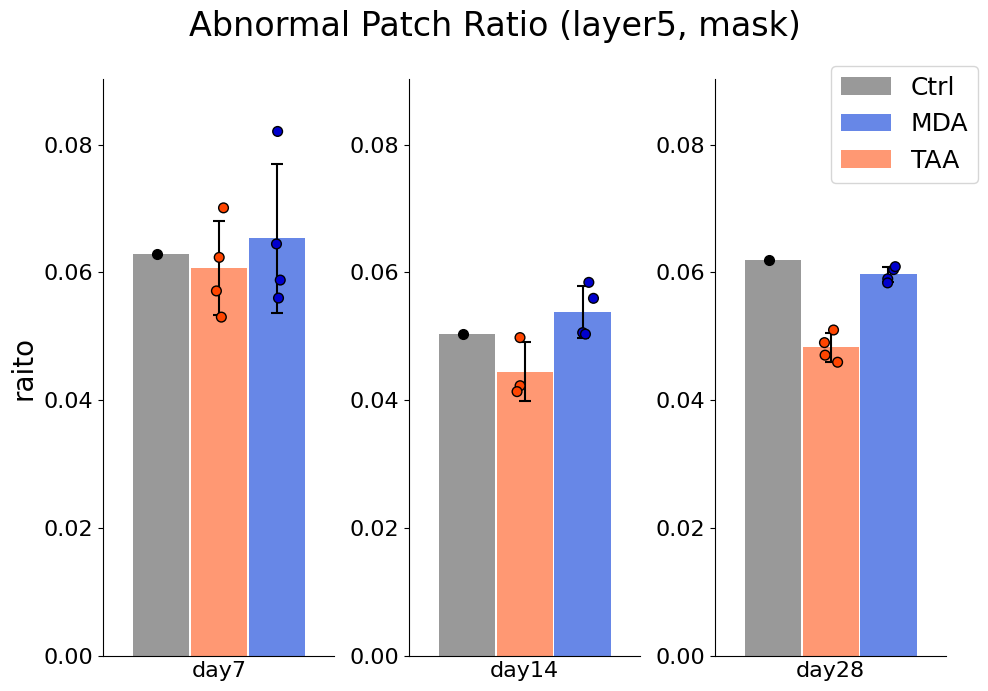

In [208]:
ratio_plot(df_p, title="Abnormal Patch Ratio (layer5, mask)")

In [219]:
f_path_1 = "workspace/result_v2/1_layer5.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v2/2_layer5.npy"
feature_2 = np.load(f_path_2)
f_path_4 = "workspace/result_v2/4_layer5.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v2/5_layer5.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v2/6_layer5.npy"
feature_6 = np.load(f_path_6)
f_path_8 = "workspace/result_v2/8_layer5.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v2/9_layer5.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v2/10_layer5.npy"
feature_10 = np.load(f_path_10)
f_path_12 = "workspace/result_v2/12_layer5.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1) + list(feature_2) + list(feature_4)+ list(feature_5)+ list(feature_6)+ list(feature_8)+ list(feature_9)+ list(feature_10)+ list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask_inside = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [220]:
inf_dict = {}
percentage_lst = []
ap = percentage_lst.append
sample_n = [3, 7, 11, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
for i in sample_n:
    f_path = "workspace/result_v2/"+str(i)+"_layer5.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    ap(len([i for i in jud if i == -1])/len([i for i in jud if i == 1]))
inf_dict["compound"] = [bach_dict[i] for i in sample_n]
inf_dict["day"] = [day_dict[i] for i in sample_n]
inf_dict["percentage"] = percentage_lst

sample No.3
12198
752
Percentage of abnormal patches : 0.06164945072962781
sample No.7
10835
525
Percentage of abnormal patches : 0.048454083987078914
sample No.11
10076
630
Percentage of abnormal patches : 0.06252481143310838
sample No.13
11478
722
Percentage of abnormal patches : 0.06290294476389614
sample No.14
14186
1002
Percentage of abnormal patches : 0.07063301846891301
sample No.15
12918
873
Percentage of abnormal patches : 0.06758012076172783
sample No.16
13888
1117
Percentage of abnormal patches : 0.08042914746543779
sample No.17
12750
649
Percentage of abnormal patches : 0.05090196078431373
sample No.18
9742
556
Percentage of abnormal patches : 0.057072469718743586
sample No.19
12328
582
Percentage of abnormal patches : 0.04720960415314731
sample No.21
8505
394
Percentage of abnormal patches : 0.046325690770135215
sample No.22
10596
534
Percentage of abnormal patches : 0.050396375990939976
sample No.23
12513
658
Percentage of abnormal patches : 0.052585311276272674
sample No

In [221]:
df_p = pd.DataFrame.from_dict(inf_dict)
df_p.index = sample_n

taa = df_p.loc[24, "compound":"day"]
mda = df_p.loc[25, "compound":"day"]

df_p.loc[24, "compound":"day"] = mda
df_p.loc[25, "compound":"day"] = taa

df_p

,compound,day,percentage
3,Control,7,0.061649
7,Control,14,0.048454
11,Control,28,0.062525
13,TAA,7,0.062903
14,TAA,7,0.070633
15,TAA,7,0.067580
16,TAA,7,0.080429
17,TAA,14,0.050902
18,TAA,14,0.057072
19,TAA,14,0.047210


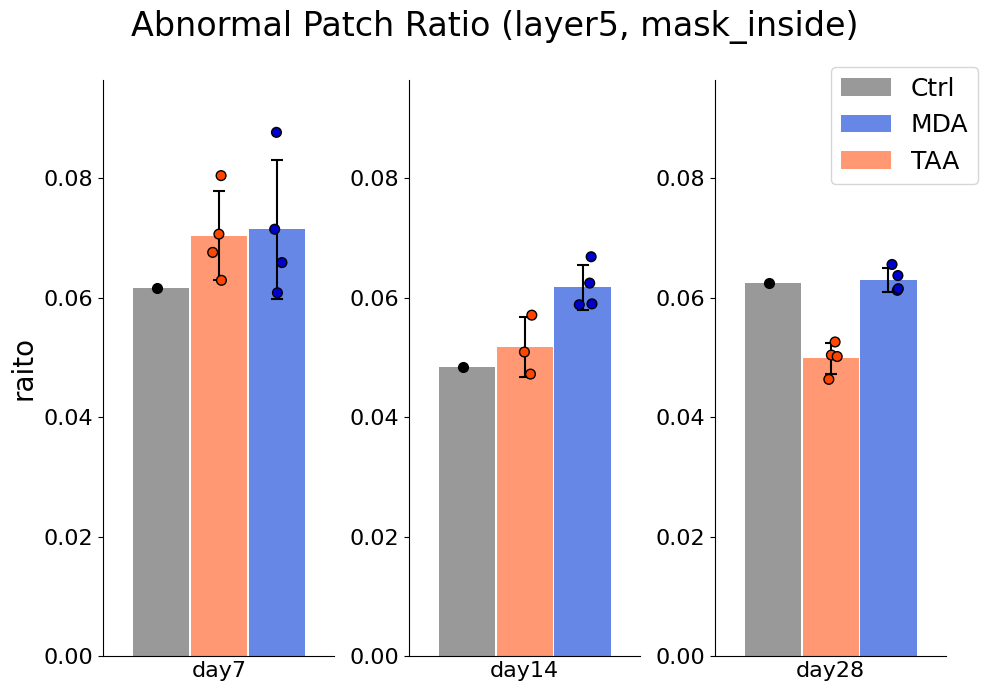

In [222]:
ratio_plot(df_p, title="Abnormal Patch Ratio (layer5, mask_inside)")

In [214]:
f_path_1 = "workspace/result_v2/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v2/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_4 = "workspace/result_v2/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v2/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v2/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_8 = "workspace/result_v2/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v2/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v2/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_12 = "workspace/result_v2/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1) + list(feature_2) + list(feature_4)+ list(feature_5)+ list(feature_6)+ list(feature_8)+ list(feature_9)+ list(feature_10)+ list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask_inside = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [216]:
inf_dict = {}
percentage_lst = []
ap = percentage_lst.append
sample_n = [3, 7, 11, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
for i in sample_n:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    ap(len([i for i in jud if i == -1])/len([i for i in jud if i == 1]))
inf_dict["compound"] = [bach_dict[i] for i in sample_n]
inf_dict["day"] = [day_dict[i] for i in sample_n]
inf_dict["percentage"] = percentage_lst

sample No.3
12153
797
Percentage of abnormal patches : 0.06558051509915247
sample No.7
10640
720
Percentage of abnormal patches : 0.06766917293233082
sample No.11
10006
700
Percentage of abnormal patches : 0.06995802518488907
sample No.13
10697
1503
Percentage of abnormal patches : 0.14050668411704217
sample No.14
13740
1448
Percentage of abnormal patches : 0.10538573508005822
sample No.15
12241
1550
Percentage of abnormal patches : 0.12662364185932523
sample No.16
12879
2126
Percentage of abnormal patches : 0.16507492817765354
sample No.17
12470
929
Percentage of abnormal patches : 0.07449879711307138
sample No.18
9684
614
Percentage of abnormal patches : 0.06340355225113589
sample No.19
12141
769
Percentage of abnormal patches : 0.06333909892101144
sample No.21
8335
564
Percentage of abnormal patches : 0.06766646670665867
sample No.22
10405
725
Percentage of abnormal patches : 0.06967803940413263
sample No.23
12307
864
Percentage of abnormal patches : 0.07020394897212968
sample No.24

In [217]:
df_p = pd.DataFrame.from_dict(inf_dict)
df_p.index = sample_n

taa = df_p.loc[24, "compound":"day"]
mda = df_p.loc[25, "compound":"day"]

df_p.loc[24, "compound":"day"] = mda
df_p.loc[25, "compound":"day"] = taa

df_p

,compound,day,percentage
3,Control,7,0.065581
7,Control,14,0.067669
11,Control,28,0.069958
13,TAA,7,0.140507
14,TAA,7,0.105386
15,TAA,7,0.126624
16,TAA,7,0.165075
17,TAA,14,0.074499
18,TAA,14,0.063404
19,TAA,14,0.063339


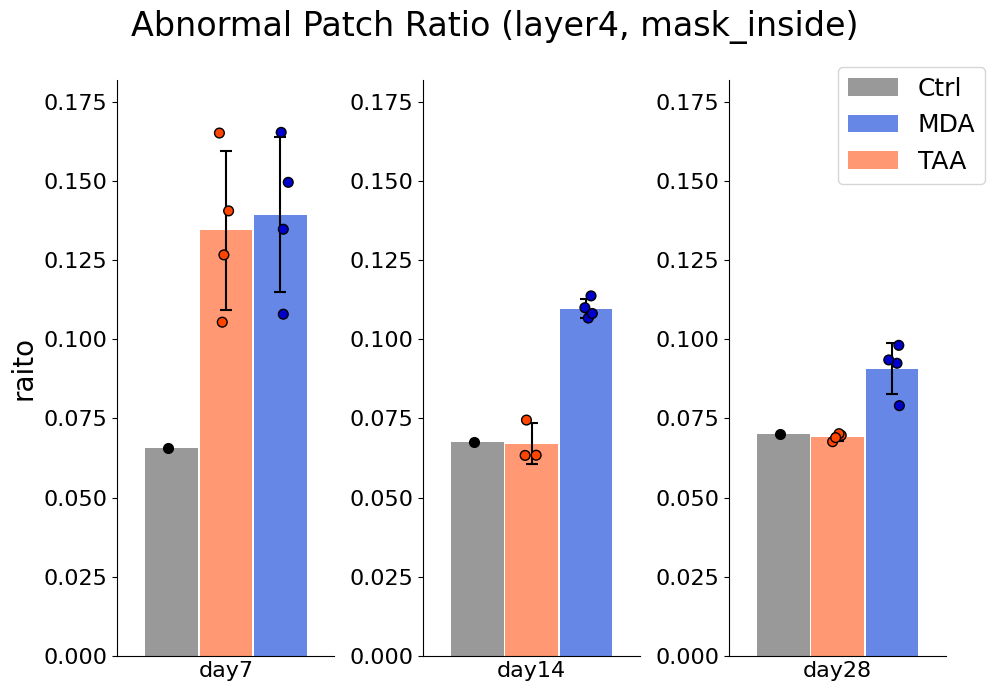

In [218]:
ratio_plot(df_p, title="Abnormal Patch Ratio (layer4, mask_inside)")

##### check layer4 & mask_inside #####

In [223]:
f_path_1 = "workspace/result_v2/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v2/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_4 = "workspace/result_v2/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v2/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v2/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_8 = "workspace/result_v2/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v2/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v2/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_12 = "workspace/result_v2/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1) + list(feature_2) + list(feature_4)+ list(feature_5)+ list(feature_6)+ list(feature_8)+ list(feature_9)+ list(feature_10)+ list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask_inside = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [225]:
total_inf_lst = []
for i in [3, 7, 11, 13, 15, 16, 26, 27, 28]:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.3
12153
797
Percentage of abnormal patches : 0.06558051509915247
max_n =  797
sample No.7
10640
720
Percentage of abnormal patches : 0.06766917293233082
max_n =  720
sample No.11
10006
700
Percentage of abnormal patches : 0.06995802518488907
max_n =  700
sample No.13
10697
1503
Percentage of abnormal patches : 0.14050668411704217
max_n =  1503
sample No.15
12241
1550
Percentage of abnormal patches : 0.12662364185932523
max_n =  1550
sample No.16
12879
2126
Percentage of abnormal patches : 0.16507492817765354
max_n =  2126
sample No.26
11298
1522
Percentage of abnormal patches : 0.13471410869180386
max_n =  1522
sample No.27
9795
1619
Percentage of abnormal patches : 0.16528841245533435
max_n =  1619
sample No.28
12122
1308
Percentage of abnormal patches : 0.10790298630589011
max_n =  1308


In [226]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

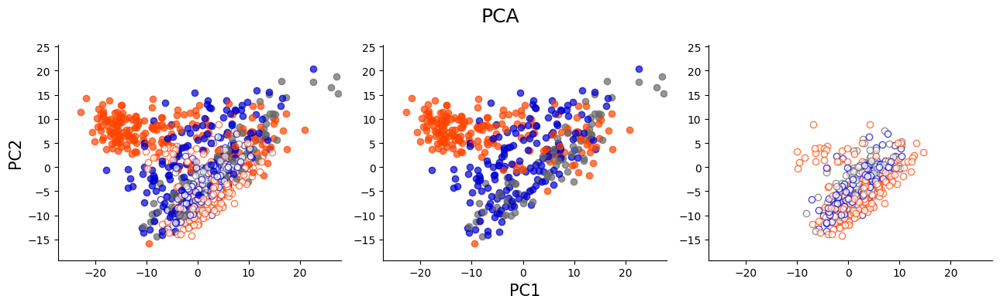

In [228]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=900, pict_sample=0, seed1=247, seed2=2477, title="")

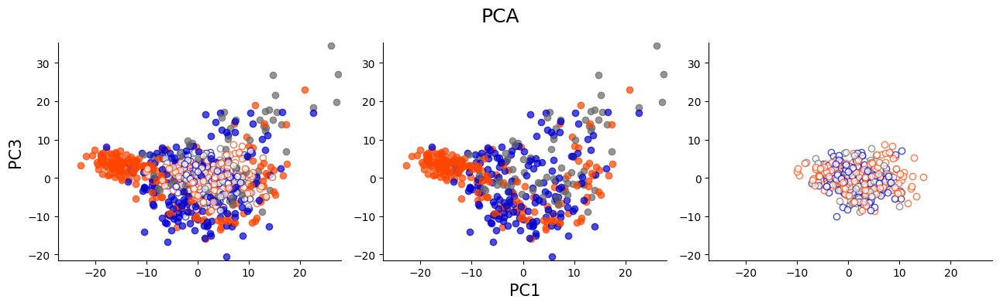

In [229]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=2, sample=900, pict_sample=0, seed1=247, seed2=2477, title="")

##### check layer5 & mask_inside #####

In [230]:
f_path_1 = "workspace/result_v2/1_layer5.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v2/2_layer5.npy"
feature_2 = np.load(f_path_2)
f_path_4 = "workspace/result_v2/4_layer5.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v2/5_layer5.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v2/6_layer5.npy"
feature_6 = np.load(f_path_6)
f_path_8 = "workspace/result_v2/8_layer5.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v2/9_layer5.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v2/10_layer5.npy"
feature_10 = np.load(f_path_10)
f_path_12 = "workspace/result_v2/12_layer5.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1) + list(feature_2) + list(feature_4)+ list(feature_5)+ list(feature_6)+ list(feature_8)+ list(feature_9)+ list(feature_10)+ list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask_inside = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [231]:
total_inf_lst = []
for i in [3, 7, 11, 13, 15, 16, 26, 27, 28]:
    f_path = "workspace/result_v2/"+str(i)+"_layer5.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.3
12198
752
Percentage of abnormal patches : 0.06164945072962781
max_n =  752
sample No.7
10835
525
Percentage of abnormal patches : 0.048454083987078914
max_n =  525
sample No.11
10076
630
Percentage of abnormal patches : 0.06252481143310838
max_n =  630
sample No.13
11478
722
Percentage of abnormal patches : 0.06290294476389614
max_n =  722
sample No.15
12918
873
Percentage of abnormal patches : 0.06758012076172783
max_n =  873
sample No.16
13888
1117
Percentage of abnormal patches : 0.08042914746543779
max_n =  1117
sample No.26
12085
735
Percentage of abnormal patches : 0.06081919735208937
max_n =  735
sample No.27
10494
920
Percentage of abnormal patches : 0.08766914427291786
max_n =  920
sample No.28
12600
830
Percentage of abnormal patches : 0.06587301587301587
max_n =  830


In [232]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    ap(i[1])

pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

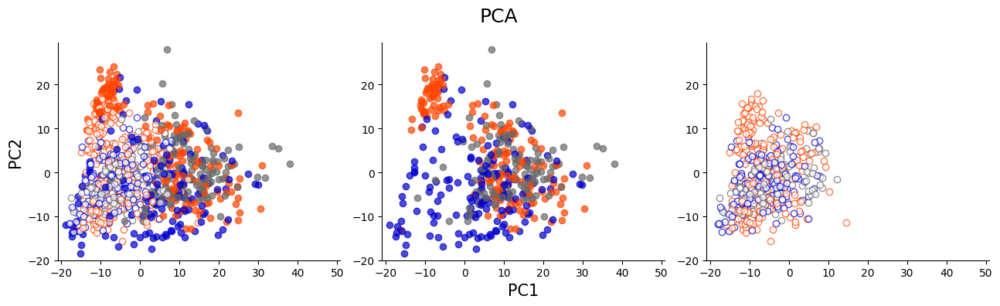

In [233]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=900, pict_sample=0, seed1=247, seed2=2477, title="")

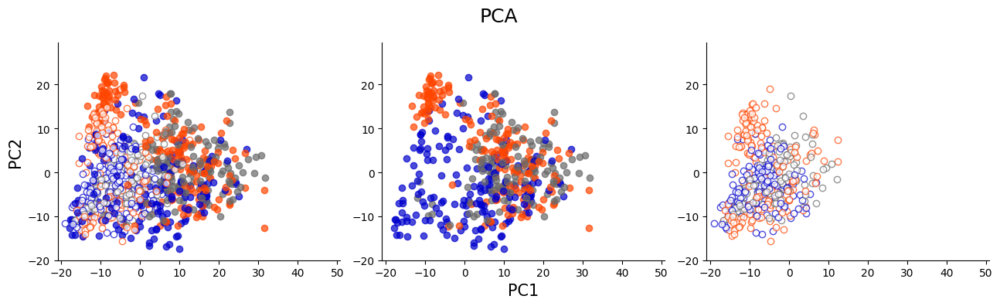

In [234]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=900, pict_sample=0, seed1=24771, seed2=2477, title="")

##### All controls are used for learning #####

In [8]:
f_path_1 = "workspace/result_v2/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v2/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v2/3_layer4.npy"
feature_3 = np.load(f_path_3)
f_path_4 = "workspace/result_v2/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v2/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v2/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v2/7_layer4.npy"
feature_7 = np.load(f_path_7)
f_path_8 = "workspace/result_v2/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v2/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v2/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v2/11_layer4.npy"
feature_11 = np.load(f_path_11)
f_path_12 = "workspace/result_v2/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1)+list(feature_2)+list(feature_3)+list(feature_4)+list(feature_5)+list(feature_6)+list(feature_7)+list(feature_8)+list(feature_9)+list(feature_10)+list(feature_11)+list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask_inside = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [9]:
#240321

bach_dict = {}
comp_lst = ["Control"]*12+["TAA"]*12+["MDA"]*12
for i in range(36):
    bach_dict[i+1] = comp_lst[i]

day_dict = {}
day_lst = [7]*4+[14]*4+[28]*4
day_lst = day_lst*3
for i in range(36):
    day_dict[i+1] = day_lst[i]

inf_dict = {}
percentage_lst = []
ap = percentage_lst.append
sample_n = [13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
for i in sample_n:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    ap(len([i for i in jud if i == -1])/len([i for i in jud if i == 1]))
inf_dict["compound"] = [bach_dict[i] for i in sample_n]
inf_dict["day"] = [day_dict[i] for i in sample_n]
inf_dict["percentage"] = percentage_lst

df_p = pd.DataFrame.from_dict(inf_dict)
df_p.index = sample_n
taa = df_p.loc[24, "compound":"day"]
mda = df_p.loc[25, "compound":"day"]
df_p.loc[24, "compound":"day"] = mda
df_p.loc[25, "compound":"day"] = taa

df_p

sample No.13
10718
1482
Percentage of abnormal patches : 0.13827206568389624
sample No.14
13769
1419
Percentage of abnormal patches : 0.10305759314401917
sample No.15
12268
1523
Percentage of abnormal patches : 0.12414411477013368
sample No.16
12915
2090
Percentage of abnormal patches : 0.1618273325590399
sample No.17
12498
901
Percentage of abnormal patches : 0.07209153464554328
sample No.18
9708
590
Percentage of abnormal patches : 0.0607746188710342
sample No.19
12188
722
Percentage of abnormal patches : 0.059238595339678374
sample No.21
8369
530
Percentage of abnormal patches : 0.06332895208507587
sample No.22
10430
700
Percentage of abnormal patches : 0.06711409395973154
sample No.23
12345
826
Percentage of abnormal patches : 0.06690968003240179
sample No.24
9790
1381
Percentage of abnormal patches : 0.14106230847803883
sample No.25
12000
774
Percentage of abnormal patches : 0.0645
sample No.26
11352
1468
Percentage of abnormal patches : 0.12931642001409444
sample No.27
9841
1573


,compound,day,percentage
13,TAA,7,0.138272
14,TAA,7,0.103058
15,TAA,7,0.124144
16,TAA,7,0.161827
17,TAA,14,0.072092
18,TAA,14,0.060775
19,TAA,14,0.059239
21,TAA,28,0.063329
22,TAA,28,0.067114
23,TAA,28,0.066910


In [15]:
def ratio_plot(df_p, title="Abnormal Patch Ratio"):
    fig = plt.figure(figsize=(10, 7))
    y_max = max(df_p.loc[:, "percentage"])*1.1
    for i, d in enumerate([7, 14, 28]):
        df_p_day = df_p.loc[[df_p.loc[i, "day"] == d for i in df_p.index.tolist()], :]

        df_mda = df_p_day.loc[[df_p_day.loc[i, "compound"] == "MDA" for i in df_p_day.index.tolist()], :]
        df_mda = df_mda.loc[:, ["percentage"]]
        df_taa = df_p_day.loc[[df_p_day.loc[i, "compound"] == "TAA" for i in df_p_day.index.tolist()], :]
        df_taa = df_taa.loc[:, ["percentage"]]

        ax = fig.add_subplot(1, 3, i+1)
        ax2 = ax.twinx()

        width = 0.4
        x_position = np.arange(1)
        error_bar_set = dict(lw = 1.5, capthick = 1.5, capsize = 4)
        ax.bar(x_position+width/2, df_mda.mean(), yerr=df_mda.std(), tick_label=df_mda.columns, error_kw=error_bar_set, color='royalblue', width=0.97*width, label="MDA", alpha=.8)
        ax.bar(x_position-width/2, df_taa.mean(), yerr=df_taa.std(), tick_label=df_mda.columns, error_kw=error_bar_set, color='coral', width=0.97*width, label="TAA", alpha=.8)
        ax.bar(x_position, df_taa.mean(), tick_label=df_mda.columns, color='white', width=0, alpha=.1) # Adjustment of ticklabels position

        ax.legend(fontsize=18, loc=(0.5, 0.82))
        plt.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        # jitter plot
        sns.stripplot(x='day', y='percentage', data=df_p_day, hue='compound', dodge=True, jitter=True, s=7, linewidth=1, edgecolor="black", palette=['orangered', 'mediumblue'], ax=ax2)
        # control line
        ax.hlines(y=0.05, xmin=-1.2*width, xmax=1.2*width, color="black", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

        ax.tick_params(axis='x', labelsize=16, direction='in', width=0)
        ax.tick_params(axis='y', labelsize=16)

        ax.set_xlim(-1.2*width,1.2*width)
        ax2.set_xlim(-1.2*width,1.2*width)
        ax.set_ylim(0,y_max)
        ax2.set_ylim(0,y_max)

        ax2.axis("off")
        ax2.get_legend().remove()

        if i == 0:
            ax.set_ylabel("raito", fontsize=20)
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()         
        elif i == len([7, 14, 28])-1:
            ax.set_xticklabels(["day"+str(d)])
        else:
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()  

    fig.suptitle(title, fontsize=24)
    plt.tight_layout()
    plt.show()


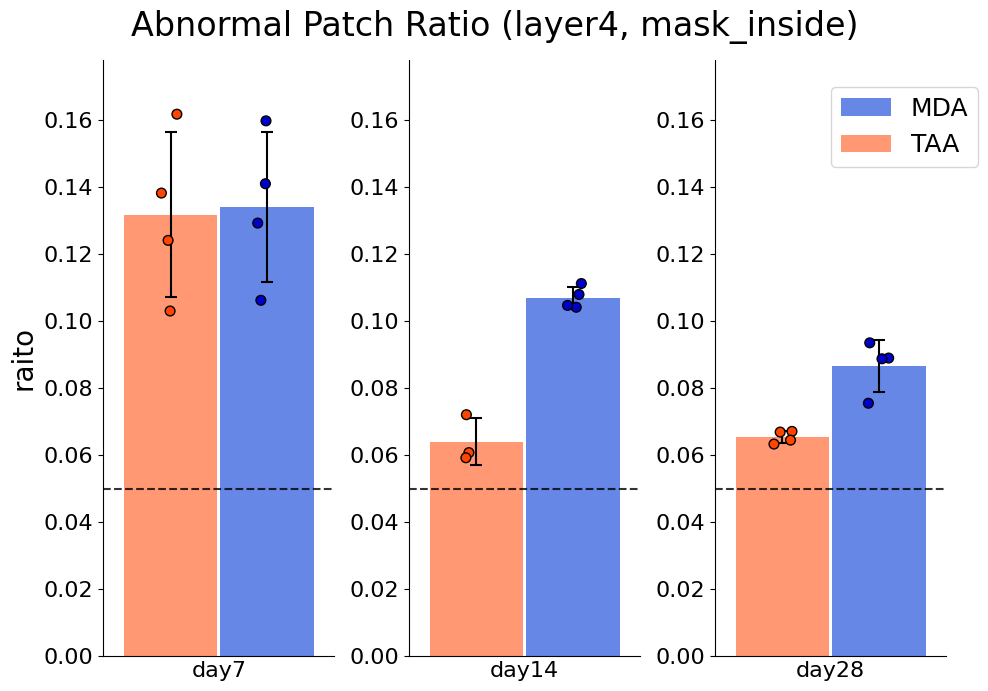

In [16]:
ratio_plot(df_p, title="Abnormal Patch Ratio (layer4, mask_inside)")

In [17]:
def get_info(sample_id, feature, location, jud):
    inf_lst = []
    max_n = len([i for i in jud if i == -1])
    print("max_n = ", str(max_n))
    n = 0
    ap = inf_lst.append
    for i in zip(jud, feature, location):
        if i[0] == -1:
            ap([sample_id, i[1], i[2], i[0]])
        elif i[0] == 1 and n < max_n:
            ap([sample_id, i[1], i[2], i[0]])
            n = n + 1
        else:
            pass

    return inf_lst

In [18]:
total_inf_lst = []
for i in [17, 18, 19, 26, 30, 31, 32]:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.17
12498
901
Percentage of abnormal patches : 0.07209153464554328
max_n =  901
sample No.18
9708
590
Percentage of abnormal patches : 0.0607746188710342
max_n =  590
sample No.19
12188
722
Percentage of abnormal patches : 0.059238595339678374
max_n =  722
sample No.26
11352
1468
Percentage of abnormal patches : 0.12931642001409444
max_n =  1468
sample No.30
12445
1344
Percentage of abnormal patches : 0.10799517878666132
max_n =  1344
sample No.31
14714
1541
Percentage of abnormal patches : 0.10473018893570749
max_n =  1541
sample No.32
12897
1435
Percentage of abnormal patches : 0.1112661859347135
max_n =  1435


In [19]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

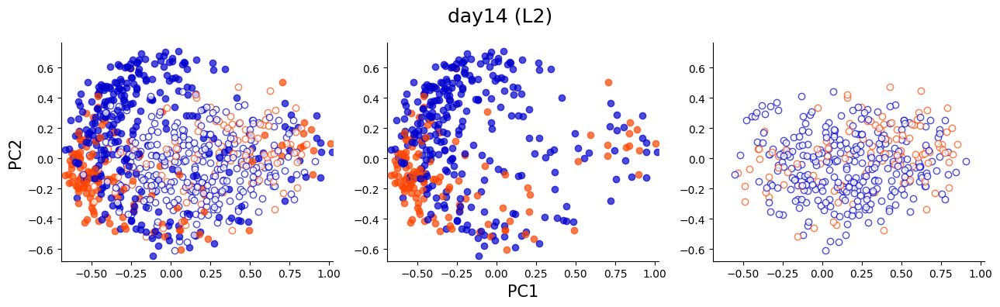

In [24]:
PCAplot_total(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=800, seed1=24771, title="day14 (L2)")

In [49]:
pca_feature_s = []
ap = pca_feature_s.append
for i in total_inf_lst:
    x = i[1]
    # standardization
    lst_mean = mean(x)
    lst_std = stdev(x)
    ap(np.array([(i-lst_mean)/lst_std for i in total_inf_lst[0][1]]))

pca = PCA()
pca.fit(pca_feature_s)
feature_pca_s = pca.transform(pca_feature_s)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

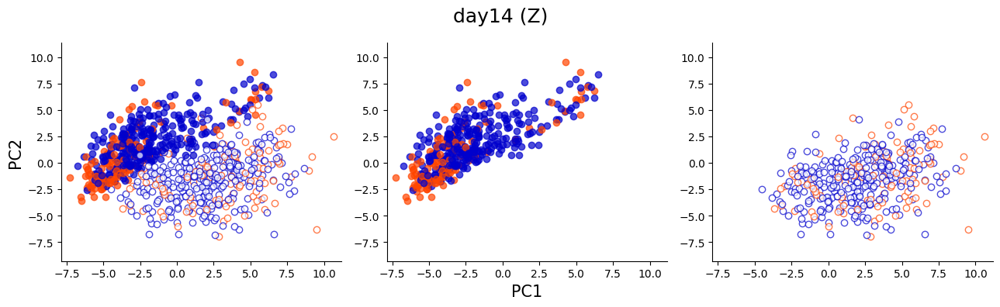

In [50]:
PCAplot_total(feature_pca_s, pca_inf, bach_dict, xnum=0, ynum=1, sample=800, seed1=24771, title="day14 (Z)")

In [20]:
total_inf_lst = []
for i in [13, 14, 15, 16, 24, 26, 27, 28]:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.13
10718
1482
Percentage of abnormal patches : 0.13827206568389624
max_n =  1482
sample No.14
13769
1419
Percentage of abnormal patches : 0.10305759314401917
max_n =  1419
sample No.15
12268
1523
Percentage of abnormal patches : 0.12414411477013368
max_n =  1523
sample No.16
12915
2090
Percentage of abnormal patches : 0.1618273325590399
max_n =  2090
sample No.24
9790
1381
Percentage of abnormal patches : 0.14106230847803883
max_n =  1381
sample No.26
11352
1468
Percentage of abnormal patches : 0.12931642001409444
max_n =  1468
sample No.27
9841
1573
Percentage of abnormal patches : 0.15984147952443858
max_n =  1573
sample No.28
12140
1290
Percentage of abnormal patches : 0.10626029654036244
max_n =  1290


In [34]:
pca_feature_s = []
ap = pca_feature_s.append
for i in total_inf_lst:
    x = i[1]
    # standardization
    lst_mean = mean(x)
    lst_std = stdev(x)
    ap(np.array([(i-lst_mean)/lst_std for i in total_inf_lst[0][1]]))

pca = PCA()
pca.fit(pca_feature_s)
feature_pca_s = pca.transform(pca_feature_s)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

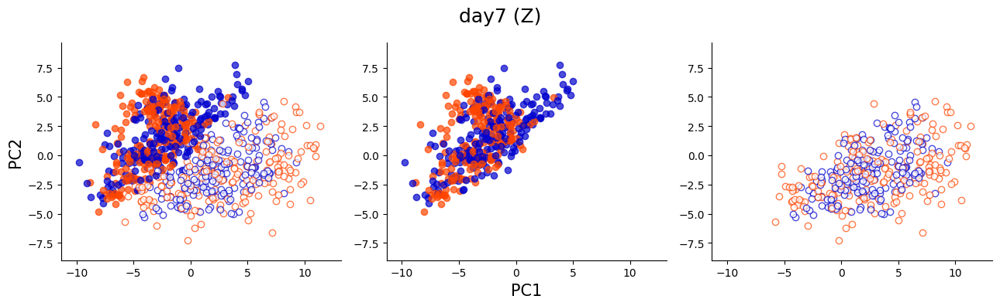

In [45]:
PCAplot_total(feature_pca_s, pca_inf, bach_dict, xnum=0, ynum=1, sample=800, seed1=24771, title="day7 (Z)")

In [29]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

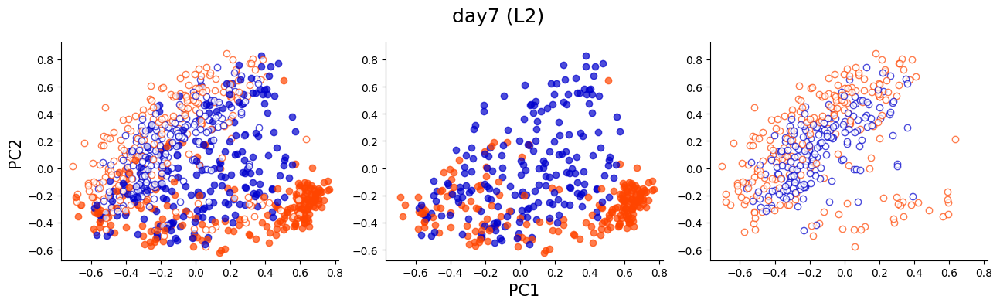

In [44]:
PCAplot_total(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=800, seed1=24771, title="day7 (L2)")

###### check heatmap ######

<Axes: >

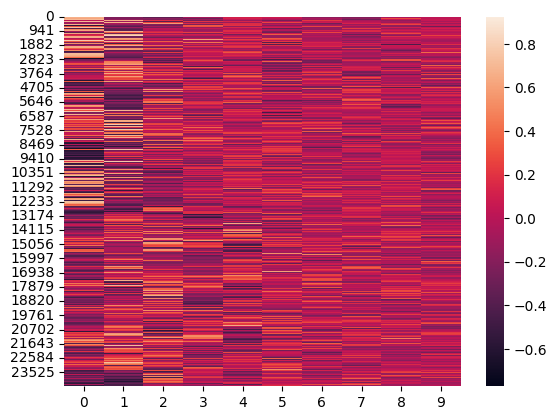

In [74]:
sns.heatmap(feature_pca_l2[:, 0:10])

In [71]:
len(feature_pca_l2[0, :])

256

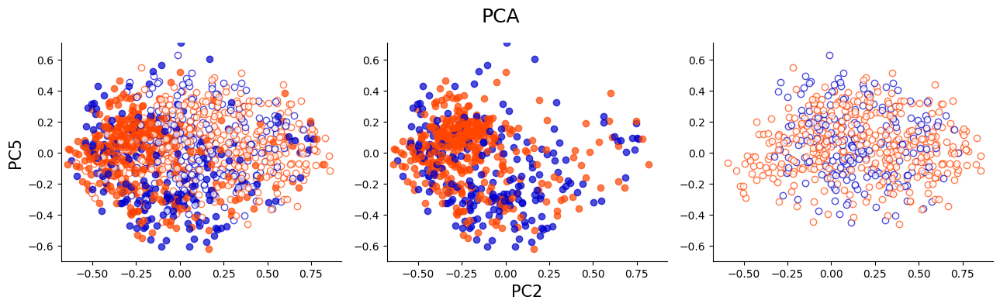

In [77]:
PCAplot_total(feature_pca_l2, pca_inf, bach_dict, xnum=1, ynum=4, sample=1200, pict_sample=0, seed1=247, seed2=2477, title="")

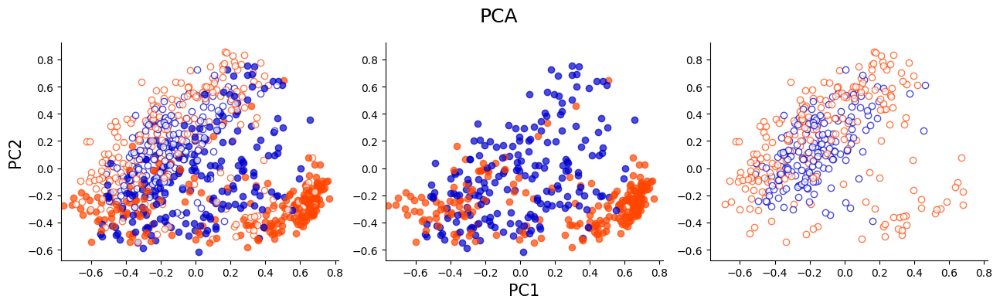

In [37]:
PCAplot_total(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=800, pict_sample=0, seed1=247, seed2=2477, title="")

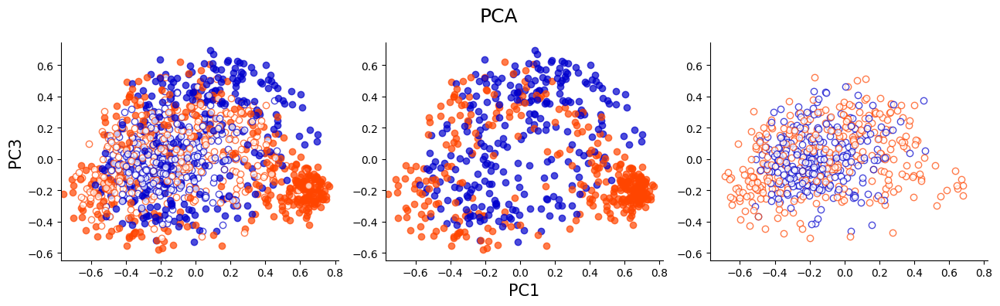

In [31]:
PCAplot_total(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=2, sample=1200, pict_sample=0, seed1=247, seed2=2477, title="")

In [32]:
pca_feature = []
ap = pca_feature.append
for i in total_inf_lst:
    x = i[1]
    ap(x)

pca = PCA()
pca.fit(pca_feature)
feature_pca = pca.transform(pca_feature)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

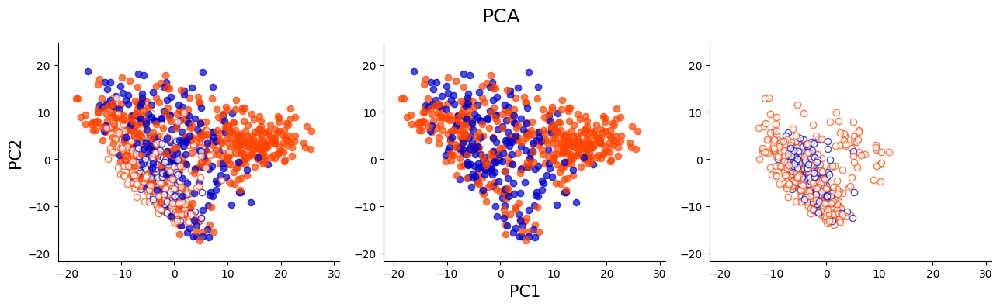

In [67]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=1200, pict_sample=0, seed1=247, seed2=2477, title="")

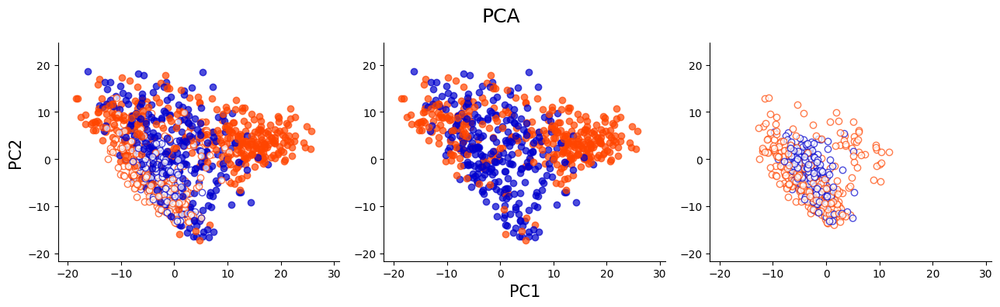

In [33]:
PCAplot_total(feature_pca, pca_inf, bach_dict, xnum=0, ynum=1, sample=1200, pict_sample=0, seed1=247, seed2=2477, title="")

#### model preparation v2 ####

In [81]:
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(DEVICE)

cuda:0


In [ ]:
DICT_MODEL = {
    "EfficientNetB3": [torchvision.models.efficientnet_b3, 1536, EfficientNetB3Featurize],
    "ConvNextTiny": [torchvision.models.convnext_tiny, 768, ConvNextTinyFeaturize],
    "ResNet18": [torchvision.models.resnet18, 512, ResNet18Featurize],
    "RegNetY16gf": [torchvision.models.regnet_y_1_6gf, 888, RegNetY16gfFeaturize],
    "DenseNet121": [torchvision.models.densenet121, 1024, DenseNet121Featurize],
}

In [ ]:
DICT_SSL={
    "barlowtwins":sslutils.BarlowTwins,
    "swav":sslutils.SwaV,
    "byol":sslutils.Byol,
    "simsiam":sslutils.SimSiam,
    "wsl":sslutils.WSL,
}

In [ ]:
def prepare_model_eval(
        model_name:str='ResNet18', ssl_name="barlowtwins",  
        model_path="", 
        pretrained=False, 
        DEVICE="cpu"):
    """
    preparation of models
    Parameters
    ----------
        modelname (str)
            model architecture name

    """
    # model building with indicated name
    if pretrained:
        if model_name=="DenseNet121":
            encoder = DICT_MODEL[model_name][0](weights=None)
            encoder = _load_state_dict_dense(encoder, torch.load(model_path))
            model = nn.Sequential(
                *list(encoder.children())[:-1],
                nn.ReLU(inplace=True),
                nn.AdaptiveAvgPool2d((1, 1))
                )
        else:
            encoder = DICT_MODEL[model_name][0](weights=None)
            encoder.load_state_dict(torch.load(model_path))
            model=nn.Sequential(*list(encoder.children())[:-1])
    else:
        encoder = DICT_MODEL[model_name][0](weights=None)
        size = DICT_MODEL[model_name][1]
        if model_name=="DenseNet121":
            backbone = nn.Sequential(
                *list(encoder.children())[:-1],
                nn.ReLU(inplace=True),
                nn.AdaptiveAvgPool2d((1, 1))
                )
        else:
            backbone = nn.Sequential(
                *list(encoder.children())[:-1],
                )
        model = DICT_SSL[ssl_name](DEVICE=DEVICE).prepare_featurize_model(
            backbone, model_path=model_path,
            head_size=size,
        )
    model.to(DEVICE)
    model.eval()
    return model

In [ ]:
model_wsl = prepare_model_eval(model_name='ResNet18', ssl_name="wsl", model_path="", DEVICE=DEVICE)

#### check wsi ####

In [15]:
dir_path = "/workspace/HE_240205_iwasaka"
file_lst = os.listdir(dir_path)
filein_lst = ["workspace/HE_240205_iwasaka/"+i for i in file_lst if ".tif" in i]

In [16]:
filein_lst

['workspace/HE_240205_iwasaka/2024_02_05__0596-シングルファイルエクスポート-01.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0597-シングルファイルエクスポート-02.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0598-シングルファイルエクスポート-03.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0599-シングルファイルエクスポート-04.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0600-シングルファイルエクスポート-05.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0601-シングルファイルエクスポート-06.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0602-シングルファイルエクスポート-07.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0603-シングルファイルエクスポート-08.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0604-シングルファイルエクスポート-09.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0605-シングルファイルエクスポート-10.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0606-シングルファイルエクスポート-11.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0607-シングルファイルエクスポート-12.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0608-シングルファイルエクスポート-13.tif',
 'workspace/HE_240205_iwasaka/2024_02_05__0609-シングルファイルエクスポート-14.tif',
 'work

In [17]:
patch_size = 2240*2
for filename in filein_lst:
    wsi = OpenSlide(filename)
    if int(filename.split("-")[2].split(".")[0]) < 20:
        print("wsi_"+str(filename.split("-")[2].split(".")[0])+".jpg")
        wsi.get_thumbnail(size=(patch_size,patch_size)).save("workspace/fig/wsi/wsi_"+str(filename.split("-")[2].split(".")[0])+".jpg", "JPEG")
    else:
        wsi.get_thumbnail(size=(patch_size,patch_size)).save("workspace/fig/wsi/wsi_"+str(int(filename.split("-")[2].split(".")[0])+1)+".jpg", "JPEG")
        print("wsi_"+str(int(filename.split("-")[2].split(".")[0])+1)+".jpg")

wsi_01.jpg


wsi_02.jpg
wsi_03.jpg
wsi_04.jpg
wsi_05.jpg
wsi_06.jpg
wsi_07.jpg
wsi_08.jpg
wsi_09.jpg
wsi_10.jpg
wsi_11.jpg
wsi_12.jpg
wsi_13.jpg
wsi_14.jpg
wsi_15.jpg
wsi_16.jpg
wsi_17.jpg
wsi_18.jpg
wsi_19.jpg
wsi_21.jpg
wsi_22.jpg
wsi_23.jpg
wsi_25.jpg
wsi_24.jpg
wsi_26.jpg
wsi_27.jpg
wsi_28.jpg
wsi_29.jpg
wsi_30.jpg
wsi_31.jpg
wsi_32.jpg
wsi_33.jpg
wsi_34.jpg
wsi_35.jpg
wsi_36.jpg


In [11]:
filename = "/workspace/HE_240205_iwasaka/2024_02_05__0621-シングルファイルエクスポート-26.tif"

In [7]:
wsi = OpenSlide(filename)

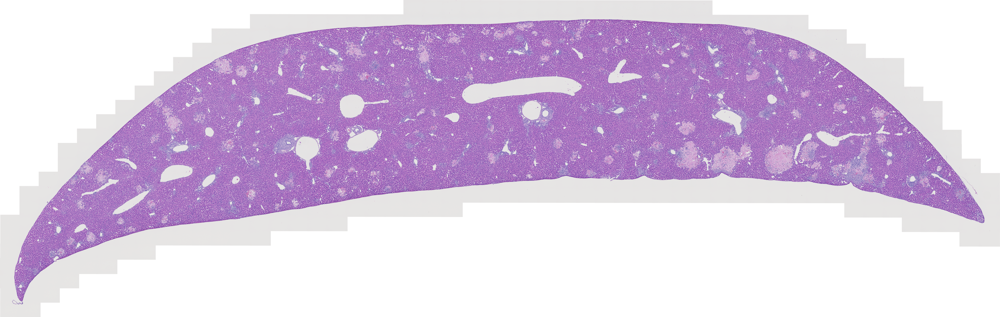

In [8]:
patch_size = 2240*2
wsi.get_thumbnail(size=(patch_size,patch_size))

#### Analysis for publication ####

##### model #####

In [8]:
f_path_1 = "workspace/result_v2/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v2/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v2/3_layer4.npy"
feature_3 = np.load(f_path_3)
f_path_4 = "workspace/result_v2/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v2/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v2/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v2/7_layer4.npy"
feature_7 = np.load(f_path_7)
f_path_8 = "workspace/result_v2/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v2/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v2/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v2/11_layer4.npy"
feature_11 = np.load(f_path_11)
f_path_12 = "workspace/result_v2/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1)+list(feature_2)+list(feature_3)+list(feature_4)+list(feature_5)+list(feature_6)+list(feature_7)+list(feature_8)+list(feature_9)+list(feature_10)+list(feature_11)+list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask_inside = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

##### data preparation #####

In [9]:
bach_dict = {}
comp_lst = ["Control"]*12+["TAA"]*12+["MDA"]*12
for i in range(36):
    bach_dict[i+1] = comp_lst[i]

day_dict = {}
day_lst = [7]*4+[14]*4+[28]*4
day_lst = day_lst*3
for i in range(36):
    day_dict[i+1] = day_lst[i]

inf_dict = {}
percentage_lst = []
ap = percentage_lst.append
sample_n = [13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
for i in sample_n:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    ap(len([i for i in jud if i == -1])/len([i for i in jud if i == 1]))
inf_dict["compound"] = [bach_dict[i] for i in sample_n]
inf_dict["day"] = [day_dict[i] for i in sample_n]
inf_dict["percentage"] = percentage_lst

df_p = pd.DataFrame.from_dict(inf_dict)
df_p.index = sample_n
taa = df_p.loc[24, "compound":"day"]
mda = df_p.loc[25, "compound":"day"]
df_p.loc[24, "compound":"day"] = mda
df_p.loc[25, "compound":"day"] = taa

df_p

sample No.13
10718
1482
Percentage of abnormal patches : 0.13827206568389624
sample No.14
13769
1419
Percentage of abnormal patches : 0.10305759314401917
sample No.15
12268
1523
Percentage of abnormal patches : 0.12414411477013368
sample No.16
12915
2090
Percentage of abnormal patches : 0.1618273325590399
sample No.17
12498
901
Percentage of abnormal patches : 0.07209153464554328
sample No.18
9708
590
Percentage of abnormal patches : 0.0607746188710342
sample No.19
12188
722
Percentage of abnormal patches : 0.059238595339678374
sample No.21
8369
530
Percentage of abnormal patches : 0.06332895208507587
sample No.22
10430
700
Percentage of abnormal patches : 0.06711409395973154
sample No.23
12345
826
Percentage of abnormal patches : 0.06690968003240179
sample No.24
9790
1381
Percentage of abnormal patches : 0.14106230847803883
sample No.25
12000
774
Percentage of abnormal patches : 0.0645
sample No.26
11352
1468
Percentage of abnormal patches : 0.12931642001409444
sample No.27
9841
1573


,compound,day,percentage
13,TAA,7,0.138272
14,TAA,7,0.103058
15,TAA,7,0.124144
16,TAA,7,0.161827
17,TAA,14,0.072092
18,TAA,14,0.060775
19,TAA,14,0.059239
21,TAA,28,0.063329
22,TAA,28,0.067114
23,TAA,28,0.066910


##### abnomal ratio #####

In [10]:
def ratio_plot(df_p, title="Abnormal Patch Ratio"):
    fig = plt.figure(figsize=(10, 7))
    y_max = max(df_p.loc[:, "percentage"])*1.1
    for i, d in enumerate([7, 14, 28]):
        df_p_day = df_p.loc[[df_p.loc[i, "day"] == d for i in df_p.index.tolist()], :]

        df_mda = df_p_day.loc[[df_p_day.loc[i, "compound"] == "MDA" for i in df_p_day.index.tolist()], :]
        df_mda = df_mda.loc[:, ["percentage"]]
        df_taa = df_p_day.loc[[df_p_day.loc[i, "compound"] == "TAA" for i in df_p_day.index.tolist()], :]
        df_taa = df_taa.loc[:, ["percentage"]]

        ax = fig.add_subplot(1, 3, i+1)
        ax2 = ax.twinx()

        width = 0.4
        x_position = np.arange(1)
        error_bar_set = dict(lw = 1.5, capthick = 1.5, capsize = 4)
        ax.bar(x_position+width/2, df_mda.mean(), yerr=df_mda.std(), tick_label=df_mda.columns, error_kw=error_bar_set, color='royalblue', width=0.97*width, label="MDA", alpha=.8)
        ax.bar(x_position-width/2, df_taa.mean(), yerr=df_taa.std(), tick_label=df_mda.columns, error_kw=error_bar_set, color='coral', width=0.97*width, label="TAA", alpha=.8)
        ax.bar(x_position, df_taa.mean(), tick_label=df_mda.columns, color='white', width=0, alpha=.1) # Adjustment of ticklabels position

        ax.legend(fontsize=18, loc=(0.5, 0.82))
        plt.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        # jitter plot
        sns.stripplot(x='day', y='percentage', data=df_p_day, hue='compound', dodge=True, jitter=True, s=7, linewidth=1, edgecolor="black", palette=['orangered', 'mediumblue'], ax=ax2)
        # control line
        ax.hlines(y=0.05, xmin=-1.2*width, xmax=1.2*width, color="black", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

        ax.tick_params(axis='x', labelsize=16, direction='in', width=0)
        ax.tick_params(axis='y', labelsize=16)

        ax.set_xlim(-1.2*width,1.2*width)
        ax2.set_xlim(-1.2*width,1.2*width)
        ax.set_ylim(0,y_max)
        ax2.set_ylim(0,y_max)

        ax2.axis("off")
        ax2.get_legend().remove()

        if i == 0:
            ax.set_ylabel("raito", fontsize=20)
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()         
        elif i == len([7, 14, 28])-1:
            ax.set_xticklabels(["day"+str(d)])
        else:
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()  

    fig.suptitle(title, fontsize=24)
    plt.tight_layout()
    plt.show()

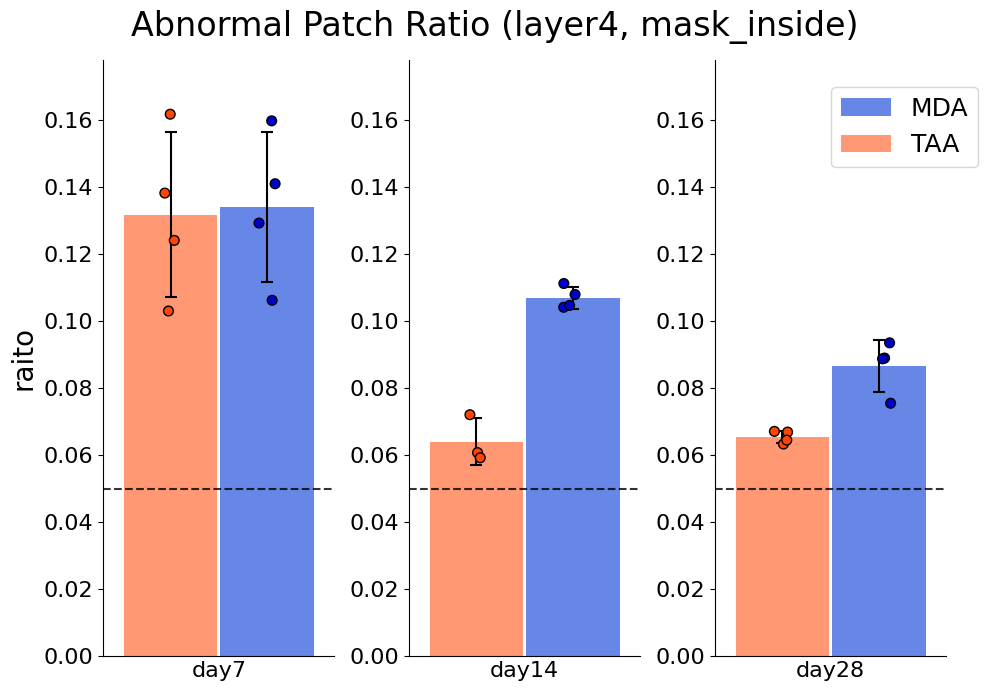

In [11]:
ratio_plot(df_p, title="Abnormal Patch Ratio (layer4, mask_inside)")

##### main #####

###### day14 ######

In [138]:
def get_info(sample_id, feature, location, jud):
    inf_lst = []
    max_n = len([i for i in jud if i == -1])
    print("max_n = ", str(max_n))
    n = 0
    ap = inf_lst.append
    for i in zip(jud, feature, location):
        if i[0] == -1:
            ap([sample_id, i[1], i[2], i[0]])
        elif i[0] == 1 and n < max_n:
            ap([sample_id, i[1], i[2], i[0]])
            n = n + 1
        else:
            pass

    return inf_lst

In [139]:
total_inf_lst = []
for i in [17, 18, 19, 29, 30, 31, 32]:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.17
12498
901
Percentage of abnormal patches : 0.07209153464554328
max_n =  901
sample No.18
9708
590
Percentage of abnormal patches : 0.0607746188710342
max_n =  590
sample No.19
12188
722
Percentage of abnormal patches : 0.059238595339678374
max_n =  722
sample No.29
13237
1379
Percentage of abnormal patches : 0.1041776837652036
max_n =  1379
sample No.30
12445
1344
Percentage of abnormal patches : 0.10799517878666132
max_n =  1344
sample No.31
14714
1541
Percentage of abnormal patches : 0.10473018893570749
max_n =  1541
sample No.32
12897
1435
Percentage of abnormal patches : 0.1112661859347135
max_n =  1435


In [140]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

In [158]:
# 第一主成分と第二主成分でプロットする
def PCAplot_total_v2(feature_pca, pca_inf, bach_dict, seed1=2477, sample=100, pict_sample=3, xnum=0, ynum=1, title=""):
    fig = plt.figure(figsize=(13, 4))
    ax1 = fig.add_subplot(1, 3, 3)
    ax2 = fig.add_subplot(1, 3, 1)
    ax3 = fig.add_subplot(1, 3, 2)

    label_lst = []
    ap = label_lst.append
    sample_no_lst = []
    ap_s = sample_no_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature_pca)), sample)

    color_dict = {"Control":"dimgray","TAA":"orangered", "MDA":"mediumblue"}

    xmax = max(feature_pca[:, xnum])
    xmin = min(feature_pca[:, xnum])
    ymax = max(feature_pca[:, ynum])
    ymin = min(feature_pca[:, ynum])

    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if bach_dict[pca_inf[i][0]] + ", -1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", -1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
                ap_s(pca_inf[i][0])
                print("pict_sample_no = ", str(pca_inf[i][0]))
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and -0.5 < feature_pca[:, xnum][i] < 0.1 and -0.7 < feature_pca[:, ynum][i] < -0.45:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="red", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and -0.65 < feature_pca[:, xnum][i] < -0.1 and -0.2 < feature_pca[:, ynum][i] < 0.2:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="red", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
        else:
            if bach_dict[pca_inf[i][0]] + ", 1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", 1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])

    for ax in [ax2, ax3, ax1]:
        #ax.set_title("", fontsize=18)

        ax.set_xlim(xmin,xmax)
        ax.set_ylim(ymin,ymax)

        ax.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        ax.spines.bottom.set_color('black')
        ax.spines.left.set_color('black')
    
    ax2.hlines(y=-0.45, xmin=-0.5, xmax=0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=-0.7, xmin=-0.5, xmax=0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=-0.5, ymin=-0.7, ymax=-0.45, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=0.1, ymin=-0.7, ymax=-0.45, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.hlines(y=0.2, xmin=-0.65, xmax=-0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=-0.2, xmin=-0.65, xmax=-0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=-0.65, ymin=-0.2, ymax=0.2, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=-0.1, ymin=-0.2, ymax=0.2, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.legend()
    ax3.legend() 
    ax3.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax2.set_ylabel("PC"+str(ynum+1), fontsize=15)

    fig.suptitle(title, fontsize=18)

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

    return loc_lst

In [1]:
loc_lst = PCAplot_total_v2(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=6, seed1=1426, title="day14 (L2)")

NameError: name 'PCAplot_total_v2' is not defined

In [170]:
def loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    print(size)
    if size < 1:
        size = 1

    for i in zip(jud, location):
        if i[0] == -1:
            if str(i[1]) in [key for key in fig_loc.keys()]:
                ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=3, edgecolors="gold")
                ax.text(i[1][0]+loc, i[1][1]-loc, s=fig_loc[str(i[1])],  weight="bold")
            else:
                ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="lightgray", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

Percentage of abnormal patches : 0.07209153464554328
0.7659386719611736


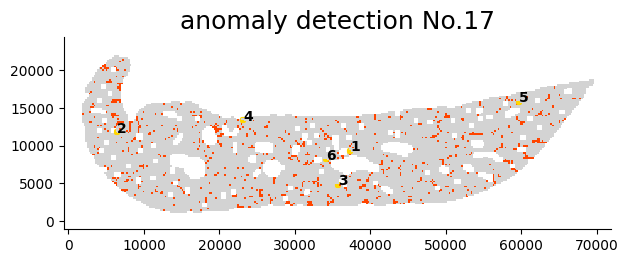

Percentage of abnormal patches : 0.1112661859347135
0.7256008359456636


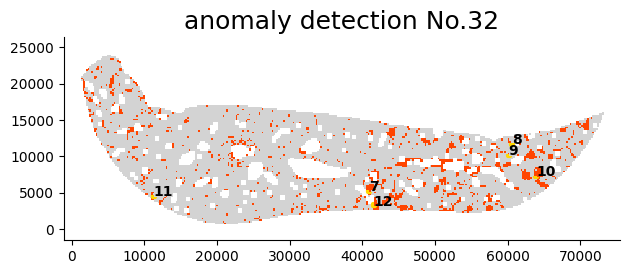

In [179]:
for i in [17, 32]:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    fig_loc = {str(j[1]):j[0] for j in loc_lst if j[2] == i}
    loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection No."+str(i))

In [180]:
patch_size = 224

In [181]:
for n in range(len(loc_lst)):
    if loc_lst[n][2] < 20:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2])+"-シングルファイルエクスポート-"+str(loc_lst[n][2]).zfill(2)+".tif"
        print(filename)
    else:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2]-1)+"-シングルファイルエクスポート-"+str(loc_lst[n][2]-1).zfill(2)+".tif"
        print(filename)

    wsi = OpenSlide(filename)
    print(loc_lst[n][0])
    wsi.read_region(location=tuple(loc_lst[n][1]), level=0, size=(patch_size,patch_size)).convert("RGB").save("workspace/fig/loc_day14_v2/loc"+str(loc_lst[n][0])+".jpg", "JPEG")

workspace/HE_240205_iwasaka/2024_02_05__0626-シングルファイルエクスポート-31.tif
7
workspace/HE_240205_iwasaka/2024_02_05__0612-シングルファイルエクスポート-17.tif
1
workspace/HE_240205_iwasaka/2024_02_05__0626-シングルファイルエクスポート-31.tif
8
workspace/HE_240205_iwasaka/2024_02_05__0626-シングルファイルエクスポート-31.tif
9
workspace/HE_240205_iwasaka/2024_02_05__0612-シングルファイルエクスポート-17.tif
2
workspace/HE_240205_iwasaka/2024_02_05__0626-シングルファイルエクスポート-31.tif
10
workspace/HE_240205_iwasaka/2024_02_05__0612-シングルファイルエクスポート-17.tif
3
workspace/HE_240205_iwasaka/2024_02_05__0626-シングルファイルエクスポート-31.tif
11
workspace/HE_240205_iwasaka/2024_02_05__0626-シングルファイルエクスポート-31.tif
12
workspace/HE_240205_iwasaka/2024_02_05__0612-シングルファイルエクスポート-17.tif
4
workspace/HE_240205_iwasaka/2024_02_05__0612-シングルファイルエクスポート-17.tif
5
workspace/HE_240205_iwasaka/2024_02_05__0612-シングルファイルエクスポート-17.tif
6


###### day7 ######

In [104]:
total_inf_lst = []
for i in [13, 14, 15, 16, 24, 26, 27, 28]:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.13
10718
1482
Percentage of abnormal patches : 0.13827206568389624
max_n =  1482
sample No.14
13769
1419
Percentage of abnormal patches : 0.10305759314401917
max_n =  1419
sample No.15
12268
1523
Percentage of abnormal patches : 0.12414411477013368
max_n =  1523
sample No.16
12915
2090
Percentage of abnormal patches : 0.1618273325590399
max_n =  2090
sample No.24
9790
1381
Percentage of abnormal patches : 0.14106230847803883
max_n =  1381
sample No.26
11352
1468
Percentage of abnormal patches : 0.12931642001409444
max_n =  1468
sample No.27
9841
1573
Percentage of abnormal patches : 0.15984147952443858
max_n =  1573
sample No.28
12140
1290
Percentage of abnormal patches : 0.10626029654036244
max_n =  1290


In [105]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

pict_sample_no =  16
pict_sample_no =  27


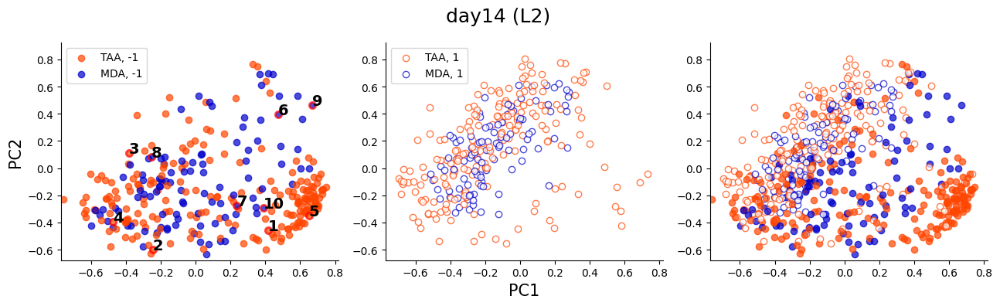

In [137]:
loc_lst = PCAplot_total_v2(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=5, seed1=2477, title="day14 (L2)")

Percentage of abnormal patches : 0.1618273325590399
0.614187157261631


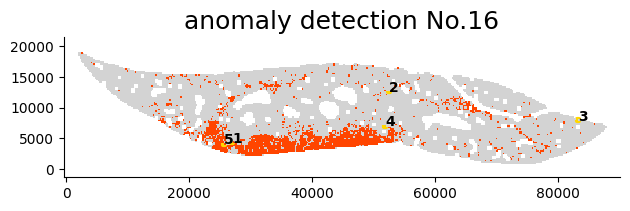

Percentage of abnormal patches : 0.15984147952443858
0.7234840591789956


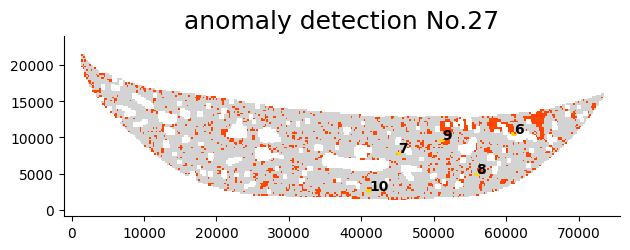

In [115]:
for i in [16, 27]:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v2/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    fig_loc = {str(j[1]):j[0] for j in loc_lst if j[2] == i}
    loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection No."+str(i))

In [116]:
for n in range(len(loc_lst)):
    if loc_lst[n][2] < 20:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2])+"-シングルファイルエクスポート-"+str(loc_lst[n][2]).zfill(2)+".tif"
    else:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2]-1)+"-シングルファイルエクスポート-"+str(loc_lst[n][2]-1).zfill(2)+".tif"

    wsi = OpenSlide(filename)
    wsi.read_region(location=tuple(loc_lst[n][1]), level=0, size=(patch_size,patch_size)).convert("RGB").save("workspace/fig/loc_day7/loc"+str(loc_lst[n][0])+".jpg", "JPEG")

#### data v5 ####

In [7]:
sys.path.append("/workspace")
import sslutils

In [8]:
class Featurize:
    def __init__(self, DEVICE="cpu", lst_size=[], ):
        self.DEVICE=DEVICE
        self.lst_size=lst_size
        self.out_all=[[] for size in self.lst_size]
        self.out_all_pool=[[] for size in self.lst_size]

    def extraction():
        return None

    def featurize(self, model, data_loader, ):
        # featurize
        with torch.inference_mode():
            for data in data_loader:
                data = data.to(self.DEVICE)
                outs = self.extraction(model, data)
                for i, out in enumerate(outs):
                    self.out_all[i].append(out)

    def pooling(self, num_pool_patch:int=200):
        """max pooling"""
        for i, out in enumerate(self.out_all):
            self.out_all_pool[i].append(
                np.max(out.reshape(-1, num_pool_patch, self.lst_size[i]),axis=1)
                )
        # reset output list
        self.out_all=[[] for size in self.lst_size]

    def save_outall(self, folder="", name=""):
        for i, out in enumerate(self.out_all):
            out=np.concatenate(out).astype(np.float32)
            np.save(f"{folder}/{name}_layer{i+1}.npy", out)
        self.out_all=[[] for size in self.lst_size]

    def save_outpool(self, folder="", name=""):
        for i, out in enumerate(self.out_all_pool):
            out=np.concatenate(out).astype(np.float32)
            np.save(f"{folder}/{name}_layer{i+1}.npy", out)

In [9]:
class ResNet18Featurize(Featurize):
    def __init__(self, DEVICE="cpu"):
        super().__init__(
            DEVICE=DEVICE, 
            lst_size=[64,64,128,256,512],
            )
    def extraction(self, model, x):
        x = model[0](x)# conv1
        x = model[1](x)# bn
        x = model[2](x)# relu
        x = model[3](x)# maxpool
        x1 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,64)
        x = model[4](x)# layer1
        x2 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,64)
        x = model[5](x)# layer2
        x3 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,128)
        x = model[6](x)# layer3
        x4 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,256)
        x = model[7](x)# layer4
        x5 = torch.flatten(model[8](x), 1).detach().cpu().numpy().reshape(-1,512)
        return x1, x2, x3, x4, x5

In [10]:
DICT_MODEL = {"ResNet18": [torchvision.models.resnet18, 512, ResNet18Featurize]}

In [11]:
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(DEVICE)
w_pass = "workspace/model.pt"

cuda:0


In [12]:
def prepare_model_eval(
        model_name:str='ResNet18', ssl_name="barlowtwins",  
        model_path="", 
        pretrained=False, 
        DEVICE="cpu"):
    """
    preparation of models
    Parameters
    ----------
        modelname (str)
            model architecture name

    """
    # model building with indicated name
    if pretrained:
        if model_name=="DenseNet121":
            encoder = DICT_MODEL[model_name][0](weights=None)
            encoder = _load_state_dict_dense(encoder, torch.load(model_path))
            model = nn.Sequential(
                *list(encoder.children())[:-1],
                nn.ReLU(inplace=True),
                nn.AdaptiveAvgPool2d((1, 1))
                )
        else:
            encoder = DICT_MODEL[model_name][0](weights=None)
            encoder.load_state_dict(torch.load(model_path))
            model=nn.Sequential(*list(encoder.children())[:-1])
    else:
        encoder = DICT_MODEL[model_name][0](weights=None)
        size = DICT_MODEL[model_name][1]
        if model_name=="DenseNet121":
            backbone = nn.Sequential(
                *list(encoder.children())[:-1],
                nn.ReLU(inplace=True),
                nn.AdaptiveAvgPool2d((1, 1))
                )
        else:
            backbone = nn.Sequential(
                *list(encoder.children())[:-1],
                )
        model = DICT_SSL[ssl_name](DEVICE=DEVICE).prepare_featurize_model(
            backbone, model_path=model_path,
            head_size=size,
        )
    model.to(DEVICE)
    model.eval()
    return model

In [13]:
def get_mask_inside(
    image, 
    patch_size:int=224,
    slice_min_patch:int=1000,
    adjacent_cells_slice=[(-1,0),(1,0),(0,-1),(0,1),],
    adjacent_cells_inside=[(-1,0),(1,0),(0,-1),(0,1),(1,1),(1,-1),(-1,1),(-1,-1)],
    ):
    # load
    level = image.get_best_level_for_downsample(patch_size)
    downsample = image.level_downsamples[level]
    ratio = patch_size / downsample
    whole = image.read_region(location=(0,0), level=level,
        size = image.level_dimensions[level]).convert('HSV')
    whole = whole.resize((int(whole.width / ratio), int(whole.height / ratio)))
    whole = np.array(whole, dtype=np.uint8)
    # get mask
    saturation = whole[:,:,1] #saturation
    threshold, _ = cv2.threshold(saturation, 0, 255, cv2.THRESH_OTSU)
    mask = saturation > threshold
    # get slices > slice_min_patch
    left_mask = np.full((mask.shape[0]+1, mask.shape[1]+1), fill_value=False, dtype=bool)
    left_mask[:-1, :-1] = mask
    n_left_mask = np.sum(left_mask)
    slice_idx = np.full_like(mask, fill_value=-1, dtype=int)
    i_slice = 0
    while n_left_mask > 0:
        mask_i = np.where(left_mask)
        slice_left_indices = [(mask_i[0][0], mask_i[1][0])]
        while len(slice_left_indices) > 0:
            i, j = slice_left_indices.pop()
            if left_mask[i, j]:
                slice_idx[i, j] = i_slice
                for adj_i, adj_j in adjacent_cells_slice:
                    if left_mask[i+adj_i, j+adj_j]:
                        slice_left_indices.append((i+adj_i, j+adj_j))
                left_mask[i, j] = False
                n_left_mask -= 1
        slice_mask = slice_idx == i_slice
        if np.sum(slice_mask) < slice_min_patch:
            slice_idx[slice_mask] = -1
        else:
            i_slice += 1
    # re-difinition mask
    mask=slice_idx>-1
    # get inside mask
    mask_inside=np.zeros(mask.shape, dtype=bool)
    for i in range(1,mask.shape[0]-1):
        for v in range(1,mask.shape[1]-1):
            tf = mask[i][v]
            if tf:
                for adj in adjacent_cells_inside:
                    tf&=mask[i+adj[0]][v+adj[1]]
            mask_inside[i][v]=tf
    return mask_inside

In [14]:
# DataLoader
class DatasetWSI(torch.utils.data.Dataset):
    def __init__(
        self,
        filein:str="",
        transform=None,
        patch_size=224,
        num_patch=None, random_state=24771,
        ):
        # set transform
        if type(transform)!=list:
            self._transform = [transform]
        else:
            self._transform = transform
        # load data
        self.wsi = OpenSlide(filein)
        mask_inside=get_mask_inside(self.wsi, patch_size=patch_size)
        lst_number=np.array(range(len(mask_inside.flatten())))[mask_inside.flatten()]
        self.lst_location=[[int(patch_size*v) for v in divmod(number, mask_inside.shape[1])][::-1] for number in lst_number]
        self.datanum = len(self.lst_location)
        self.patch_size=patch_size

    def __len__(self):
        return self.datanum

    def __getitem__(self,idx):
        out_data=self.wsi.read_region(
            location=tuple(self.lst_location[idx]),
            level=0,
            size=(self.patch_size, self.patch_size),
            )
        out_data = np.array(out_data, np.uint8)[:,:,:3]
        out_data = Image.fromarray(out_data).convert("RGB")
        if self._transform:
            for t in self._transform:
                out_data = t(out_data)
        return out_data

In [15]:
def prepare_dataset(filein:str="", patch_size:int=224, batch_size:int=32, num_patch=None,):
    """
    data preparation
    
    """
    # normalization
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                        std=[0.229, 0.224, 0.225])
    data_transform = transforms.Compose([
        transforms.CenterCrop((224,224)),
        transforms.ToTensor(),
        normalize
    ])
    # data
    dataset = DatasetWSI(
        filein=filein,
        transform=data_transform,
        num_patch=num_patch,
        patch_size=patch_size,
        )
    # to loader
    data_loader = prep_dataloader(
        dataset, batch_size=batch_size, 
        shuffle=False,
        drop_last=False)
    return data_loader, dataset.lst_location

In [16]:
def featurize_layer(
    model_name="", ssl_name="", model_path="", pretrained=False,
    lst_filein=list(), lst_filename=list(), dir_result="",
    num_pool_patch=None, num_patch=None,
    batch_size=128, patch_size=224,
    DEVICE="cpu", ):
    """featurize module"""
    # load model
    model=prepare_model_eval(
        model_name=model_name, ssl_name=ssl_name,  
        model_path=model_path, 
        pretrained=pretrained, 
        DEVICE=DEVICE
        )
    extract_class = DICT_MODEL[model_name][2](DEVICE=DEVICE)
    # result dir
    if not os.path.exists(dir_result):
        os.makedirs(dir_result)
    # featurize
    for filein, filename in zip(lst_filein, lst_filename):
        data_loader, lst_location=prepare_dataset(filein=filein, batch_size=batch_size, patch_size=patch_size, num_patch=num_patch)
        extract_class.featurize(model, data_loader)
        if num_pool_patch:
            extract_class.pooling(num_pool_patch=num_pool_patch)
            extract_class.save_outpool(folder=dir_result, name=filename)
        else:
            extract_class.save_outall(folder=dir_result, name=filename)
        pd.to_pickle(lst_location, f"{dir_result}/{filename}_location.pickle")

In [17]:
dir_path = "/workspace/HE_240205_iwasaka"
file_lst = os.listdir(dir_path)
filein_lst = ["workspace/HE_240205_iwasaka/"+i for i in file_lst if ".tif" in i]
r_pass = "workspace/result_v5"

In [18]:
filename_lst = [i.split("-")[2].split(".t")[0] for i in filein_lst]
num_lst =[]
ap = num_lst.append
for i in filename_lst:
    if int(i) < 20:
        ap(int(i))
    else:
        ap(int(i)+1)

In [19]:
DICT_SSL={
    "barlowtwins":sslutils.BarlowTwins,
    "swav":sslutils.SwaV,
    "byol":sslutils.Byol,
    "simsiam":sslutils.SimSiam,
    "wsl":sslutils.WSL,
}

In [20]:
featurize_layer(
    model_name="ResNet18", ssl_name="wsl", model_path=w_pass, pretrained=False,
    lst_filein=filein_lst, lst_filename=num_lst, dir_result=r_pass,
    num_pool_patch=None, num_patch=None,
    batch_size=128,
    DEVICE=DEVICE, )

In [11]:
f_path_1 = "workspace/result_v5/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v5/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v5/3_layer4.npy"
feature_3 = np.load(f_path_3)
f_path_4 = "workspace/result_v5/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v5/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v5/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v5/7_layer4.npy"
feature_7 = np.load(f_path_7)
f_path_8 = "workspace/result_v5/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v5/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v5/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v5/11_layer4.npy"
feature_11 = np.load(f_path_11)
f_path_12 = "workspace/result_v5/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1)+list(feature_2)+list(feature_3)+list(feature_4)+list(feature_5)+list(feature_6)+list(feature_7)+list(feature_8)+list(feature_9)+list(feature_10)+list(feature_11)+list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask_inside_wsl = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [13]:
sample_n = [4, 8, 12]
for i in sample_n:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/(len([i for i in jud if i == 1]) + len([i for i in jud if i == -1]))))

sample No.4
13999
1136
Percentage of abnormal patches : 0.07505781301618765
sample No.8
13157
1046
Percentage of abnormal patches : 0.07364641272970499
sample No.12
12231
997
Percentage of abnormal patches : 0.07537042636830965


In [24]:
bach_dict = {}
comp_lst = ["Control"]*12+["TAA"]*12+["MDA"]*12
for i in range(36):
    bach_dict[i+1] = comp_lst[i]

day_dict = {}
day_lst = [7]*4+[14]*4+[28]*4
day_lst = day_lst*3
for i in range(36):
    day_dict[i+1] = day_lst[i]

inf_dict = {}
percentage_lst = []
ap = percentage_lst.append
sample_n = [13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
for i in sample_n:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    ap(len([i for i in jud if i == -1])/len([i for i in jud if i == 1]))
inf_dict["compound"] = [bach_dict[i] for i in sample_n]
inf_dict["day"] = [day_dict[i] for i in sample_n]
inf_dict["percentage"] = percentage_lst

df_p = pd.DataFrame.from_dict(inf_dict)
df_p.index = sample_n
taa = df_p.loc[24, "compound":"day"]
mda = df_p.loc[25, "compound":"day"]
df_p.loc[24, "compound":"day"] = mda
df_p.loc[25, "compound":"day"] = taa

sample No.13
10333
1867
Percentage of abnormal patches : 0.18068324784670473
sample No.14
13843
1345
Percentage of abnormal patches : 0.09716102001011341
sample No.15
12327
1464
Percentage of abnormal patches : 0.11876368946215624
sample No.16
12863
2142
Percentage of abnormal patches : 0.16652413900334292
sample No.17
11942
1457
Percentage of abnormal patches : 0.12200636409311673
sample No.18
9367
931
Percentage of abnormal patches : 0.09939148073022312
sample No.19
11851
1059
Percentage of abnormal patches : 0.08935954771749219
sample No.21
7919
980
Percentage of abnormal patches : 0.12375299911605
sample No.22
9745
1385
Percentage of abnormal patches : 0.14212416623909696
sample No.23
12146
1025
Percentage of abnormal patches : 0.0843899226082661
sample No.24
9050
2121
Percentage of abnormal patches : 0.2343646408839779
sample No.25
10844
1930
Percentage of abnormal patches : 0.17797860568056068
sample No.26
10333
2487
Percentage of abnormal patches : 0.24068518339301267
sample No.

In [46]:
bach_dict[24] = "MDA"
bach_dict[25] = "TAA"

In [25]:
def ratio_plot(df_p, title="Abnormal Patch Ratio"):
    fig = plt.figure(figsize=(10, 7))
    y_max = max(df_p.loc[:, "percentage"])*1.1
    for i, d in enumerate([7, 14, 28]):
        df_p_day = df_p.loc[[df_p.loc[i, "day"] == d for i in df_p.index.tolist()], :]

        df_mda = df_p_day.loc[[df_p_day.loc[i, "compound"] == "MDA" for i in df_p_day.index.tolist()], :]
        df_mda = df_mda.loc[:, ["percentage"]]
        df_taa = df_p_day.loc[[df_p_day.loc[i, "compound"] == "TAA" for i in df_p_day.index.tolist()], :]
        df_taa = df_taa.loc[:, ["percentage"]]

        ax = fig.add_subplot(1, 3, i+1)
        ax2 = ax.twinx()

        width = 0.4
        x_position = np.arange(1)
        error_bar_set = dict(lw = 1.5, capthick = 1.5, capsize = 4)
        ax.bar(x_position+width/2, df_mda.mean(), yerr=df_mda.std(), tick_label=df_mda.columns, error_kw=error_bar_set, color='royalblue', width=0.97*width, label="MDA", alpha=.8)
        ax.bar(x_position-width/2, df_taa.mean(), yerr=df_taa.std(), tick_label=df_mda.columns, error_kw=error_bar_set, color='coral', width=0.97*width, label="TAA", alpha=.8)
        ax.bar(x_position, df_taa.mean(), tick_label=df_mda.columns, color='white', width=0, alpha=.1) # Adjustment of ticklabels position

        ax.legend(fontsize=18, loc=(0.5, 0.82))
        plt.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        # jitter plot
        sns.stripplot(x='day', y='percentage', data=df_p_day, hue='compound', dodge=True, jitter=True, s=7, linewidth=1, edgecolor="black", palette=['orangered', 'mediumblue'], ax=ax2)
        # control line
        ax.hlines(y=0.05, xmin=-1.2*width, xmax=1.2*width, color="black", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

        ax.tick_params(axis='x', labelsize=16, direction='in', width=0)
        ax.tick_params(axis='y', labelsize=16)

        ax.set_xlim(-1.2*width,1.2*width)
        ax2.set_xlim(-1.2*width,1.2*width)
        ax.set_ylim(0,y_max)
        ax2.set_ylim(0,y_max)

        ax2.axis("off")
        ax2.get_legend().remove()

        if i == 0:
            ax.set_ylabel("raito", fontsize=20)
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()         
        elif i == len([7, 14, 28])-1:
            ax.set_xticklabels(["day"+str(d)])
        else:
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()  

    fig.suptitle(title, fontsize=24)
    plt.tight_layout()
    plt.show()

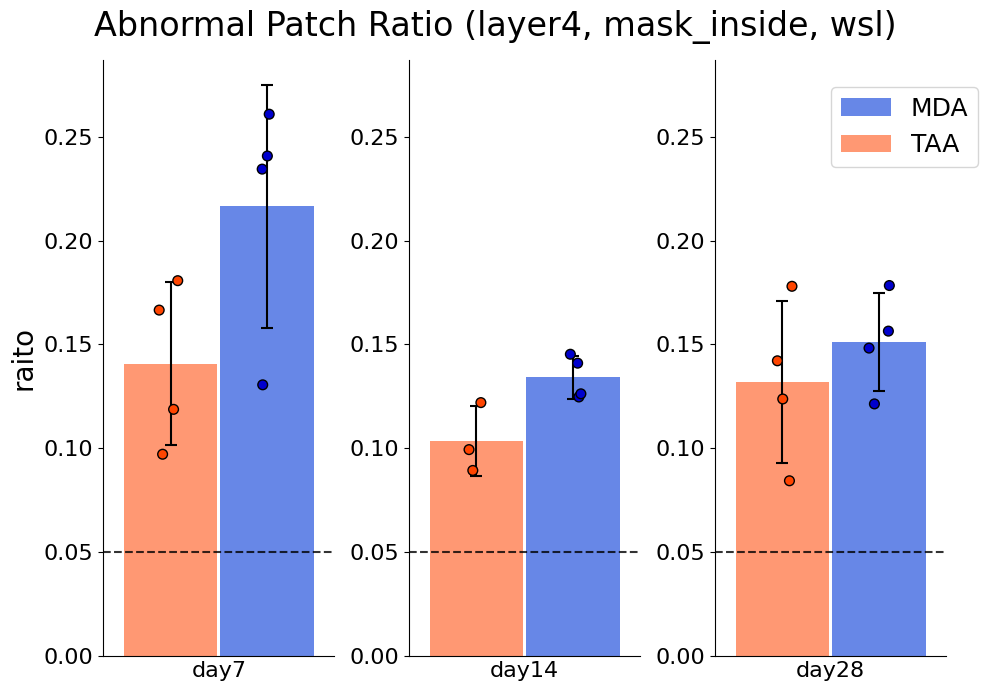

In [26]:
ratio_plot(df_p, title="Abnormal Patch Ratio (layer4, mask_inside, wsl)")

In [27]:
sample_n = [4, 8, 12]
for i in sample_n:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))

sample No.4
13999
1136
Percentage of abnormal patches : 0.08114865347524823
sample No.8
13157
1046
Percentage of abnormal patches : 0.0795014060956145
sample No.12
12231
997
Percentage of abnormal patches : 0.08151418526694465


In [28]:
def get_info(sample_id, feature, location, jud):
    inf_lst = []
    max_n = len([i for i in jud if i == -1])
    print("max_n = ", str(max_n))
    n = 0
    ap = inf_lst.append
    for i in zip(jud, feature, location):
        if i[0] == -1:
            ap([sample_id, i[1], i[2], i[0]])
        elif i[0] == 1 and n < max_n:
            ap([sample_id, i[1], i[2], i[0]])
            n = n + 1
        else:
            pass

    return inf_lst

In [30]:
total_inf_lst = []
for i in [17, 18, 19, 29, 30, 31, 32]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.17
11942
1457
Percentage of abnormal patches : 0.12200636409311673
max_n =  1457
sample No.18
9367
931
Percentage of abnormal patches : 0.09939148073022312
max_n =  931
sample No.19
11851
1059
Percentage of abnormal patches : 0.08935954771749219
max_n =  1059
sample No.29
12810
1806
Percentage of abnormal patches : 0.14098360655737704
max_n =  1806
sample No.30
12260
1529
Percentage of abnormal patches : 0.12471451876019576
max_n =  1529
sample No.31
14433
1822
Percentage of abnormal patches : 0.12623848125822767
max_n =  1822
sample No.32
12514
1818
Percentage of abnormal patches : 0.14527728943583187
max_n =  1818


In [31]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

In [32]:
# 第一主成分と第二主成分でプロットする
def PCAplot_total_v2(feature_pca, pca_inf, bach_dict, seed1=2477, sample=100, pict_sample=3, xnum=0, ynum=1, title=""):
    fig = plt.figure(figsize=(13, 4))
    ax1 = fig.add_subplot(1, 3, 3)
    ax2 = fig.add_subplot(1, 3, 1)
    ax3 = fig.add_subplot(1, 3, 2)

    label_lst = []
    ap = label_lst.append
    sample_no_lst = []
    ap_s = sample_no_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature_pca)), sample)

    color_dict = {"Control":"dimgray","TAA":"orangered", "MDA":"mediumblue"}

    xmax = max(feature_pca[:, xnum])
    xmin = min(feature_pca[:, xnum])
    ymax = max(feature_pca[:, ynum])
    ymin = min(feature_pca[:, ynum])

    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if bach_dict[pca_inf[i][0]] + ", -1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", -1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
                ap_s(pca_inf[i][0])
                print("pict_sample_no = ", str(pca_inf[i][0]))
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and -0.5 < feature_pca[:, xnum][i] < 0.1 and -0.7 < feature_pca[:, ynum][i] < -0.45:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="red", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and -0.65 < feature_pca[:, xnum][i] < -0.1 and -0.2 < feature_pca[:, ynum][i] < 0.2:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="red", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
        else:
            if bach_dict[pca_inf[i][0]] + ", 1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", 1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])

    for ax in [ax2, ax3, ax1]:
        #ax.set_title("", fontsize=18)

        ax.set_xlim(xmin,xmax)
        ax.set_ylim(ymin,ymax)

        ax.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        ax.spines.bottom.set_color('black')
        ax.spines.left.set_color('black')
    
    ax2.hlines(y=-0.45, xmin=-0.5, xmax=0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=-0.7, xmin=-0.5, xmax=0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=-0.5, ymin=-0.7, ymax=-0.45, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=0.1, ymin=-0.7, ymax=-0.45, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.hlines(y=0.2, xmin=-0.65, xmax=-0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=-0.2, xmin=-0.65, xmax=-0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=-0.65, ymin=-0.2, ymax=0.2, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=-0.1, ymin=-0.2, ymax=0.2, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.legend()
    ax3.legend() 
    ax3.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax2.set_ylabel("PC"+str(ynum+1), fontsize=15)

    fig.suptitle(title, fontsize=18)

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

    return loc_lst

pict_sample_no =  32
pict_sample_no =  18


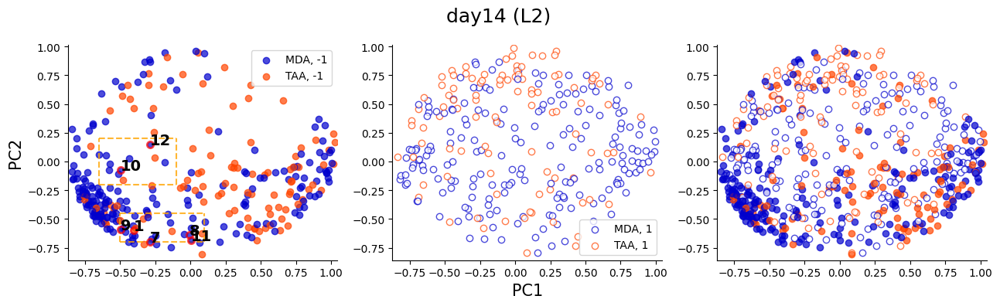

In [34]:
loc_lst = PCAplot_total_v2(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=6, seed1=24771, title="day14 (L2)")

In [35]:
total_inf_lst

[[17,
  array([ 0.5421057 , -0.28297573,  1.028725  ,  0.7615399 ,  1.5786878 ,
          1.5214083 ,  0.57937515, -0.49027336, -0.39022207,  1.5978312 ,
         -1.4251645 ,  0.6968591 , -0.95185775,  0.47484833,  1.2777388 ,
          0.18671931,  1.1959455 , -0.6312932 ,  0.44969654,  0.17638254,
         -1.4188013 ,  1.2048514 , -1.2622908 ,  0.16260673,  0.4447077 ,
          1.5823594 ,  0.5876338 , -0.02245691, -0.81028175, -0.4129311 ,
          1.6690716 , -0.67647135, -0.9195209 ,  0.00980322, -0.24172446,
          0.50275123,  1.2329688 ,  1.0267185 ,  1.3723851 ,  0.09030183,
         -0.4192149 , -1.1483042 , -0.5083523 ,  1.2611803 , -0.39317968,
         -0.7235562 , -0.8559469 , -1.0835881 , -1.2749825 ,  0.47222912,
         -0.7325142 ,  0.8004185 , -0.5902186 ,  0.80514246, -0.3828927 ,
         -1.3417095 ,  1.2441038 ,  0.1564469 , -1.0663705 , -1.4434432 ,
          0.9584641 ,  0.7168045 , -1.2651966 , -0.40324843,  0.3304021 ,
         -0.63175327, -0.0142637

In [38]:
def loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    print(size)
    if size < 1:
        size = 1

    for i in zip(jud, location):
        if i[0] == -1:
            if str(i[1]) in [key for key in fig_loc.keys()]:
                ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=3, edgecolors="gold")
                ax.text(i[1][0]+loc, i[1][1]-loc, s=fig_loc[str(i[1])],  weight="bold")
            else:
                ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="lightgray", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

Percentage of abnormal patches : 0.09939148073022312
0.8558047818585162


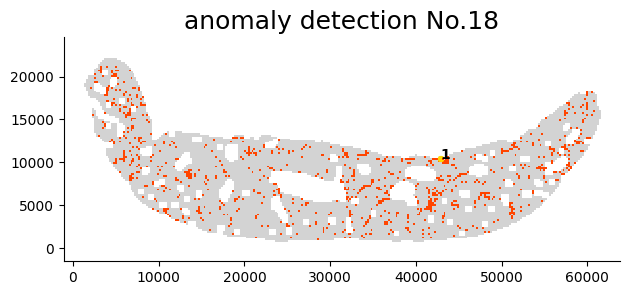

Percentage of abnormal patches : 0.14527728943583187
0.7256008359456636


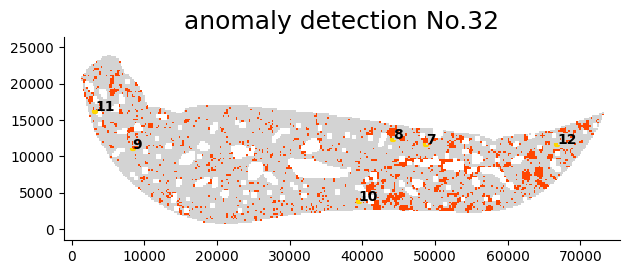

In [39]:
for i in [18, 32]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    fig_loc = {str(j[1]):j[0] for j in loc_lst if j[2] == i}
    loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection No."+str(i))

In [40]:
total_inf_lst = []
for i in [13, 14, 15, 16, 24, 26, 27, 28]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.13
10333
1867
Percentage of abnormal patches : 0.18068324784670473
max_n =  1867
sample No.14
13843
1345
Percentage of abnormal patches : 0.09716102001011341
max_n =  1345
sample No.15
12327
1464
Percentage of abnormal patches : 0.11876368946215624
max_n =  1464
sample No.16
12863
2142
Percentage of abnormal patches : 0.16652413900334292
max_n =  2142
sample No.24
9050
2121
Percentage of abnormal patches : 0.2343646408839779
max_n =  2121
sample No.26
10333
2487
Percentage of abnormal patches : 0.24068518339301267
max_n =  2487
sample No.27
9053
2361
Percentage of abnormal patches : 0.26079752568209436
max_n =  2361
sample No.28
11879
1551
Percentage of abnormal patches : 0.13056654600555603
max_n =  1551


In [41]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

In [61]:
# 第一主成分と第二主成分でプロットする
def PCAplot_total_v2(feature_pca, pca_inf, bach_dict, seed1=2477, sample=100, pict_sample=3, loc1=[-0.8, -0.5, -0.25, 0.25], loc2=[0.5, 0.8, -0.6, -0.1], xnum=0, ynum=1, title=""):
    fig = plt.figure(figsize=(13, 4))
    ax1 = fig.add_subplot(1, 3, 3)
    ax2 = fig.add_subplot(1, 3, 1)
    ax3 = fig.add_subplot(1, 3, 2)

    label_lst = []
    ap = label_lst.append
    sample_no_lst = []
    ap_s = sample_no_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature_pca)), sample)

    color_dict = {"Control":"dimgray","TAA":"orangered", "MDA":"mediumblue"}

    xmax = max(feature_pca[:, xnum])
    xmin = min(feature_pca[:, xnum])
    ymax = max(feature_pca[:, ynum])
    ymin = min(feature_pca[:, ynum])

    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if bach_dict[pca_inf[i][0]] + ", -1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", -1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
                ap_s(pca_inf[i][0])
                print("pict_sample_no = ", str(pca_inf[i][0]))
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and loc1[0] < feature_pca[:, xnum][i] < loc1[1] and loc1[2] < feature_pca[:, ynum][i] < loc1[3]:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="red", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and loc2[0] < feature_pca[:, xnum][i] < loc2[1] and loc2[2] < feature_pca[:, ynum][i] < loc2[3]:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="red", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
        else:
            if bach_dict[pca_inf[i][0]] + ", 1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", 1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])

    for ax in [ax2, ax3, ax1]:
        #ax.set_title("", fontsize=18)

        ax.set_xlim(xmin,xmax)
        ax.set_ylim(ymin,ymax)

        ax.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        ax.spines.bottom.set_color('black')
        ax.spines.left.set_color('black')
    
    ax2.hlines(y=loc1[3], xmin=loc1[0], xmax=loc1[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=loc1[2], xmin=loc1[0], xmax=loc1[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc1[0], ymin=loc1[2], ymax=loc1[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc1[1], ymin=loc1[2], ymax=loc1[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.hlines(y=loc2[3], xmin=loc2[0], xmax=loc2[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=loc2[2], xmin=loc2[0], xmax=loc2[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc2[0], ymin=loc2[2], ymax=loc2[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc2[1], ymin=loc2[2], ymax=loc2[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.legend()
    ax3.legend() 
    ax3.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax2.set_ylabel("PC"+str(ynum+1), fontsize=15)

    fig.suptitle(title, fontsize=18)

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

    return loc_lst

pict_sample_no =  16
pict_sample_no =  28


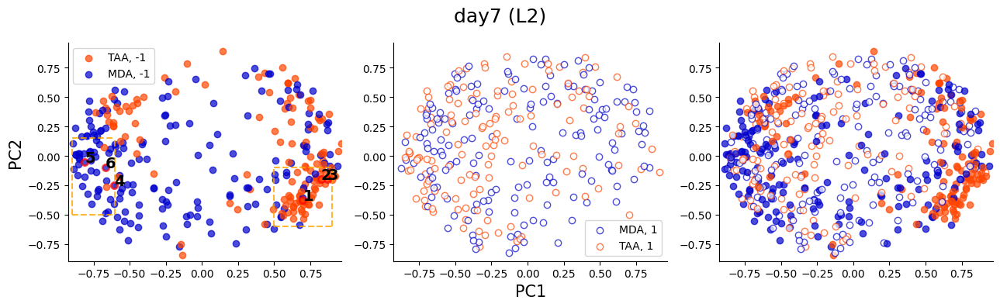

In [65]:
loc_lst = PCAplot_total_v2(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=3, loc1=[-0.9, -0.6, -0.5, 0.15], loc2=[0.5, 0.9, -0.6, -0.1], seed1=24771, title="day7 (L2)")

In [66]:
loc_lst

[[1, [36960, 3584], 16],
 [2, [38528, 4704], 16],
 [3, [35840, 4704], 16],
 [4, [30912, 3136], 28],
 [5, [37408, 3808], 28],
 [6, [56448, 14112], 28]]

Percentage of abnormal patches : 0.16652413900334292
0.614187157261631


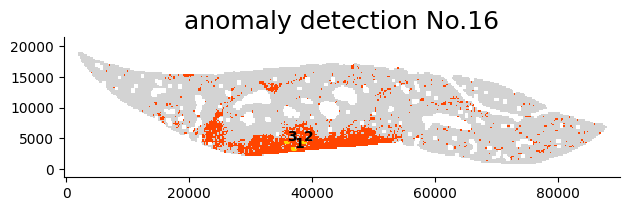

Percentage of abnormal patches : 0.13056654600555603
0.7341932755339395


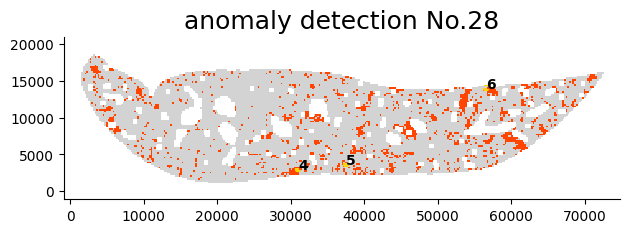

In [69]:
for i in [16, 28]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    fig_loc = {str(j[1]):j[0] for j in loc_lst if j[2] == i}
    loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection No."+str(i))

In [70]:
patch_size = 224

In [72]:
for n in range(len(loc_lst)):
    if loc_lst[n][2] < 20:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2])+"-シングルファイルエクスポート-"+str(loc_lst[n][2]).zfill(2)+".tif"
        print(filename)
    else:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2]-1)+"-シングルファイルエクスポート-"+str(loc_lst[n][2]-1).zfill(2)+".tif"
        print(filename)

    wsi = OpenSlide(filename)
    print(loc_lst[n][0])
    wsi.read_region(location=tuple(loc_lst[n][1]), level=0, size=(patch_size,patch_size)).convert("RGB").save("workspace/fig/loc_day14_wsl/loc"+str(loc_lst[n][0])+".jpg", "JPEG")

workspace/HE_240205_iwasaka/2024_02_05__0611-シングルファイルエクスポート-16.tif
1
workspace/HE_240205_iwasaka/2024_02_05__0611-シングルファイルエクスポート-16.tif
2
workspace/HE_240205_iwasaka/2024_02_05__0611-シングルファイルエクスポート-16.tif
3
workspace/HE_240205_iwasaka/2024_02_05__0622-シングルファイルエクスポート-27.tif
4
workspace/HE_240205_iwasaka/2024_02_05__0622-シングルファイルエクスポート-27.tif
5
workspace/HE_240205_iwasaka/2024_02_05__0622-シングルファイルエクスポート-27.tif
6


In [73]:
total_inf_lst = []
for i in [17, 18, 19, 29, 30, 31, 32]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.17
11942
1457
Percentage of abnormal patches : 0.12200636409311673
max_n =  1457
sample No.18
9367
931
Percentage of abnormal patches : 0.09939148073022312
max_n =  931
sample No.19
11851
1059
Percentage of abnormal patches : 0.08935954771749219
max_n =  1059
sample No.29
12810
1806
Percentage of abnormal patches : 0.14098360655737704
max_n =  1806
sample No.30
12260
1529
Percentage of abnormal patches : 0.12471451876019576
max_n =  1529
sample No.31
14433
1822
Percentage of abnormal patches : 0.12623848125822767
max_n =  1822
sample No.32
12514
1818
Percentage of abnormal patches : 0.14527728943583187
max_n =  1818


In [74]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

pict_sample_no =  30
pict_sample_no =  17


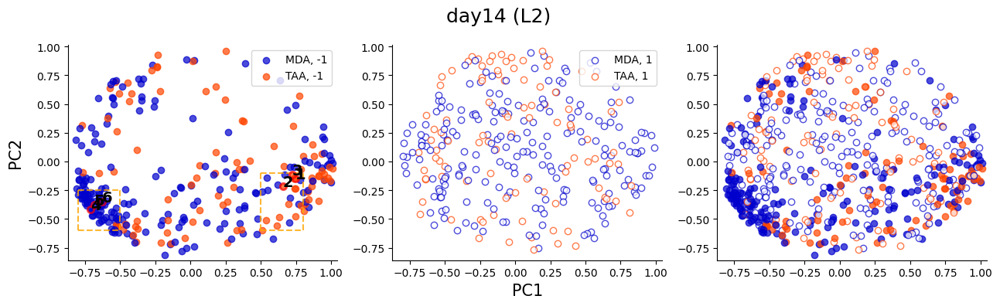

In [77]:
loc_lst = PCAplot_total_v2(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=3, loc1=[-0.8, -0.5, -0.6, -0.25], loc2=[0.5, 0.8, -0.6, -0.1], seed1=2477, title="day14 (L2)")

Percentage of abnormal patches : 0.12200636409311673
0.7659386719611736


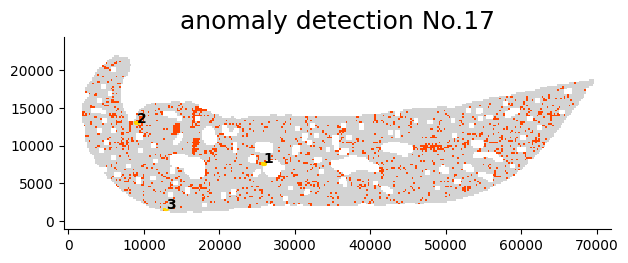

Percentage of abnormal patches : 0.12471451876019576
0.6779925795743019


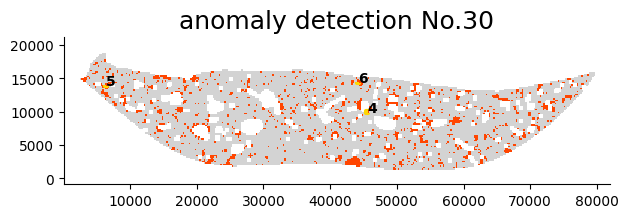

In [78]:
for i in [17, 30]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    fig_loc = {str(j[1]):j[0] for j in loc_lst if j[2] == i}
    loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection No."+str(i))

In [79]:
for n in range(len(loc_lst)):
    if loc_lst[n][2] < 20:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2])+"-シングルファイルエクスポート-"+str(loc_lst[n][2]).zfill(2)+".tif"
        print(filename)
    else:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2]-1)+"-シングルファイルエクスポート-"+str(loc_lst[n][2]-1).zfill(2)+".tif"
        print(filename)

    wsi = OpenSlide(filename)
    print(loc_lst[n][0])
    wsi.read_region(location=tuple(loc_lst[n][1]), level=0, size=(patch_size,patch_size)).convert("RGB").save("workspace/fig/loc_day7_wsl/loc"+str(loc_lst[n][0])+".jpg", "JPEG")

workspace/HE_240205_iwasaka/2024_02_05__0624-シングルファイルエクスポート-29.tif
4
workspace/HE_240205_iwasaka/2024_02_05__0624-シングルファイルエクスポート-29.tif
5
workspace/HE_240205_iwasaka/2024_02_05__0612-シングルファイルエクスポート-17.tif
1
workspace/HE_240205_iwasaka/2024_02_05__0624-シングルファイルエクスポート-29.tif
6
workspace/HE_240205_iwasaka/2024_02_05__0612-シングルファイルエクスポート-17.tif
2
workspace/HE_240205_iwasaka/2024_02_05__0612-シングルファイルエクスポート-17.tif
3


In [11]:
f_path_1 = "workspace/result_v5/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v5/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v5/3_layer4.npy"
feature_3 = np.load(f_path_3)
f_path_4 = "workspace/result_v5/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v5/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v5/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v5/7_layer4.npy"
feature_7 = np.load(f_path_7)
f_path_8 = "workspace/result_v5/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v5/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v5/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v5/11_layer4.npy"
feature_11 = np.load(f_path_11)
f_path_12 = "workspace/result_v5/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1)+list(feature_2)+list(feature_3)+list(feature_4)+list(feature_5)+list(feature_6)+list(feature_7)+list(feature_8)+list(feature_9)+list(feature_10)+list(feature_11)+list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = 'scale' #一旦適当
ocsvm_224_mask_inside_wsl = OCSVM(kernel="rbf", gamma=gamma, nu=nu, tol=1e-4).fit(feature_scaled)

In [22]:
sample_n = [1, 3, 4, 6, 8, 11, 12]
for i in sample_n:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))

sample No.1
13705
1036
Percentage of abnormal patches : 0.07559284932506384
sample No.3
11856
1094
Percentage of abnormal patches : 0.09227395411605938
sample No.4
13999
1136
Percentage of abnormal patches : 0.08114865347524823
sample No.6
11750
1332
Percentage of abnormal patches : 0.11336170212765957
sample No.8
13157
1046
Percentage of abnormal patches : 0.0795014060956145
sample No.11
9761
945
Percentage of abnormal patches : 0.09681385103985247
sample No.12
12231
997
Percentage of abnormal patches : 0.08151418526694465


In [16]:
12231 + 997

13228

In [15]:
len(feature_12)

13228

In [17]:
len(feature_12[0])

256

In [21]:
len(feature_scaled)

154420

In [19]:
len(f_conc)

154420

In [20]:
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)
len(feature_scaled)

154420

In [14]:
feature_scaled

array([[ 0.7616578 , -0.32958576,  0.44037563, ...,  1.7354193 ,
         0.4096064 ,  0.1485756 ],
       [ 1.2928796 , -0.39809996,  0.5198674 , ...,  1.5637683 ,
         1.4335082 , -0.17300257],
       [ 0.18845947,  0.6144834 ,  0.3413368 , ...,  0.44465047,
         0.9647329 ,  0.29816765],
       ...,
       [-0.981881  , -0.30182743, -0.31920418, ..., -0.07725681,
        -0.9791536 , -0.8680015 ],
       [ 0.69726884, -0.47636855, -0.07977686, ...,  1.9038559 ,
        -0.73530596, -0.8788617 ],
       [ 1.0169995 , -0.45227784, -0.12068252, ...,  1.0551664 ,
         0.5432054 , -0.5410292 ]], dtype=float32)

In [23]:
f_path_1 = "workspace/result_v2/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v2/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v2/3_layer4.npy"
feature_3 = np.load(f_path_3)
f_path_4 = "workspace/result_v2/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v2/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v2/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v2/7_layer4.npy"
feature_7 = np.load(f_path_7)
f_path_8 = "workspace/result_v2/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v2/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v2/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v2/11_layer4.npy"
feature_11 = np.load(f_path_11)
f_path_12 = "workspace/result_v2/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1)+list(feature_2)+list(feature_3)+list(feature_4)+list(feature_5)+list(feature_6)+list(feature_7)+list(feature_8)+list(feature_9)+list(feature_10)+list(feature_11)+list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = "auto" #一旦適当
ocsvm_224_mask_inside = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [25]:
sample_n = [1, 3, 4, 6, 8, 11, 12]
for i in sample_n:
    f_path = "workspace/result_v2/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))

sample No.1
13887
854
Percentage of abnormal patches : 0.06149636350543674
sample No.3
12202
748
Percentage of abnormal patches : 0.0613014259957384
sample No.4
14081
1054
Percentage of abnormal patches : 0.07485263830693843
sample No.6
12380
702
Percentage of abnormal patches : 0.056704361873990305
sample No.8
13398
805
Percentage of abnormal patches : 0.060083594566353184
sample No.11
10057
649
Percentage of abnormal patches : 0.06453216665009447
sample No.12
12503
725
Percentage of abnormal patches : 0.0579860833399984


#### check ocsvm parameter ####

In [14]:
f_path_1 = "workspace/result_v5/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v5/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v5/3_layer4.npy"
feature_3 = np.load(f_path_3)
f_path_4 = "workspace/result_v5/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v5/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v5/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v5/7_layer4.npy"
feature_7 = np.load(f_path_7)
f_path_8 = "workspace/result_v5/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v5/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v5/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v5/11_layer4.npy"
feature_11 = np.load(f_path_11)
f_path_12 = "workspace/result_v5/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1)+list(feature_2)+list(feature_3)+list(feature_4)+list(feature_5)+list(feature_6)+list(feature_7)+list(feature_8)+list(feature_9)+list(feature_10)+list(feature_11)+list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

In [15]:
feature_scaled_total = scaler.fit_transform(f_conc)

In [17]:
for gamma in [0.5, 0.1, 0.05, 0.05, 1/256, "auto"]:
    print("------- gamma =", str(gamma), "------")
    nu = 0.05 #5%ぐらいは許容
    ocsvm_224_mask_inside_wsl = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled_total)
    sample_n = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
    for i in sample_n:
        f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
        feature = np.load(f_path)
        feature_scaled = scaler.fit_transform(feature)
        jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
        print("sample No."+str(i))
        if len([i for i in jud if i == 1]) == 0:
            print("Percentage of abnormal patches : 1.0")
        else:
            print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/(len([i for i in jud if i == 1]) + len([i for i in jud if i == -1]))))
    print("\n")

------- gamma = 0.5 ------
sample No.1
Percentage of abnormal patches : 1.0
sample No.2
Percentage of abnormal patches : 1.0
sample No.3
Percentage of abnormal patches : 1.0
sample No.4
Percentage of abnormal patches : 1.0
sample No.5
Percentage of abnormal patches : 1.0
sample No.6
Percentage of abnormal patches : 1.0
sample No.7
Percentage of abnormal patches : 1.0
sample No.8
Percentage of abnormal patches : 1.0
sample No.9
Percentage of abnormal patches : 1.0
sample No.10
Percentage of abnormal patches : 1.0
sample No.11
Percentage of abnormal patches : 1.0
sample No.12
Percentage of abnormal patches : 1.0


------- gamma = 0.1 ------
sample No.1
Percentage of abnormal patches : 0.9987110779458652
sample No.2
Percentage of abnormal patches : 0.99914350970689
sample No.3
Percentage of abnormal patches : 1.0
sample No.4
Percentage of abnormal patches : 0.9959035348529898
sample No.5
Percentage of abnormal patches : 0.9994900885971063
sample No.6
Percentage of abnormal patches : 0.976

In [19]:
for gamma in [1/(256*2), 1/(256*3), "scale"]:
    print("------- gamma =", str(gamma), "------")
    nu = 0.05 #5%ぐらいは許容
    ocsvm_224_mask_inside_wsl = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled_total)
    sample_n = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
    for i in sample_n:
        f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
        feature = np.load(f_path)
        feature_scaled = scaler.fit_transform(feature)
        jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
        print("sample No."+str(i))
        if len([i for i in jud if i == 1]) == 0:
            print("Percentage of abnormal patches : 1.0")
        else:
            print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/(len([i for i in jud if i == 1]) + len([i for i in jud if i == -1]))))
    print("\n")

------- gamma = 0.001953125 ------


sample No.1
Percentage of abnormal patches : 0.06078285055287972
sample No.2
Percentage of abnormal patches : 0.0621431290445375
sample No.3
Percentage of abnormal patches : 0.06532818532818532
sample No.4
Percentage of abnormal patches : 0.06514701024116287
sample No.5
Percentage of abnormal patches : 0.059659634138568424
sample No.6
Percentage of abnormal patches : 0.07552362024155328
sample No.7
Percentage of abnormal patches : 0.060387323943661975
sample No.8
Percentage of abnormal patches : 0.05935365767795536
sample No.9
Percentage of abnormal patches : 0.05760791510412511
sample No.10
Percentage of abnormal patches : 0.06125425376762275
sample No.11
Percentage of abnormal patches : 0.07126844759947693
sample No.12
Percentage of abnormal patches : 0.06138494103416994


------- gamma = 0.0013020833333333333 ------
sample No.1
Percentage of abnormal patches : 0.05854419645885625
sample No.2
Percentage of abnormal patches : 0.058336505519604114
sample No.3
Percentage of abnormal pat

In [20]:
f_path_1 = "workspace/result_v5/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v5/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v5/3_layer4.npy"
feature_3 = np.load(f_path_3)
f_path_4 = "workspace/result_v5/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v5/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v5/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v5/7_layer4.npy"
feature_7 = np.load(f_path_7)
f_path_8 = "workspace/result_v5/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v5/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v5/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v5/11_layer4.npy"
feature_11 = np.load(f_path_11)
f_path_12 = "workspace/result_v5/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1)+list(feature_2)+list(feature_3)+list(feature_4)+list(feature_5)+list(feature_6)+list(feature_7)+list(feature_8)+list(feature_9)+list(feature_10)+list(feature_11)+list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = 1/(256*3) 
ocsvm_224_mask_inside_wsl = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [21]:
bach_dict = {}
comp_lst = ["Control"]*12+["TAA"]*12+["MDA"]*12
for i in range(36):
    bach_dict[i+1] = comp_lst[i]

day_dict = {}
day_lst = [7]*4+[14]*4+[28]*4
day_lst = day_lst*3
for i in range(36):
    day_dict[i+1] = day_lst[i]

inf_dict = {}
percentage_lst = []
ap = percentage_lst.append
sample_n = [13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
for i in sample_n:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    ap(len([i for i in jud if i == -1])/len([i for i in jud if i == 1]))
inf_dict["compound"] = [bach_dict[i] for i in sample_n]
inf_dict["day"] = [day_dict[i] for i in sample_n]
inf_dict["percentage"] = percentage_lst

df_p = pd.DataFrame.from_dict(inf_dict)
df_p.index = sample_n
taa = df_p.loc[24, "compound":"day"]
mda = df_p.loc[25, "compound":"day"]
df_p.loc[24, "compound":"day"] = mda
df_p.loc[25, "compound":"day"] = taa

sample No.13
10996
1204
Percentage of abnormal patches : 0.10949436158603128
sample No.14
14288
900
Percentage of abnormal patches : 0.062989921612542
sample No.15
12748
1043
Percentage of abnormal patches : 0.0818167555695011
sample No.16
13485
1520
Percentage of abnormal patches : 0.11271783463107156
sample No.17
12564
835
Percentage of abnormal patches : 0.06645972620184655
sample No.18
9720
578
Percentage of abnormal patches : 0.059465020576131684
sample No.19
12269
641
Percentage of abnormal patches : 0.052245496780503706
sample No.21
8335
564
Percentage of abnormal patches : 0.06766646670665867
sample No.22
10451
679
Percentage of abnormal patches : 0.06496985934360348
sample No.23
12603
568
Percentage of abnormal patches : 0.04506863445211458
sample No.24
9846
1325
Percentage of abnormal patches : 0.1345724151939874
sample No.25
11723
1051
Percentage of abnormal patches : 0.08965281924422076
sample No.26
11300
1520
Percentage of abnormal patches : 0.13451327433628318
sample No.2

In [22]:
bach_dict[24] = "MDA"
bach_dict[25] = "TAA"

In [24]:
def ratio_plot(df_p, title="Abnormal Patch Ratio"):
    fig = plt.figure(figsize=(10, 7))
    y_max = max(df_p.loc[:, "percentage"])*1.1
    for i, d in enumerate([7, 14, 28]):
        df_p_day = df_p.loc[[df_p.loc[i, "day"] == d for i in df_p.index.tolist()], :]

        df_mda = df_p_day.loc[[df_p_day.loc[i, "compound"] == "MDA" for i in df_p_day.index.tolist()], :]
        df_mda = df_mda.loc[:, ["percentage"]]
        df_taa = df_p_day.loc[[df_p_day.loc[i, "compound"] == "TAA" for i in df_p_day.index.tolist()], :]
        df_taa = df_taa.loc[:, ["percentage"]]

        ax = fig.add_subplot(1, 3, i+1)
        ax2 = ax.twinx()

        width = 0.4
        x_position = np.arange(1)
        error_bar_set = dict(lw = 1.5, capthick = 1.5, capsize = 4)
        ax.bar(x_position+width/2, df_mda.mean(), yerr=df_mda.std(), tick_label=df_mda.columns, error_kw=error_bar_set, color='royalblue', width=0.97*width, label="MDA", alpha=.8)
        ax.bar(x_position-width/2, df_taa.mean(), yerr=df_taa.std(), tick_label=df_mda.columns, error_kw=error_bar_set, color='coral', width=0.97*width, label="TAA", alpha=.8)
        ax.bar(x_position, df_taa.mean(), tick_label=df_mda.columns, color='white', width=0, alpha=.1) # Adjustment of ticklabels position

        ax.legend(fontsize=18, loc=(0.5, 0.82))
        plt.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        # jitter plot
        sns.stripplot(x='day', y='percentage', data=df_p_day, hue='compound', dodge=True, jitter=True, s=7, linewidth=1, edgecolor="black", palette=['orangered', 'mediumblue'], ax=ax2)
        # control line
        ax.hlines(y=0.05, xmin=-1.2*width, xmax=1.2*width, color="black", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

        ax.tick_params(axis='x', labelsize=16, direction='in', width=0)
        ax.tick_params(axis='y', labelsize=16)

        ax.set_xlim(-1.2*width,1.2*width)
        ax2.set_xlim(-1.2*width,1.2*width)
        ax.set_ylim(0,y_max)
        ax2.set_ylim(0,y_max)

        ax2.axis("off")
        ax2.get_legend().remove()

        if i == 0:
            ax.set_ylabel("raito", fontsize=20)
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()         
        elif i == len([7, 14, 28])-1:
            ax.set_xticklabels(["day"+str(d)])
        else:
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()  

    fig.suptitle(title, fontsize=24)
    plt.tight_layout()
    plt.show()

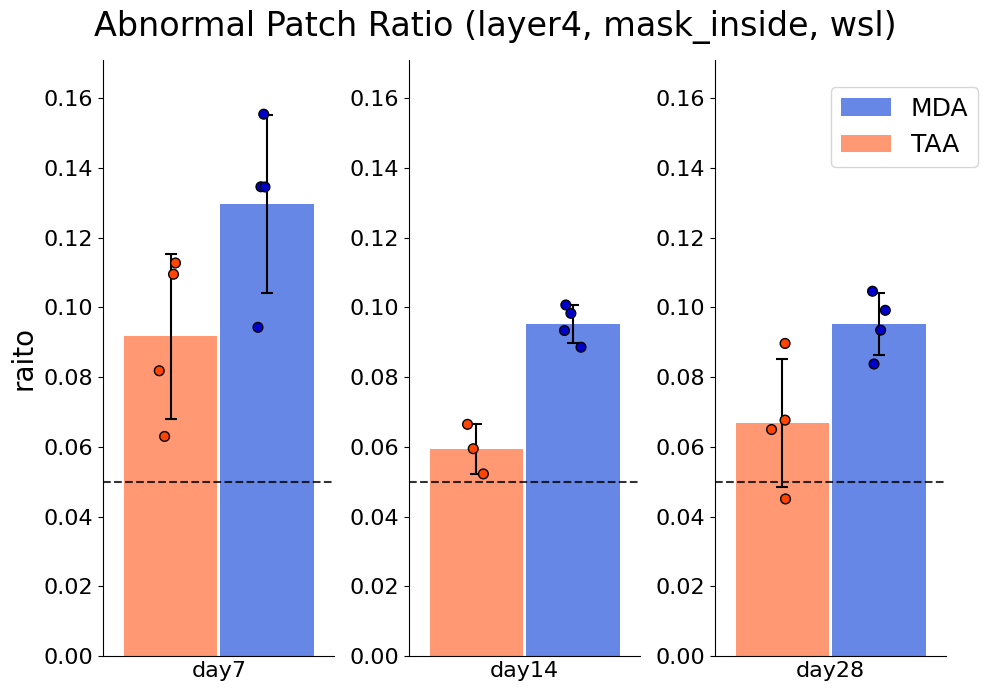

In [25]:
ratio_plot(df_p, title="Abnormal Patch Ratio (layer4, mask_inside, wsl)")

In [26]:
def get_info(sample_id, feature, location, jud):
    inf_lst = []
    max_n = len([i for i in jud if i == -1])
    print("max_n = ", str(max_n))
    n = 0
    ap = inf_lst.append
    for i in zip(jud, feature, location):
        if i[0] == -1:
            ap([sample_id, i[1], i[2], i[0]])
        elif i[0] == 1 and n < max_n:
            ap([sample_id, i[1], i[2], i[0]])
            n = n + 1
        else:
            pass

    return inf_lst

In [27]:
total_inf_lst = []
for i in [17, 18, 19, 29, 30, 31, 32]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.17
12564
835
Percentage of abnormal patches : 0.06645972620184655
max_n =  835
sample No.18
9720
578
Percentage of abnormal patches : 0.059465020576131684
max_n =  578
sample No.19
12269
641
Percentage of abnormal patches : 0.052245496780503706
max_n =  641
sample No.29
13308
1308
Percentage of abnormal patches : 0.09828674481514878
max_n =  1308
sample No.30
12667
1122
Percentage of abnormal patches : 0.08857661640483146
max_n =  1122
sample No.31
14867
1388
Percentage of abnormal patches : 0.09336113540055156
max_n =  1388
sample No.32
13021
1311
Percentage of abnormal patches : 0.10068351125105598
max_n =  1311


In [28]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

In [29]:
# 第一主成分と第二主成分でプロットする
def PCAplot_total_v2(feature_pca, pca_inf, bach_dict, seed1=2477, sample=100, pict_sample=3, xnum=0, ynum=1, title=""):
    fig = plt.figure(figsize=(13, 4))
    ax1 = fig.add_subplot(1, 3, 3)
    ax2 = fig.add_subplot(1, 3, 1)
    ax3 = fig.add_subplot(1, 3, 2)

    label_lst = []
    ap = label_lst.append
    sample_no_lst = []
    ap_s = sample_no_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature_pca)), sample)

    color_dict = {"Control":"dimgray","TAA":"orangered", "MDA":"mediumblue"}

    xmax = max(feature_pca[:, xnum])
    xmin = min(feature_pca[:, xnum])
    ymax = max(feature_pca[:, ynum])
    ymin = min(feature_pca[:, ynum])

    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if bach_dict[pca_inf[i][0]] + ", -1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", -1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
                ap_s(pca_inf[i][0])
                print("pict_sample_no = ", str(pca_inf[i][0]))
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and -0.5 < feature_pca[:, xnum][i] < 0.1 and -0.7 < feature_pca[:, ynum][i] < -0.45:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="red", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and -0.65 < feature_pca[:, xnum][i] < -0.1 and -0.2 < feature_pca[:, ynum][i] < 0.2:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="red", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
        else:
            if bach_dict[pca_inf[i][0]] + ", 1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", 1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])

    for ax in [ax2, ax3, ax1]:
        #ax.set_title("", fontsize=18)

        ax.set_xlim(xmin,xmax)
        ax.set_ylim(ymin,ymax)

        ax.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        ax.spines.bottom.set_color('black')
        ax.spines.left.set_color('black')
    
    ax2.hlines(y=-0.45, xmin=-0.5, xmax=0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=-0.7, xmin=-0.5, xmax=0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=-0.5, ymin=-0.7, ymax=-0.45, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=0.1, ymin=-0.7, ymax=-0.45, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.hlines(y=0.2, xmin=-0.65, xmax=-0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=-0.2, xmin=-0.65, xmax=-0.1, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=-0.65, ymin=-0.2, ymax=0.2, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=-0.1, ymin=-0.2, ymax=0.2, color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.legend()
    ax3.legend() 
    ax3.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax2.set_ylabel("PC"+str(ynum+1), fontsize=15)

    fig.suptitle(title, fontsize=18)

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

    return loc_lst

pict_sample_no =  29
pict_sample_no =  19


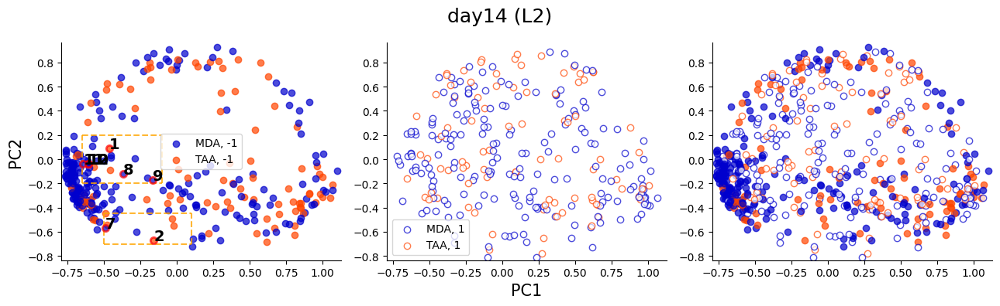

In [30]:
loc_lst = PCAplot_total_v2(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=6, seed1=24771, title="day14 (L2)")

In [34]:
# 第一主成分と第二主成分でプロットする
def PCAplot_total_v2(feature_pca, pca_inf, bach_dict, seed1=2477, sample=100, pict_sample=3, loc1=[-0.8, -0.5, -0.25, 0.25], loc2=[0.5, 0.8, -0.6, -0.1], xnum=0, ynum=1, title=""):
    fig = plt.figure(figsize=(13, 4))
    ax1 = fig.add_subplot(1, 3, 3)
    ax2 = fig.add_subplot(1, 3, 1)
    ax3 = fig.add_subplot(1, 3, 2)

    label_lst = []
    ap = label_lst.append
    sample_no_lst = []
    ap_s = sample_no_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature_pca)), sample)

    color_dict = {"Control":"dimgray","TAA":"orangered", "MDA":"mediumblue"}

    xmax = max(feature_pca[:, xnum])
    xmin = min(feature_pca[:, xnum])
    ymax = max(feature_pca[:, ynum])
    ymin = min(feature_pca[:, ynum])

    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if bach_dict[pca_inf[i][0]] + ", -1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", -1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
                ap_s(pca_inf[i][0])
                print("pict_sample_no = ", str(pca_inf[i][0]))
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and loc1[0] < feature_pca[:, xnum][i] < loc1[1] and loc1[2] < feature_pca[:, ynum][i] < loc1[3]:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="red", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and loc2[0] < feature_pca[:, xnum][i] < loc2[1] and loc2[2] < feature_pca[:, ynum][i] < loc2[3]:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="red", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color=color_dict[bach_dict[pca_inf[i][0]]])
        else:
            if bach_dict[pca_inf[i][0]] + ", 1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", 1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.7, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])

    for ax in [ax2, ax3, ax1]:
        #ax.set_title("", fontsize=18)

        ax.set_xlim(xmin,xmax)
        ax.set_ylim(ymin,ymax)

        ax.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        ax.spines.bottom.set_color('black')
        ax.spines.left.set_color('black')
    
    ax2.hlines(y=loc1[3], xmin=loc1[0], xmax=loc1[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=loc1[2], xmin=loc1[0], xmax=loc1[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc1[0], ymin=loc1[2], ymax=loc1[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc1[1], ymin=loc1[2], ymax=loc1[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.hlines(y=loc2[3], xmin=loc2[0], xmax=loc2[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=loc2[2], xmin=loc2[0], xmax=loc2[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc2[0], ymin=loc2[2], ymax=loc2[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc2[1], ymin=loc2[2], ymax=loc2[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.legend()
    ax3.legend() 
    ax3.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax2.set_ylabel("PC"+str(ynum+1), fontsize=15)

    fig.suptitle(title, fontsize=18)

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

    return loc_lst

In [42]:
def loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection"):
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    print(size)
    if size < 1:
        size = 1

    for i in zip(jud, location):
        if i[0] == -1:
            if str(i[1]) in [key for key in fig_loc.keys()]:
                ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=3, edgecolors="gold")
                ax.text(i[1][0]+loc, i[1][1]-loc, s=fig_loc[str(i[1])],  weight="bold")
            else:
                ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="lightgray", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

In [31]:
total_inf_lst = []
for i in [13, 14, 15, 16, 24, 26, 27, 28]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.13
10996
1204
Percentage of abnormal patches : 0.10949436158603128
max_n =  1204
sample No.14
14288
900
Percentage of abnormal patches : 0.062989921612542
max_n =  900
sample No.15
12748
1043
Percentage of abnormal patches : 0.0818167555695011
max_n =  1043
sample No.16
13485
1520
Percentage of abnormal patches : 0.11271783463107156
max_n =  1520
sample No.24
9846
1325
Percentage of abnormal patches : 0.1345724151939874
max_n =  1325
sample No.26
11300
1520
Percentage of abnormal patches : 0.13451327433628318
max_n =  1520
sample No.27
9879
1535
Percentage of abnormal patches : 0.15538009920032392
max_n =  1535
sample No.28
12273
1157
Percentage of abnormal patches : 0.09427197914120428
max_n =  1157


In [32]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

pict_sample_no =  26
pict_sample_no =  13


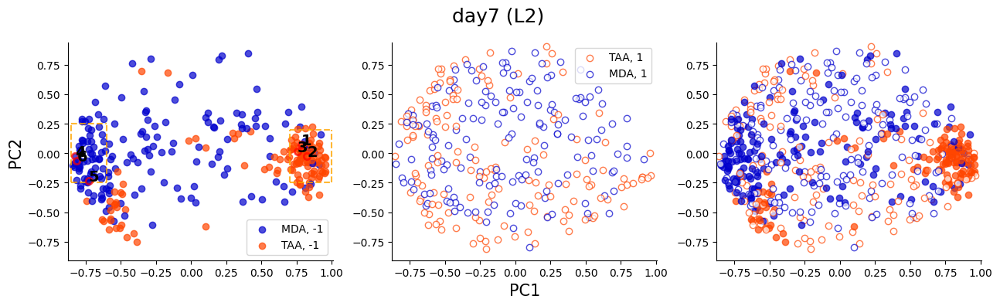

In [40]:
loc_lst = PCAplot_total_v2(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=600, pict_sample=3, loc1=[-0.85, -0.6, -0.25, 0.25], loc2=[0.7, 1.0, -0.25, 0.2], seed1=247, title="day7 (L2)")

Percentage of abnormal patches : 0.10949436158603128
0.6873886359136804


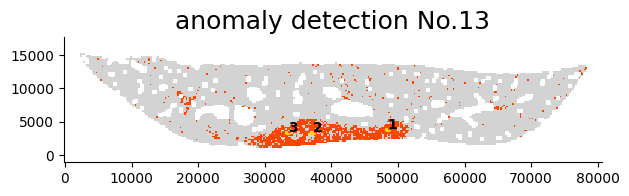

Percentage of abnormal patches : 0.13451327433628318
0.7612365709274281


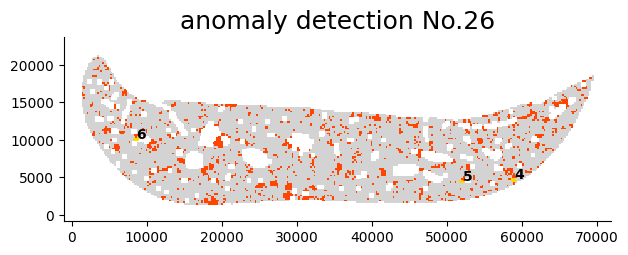

In [43]:
for i in [13, 26]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    fig_loc = {str(j[1]):j[0] for j in loc_lst if j[2] == i}
    loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection No."+str(i))

#### submission ####

In [39]:
root = "/workspace/fig/submission"
patch_size = 224

In [7]:
f_path_1 = "workspace/result_v5/1_layer4.npy"
feature_1 = np.load(f_path_1)
f_path_2 = "workspace/result_v5/2_layer4.npy"
feature_2 = np.load(f_path_2)
f_path_3 = "workspace/result_v5/3_layer4.npy"
feature_3 = np.load(f_path_3)
f_path_4 = "workspace/result_v5/4_layer4.npy"
feature_4 = np.load(f_path_4)
f_path_5 = "workspace/result_v5/5_layer4.npy"
feature_5 = np.load(f_path_5)
f_path_6 = "workspace/result_v5/6_layer4.npy"
feature_6 = np.load(f_path_6)
f_path_7 = "workspace/result_v5/7_layer4.npy"
feature_7 = np.load(f_path_7)
f_path_8 = "workspace/result_v5/8_layer4.npy"
feature_8 = np.load(f_path_8)
f_path_9 = "workspace/result_v5/9_layer4.npy"
feature_9 = np.load(f_path_9)
f_path_10 = "workspace/result_v5/10_layer4.npy"
feature_10 = np.load(f_path_10)
f_path_11 = "workspace/result_v5/11_layer4.npy"
feature_11 = np.load(f_path_11)
f_path_12 = "workspace/result_v5/12_layer4.npy"
feature_12 = np.load(f_path_12)

f_conc = list(feature_1)+list(feature_2)+list(feature_3)+list(feature_4)+list(feature_5)+list(feature_6)+list(feature_7)+list(feature_8)+list(feature_9)+list(feature_10)+list(feature_11)+list(feature_12)

#　学習データを標準化
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(f_conc)

total_p = len(feature_scaled)
nu = 0.05 #5%ぐらいは許容
gamma = 1/(256*3) 
ocsvm_224_mask_inside_wsl = OCSVM(kernel="rbf", gamma=gamma, nu=nu).fit(feature_scaled)

In [8]:
bach_dict = {}
comp_lst = ["Control"]*12+["TAA"]*12+["MDA"]*12
for i in range(36):
    bach_dict[i+1] = comp_lst[i]

day_dict = {}
day_lst = [7]*4+[14]*4+[28]*4
day_lst = day_lst*3
for i in range(36):
    day_dict[i+1] = day_lst[i]

inf_dict = {}
percentage_lst = []
ap = percentage_lst.append
sample_n = [13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
for i in sample_n:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    feature = np.load(f_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    ap(len([i for i in jud if i == -1])/len([i for i in jud if i == 1]))
inf_dict["compound"] = [bach_dict[i] for i in sample_n]
inf_dict["day"] = [day_dict[i] for i in sample_n]
inf_dict["percentage"] = percentage_lst

df_p = pd.DataFrame.from_dict(inf_dict)
df_p.index = sample_n
taa = df_p.loc[24, "compound":"day"]
mda = df_p.loc[25, "compound":"day"]
df_p.loc[24, "compound":"day"] = mda
df_p.loc[25, "compound":"day"] = taa

sample No.13
10996
1204
Percentage of abnormal patches : 0.10949436158603128
sample No.14
14288
900
Percentage of abnormal patches : 0.062989921612542
sample No.15
12748
1043
Percentage of abnormal patches : 0.0818167555695011
sample No.16
13485
1520
Percentage of abnormal patches : 0.11271783463107156
sample No.17
12564
835
Percentage of abnormal patches : 0.06645972620184655
sample No.18
9720
578
Percentage of abnormal patches : 0.059465020576131684
sample No.19
12269
641
Percentage of abnormal patches : 0.052245496780503706
sample No.21
8335
564
Percentage of abnormal patches : 0.06766646670665867
sample No.22
10451
679
Percentage of abnormal patches : 0.06496985934360348
sample No.23
12603
568
Percentage of abnormal patches : 0.04506863445211458
sample No.24
9846
1325
Percentage of abnormal patches : 0.1345724151939874
sample No.25
11723
1051
Percentage of abnormal patches : 0.08965281924422076
sample No.26
11300
1520
Percentage of abnormal patches : 0.13451327433628318
sample No.2

In [9]:
bach_dict[24] = "MDA"
bach_dict[25] = "TAA"

In [116]:
def ratio_plot(df_p, title="Abnormal Patch Ratio", figname=None):
    fig = plt.figure(figsize=(10, 7))
    y_max = max(df_p.loc[:, "percentage"])*1.1
    for i, d in enumerate([7, 14, 28]):
        df_p_day = df_p.loc[[df_p.loc[i, "day"] == d for i in df_p.index.tolist()], :]

        df_mda = df_p_day.loc[[df_p_day.loc[i, "compound"] == "MDA" for i in df_p_day.index.tolist()], :]
        df_mda = df_mda.loc[:, ["percentage"]]
        df_taa = df_p_day.loc[[df_p_day.loc[i, "compound"] == "TAA" for i in df_p_day.index.tolist()], :]
        df_taa = df_taa.loc[:, ["percentage"]]

        ax = fig.add_subplot(1, 3, i+1)
        ax2 = ax.twinx()

        width = 0.4
        x_position = np.arange(1)
        error_bar_set = dict(lw = 1.5, capthick = 1.5, capsize = 4)
        ax.bar(x_position+width/2, df_mda.mean(), yerr=df_mda.std(), tick_label=df_mda.columns, error_kw=error_bar_set, color='royalblue', width=0.97*width, label="MDA", alpha=.8)
        ax.bar(x_position-width/2, df_taa.mean(), yerr=df_taa.std(), tick_label=df_mda.columns, error_kw=error_bar_set, color='coral', width=0.97*width, label="TAA", alpha=.8)
        ax.bar(x_position, df_taa.mean(), tick_label=df_mda.columns, color='white', width=0, alpha=.1) # Adjustment of ticklabels position

        ax.legend(fontsize=18, loc=(0.5, 0.82))
        plt.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        # jitter plot
        sns.stripplot(x='day', y='percentage', data=df_p_day, hue='compound', dodge=True, jitter=True, s=7, linewidth=1, edgecolor="black", palette=['orangered', 'mediumblue'], ax=ax2)
        # control line
        ax.hlines(y=0.05, xmin=-1.2*width, xmax=1.2*width, color="black", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

        ax.tick_params(axis='x', labelsize=16, direction='in', width=0)
        ax.tick_params(axis='y', labelsize=16)

        ax.set_xlim(-1.2*width,1.2*width)
        ax2.set_xlim(-1.2*width,1.2*width)
        ax.set_ylim(0,y_max)
        ax2.set_ylim(0,y_max)

        ax2.axis("off")
        ax2.get_legend().remove()

        if i == 0:
            ax.set_ylabel("raito", fontsize=20)
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()         
        elif i == len([7, 14, 28])-1:
            ax.set_xticklabels(["day"+str(d)])
        else:
            ax.set_xticklabels(["day"+str(d)])
            ax.get_legend().remove()  

    fig.suptitle(title, fontsize=24)
    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

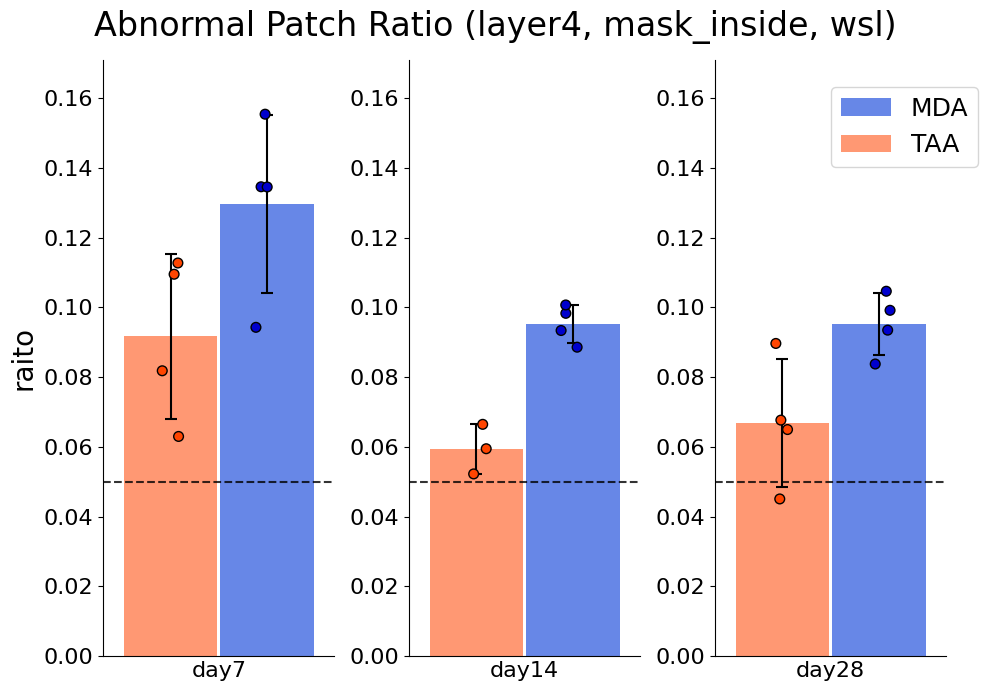

In [117]:
fig_name = "fig2a0.png"
name = f"{root}/{fig_name}"
ratio_plot(df_p, title="Abnormal Patch Ratio (layer4, mask_inside, wsl)", figname=name)

In [12]:
def get_info(sample_id, feature, location, jud):
    inf_lst = []
    max_n = len([i for i in jud if i == -1])
    print("max_n = ", str(max_n))
    n = 0
    ap = inf_lst.append
    for i in zip(jud, feature, location):
        if i[0] == -1:
            ap([sample_id, i[1], i[2], i[0]])
        elif i[0] == 1 and n < max_n:
            ap([sample_id, i[1], i[2], i[0]])
            n = n + 1
        else:
            pass

    return inf_lst

In [33]:
# 第一主成分と第二主成分でプロットする
def PCAplot_total_v2(feature_pca, pca_inf, bach_dict, seed1=2477, sample=100, pict_sample=3, loc1=[-0.8, -0.5, -0.25, 0.25], loc2=[0.5, 0.8, -0.6, -0.1], xnum=0, ynum=1, title="", figname=None):
    fig = plt.figure(figsize=(13, 4))
    ax1 = fig.add_subplot(1, 3, 3)
    ax2 = fig.add_subplot(1, 3, 1)
    ax3 = fig.add_subplot(1, 3, 2)

    label_lst = []
    ap = label_lst.append
    sample_no_lst = []
    ap_s = sample_no_lst.append
    loc_lst = []
    ap_loc = loc_lst.append
    
    random.seed(seed1)
    ran_sam = random.sample(range(len(feature_pca)), sample)

    color_dict = {"Control":"dimgray","TAA":"orangered", "MDA":"mediumblue"}

    xmax = max(feature_pca[:, xnum])
    xmin = min(feature_pca[:, xnum])
    ymax = max(feature_pca[:, ynum])
    ymin = min(feature_pca[:, ynum])

    for i in ran_sam:
        if pca_inf[i][2] == -1:
            if bach_dict[pca_inf[i][0]] + ", -1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", -1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.5, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.5, color=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
                ap_s(pca_inf[i][0])
                print("pict_sample_no = ", str(pca_inf[i][0]))
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and loc1[0] < feature_pca[:, xnum][i] < loc1[1] and loc1[2] < feature_pca[:, ynum][i] < loc1[3]:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.5, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=1.0, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="black", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            elif label_lst.count(bach_dict[pca_inf[i][0]]) < pict_sample and pca_inf[i][0] in sample_no_lst and loc2[0] < feature_pca[:, xnum][i] < loc2[1] and loc2[2] < feature_pca[:, ynum][i] < loc2[3]:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.5, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=1.0, color=color_dict[bach_dict[pca_inf[i][0]]], linewidth=2, ec="black", zorder=2)
                if bach_dict[pca_inf[i][0]] == "MDA":
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1+pict_sample, pca_inf[i][1], pca_inf[i][0]])
                else:
                    ax2.text(feature_pca[:, xnum][i], feature_pca[:, ynum][i], s = str(label_lst.count(bach_dict[pca_inf[i][0]])+1), weight="bold", fontsize=14, zorder=3)
                    ap_loc([label_lst.count(bach_dict[pca_inf[i][0]])+1, pca_inf[i][1], pca_inf[i][0]])
                ap(bach_dict[pca_inf[i][0]])
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.5, color=color_dict[bach_dict[pca_inf[i][0]]])
                ax2.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.5, color=color_dict[bach_dict[pca_inf[i][0]]])
        else:
            if bach_dict[pca_inf[i][0]] + ", 1" not in label_lst:
                complabel = bach_dict[pca_inf[i][0]] + ", 1"
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.5, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.5, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]], label=complabel)
                ap(complabel)
            else:
                ax1.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.5, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])
                ax3.scatter(feature_pca[:, xnum][i], feature_pca[:, ynum][i], alpha=0.5, color="white", linewidth=1, ec=color_dict[bach_dict[pca_inf[i][0]]])

    for ax in [ax2, ax3, ax1]:
        #ax.set_title("", fontsize=18)

        ax.set_xlim(xmin,xmax)
        ax.set_ylim(ymin,ymax)

        ax.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        ax.spines.bottom.set_color('black')
        ax.spines.left.set_color('black')
    
    ax2.hlines(y=loc1[3], xmin=loc1[0], xmax=loc1[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=loc1[2], xmin=loc1[0], xmax=loc1[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc1[0], ymin=loc1[2], ymax=loc1[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc1[1], ymin=loc1[2], ymax=loc1[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.hlines(y=loc2[3], xmin=loc2[0], xmax=loc2[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.hlines(y=loc2[2], xmin=loc2[0], xmax=loc2[1], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc2[0], ymin=loc2[2], ymax=loc2[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)
    ax2.vlines(x=loc2[1], ymin=loc2[2], ymax=loc2[3], color="orange", linestyles='dashed', linewidth=1.5, alpha=.8, zorder=1)

    ax2.legend()
    ax3.legend() 
    ax3.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax2.set_ylabel("PC"+str(ynum+1), fontsize=15)

    fig.suptitle(title, fontsize=18)

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

    return loc_lst

In [15]:
total_inf_lst = []
for i in [13, 14, 15, 16, 24, 26, 27, 28]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.13
10996
1204
Percentage of abnormal patches : 0.10949436158603128
max_n =  1204
sample No.14
14288
900
Percentage of abnormal patches : 0.062989921612542
max_n =  900
sample No.15
12748
1043
Percentage of abnormal patches : 0.0818167555695011
max_n =  1043
sample No.16
13485
1520
Percentage of abnormal patches : 0.11271783463107156
max_n =  1520
sample No.24
9846
1325
Percentage of abnormal patches : 0.1345724151939874
max_n =  1325
sample No.26
11300
1520
Percentage of abnormal patches : 0.13451327433628318
max_n =  1520
sample No.27
9879
1535
Percentage of abnormal patches : 0.15538009920032392
max_n =  1535
sample No.28
12273
1157
Percentage of abnormal patches : 0.09427197914120428
max_n =  1157


In [16]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

pict_sample_no =  13
pict_sample_no =  27


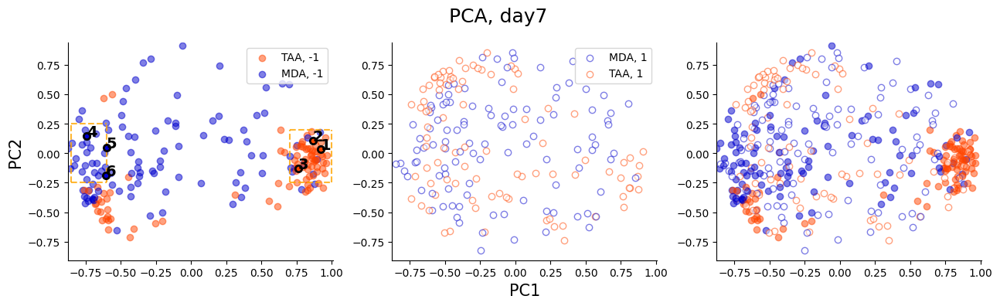

In [98]:
fig_name = "fig2a1.png"
name = f"{root}/{fig_name}"
loc_lst = PCAplot_total_v2(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=400, pict_sample=3, loc1=[-0.85, -0.6, -0.25, 0.25], loc2=[0.7, 1.0, -0.25, 0.2], seed1=7, title="PCA, day7", figname=name)

In [94]:
for n in range(len(loc_lst)):
    if loc_lst[n][2] < 20:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2])+"-シングルファイルエクスポート-"+str(loc_lst[n][2]).zfill(2)+".tif"
        print(filename)
    else:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2]-1)+"-シングルファイルエクスポート-"+str(loc_lst[n][2]-1).zfill(2)+".tif"
        print(filename)

    wsi = OpenSlide(filename)
    print(loc_lst[n][0])
    wsi.read_region(location=tuple(loc_lst[n][1]), level=0, size=(patch_size,patch_size)).convert("RGB").save(root+"/loc_day7_wsl/loc"+str(loc_lst[n][0])+".jpg", "JPEG")

workspace/HE_240205_iwasaka/2024_02_05__0608-シングルファイルエクスポート-13.tif
1
workspace/HE_240205_iwasaka/2024_02_05__0608-シングルファイルエクスポート-13.tif
2
workspace/HE_240205_iwasaka/2024_02_05__0608-シングルファイルエクスポート-13.tif
3
workspace/HE_240205_iwasaka/2024_02_05__0621-シングルファイルエクスポート-26.tif
4
workspace/HE_240205_iwasaka/2024_02_05__0621-シングルファイルエクスポート-26.tif
5
workspace/HE_240205_iwasaka/2024_02_05__0621-シングルファイルエクスポート-26.tif
6


In [102]:
def loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection", figname=None):
    y_max = max([i[1] for i in location])
    y_min = min([i[1] for i in location])
    for i in range(len(location)):
        location[i][1] = (location[i][1]-y_min)*(-1)+y_max
    loc=size
    fig, ax = plt.subplots(dpi=100.0)
    ax.set_aspect ('equal')
    xmax = max([i[0] for i in location])+2440
    xmin = min([i[0] for i in location])-2440
    ymax = max([i[1] for i in location])+2440
    ymin = min([i[1] for i in location])-2440
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax_length=ax.bbox.get_points()[1][0]-ax.bbox.get_points()[0][0]
    ax_point = ax_length*ppi/fig.dpi
    xsize=xmax-xmin
    fact=ax_point/xsize
    size*=2*fact

    print(size)
    if size < 1:
        size = 1

    str_loc_lst = [str([int(key.split(", ")[0].split("[")[1]), ((int(key.split(", ")[1].split("]")[0])-y_min)*(-1)+y_max)]) for key in fig_loc.keys()]
    for i in zip(jud, location):
        if i[0] == -1:
            if str(i[1]) in str_loc_lst:
                ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=3, edgecolors="gold")
                new_loc = [i[1][0], (i[1][1]-y_min)*(-1)+y_max]
                ax.text(i[1][0]+loc, i[1][1]-loc, s=fig_loc[str(new_loc)],  weight="bold")
            else:
                ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="orangered", s=size**2, marker=",", linewidth=0, edgecolors="gold")
        else:
            ax.scatter(i[1][0]+loc, i[1][1]-loc, alpha=1, color="lightgray", s=size**2, marker=",", linewidth=0)

    ax.set_title(title, fontsize=18)
    ax.set_aspect ('equal')

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    #ax.grid(which='both', axis='both')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

Percentage of abnormal patches : 0.10949436158603128
0.6873886359136804


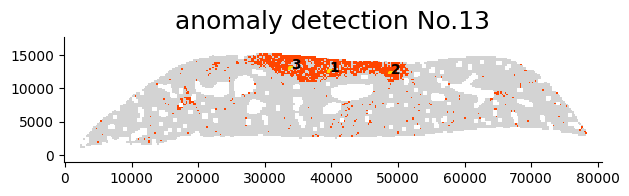

Percentage of abnormal patches : 0.15538009920032392
0.7234840591789956


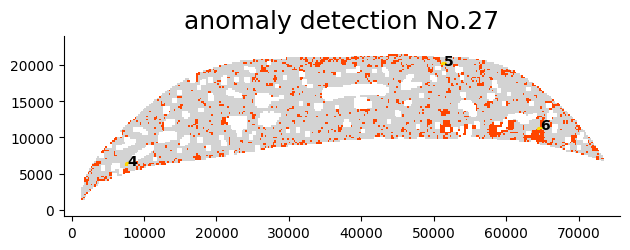

In [103]:
for i in [13, 27]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    fig_loc = {str(j[1]):j[0] for j in loc_lst if j[2] == i}
    fig_name = {13:"fig2a2.png", 27:"fig2a3.png"}[i]
    name = f"{root}/{fig_name}"
    loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection No."+str(i), figname=name)

In [104]:
total_inf_lst = []
for i in [17, 18, 19, 29, 30, 31, 32]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("sample No."+str(i))
    print(len([i for i in jud if i == 1]))
    print(len([i for i in jud if i == -1]))
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    feature_inf_lst = get_info(i, feature_scaled, location, jud)
    total_inf_lst = total_inf_lst + feature_inf_lst

sample No.17
12564
835
Percentage of abnormal patches : 0.06645972620184655
max_n =  835
sample No.18
9720
578
Percentage of abnormal patches : 0.059465020576131684
max_n =  578
sample No.19
12269
641
Percentage of abnormal patches : 0.052245496780503706
max_n =  641
sample No.29
13308
1308
Percentage of abnormal patches : 0.09828674481514878
max_n =  1308
sample No.30
12667
1122
Percentage of abnormal patches : 0.08857661640483146
max_n =  1122
sample No.31
14867
1388
Percentage of abnormal patches : 0.09336113540055156
max_n =  1388
sample No.32
13021
1311
Percentage of abnormal patches : 0.10068351125105598
max_n =  1311


In [105]:
pca_feature_l2 = []
ap = pca_feature_l2.append
for i in total_inf_lst:
    x = i[1]
    # l2 normalization
    x_l2_norm = sum(x**2)**0.5
    x_l2_normalized = x / x_l2_norm
    ap(x_l2_normalized)

pca = PCA()
pca.fit(pca_feature_l2)
feature_pca_l2 = pca.transform(pca_feature_l2)

pca_inf = [[i[0], i[2], i[3]] for i in total_inf_lst]

pict_sample_no =  18
pict_sample_no =  29


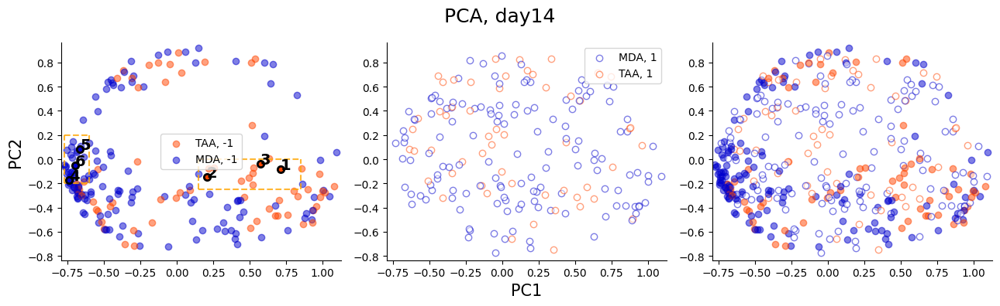

In [114]:
fig_name = "fig2b1.png"
name = f"{root}/{fig_name}"
loc_lst = PCAplot_total_v2(feature_pca_l2, pca_inf, bach_dict, xnum=0, ynum=1, sample=400, pict_sample=3, loc1=[-0.77, -0.6, -0.2, 0.2], loc2=[0.15, 0.85, -0.25, 0], seed1=7, title="PCA, day14", figname=name)

In [113]:
for n in range(len(loc_lst)):
    if loc_lst[n][2] < 20:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2])+"-シングルファイルエクスポート-"+str(loc_lst[n][2]).zfill(2)+".tif"
        print(filename)
    else:
        filename = "workspace/HE_240205_iwasaka/2024_02_05__0"+str(595+loc_lst[n][2]-1)+"-シングルファイルエクスポート-"+str(loc_lst[n][2]-1).zfill(2)+".tif"
        print(filename)

    wsi = OpenSlide(filename)
    print(loc_lst[n][0])
    wsi.read_region(location=tuple(loc_lst[n][1]), level=0, size=(patch_size,patch_size)).convert("RGB").save(root+"/loc_day14_wsl/loc"+str(loc_lst[n][0])+".jpg", "JPEG")

workspace/HE_240205_iwasaka/2024_02_05__0623-シングルファイルエクスポート-28.tif
4
workspace/HE_240205_iwasaka/2024_02_05__0623-シングルファイルエクスポート-28.tif
5
workspace/HE_240205_iwasaka/2024_02_05__0623-シングルファイルエクスポート-28.tif
6
workspace/HE_240205_iwasaka/2024_02_05__0613-シングルファイルエクスポート-18.tif
1
workspace/HE_240205_iwasaka/2024_02_05__0613-シングルファイルエクスポート-18.tif
2
workspace/HE_240205_iwasaka/2024_02_05__0613-シングルファイルエクスポート-18.tif
3


Percentage of abnormal patches : 0.059465020576131684
0.8558047818585162


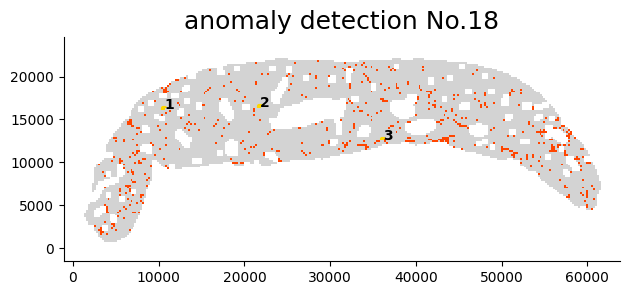

Percentage of abnormal patches : 0.09828674481514878
0.7110382961294286


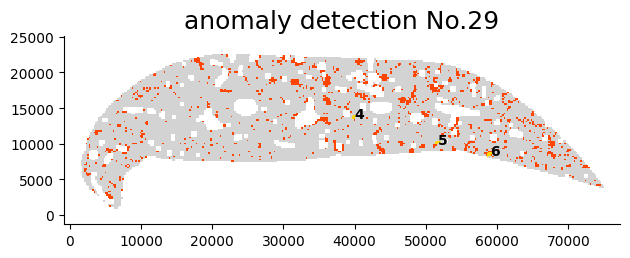

In [115]:
for i in [18, 29]:
    f_path = "workspace/result_v5/"+str(i)+"_layer4.npy"
    l_path = "workspace/result_v5/"+str(i)+"_location.pickle"
    feature = np.load(f_path)
    location = pd.read_pickle(l_path)
    feature_scaled = scaler.fit_transform(feature)
    jud = ocsvm_224_mask_inside_wsl.predict(feature_scaled)
    print("Percentage of abnormal patches : "+str(len([i for i in jud if i == -1])/len([i for i in jud if i == 1])))
    fig_loc = {str(j[1]):j[0] for j in loc_lst if j[2] == i}
    fig_name = {18:"fig2b2.png", 29:"fig2b3.png"}[i]
    name = f"{root}/{fig_name}"
    loc_plot_v3(location, jud, fig_loc, ppi=50, size=112, title="anomaly detection No."+str(i), figname=name)